# Social media and young consumers' shopping behaviour in Bangladesh

**What this notebook does.** It takes the raw survey CSV (524 responses, 49 columns) and produces every table and figure for the article, one numbered cell at a time: data cleaning → descriptives → measurement (EFA/CFA, reliability) → the trust–spending models → safeguards, cash on delivery (COD), mediation and moderation → satisfaction and low-trust spenders (H6, H7) → robustness checks → latent-class segmentation → export.

**How to run it**
1. Put the survey CSV in your Google Drive folder `MyDrive/Shopping/` (or change `DATA_PATH` and `OUT` in Cell 1).
2. Run the cells from top to bottom (*Runtime → Run all*, or one at a time). Later cells re-use objects created by earlier ones, so do not skip cells and do not restart the runtime before Cell 18.
3. Everything is written to `OUT = MyDrive/Shopping/outputs`: `tables/` (CSV), `figures/` (300-dpi PNG + vector PDF) and `export/` (Excel workbook, ZIP, figure captions).

**Conventions used throughout**
- Samples: raw 524 → cleaned 515 (5 straight-liners and 4 duplicates removed; used for descriptives) → model sample 512 (3 respondents with missing residence dropped; used for regressions).
- Odds ratios (OR) are per +1 SD of the predictor unless stated otherwise; robust (HC1) standard errors for logit, HC3 for OLS.
- Covariate sets: **M0** unadjusted; **M1** + demographics (sex, residence, income, education, age); **M2** + exposure (influencers followed, daily social-media hours) = the *main* model; **M3** + psychological vulnerability.
- Multiple testing is controlled with Benjamini–Hochberg FDR (q-values) or Holm where stated.
- The data are cross-sectional: every association is descriptive, not causal.
- **Figure style:** serif font, size 12 (set in Cell 1). Figures are saved *without titles*; the suggested caption for each figure is printed under it, stored in `FIGCAP` and exported in Cell 18. Panel letters/headings (A, B, C) are kept inside multi-panel figures.


## Step 0 — Mount Google Drive

In [1]:
# Mount Google Drive (a pop-up asks for permission). The survey CSV must be in MyDrive/Shopping/
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Cell 1 — Setup, figure style, helpers, raw data and codebook
Sets the paths, the figure style (serif, size 12), the helper functions `save_table` and `save_fig`, loads the raw CSV (the answer "None" in Q11 is kept as a real answer, not as missing) and gives every column a short name.
**Outputs:** Table 0 (codebook).

In [2]:
# ============================================================
# CELL 1 — Setup: paths, figure style, helper functions, load the raw CSV, codebook
# (run AFTER the Google-Drive mount cell above)
# ============================================================
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

# ---- paths: EDIT HERE if your files are stored somewhere else ----
DATA_PATH = "/content/drive/MyDrive/Shopping/The Role of Social Media in Shaping Shopping Behavior and Attitudes among Young Consumers.csv"
OUT = "/content/drive/MyDrive/Shopping/outputs"          # every table, figure and export is written here
os.makedirs(f"{OUT}/tables", exist_ok=True)
os.makedirs(f"{OUT}/figures", exist_ok=True)

# ---- figure style (applies to every figure in this notebook) ----
# Set font size and family for the entire figure
matplotlib.rcParams['font.size'] = 12
matplotlib.rcParams['font.family'] = 'serif'
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",   # 300-dpi files, cropped to the content
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 12,
    "legend.frameon": False,
})

# ---- helpers used in every later cell ----
TABLES = {}    # table name -> (caption, DataFrame); filled by save_table, exported in Cell 18
FIGCAP = {}    # figure name -> suggested caption; filled by save_fig, exported in Cell 18

def save_table(df_, name, caption=""):
    """Store a table (CSV in OUT/tables + the TABLES dictionary) and show it."""
    TABLES[name] = (caption, df_.copy())
    df_.to_csv(f"{OUT}/tables/{name}.csv", index=True)
    print(f"\n{name}: {caption}")
    display(df_)

def save_fig(fig, name, caption=""):
    """Save a figure as 300-dpi PNG and as vector PDF. Figures carry no title; the caption is printed and stored for the manuscript."""
    fig.savefig(f"{OUT}/figures/{name}.png")
    fig.savefig(f"{OUT}/figures/{name}.pdf")
    FIGCAP[name] = caption.strip()
    print(f"saved figure: {name}")
    if caption: print("  suggested caption:", caption.replace("\n", " "))

# ---- load the raw survey: keep_default_na=False so the answer "None" (Q11) is NOT read as missing ----
raw = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=[""])
print("Raw shape:", raw.shape)

def new_name(c):
    """Short, safe column names: Q1..Q27, LIK:<statement>, ts, closing_comment."""
    m = re.match(r"Q(\d+)\.", c)
    if m: return f"Q{m.group(1)}"
    if c.startswith("Rate your level"): return "LIK:" + re.search(r"\[(.*)\]", c).group(1).strip()
    if c == "Timestamp": return "ts"
    return "closing_comment"

d0 = raw.rename(columns={c: new_name(c) for c in raw.columns}).copy()
lik_cols = [c for c in d0.columns if c.startswith("LIK:")]
print("Likert statements found:", len(lik_cols), "(expected 20)")

# ---- Table 0: codebook (original question text, new name, number of unique values, missing) ----
codebook = pd.DataFrame({
    "new_name": d0.columns,
    "original_question": [c[:90] + ("…" if len(c) > 90 else "") if not c.startswith("Rate your") else c[c.find("[") + 1:-1] for c in raw.columns],
    "n_unique": [d0[c].nunique(dropna=True) for c in d0.columns],
    "n_missing": [int(d0[c].isna().sum()) for c in d0.columns],
}).set_index("new_name")
save_table(codebook, "T0_codebook", "Variable codebook (raw data)")

print("\nFirst 3 respondents (selected columns):")
display(d0[["ts", "Q1", "Q2", "Q5", "Q7", "Q13", "Q15", "Q18", "Q27"]].head(3))
print("\nTimestamp range:", d0["ts"].iloc[0], "->", d0["ts"].iloc[-1])

Raw shape: (524, 49)
Likert statements found: 20 (expected 20)

T0_codebook: Variable codebook (raw data)


,original_question,n_unique,n_missing
new_name,,,
ts,Timestamp,523,0
Q1,Q1. What is your age?,6,0
Q2,Q2. What is your gender?,2,0
Q3,Q3. What is your highest level of education completed?,6,0
Q4,Q4. What is your current employment/student status?,7,0
Q5,Q5. What is your approximate monthly personal income or allowance ...,5,0
Q6,Q6. What is your place of residence?,3,3
Q7,Q7. How many hours per day do you typically spend on social media?,5,0
Q8,Q8. Which social media platforms do you use most frequently? (Sele...,104,0



First 3 respondents (selected columns):


,ts,Q1,Q2,Q5,Q7,Q13,Q15,Q18,Q27
0,2026/07/03 9:43:35 PM GMT+6,26–29 years,Male,"Above 100,000",More than 6 hours,"Yes, frequently","Above 10,000",Moderately,Satisfied
1,2026/07/03 10:22:11 PM GMT+6,22–25 years,Female,"Below 10,000",5–6 hours,"Yes, frequently","2,001 – 5,000",Quite a lot,Satisfied
2,2026/07/03 10:25:44 PM GMT+6,26–29 years,Female,"50,001 – 100,000",3–4 hours,"Yes, frequently","5,001 – 10,000",Quite a lot,Neutral



Timestamp range: 2026/07/03 9:43:35 PM GMT+6 -> 2026/10/01 7:19:33 PM GMT+6


## Cell 2 — Cleaning, recoding, data-quality audit and analytic samples
Fixes text variants, codes the ordinal questions (higher = more), converts the 20 Likert statements to numbers, flags straight-lining, duplicates, contradictory answers and missing residence, and defines the cleaned sample and the model sample.
**Outputs:** Tables 1a (audit) and 1b (sample flow); Figure S1 (data-quality flags); `data_clean.csv` and `data_full_coded.csv`.


T1a_data_quality_audit: Data-quality audit of the raw survey data


,n,Action,% of raw
Check,,,
Straight-lining (same answer to all 20 Likert items),5,EXCLUDED,1.0
Duplicate response rows,4,EXCLUDED,0.8
"Missing residence (Q6, optional question)",3,listwise in models,0.6
Q9 'select top 3' exceeded,41,"kept, reported",7.8
Q20 'select top 3' exceeded,27,"kept, reported",5.2
Q13 'never bought' but Q15 spend > 0,27,"kept, reported",5.2
Q15 'nothing' but Q13 'frequently bought',32,"kept, reported",6.1
Q23 'never shop online' but answered Q24-Q27,18,"kept, reported",3.4
Q1 spelling variant '22-25' merged,14,recoded,2.7



T1b_sample_flow: Sample flow from raw responses to analytic samples


,n
Step,
Raw responses,524
Remove straight-liners,-5
Remove duplicates,-4
Cleaned sample (descriptives),515
Remove missing residence,-3
Model sample (regressions),512



Q11 (influencers followed) — 'None' now kept as a real answer:
Q11
6–15            163
1–5             145
16–30            93
More than 30     71
None             52

Q1: {'18–21 years': 107, '22–25 years': 186, '26–29 years': 116, '30–33 years': 72, '34–35 years': 43}
Q24: {'Daraz': 197, 'Facebook Marketplace': 130, 'Other': 51, 'Shajgoj': 46, 'Instagram Shop': 40, 'Chaldal': 27, 'Amazon / AliExpress (international)': 19, 'Brand Websites': 14}

Section IV alpha-type check — means of the 20 Likert items:
relevant          3.29
informative       3.40
helps_decision    3.39
trust_infl        3.10
data_ok           2.77
buy_unneeded      3.43
misleading        3.59
can_tell          3.53
click             3.37
overwhelmed       3.54
impulse           3.01
friends_insp      3.19
fomo              3.06
discount          3.54
regret            3.32
compare           3.40
satisf_trusted    3.29
consult           3.24
pressure          3.14
spend_up          3.42
saved figure: FigS1_data_qua

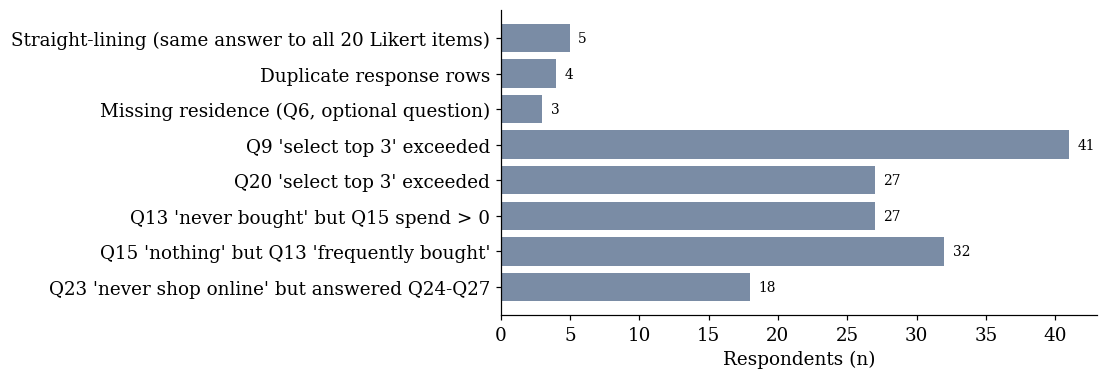


Saved: data_full_coded.csv, data_clean.csv  | objects in memory: d0 (all), clean, model


In [3]:
# ============================================================
# CELL 2 — Cleaning, recoding, data-quality audit and the analytic samples (Tables 1a-1b, Figure S1)
# ============================================================
# (imports, paths, helpers and the raw data `d0` come from Cell 1)

# ---- 1. strip stray spaces in all text columns ----
for c in d0.columns:
    if d0[c].dtype == object or str(d0[c].dtype).startswith("str"):
        d0[c] = d0[c].astype("string").str.strip()

# ---- 2. text fixes found in the audit ----
n_q1_fix = int((d0["Q1"] == "22-25 years").sum())
d0["Q1"] = d0["Q1"].str.replace("-", "–", regex=False)                    # "22-25" -> "22–25"
n_q24_fix = int(d0["Q24"].isin(["Option 7", "Kirei"]).sum())
d0["Q24"] = d0["Q24"].replace({"Option 7": "Other", "Kirei": "Other"})   # mislabelled "Other"
n_q4_fix = int((d0["Q4"] == "Tuition").sum())
d0["Q4"] = d0["Q4"].replace({"Tuition": "Other"})

# ---- 3. numeric codes for ordinal questions (higher = more) ----
ORD = {
 "Q1":  ["18–21 years","22–25 years","26–29 years","30–33 years","34–35 years"],
 "Q3":  ["No Education","Secondary School (SSC/O-Level or equivalent)","Higher Secondary (HSC/A-Level or equivalent)",
         "Bachelor's Degree (ongoing or completed)","Master's Degree (ongoing or completed)","PhD / Doctoral Degree"],
 "Q5":  ["Below 10,000","10,000 – 25,000","25,001 – 50,000","50,001 – 100,000","Above 100,000"],
 "Q7":  ["Less than 1 hour","1–2 hours","3–4 hours","5–6 hours","More than 6 hours"],
 "Q10": ["Never","Rarely (once a week or less)","Sometimes (a few times a week)","Often (daily)","Very often (multiple times a day)"],
 "Q11": ["None","1–5","6–15","16–30","More than 30"],
 "Q12": ["Never","Rarely","Sometimes","Often","Always"],
 "Q13": ["No, never","Yes, but rarely","Yes, occasionally","Yes, frequently"],
 "Q15": ["Nothing","Below 500","500 – 2,000","2,001 – 5,000","5,001 – 10,000","Above 10,000"],
 "Q17": ["Never","Rarely","Sometimes","Usually","Always"],
 "Q18": ["Not at all","Slightly","Moderately","Quite a lot","Completely"],
 "Q22": ["No, almost never","Rarely","Sometimes","Most of the time","Yes, always"],
 "Q23": ["Never","Once a month or less","2–3 times a month","Once a week","Several times a week","Daily"],
 "Q27": ["Very dissatisfied","Dissatisfied","Neutral","Satisfied","Very satisfied"],
}
for q, order in ORD.items():
    mp = {v: i + 1 for i, v in enumerate(order)}
    bad = d0[q].dropna()[~d0[q].dropna().isin(mp)].unique()
    assert len(bad) == 0, f"Unmapped values in {q}: {bad}"
    d0[q + "_n"] = d0[q].map(mp).astype("float")

# ---- 4. Likert statements -> numeric (1-5) with short names ----
LIK = {"Strongly Disagree":1, "Disagree":2, "Neutral":3, "Agree":4, "Strongly Agree":5}
SHORT = {
 "Social media ads are relevant to my interests and needs.": "relevant",
 "I find social media advertisements informative and useful.": "informative",
 "Social media advertising helps in better purchase decisions.": "helps_decision",
 "I trust the product recommendations of the social media influencers.": "trust_infl",
 "I'm okay with sharing my data for personalized ads.": "data_ok",
 "Social media ads make me want to buy things I don't need.": "buy_unneeded",
 "Social media sponsored content is often misleading.": "misleading",
 "I can tell the difference between ads and authentic posts.": "can_tell",
 "I often click on social media ads to explore products.": "click",
 "I'm overwhelmed by the number of ads on social media.": "overwhelmed",
 "I often impulse buy after seeing products on social media.": "impulse",
 "Friends' purchases on social media inspire me to buy too.": "friends_insp",
 "Fear of Missing Out (FOMO) drives me to purchase trending products.": "fomo",
 "Discounts and flash sales on social media urge me to buy": "discount",
 "I've regretted purchases influenced by social media.": "regret",
 "Social media makes me compare lifestyles and buy more.": "compare",
 "I'm more satisfied buying products trusted influencers recommend.": "satisf_trusted",
 "I consult friends on social media before major purchases.": "consult",
 "I feel pressured to follow trends I see on social media.": "pressure",
 "Social media has increased my overall spending": "spend_up",
}
lik_cols = [c for c in d0.columns if c.startswith("LIK:")]
for c in lik_cols:
    short = SHORT[c[4:]]
    d0[short] = d0[c].map(LIK).astype(float)
ATT = list(SHORT.values())[:10]     # Section IV: attitudes to social media advertising
PSY = list(SHORT.values())[10:]     # Section VI: consumer psychology / impulsive buying
ALL20 = ATT + PSY
assert d0[ALL20].isna().sum().sum() == 0

# ---- 5. multi-response: number of options ticked ----
for q in ["Q8", "Q9", "Q14", "Q16", "Q20"]:
    d0[q + "_k"] = d0[q].fillna("").apply(lambda s: len([x for x in s.split(";") if x.strip()]))

# ---- 6. quality flags ----
d0["flag_straightline"] = d0[ALL20].std(axis=1) == 0
content_cols = [c for c in d0.columns if c not in ["ts", "closing_comment"] and not c.endswith("_k")
                and not c.startswith("flag_")]
d0["flag_duplicate"] = d0[content_cols].duplicated(keep="first")
d0["flag_top3_Q9"]  = d0["Q9_k"] > 3
d0["flag_top3_Q20"] = d0["Q20_k"] > 3
d0["flag_never_buy_but_spend"] = (d0["Q13_n"] == 1) & (d0["Q15_n"] > 1)
d0["flag_nospend_but_freq_buy"] = (d0["Q15_n"] == 1) & (d0["Q13_n"] == 4)
d0["flag_never_shop_online"] = d0["Q23_n"] == 1
d0["flag_missing_residence"] = d0["Q6"].isna()

N = len(d0)
audit = pd.DataFrame([
 ("Straight-lining (same answer to all 20 Likert items)", int(d0.flag_straightline.sum()), "EXCLUDED"),
 ("Duplicate response rows",                              int(d0.flag_duplicate.sum()),    "EXCLUDED"),
 ("Missing residence (Q6, optional question)",            int(d0.flag_missing_residence.sum()), "listwise in models"),
 ("Q9 'select top 3' exceeded",                           int(d0.flag_top3_Q9.sum()),      "kept, reported"),
 ("Q20 'select top 3' exceeded",                          int(d0.flag_top3_Q20.sum()),     "kept, reported"),
 ("Q13 'never bought' but Q15 spend > 0",                 int(d0.flag_never_buy_but_spend.sum()), "kept, reported"),
 ("Q15 'nothing' but Q13 'frequently bought'",            int(d0.flag_nospend_but_freq_buy.sum()), "kept, reported"),
 ("Q23 'never shop online' but answered Q24-Q27",         int(d0.flag_never_shop_online.sum()), "kept, reported"),
 ("Q1 spelling variant '22-25' merged",                   n_q1_fix, "recoded"),
 ("Q24 'Option 7' / 'Kirei' recoded to Other",            n_q24_fix, "recoded"),
 ("Q4 free text 'Tuition' recoded to Other",              n_q4_fix, "recoded"),
], columns=["Check", "n", "Action"])
audit["% of raw"] = (audit["n"] / N * 100).round(1)
audit = audit.set_index("Check")
save_table(audit, "T1a_data_quality_audit", "Data-quality audit of the raw survey data")

# ---- 7. analytic samples ----
clean = d0[~d0.flag_straightline & ~d0.flag_duplicate].copy()
model = clean.dropna(subset=["Q6"]).copy()
flow = pd.DataFrame({
 "Step": ["Raw responses", "Remove straight-liners", "Remove duplicates",
          "Cleaned sample (descriptives)", "Remove missing residence", "Model sample (regressions)"],
 "n": [N, -int(d0.flag_straightline.sum()), -int((d0.flag_duplicate & ~d0.flag_straightline).sum()),
       len(clean), -int(clean["Q6"].isna().sum()), len(model)],
}).set_index("Step")
save_table(flow, "T1b_sample_flow", "Sample flow from raw responses to analytic samples")
assert len(clean) == flow.loc["Cleaned sample (descriptives)", "n"]

# ---- 8. checks ----
print("\nQ11 (influencers followed) — 'None' now kept as a real answer:")
print(d0["Q11"].value_counts(dropna=False).to_string())
print("\nQ1:", d0["Q1"].value_counts().sort_index().to_dict())
print("Q24:", d0["Q24"].value_counts().to_dict())
print("\nSection IV alpha-type check — means of the 20 Likert items:")
print(d0[ALL20].mean().round(2).to_string())

# ---- 9. figure S1: data-quality flags ----
fig, ax = plt.subplots(figsize=(7, 3.6))
a = audit[audit.index.str.contains("Straight|Duplicate|top 3|never|nothing|Missing", case=False)]
ax.barh(a.index[::-1], a["n"][::-1], color="#7a8ca5")
for i, v in enumerate(a["n"][::-1]): ax.text(v + 0.6, i, str(v), va="center", fontsize=9)
ax.set_xlabel("Respondents (n)"); CAPTION = "Figure S1. Data-quality flags in the raw survey (N = %d)." % N
save_fig(fig, "FigS1_data_quality_flags", CAPTION); plt.show()

# ---- 10. save cleaned data (used by all next cells) ----
d0.to_csv(f"{OUT}/data_full_coded.csv", index=False)
clean.to_csv(f"{OUT}/data_clean.csv", index=False)
print("\nSaved: data_full_coded.csv, data_clean.csv  | objects in memory: d0 (all), clean, model")

## Cell 3 — Sample profile
Demographics and social-media exposure of the cleaned sample.
**Outputs:** Tables 1 and 1b; Figure 1; key descriptive facts for the Results text.


Table1_sample_profile: Sample profile (cleaned sample, N = 515)


n (%)
Variable                   Category                                                
Gender                     Male                                          323 (62.7)
                           Female                                        192 (37.3)
Age group                  18–21 years                                   107 (20.8)
                           22–25 years                                   183 (35.5)
                           26–29 years                                   113 (21.9)
                           30–33 years                                    69 (13.4)
                           34–35 years                                     43 (8.3)
Education                  No Education                                    20 (3.9)
                           Secondary School (SSC/O-Level or equivalent)    38 (7.4)
                           Higher Secondary (HSC/A-Level or equivalent)   90 (17.5)
                           Bachelor's Degree (ongoing or completed)      247 (48.0)
                           Master's Degree (ongoing or completed)         96 (18.6)
                           PhD / Doctoral Degree                           24 (4.7)
Occupation                 Full-time student                             212 (41.2)
                           Employed full-time                            131 (25.4)
                           Self-employed / Freelancer                      49 (9.5)
                           Part-time student                               42 (8.2)
                           Employed part-time                              42 (8.2)
                           Unemployed                                      38 (7.4)
                           Other                                            1 (0.2)
Monthly income (BDT)       Below 10,000                                  207 (40.2)
                           10,000 – 25,000                               121 (23.5)
                           25,001 – 50,000                               113 (21.9)
                           50,001 – 100,000                               58 (11.3)
                           Above 100,000                                   16 (3.1)
Residence                  Urban (city)                                  300 (58.3)
                           Semi-urban (town)                             133 (25.8)
                           Rural                                          79 (15.3)
                           Missing                                          3 (0.6)
Daily time on social media Less than 1 hour                                45 (8.7)
                           1–2 hours                                     118 (22.9)
                           3–4 hours                                     190 (36.9)
                           5–6 hours                                     110 (21.4)
                           More than 6 hours                              52 (10.1)
Online shopping frequency  Never                                           18 (3.5)
                           Once a month or less                          133 (25.8)
                           2–3 times a month                             142 (27.6)
                           Once a week                                    77 (15.0)
                           Several times a week                           76 (14.8)
                           Daily                                          69 (13.4)
Influencers followed       None                                           52 (10.1)
                           1–5                                           143 (27.8)
                           6–15                                          162 (31.5)
                           16–30                                          90 (17.5)
                           More than 30                                   68 (13.2)


All variables sum to N = 515

--- Key facts for the Results text ---
Female: 37.3% | Male: 62.7%
Age 18-29: 78.3%
Urban (city): 58.3% | Rural: 15.3%
Bachelor's or higher: 71.3%
Students (full- or part-time): 49.3%
Income <= BDT 25,000: 63.7%
Social media >= 3 h/day: 68.3%
Shops online at least weekly (Q23 >= once a week): 43.1%

Table1b_age_by_gender: Age group by gender (counts)


Q2,Female,Male,Total
Q1,,,
18–21 years,49,58,107
22–25 years,72,111,183
26–29 years,29,84,113
30–33 years,23,46,69
34–35 years,19,24,43
Total,192,323,515


saved figure: Fig1_sample_profile
  suggested caption: Figure 1. Profile of respondents (N = 515)


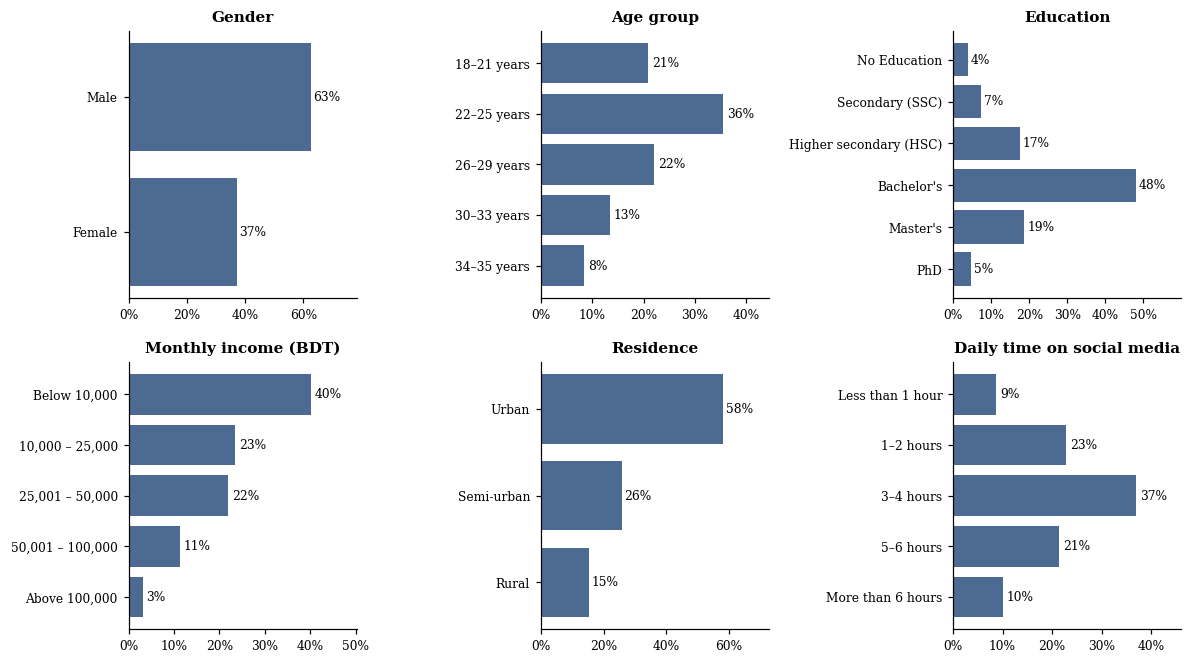

In [4]:
# ============================================================
# CELL 3 — Sample profile: Table 1 (demographics + social-media exposure) and Figure 1
# ============================================================
from matplotlib.ticker import PercentFormatter

# (variable label, column, display order or None = by frequency, "Other" last)
PROFILE = [
 ("Gender",                       "Q2",  ["Male", "Female"]),
 ("Age group",                    "Q1",  ORD["Q1"]),
 ("Education",                    "Q3",  ORD["Q3"]),
 ("Occupation",                   "Q4",  None),
 ("Monthly income (BDT)",         "Q5",  ORD["Q5"]),
 ("Residence",                    "Q6",  ["Urban (city)", "Semi-urban (town)", "Rural"]),
 ("Daily time on social media",   "Q7",  ORD["Q7"]),
 ("Online shopping frequency",    "Q23", ORD["Q23"]),
 ("Influencers followed",         "Q11", ORD["Q11"]),
]

rows = []
for label, col, order in PROFILE:
    s = clean[col]
    vc = s.value_counts(dropna=False)
    if order is None:
        order = [k for k in vc.index if pd.notna(k) and k != "Other"] + (["Other"] if "Other" in vc.index else [])
    for cat in order:
        n_ = int(vc.get(cat, 0))
        rows.append((label, cat, n_, n_ / len(clean) * 100))
    if s.isna().any():
        n_ = int(s.isna().sum()); rows.append((label, "Missing", n_, n_ / len(clean) * 100))

T1 = pd.DataFrame(rows, columns=["Variable", "Category", "n", "%"])
T1["n (%)"] = T1.apply(lambda r: f"{r['n']} ({r['%']:.1f})", axis=1)
T1_show = T1.set_index(["Variable", "Category"])[["n (%)"]]
save_table(T1_show, "Table1_sample_profile", f"Sample profile (cleaned sample, N = {len(clean)})")
T1.to_csv(f"{OUT}/tables/Table1_sample_profile_numeric.csv", index=False)

# internal consistency check: every variable sums to N
chk = T1.groupby("Variable", sort=False)["n"].sum()
assert (chk == len(clean)).all(), chk
print("\nAll variables sum to N =", len(clean))

# ---- additional descriptive facts for the text ----
print("\n--- Key facts for the Results text ---")
print(f"Female: {(clean.Q2=='Female').mean()*100:.1f}% | Male: {(clean.Q2=='Male').mean()*100:.1f}%")
print(f"Age 18-29: {clean.Q1_n.le(3).mean()*100:.1f}%")
print(f"Urban (city): {(clean.Q6.fillna('')=='Urban (city)').mean()*100:.1f}% | Rural: {(clean.Q6.fillna('')=='Rural').mean()*100:.1f}%")
print(f"Bachelor's or higher: {clean.Q3_n.ge(4).mean()*100:.1f}%")
print(f"Students (full- or part-time): {clean.Q4.fillna('').str.contains('student').mean()*100:.1f}%")
print(f"Income <= BDT 25,000: {clean.Q5_n.le(2).mean()*100:.1f}%")
print(f"Social media >= 3 h/day: {clean.Q7_n.ge(3).mean()*100:.1f}%")
print(f"Shops online at least weekly (Q23 >= once a week): {clean.Q23_n.ge(4).mean()*100:.1f}%")

# ---- sample composition by gender and age (small cross-tab for representativeness) ----
ct = pd.crosstab(clean["Q1"], clean["Q2"]).reindex(ORD["Q1"])
ct["Total"] = ct.sum(axis=1)
ct.loc["Total"] = ct.sum()
save_table(ct, "Table1b_age_by_gender", "Age group by gender (counts)")

# ---- Figure 1: demographic profile (6 panels) ----
panels = [("Gender", "Q2"), ("Age group", "Q1"), ("Education", "Q3"),
          ("Monthly income (BDT)", "Q5"), ("Residence", "Q6"), ("Daily time on social media", "Q7")]
short_lab = {
 "Secondary School (SSC/O-Level or equivalent)": "Secondary (SSC)",
 "Higher Secondary (HSC/A-Level or equivalent)": "Higher secondary (HSC)",
 "Bachelor's Degree (ongoing or completed)": "Bachelor's",
 "Master's Degree (ongoing or completed)": "Master's",
 "PhD / Doctoral Degree": "PhD",
 "Urban (city)": "Urban", "Semi-urban (town)": "Semi-urban",
}
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2))
for ax, (title, col) in zip(axes.ravel(), panels):
    sub = T1[T1.Variable == title]
    sub = sub[sub.Category != "Missing"]
    labs = [short_lab.get(c, c) for c in sub.Category][::-1]
    vals = sub["%"].values[::-1]
    ax.barh(labs, vals, color="#4c6a92")
    for i, v in enumerate(vals): ax.text(v + 0.8, i, f"{v:.0f}%", va="center", fontsize=8)
    ax.set_xlim(0, max(vals) * 1.25); ax.set_title(title, fontsize=10)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0)); ax.tick_params(labelsize=8)
CAPTION = (f"Figure 1. Profile of respondents (N = {len(clean)})")
fig.tight_layout()
save_fig(fig, "Fig1_sample_profile", CAPTION); plt.show()

## Cell 4 — Descriptives: Likert items and behavioural outcomes
Item-level descriptives for the 20 Likert statements (Wilcoxon test against the neutral point, FDR-corrected) and the distribution of the behavioural outcomes (purchasing, spending, trust, payment method, satisfaction).
**Outputs:** Tables 2 and 3; Figures 2 and S2.


Table2_likert_descriptives: Descriptive statistics for the 20 Likert items (N = 515); Wilcoxon signed-rank test against the neutral point (3), Benjamini-Hochberg FDR


Mean    SD  Median  % disagree (1-2)  % neutral (3)  % agree (4-5) p (vs neutral)  \
Section                                    Item                                                                                                                                                      
IV. Attitudes to social-media advertising  Social media ads are relevant to my interests and needs.              3.28  1.07     3.0              21.6           28.9           49.5          <.001   
                                           I find social media advertisements informative and useful.            3.39  0.93     3.0              15.0           35.3           49.7          <.001   
                                           Social media advertising helps in better purchase decisions.          3.37  0.91     3.0              15.3           37.3           47.4          <.001   
                                           I trust the product recommendations of the social media influencers.  3.09  0.99     3.0              28.2           36.7           35.1          0.047   
                                           I'm okay with sharing my data for personalized ads.                   2.76  1.13     3.0              44.9           26.6           28.5          <.001   
                                           Social media ads make me want to buy things I don't need.             3.43  0.98     4.0              19.0           27.4           53.6          <.001   
                                           Social media sponsored content is often misleading.                   3.59  0.96     4.0              14.4           25.4           60.2          <.001   
                                           I can tell the difference between ads and authentic posts.            3.52  0.96     4.0              14.8           28.0           57.3          <.001   
                                           I often click on social media ads to explore products.                3.36  1.04     4.0              21.4           26.4           52.2          <.001   
                                           I'm overwhelmed by the number of ads on social media.                 3.54  1.10     4.0              16.7           27.2           56.1          <.001   
VI. Consumer psychology / impulsive buying I often impulse buy after seeing products on social media.            3.00  1.18     3.0              34.4           27.0           38.6          0.724   
                                           Friends' purchases on social media inspire me to buy too.             3.17  0.96     3.0              25.2           35.0           39.8          <.001   
                                           Fear of Missing Out (FOMO) drives me to purchase trending products.   3.05  1.11     3.0              31.7           28.3           40.0          0.397   
                                           Discounts and flash sales on social media urge me to buy              3.53  0.98     4.0              16.1           24.9           59.0          <.001   
                                           I've regretted purchases influenced by social media.                  3.32  1.01     3.0              22.7           30.5           46.8          <.001   
                                           Social media makes me compare lifestyles and buy more.                3.40  1.10     4.0              22.3           25.2           52.4          <.001   
                                           I'm more satisfied buying products trusted influencers recommend.     3.28  1.02     3.0              21.0           31.5           47.6          <.001   
                                           I consult friends on social media before major purchases.             3.23  0.97     3.0              22.9           34.8           42.3          <.001   
                                           I feel pressured to follow trends I see on social media.              3.13  1.10     3.0              28.5    

saved figure: Fig2_likert_diverging
  suggested caption: Figure 2. Responses to the 20 Likert items (N = 515)


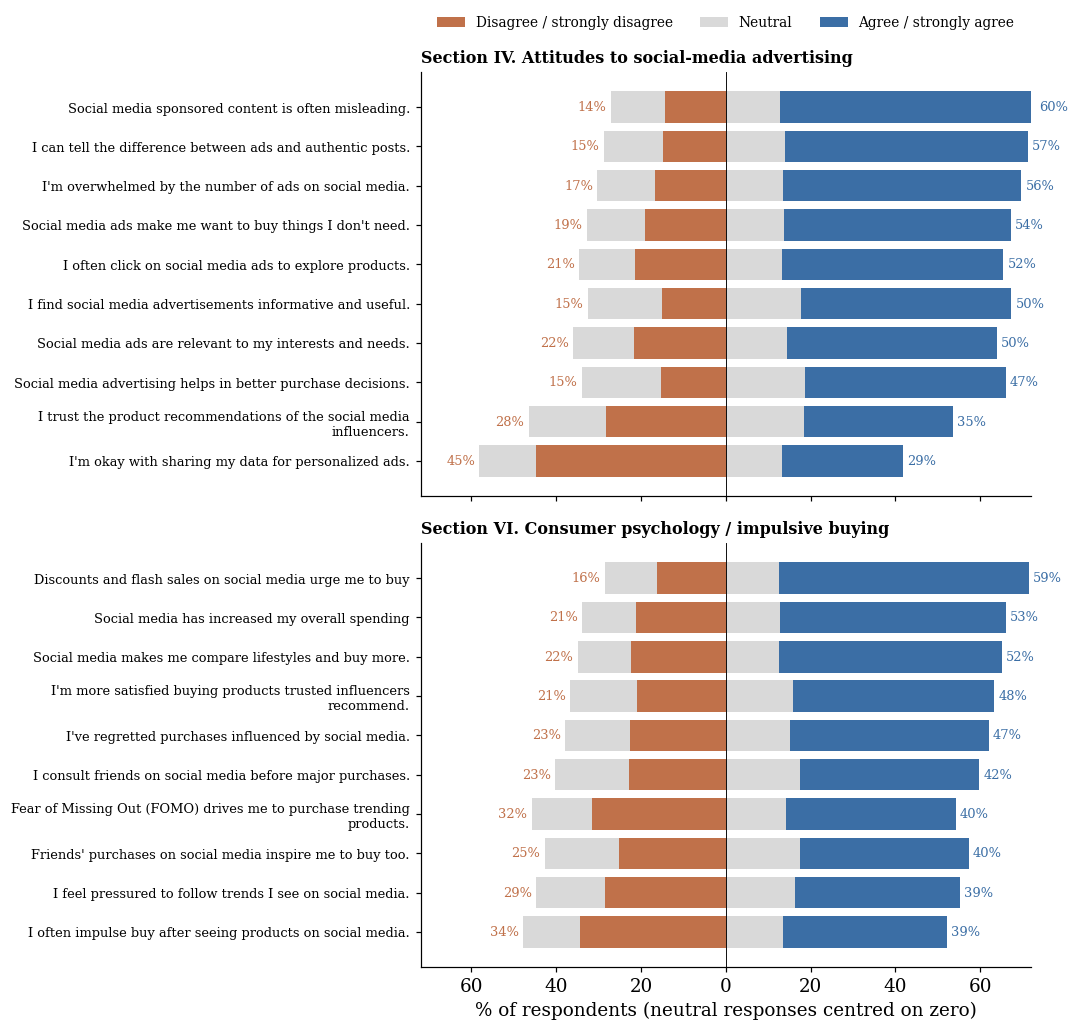


Table3_behaviour_distributions: Distribution of behavioural outcomes (N = 515)


n (%)
Variable                                        Category                                         
Ad exposure (Q10)                               Never                                   84 (16.3)
                                                Rarely (once a week or less)            65 (12.6)
                                                Sometimes (a few times a week)         180 (35.0)
                                                Often (daily)                          100 (19.4)
                                                Very often (multiple times a day)       86 (16.7)
Product discovery via social media (Q12)        Never                                    47 (9.1)
                                                Rarely                                 100 (19.4)
                                                Sometimes                              210 (40.8)
                                                Often                                  120 (23.3)
                                                Always                                   38 (7.4)
Ever bought because of social media (Q13)       No, never                                44 (8.5)
                                                Yes, but rarely                        155 (30.1)
                                                Yes, occasionally                      198 (38.4)
                                                Yes, frequently                        118 (22.9)
Monthly spend influenced by SM, BDT (Q15)       Nothing                                 81 (15.7)
                                                Below 500                              116 (22.5)
                                                500 – 2,000                            169 (32.8)
                                                2,001 – 5,000                           95 (18.4)
                                                5,001 – 10,000                           47 (9.1)
                                                Above 10,000                              7 (1.4)
Researches product on SM first (Q17)            Never                                    22 (4.3)
                                                Rarely                                   35 (6.8)
                                                Sometimes                              141 (27.4)
                                                Usually                                137 (26.6)
                                                Always                                 180 (35.0)
Trust in influencer recommendations (Q18)       Not at all                             121 (23.5)
                                                Slightly                               137 (26.6)
                                                Moderately                             169 (32.8)
                                                Quite a lot                             71 (13.8)
                                                Completely                               17 (3.3)
Stopped following dishonest influencer (Q21)    Yes                                    303 (58.8)
                                                No                                     120 (23.3)
                                                Not Sure                                92 (17.9)
Believes influencers disclose adequately (Q22)  No, almost never                         49 (9.5)
                                                Rarely                                  92 (17.9)
                                                Sometimes                              159 (30.9)
                                                Most of the time                       114 (22.1)
                                                Yes, always                            101 (19.6)
Usual payment method (Q26)                      Cash on Delivery (COD)                 278 (54.0)
                                                Mobile banking (bKash, Nag

saved figure: FigS2_behaviour_distributions
  suggested caption: Figure S2. Distribution of key ordinal outcomes (% of respondents, N = 515)


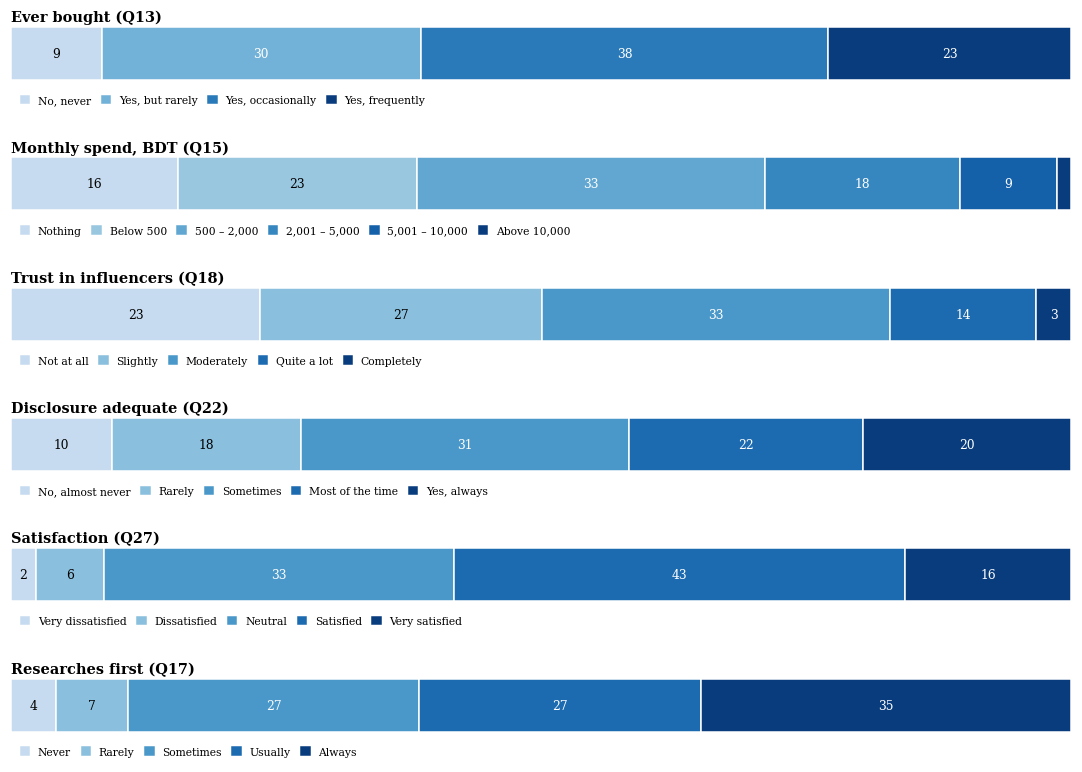


--- Key facts for the Results text ---
Trust (Q18) low (1-2): 50.1% | moderate (3): 32.8% | high (4-5): 17.1%
Ever bought via SM (Q13>=2): 91.5% | frequently: 22.9%
Any monthly SM-influenced spend (Q15>=2): 84.3% | >= BDT 500: 61.7% | > BDT 2,000: 28.9%
COD as usual payment: 54.0%
Satisfied/very satisfied (Q27>=4): 58.3% | dissatisfied (<=2): 8.7%
Disclosure adequate 'most of time/always' (Q22>=4): 41.7%
Research on SM usually/always before buying (Q17>=4): 61.6%
Stopped following dishonest influencer: 58.8%
Likert items significantly above neutral (FDR): relevant, informative, helps_decision, buy_unneeded, misleading, can_tell, click, overwhelmed, friends_insp, discount, regret, compare, satisf_trusted, consult, pressure, spend_up
Likert items significantly below neutral (FDR): data_ok
Not different from neutral: trust_infl, impulse, fomo


In [5]:
# ============================================================
# CELL 4 — Descriptives: Likert items (Table 2, Figure 2) and behavioural outcomes (Table 3, Figure S2)
# ============================================================
from scipy import stats
from statsmodels.stats.multitest import multipletests

N_ = len(clean)
FULL = {v: k for k, v in SHORT.items()}          # short name -> full statement

# ---------- Table 2: 20 Likert items ----------
rows = []
for sec, items in [("IV. Attitudes to social-media advertising", ATT), ("VI. Consumer psychology / impulsive buying", PSY)]:
    for it in items:
        x = clean[it]
        w = stats.wilcoxon(x - 3)                    # H0: median = 3 (neutral); ties/zeros handled by scipy
        rows.append({"Section": sec, "Item": FULL[it], "key": it,
                     "Mean": x.mean(), "SD": x.std(), "Median": x.median(),
                     "% disagree (1-2)": (x <= 2).mean() * 100,
                     "% neutral (3)":    (x == 3).mean() * 100,
                     "% agree (4-5)":    (x >= 4).mean() * 100,
                     "p (vs neutral)": w.pvalue})
T2 = pd.DataFrame(rows)
T2["q (FDR)"] = multipletests(T2["p (vs neutral)"], method="fdr_bh")[1]
T2["Direction"] = np.where(T2["q (FDR)"] >= .05, "n.s.", np.where(T2["Mean"] > 3, "agree", "disagree"))
T2_show = T2.drop(columns=["key"]).set_index(["Section", "Item"]).round(
    {"Mean": 2, "SD": 2, "Median": 1, "% disagree (1-2)": 1, "% neutral (3)": 1, "% agree (4-5)": 1})
T2_show["p (vs neutral)"] = T2_show["p (vs neutral)"].map(lambda p: "<.001" if p < .001 else f"{p:.3f}")
T2_show["q (FDR)"] = T2_show["q (FDR)"].map(lambda p: "<.001" if p < .001 else f"{p:.3f}")
save_table(T2_show, "Table2_likert_descriptives",
           f"Descriptive statistics for the 20 Likert items (N = {N_}); Wilcoxon signed-rank test against the neutral point (3), Benjamini-Hochberg FDR")

# ---------- Figure 2: diverging stacked bars ----------
C_DIS, C_NEU, C_AGR = "#c0714a", "#d9d9d9", "#3b6ea5"
fig, axes = plt.subplots(2, 1, figsize=(10, 9.5), gridspec_kw={"height_ratios": [10, 10]}, sharex=True)
for ax, (sec, items) in zip(axes, [("Section IV. Attitudes to social-media advertising", ATT),
                                  ("Section VI. Consumer psychology / impulsive buying", PSY)]):
    sub = T2[T2.key.isin(items)].sort_values("% agree (4-5)")
    y = np.arange(len(sub))
    dis, neu, agr = sub["% disagree (1-2)"].values, sub["% neutral (3)"].values, sub["% agree (4-5)"].values
    ax.barh(y, -dis, color=C_DIS, label="Disagree / strongly disagree")
    ax.barh(y, -neu / 2, left=-dis, color=C_NEU, label="Neutral")
    ax.barh(y, neu / 2, left=0, color=C_NEU)
    ax.barh(y, agr, left=neu / 2, color=C_AGR, label="Agree / strongly agree")
    for i, (d, n, a) in enumerate(zip(dis, neu, agr)):
        ax.text(-d - n / 2 - 1, i, f"{d:.0f}%", ha="right", va="center", fontsize=8.5, color=C_DIS)
        ax.text(n / 2 + a + 1, i, f"{a:.0f}%", ha="left", va="center", fontsize=8.5, color=C_AGR)
    wrap = lambda s: s if len(s) < 62 else s[:60].rsplit(" ", 1)[0] + "\n" + s[len(s[:60].rsplit(" ", 1)[0]) + 1:]
    ax.set_yticks(y); ax.set_yticklabels([wrap(s) for s in sub["Item"]], fontsize=8.5)
    ax.axvline(0, color="k", lw=.6); ax.set_title(sec, loc="left", fontsize=10.5)
    ax.set_xlim(-72, 72)
axes[0].legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.07), fontsize=9)
axes[1].set_xlabel("% of respondents (neutral responses centred on zero)")
axes[1].set_xticks(range(-60, 71, 20)); axes[1].set_xticklabels([f"{abs(v)}" for v in range(-60, 71, 20)])
CAPTION = (f"Figure 2. Responses to the 20 Likert items (N = {N_})")
fig.tight_layout(); save_fig(fig, "Fig2_likert_diverging", CAPTION); plt.show()

# ---------- Table 3: behavioural outcomes ----------
BEH = [
 ("Ad exposure (Q10)",                         "Q10"),
 ("Product discovery via social media (Q12)",  "Q12"),
 ("Ever bought because of social media (Q13)", "Q13"),
 ("Monthly spend influenced by SM, BDT (Q15)", "Q15"),
 ("Researches product on SM first (Q17)",      "Q17"),
 ("Trust in influencer recommendations (Q18)", "Q18"),
 ("Stopped following dishonest influencer (Q21)", "Q21"),
 ("Believes influencers disclose adequately (Q22)", "Q22"),
 ("Usual payment method (Q26)",                "Q26"),
 ("Satisfaction with SM-influenced purchases (Q27)", "Q27"),
]
rows = []
for lab, q in BEH:
    s = clean[q]
    order = ORD[q] if q in ORD else list(s.value_counts().index)
    vc = s.value_counts()
    for cat in order:
        n_ = int(vc.get(cat, 0)); rows.append((lab, cat, n_, n_ / N_ * 100))
T3 = pd.DataFrame(rows, columns=["Variable", "Category", "n", "%"])
assert (T3.groupby("Variable", sort=False)["n"].sum() == N_).all()
T3["n (%)"] = T3.apply(lambda r: f"{r['n']} ({r['%']:.1f})", axis=1)
save_table(T3.set_index(["Variable", "Category"])[["n (%)"]], "Table3_behaviour_distributions",
           f"Distribution of behavioural outcomes (N = {N_})")
T3.to_csv(f"{OUT}/tables/Table3_behaviour_distributions_numeric.csv", index=False)

# ---------- Figure S2: ordinal outcomes as stacked horizontal bars ----------
ORD_PANEL = [("Q13", "Ever bought (Q13)"), ("Q15", "Monthly spend, BDT (Q15)"), ("Q18", "Trust in influencers (Q18)"),
             ("Q22", "Disclosure adequate (Q22)"), ("Q27", "Satisfaction (Q27)"), ("Q17", "Researches first (Q17)")]
cmap = plt.get_cmap("Blues")
fig, axes = plt.subplots(len(ORD_PANEL), 1, figsize=(10, 7.2))
for ax, (q, title) in zip(axes, ORD_PANEL):
    cats = ORD[q]; vals = np.array([(clean[q] == c).mean() * 100 for c in cats]); left = 0
    cols = [cmap(0.25 + 0.7 * i / (len(cats) - 1)) for i in range(len(cats))]
    for c, v, col in zip(cats, vals, cols):
        ax.barh(0, v, left=left, color=col, edgecolor="white")
        if v >= 2:
            ax.text(left + v / 2, 0, f"{v:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if cols[cats.index(c)][0] < .45 else "black")
        left += v
    ax.set_xlim(0, 100); ax.set_yticks([]); ax.set_xticks([])
    ax.set_title(title, loc="left", fontsize=9.5, pad=2)
    for s_ in ["left", "bottom"]: ax.spines[s_].set_visible(False)
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in cols], [c.split(" (")[0] for c in cats],
              ncol=len(cats), fontsize=7, loc="upper left", bbox_to_anchor=(0, -0.05), handlelength=.8, columnspacing=1)
CAPTION = (f"Figure S2. Distribution of key ordinal outcomes (% of respondents, N = {N_})")
fig.tight_layout(h_pad=1.6); save_fig(fig, "FigS2_behaviour_distributions", CAPTION); plt.show()

# ---------- key facts for the Results text ----------
print("\n--- Key facts for the Results text ---")
print(f"Trust (Q18) low (1-2): {(clean.Q18_n<=2).mean()*100:.1f}% | moderate (3): {(clean.Q18_n==3).mean()*100:.1f}% | high (4-5): {(clean.Q18_n>=4).mean()*100:.1f}%")
print(f"Ever bought via SM (Q13>=2): {(clean.Q13_n>=2).mean()*100:.1f}% | frequently: {(clean.Q13_n==4).mean()*100:.1f}%")
print(f"Any monthly SM-influenced spend (Q15>=2): {(clean.Q15_n>=2).mean()*100:.1f}% | >= BDT 500: {(clean.Q15_n>=3).mean()*100:.1f}% | > BDT 2,000: {(clean.Q15_n>=4).mean()*100:.1f}%")
print(f"COD as usual payment: {clean.Q26.str.startswith('Cash').mean()*100:.1f}%")
print(f"Satisfied/very satisfied (Q27>=4): {(clean.Q27_n>=4).mean()*100:.1f}% | dissatisfied (<=2): {(clean.Q27_n<=2).mean()*100:.1f}%")
print(f"Disclosure adequate 'most of time/always' (Q22>=4): {(clean.Q22_n>=4).mean()*100:.1f}%")
print(f"Research on SM usually/always before buying (Q17>=4): {(clean.Q17_n>=4).mean()*100:.1f}%")
print(f"Stopped following dishonest influencer: {(clean.Q21=='Yes').mean()*100:.1f}%")
print("Likert items significantly above neutral (FDR):", ", ".join(T2.loc[T2.Direction=='agree','key']))
print("Likert items significantly below neutral (FDR):", ", ".join(T2.loc[T2.Direction=='disagree','key']))
print("Not different from neutral:", ", ".join(T2.loc[T2.Direction=='n.s.','key']))

## Cell 5 — Multi-response and single-choice items
Platforms, motives, content types, product categories, credibility cues, influencer type, marketplace and the single most important purchase driver. For the "select top 3" questions the share of respondents who respected the limit is shown separately.
**Outputs:** Tables 4 and 4b; Figure 3.


Table4_multiresponse_items: Multi-response items (N = 515; % of respondents, so columns exceed 100%). For Q9/Q20 the last column restricts to respondents who respected the 'top 3' limit


n (%) % (≤3 ticked only)
Question                                          Option                                                                                          
Platforms used regularly (Q8)                     Facebook                                                           402 (78.1)                   
                                                  YouTube                                                            279 (54.2)                   
                                                  Instagram                                                          210 (40.8)                   
                                                  TikTok                                                             146 (28.3)                   
                                                  LinkedIn                                                           101 (19.6)                   
                                                  Twitter / X                                                         65 (12.6)                   
                                                  Snapchat                                                            62 (12.0)                   
                                                  Pinterest                                                            45 (8.7)                   
                                                  Other (write-in)                                                     13 (2.5)                   
Main reasons for using social media (Q9, 'top 3') Staying connected with friends and family                          298 (57.9)               55.9
                                                  Entertainment and leisure                                          265 (51.5)               48.5
                                                  News and current events                                            157 (30.5)               27.1
                                                  Following trends and influencers                                   145 (28.2)               25.2
                                                  Discovering new products or brands                                 145 (28.2)               25.0
                                                  Professional/career networking                                     122 (23.7)               22.3
                                                  Reading reviews and product information                            108 (21.0)               17.6
Content types influencing purchase (Q14)          User-generated content (reviews, photos, videos by regular users)  241 (46.8)                   
                                                  Brand official posts                                               170 (33.0)                   
                                                  Sponsored ads                                                      160 (31.1)                   
                                                  Influencer/celebrity endorsements                                  154 (29.9)                   
                                                  Live shopping sessions / product demonstrations                    125 (24.3)                   
                                                  Comparison videos or reviews                                       108 (21.0)                   
                                                  Viral trends or challenges                                          64 (12.4)                   
Product categories bought via social media (Q16)  Fashion & clothing                                                 279 (54.2)                   
                                                  Electronics & gadgets                                              181 (35.1)                   
                                                  Food & beverages                                                   170 (33.0)                   
      


Table4b_single_choice_items: Single-choice items (N = 515)


n (%)
Variable                                    Category                                                             
Most credible influencer type (Q19)         Mega influencers (celebrities with millions of followers)  140 (27.2)
                                            Micro influencers (10K–100K followers)                     118 (22.9)
                                            Macro influencers (100K–1M followers)                      116 (22.5)
                                            Regular users (ordinary people, no special status)          89 (17.3)
                                            Nano influencers (less than 10K followers)                  52 (10.1)
Main online marketplace used (Q24)          Daraz                                                      195 (37.9)
                                            Facebook Marketplace                                       125 (24.3)
                                            Other                                                        50 (9.7)
                                            Shajgoj                                                      46 (8.9)
                                            Instagram Shop                                               40 (7.8)
                                            Chaldal                                                      27 (5.2)
                                            Amazon / AliExpress (international)                          18 (3.5)
                                            Brand Websites                                               14 (2.7)
Single most important purchase driver (Q25) Competitive price / discount                               113 (21.9)
                                            Trusted brand or seller                                    109 (21.2)
                                            High number of positive reviews                             99 (19.2)
                                            Easy payment / cash on delivery option                      66 (12.8)
                                            Influencer recommendation                                    40 (7.8)
                                            Fast and reliable delivery                                   36 (7.0)
                                            Return/refund policy                                         29 (5.6)
                                            Attractive product presentation                              23 (4.5)


Number of the 8 listed platforms used: mean = 2.54, SD = 1.38, median = 3; single-platform users = 29.9%
Write-in platforms (WhatsApp, Imo, Discord, etc.): 13 respondents
saved figure: Fig3_multiresponse_items
  suggested caption: Figure 3. Platforms, motives, content, categories and credibility cues (% of respondents, N = 515)


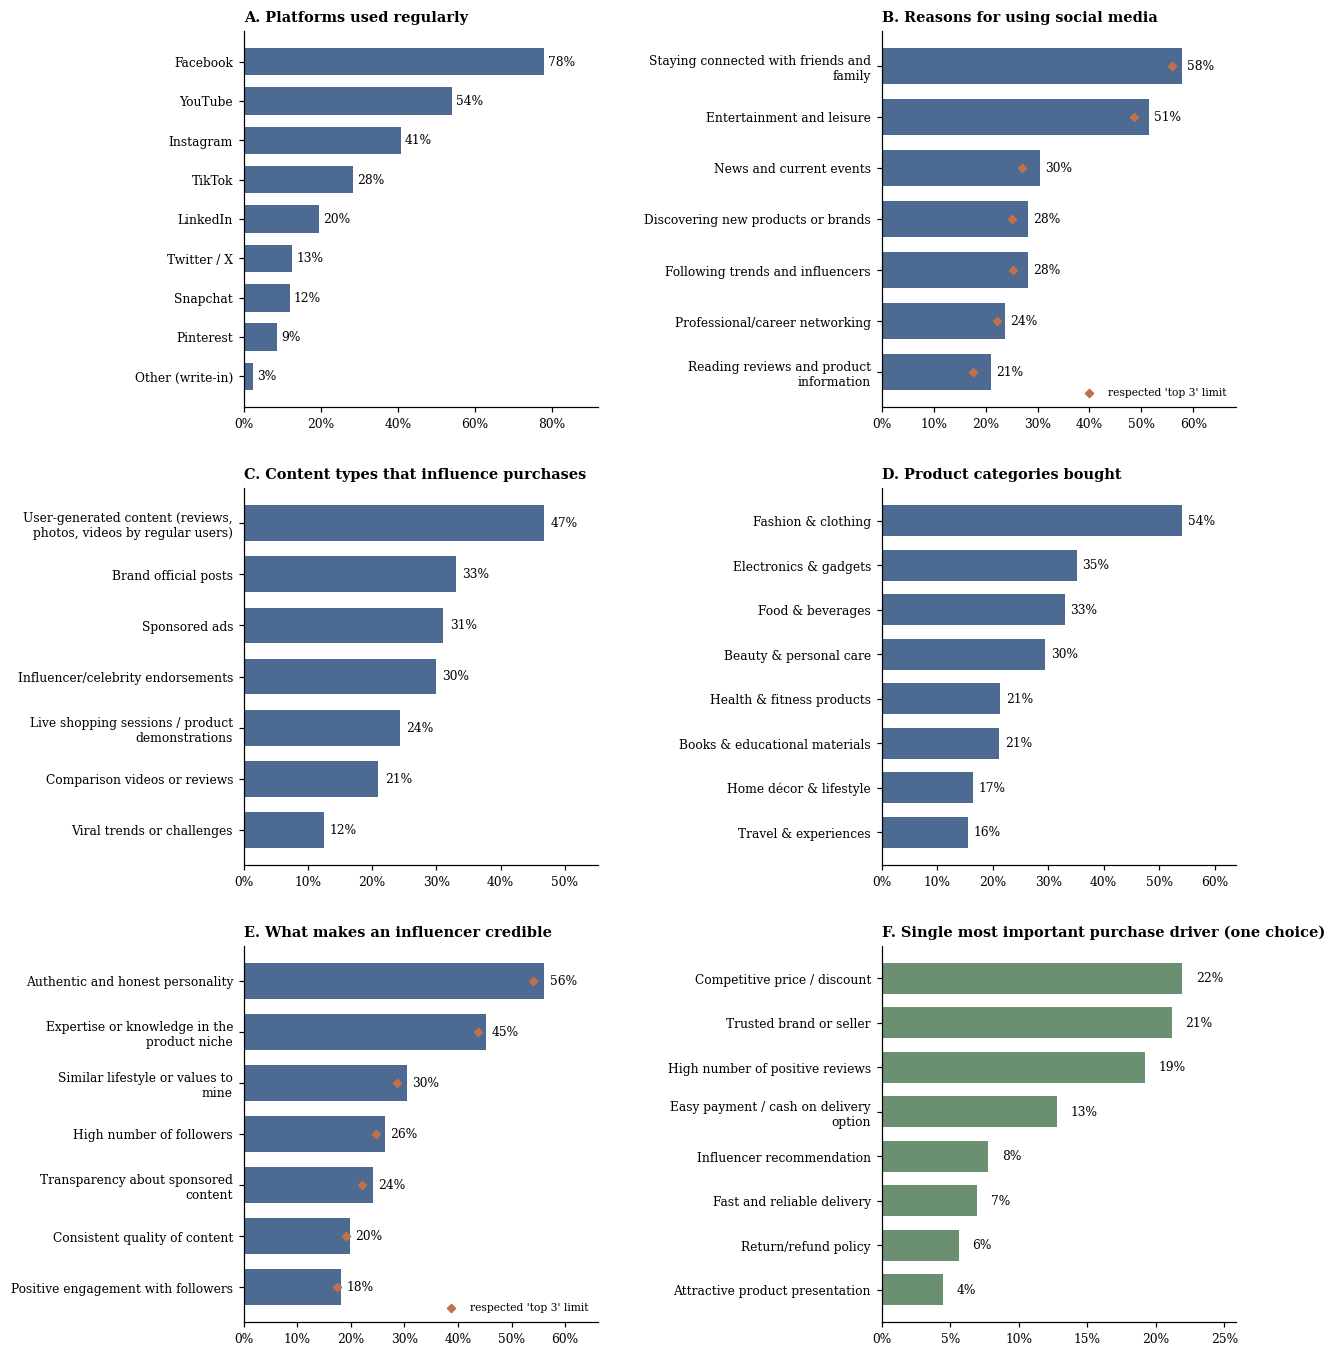


--- Key facts for the Results text ---
Facebook 78.1% | YouTube 54.2% | Instagram 40.8% | TikTok 28.3%
Main motive 'staying connected': 57.9% | 'discovering products': 28.2%
UGC: 46.8% | influencer endorsements: 29.9% | sponsored ads: 31.1%
Fashion: 54.2% | electronics: 35.1%
Credibility: authentic 56.1% | expertise 45.2% | transparency 24.1% | many followers 26.4%
Main purchase driver: price 21.9% | trusted seller 21.2% | reviews 19.2% | influencer 7.8%
Mean options ticked: Q9 = 2.41, Q20 = 2.20 (limit was 3)


In [6]:
# ============================================================
# CELL 5 — Multi-response and single-choice items: platforms, motives, content, categories,
#          credibility cues, influencer type, marketplace, main purchase driver (Table 4, Figure 3)
# ============================================================
N_ = len(clean)

def explode_multi(series, canon=None):
    """Split ';'-separated multi-response strings into a list of clean tokens per respondent.
       If canon is given, any token not in canon is collapsed to 'Other (write-in)'."""
    out = []
    for s in series.fillna(""):
        toks = [t.strip() for t in str(s).split(";") if t.strip()]
        if canon is not None:
            toks = [t if t in canon else "Other (write-in)" for t in toks]
        out.append(sorted(set(toks)))
    return out

# % table for one multi-response question; for the 'top 3' questions also the % among respondents who respected the limit
def multi_table(q, label, canon=None, limit3=False):
    lists = explode_multi(clean[q], canon)
    opts = pd.Series([t for l in lists for t in l]).value_counts()
    rows = []
    ok = ~clean[f"flag_top3_{q}"] if limit3 else None
    for opt, n_ in opts.items():
        has = np.array([opt in l for l in lists])
        r = {"Question": label, "Option": opt, "n": int(n_), "% of respondents": n_ / N_ * 100}
        if limit3:
            r["% (≤3 ticked only)"] = has[ok.values].mean() * 100
        rows.append(r)
    return pd.DataFrame(rows), lists

PLATFORMS = ["Facebook", "YouTube", "Instagram", "TikTok", "LinkedIn", "Twitter / X", "Snapchat", "Pinterest"]
t8,  L8  = multi_table("Q8",  "Platforms used regularly (Q8)", canon=PLATFORMS)
t9,  L9  = multi_table("Q9",  "Main reasons for using social media (Q9, 'top 3')", limit3=True)
t14, L14 = multi_table("Q14", "Content types influencing purchase (Q14)")
t16, L16 = multi_table("Q16", "Product categories bought via social media (Q16)")
t20, L20 = multi_table("Q20", "Influencer credibility cues (Q20, 'top 3')", limit3=True)

T4 = pd.concat([t8, t9, t14, t16, t20], ignore_index=True)
T4["n (%)"] = T4.apply(lambda r: f"{r['n']} ({r['% of respondents']:.1f})", axis=1)
if "% (≤3 ticked only)" in T4: T4["% (≤3 ticked only)"] = T4["% (≤3 ticked only)"].round(1)
T4_show = T4.set_index(["Question", "Option"])[["n (%)", "% (≤3 ticked only)"]].fillna("")
save_table(T4_show, "Table4_multiresponse_items",
           f"Multi-response items (N = {N_}; % of respondents, so columns exceed 100%). For Q9/Q20 the last column restricts to respondents who respected the 'top 3' limit")
T4.to_csv(f"{OUT}/tables/Table4_multiresponse_items_numeric.csv", index=False)

# ---------- single-choice items ----------
S_ITEMS = [("Most credible influencer type (Q19)", "Q19"),
           ("Main online marketplace used (Q24)", "Q24"),
           ("Single most important purchase driver (Q25)", "Q25")]
rows = []
for lab, q in S_ITEMS:
    vc = clean[q].value_counts()
    for cat, n_ in vc.items():
        rows.append((lab, cat, int(n_), n_ / N_ * 100))
T4b = pd.DataFrame(rows, columns=["Variable", "Category", "n", "%"])
assert (T4b.groupby("Variable", sort=False)["n"].sum() == N_).all()
T4b["n (%)"] = T4b.apply(lambda r: f"{r['n']} ({r['%']:.1f})", axis=1)
save_table(T4b.set_index(["Variable", "Category"])[["n (%)"]], "Table4b_single_choice_items",
           f"Single-choice items (N = {N_})")
T4b.to_csv(f"{OUT}/tables/Table4b_single_choice_items_numeric.csv", index=False)

# ---------- platform repertoire ----------
n_plat = pd.Series([len([t for t in l if t != "Other (write-in)"]) for l in L8])
print("\nNumber of the 8 listed platforms used: mean = %.2f, SD = %.2f, median = %d; single-platform users = %.1f%%"
      % (n_plat.mean(), n_plat.std(), n_plat.median(), (n_plat == 1).mean() * 100))
print("Write-in platforms (WhatsApp, Imo, Discord, etc.):", int(sum("Other (write-in)" in l for l in L8)), "respondents")

# ---------- Figure 3: six panels ----------
def barpanel(ax, df, title, color="#4c6a92", compliant=False, wrapn=34):
    d = df.sort_values("% of respondents")
    y = np.arange(len(d))
    ax.barh(y, d["% of respondents"], color=color, height=.7)
    for i, v in enumerate(d["% of respondents"].values):
        ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8)
    if compliant:
        ax.scatter(d["% (≤3 ticked only)"], y, marker="D", s=14, color="#c0714a", zorder=3,
                   label="respected 'top 3' limit")
        ax.legend(fontsize=7, loc="lower right")
    import textwrap
    ax.set_yticks(y); ax.set_yticklabels([textwrap.shorten(textwrap.fill(s, wrapn).split("\n")[0], 38, placeholder="…")
                                          if len(s) <= wrapn else textwrap.fill(s, wrapn) for s in d["Option"]], fontsize=8)
    ax.set_title(title, loc="left", fontsize=9.5)
    ax.set_xlim(0, max(d["% of respondents"].max(), d.get("% (≤3 ticked only)", d["% of respondents"]).max()) * 1.18)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(decimals=0)); ax.tick_params(axis="x", labelsize=8)

fig, axes = plt.subplots(3, 2, figsize=(11.5, 12.5))
barpanel(axes[0, 0], t8,  "A. Platforms used regularly")
barpanel(axes[0, 1], t9,  "B. Reasons for using social media", compliant=True)
barpanel(axes[1, 0], t14, "C. Content types that influence purchases")
barpanel(axes[1, 1], t16, "D. Product categories bought")
barpanel(axes[2, 0], t20, "E. What makes an influencer credible", compliant=True)
d25 = T4b[T4b.Variable.str.contains("Q25")].rename(columns={"Category": "Option", "%": "% of respondents"})
barpanel(axes[2, 1], d25, "F. Single most important purchase driver (one choice)", color="#6b8f71")
CAPTION = (f"Figure 3. Platforms, motives, content, categories and credibility cues (% of respondents, N = {N_})")
fig.tight_layout(h_pad=2.0, w_pad=2.5)
save_fig(fig, "Fig3_multiresponse_items", CAPTION); plt.show()

# ---------- key facts ----------
def pct(df, opt): return df.loc[df.Option == opt, "% of respondents"].iloc[0]
print("\n--- Key facts for the Results text ---")
print(f"Facebook {pct(t8,'Facebook'):.1f}% | YouTube {pct(t8,'YouTube'):.1f}% | Instagram {pct(t8,'Instagram'):.1f}% | TikTok {pct(t8,'TikTok'):.1f}%")
print(f"Main motive 'staying connected': {pct(t9,'Staying connected with friends and family'):.1f}% | 'discovering products': {pct(t9,'Discovering new products or brands'):.1f}%")
print(f"UGC: {pct(t14,'User-generated content (reviews, photos, videos by regular users)'):.1f}% | influencer endorsements: {pct(t14,'Influencer/celebrity endorsements'):.1f}% | sponsored ads: {pct(t14,'Sponsored ads'):.1f}%")
print(f"Fashion: {pct(t16,'Fashion & clothing'):.1f}% | electronics: {pct(t16,'Electronics & gadgets'):.1f}%")
print(f"Credibility: authentic {pct(t20,'Authentic and honest personality'):.1f}% | expertise {pct(t20,'Expertise or knowledge in the product niche'):.1f}% | transparency {pct(t20,'Transparency about sponsored content'):.1f}% | many followers {pct(t20,'High number of followers'):.1f}%")
print(f"Main purchase driver: price {pct(d25,'Competitive price / discount'):.1f}% | trusted seller {pct(d25,'Trusted brand or seller'):.1f}% | reviews {pct(d25,'High number of positive reviews'):.1f}% | influencer {pct(d25,'Influencer recommendation'):.1f}%")
print(f"Mean options ticked: Q9 = {clean.Q9_k.mean():.2f}, Q20 = {clean.Q20_k.mean():.2f} (limit was 3)")

## Cell 6 — Measurement: factorability, parallel analysis, EFA and reliability
Self-contained exploratory factor analysis (principal-axis factoring, oblimin rotation; checked against `factor_analyzer`), parallel analysis for the number of factors, and reliability (Cronbach's alpha, omega, bootstrap CIs).
**Outputs:** Tables 5a–5c and 6; Figure 4.

KMO = 0.889 (item MSA range 0.75-0.94) | Bartlett chi2(190) = 2442.0, p < .001

Table5a_factor_retention: Factor-retention diagnostics for the 20 Likert items (N = 515). Parallel analysis retains 2 factors; Velicer MAP retains 1


,Eigenvalue,Parallel 95th pct,% variance,Velicer MAP
Factor,,,,
1,5.542,1.425,27.712,0.011
2,1.534,1.345,7.669,0.012
3,1.263,1.289,6.313,0.014
4,1.228,1.240,6.141,0.017
5,0.935,1.200,4.673,0.021
6,0.896,1.159,4.479,0.028
7,0.832,1.128,4.160,0.035
8,0.777,1.093,3.885,0.043



Table5b_efa_3factor: Oblimin-rotated pattern matrix, 3-factor principal-axis EFA (N = 515). h2 = communality


,Item,F1,F2,F3,h2,Primary,Gap (1st-2nd)
fomo,Fear of Missing Out (FOMO) drives me to purchase trending products.,0.66,-0.05,0.07,0.42,F1,0.59
pressure,I feel pressured to follow trends I see on social media.,0.64,-0.09,0.08,0.38,F1,0.55
spend_up,Social media has increased my overall spending,0.64,-0.03,-0.04,0.38,F1,0.60
impulse,I often impulse buy after seeing products on social media.,0.49,0.29,-0.18,0.47,F1,0.20
compare,Social media makes me compare lifestyles and buy more.,0.47,0.01,0.24,0.33,F1,0.24
friends_insp,Friends' purchases on social media inspire me to buy too.,0.45,0.21,0.03,0.36,F1,0.24
regret,I've regretted purchases influenced by social media.,0.44,-0.02,0.13,0.22,F1,0.31
discount,Discounts and flash sales on social media urge me to buy,0.42,0.19,-0.22,0.31,F1,0.20
buy_unneeded,Social media ads make me want to buy things I don't need.,0.34,0.21,-0.04,0.23,F1,0.12
consult,I consult friends on social media before major purchases.,0.27,0.25,0.16,0.26,F1,0.02


  SS loadings: [2.77 2.03 0.82] | % variance: [13.8 10.1  4.1]
  Factor correlations:
       F1    F2    F3
F1  1.00  0.57  0.20
F2  0.57  1.00  0.05
F3  0.20  0.05  1.00

Table5c_efa_2factor: Oblimin-rotated pattern matrix, 2-factor principal-axis EFA (N = 515). h2 = communality


,Item,F1,F2,h2,Primary,Gap (1st-2nd)
compare,Social media makes me compare lifestyles and buy more.,0.61,-0.05,0.34,F1,0.56
fomo,Fear of Missing Out (FOMO) drives me to purchase trending products.,0.60,0.04,0.39,F1,0.55
pressure,I feel pressured to follow trends I see on social media.,0.60,-0.00,0.35,F1,0.59
data_ok,I'm okay with sharing my data for personalized ads.,0.52,-0.23,0.19,F1,0.29
spend_up,Social media has increased my overall spending,0.48,0.13,0.32,F1,0.35
regret,I've regretted purchases influenced by social media.,0.48,-0.01,0.22,F1,0.47
click,I often click on social media ads to explore products.,0.47,0.19,0.35,F1,0.28
trust_infl,I trust the product recommendations of the social media influencers.,0.41,0.08,0.21,F1,0.33
friends_insp,Friends' purchases on social media inspire me to buy too.,0.40,0.27,0.35,F1,0.12
consult,I consult friends on social media before major purchases.,0.36,0.20,0.25,F1,0.16


  SS loadings: [2.78 2.28] | % variance: [13.9 11.4]
  Factor correlations:
       F1    F2
F1  1.00  0.56
F2  0.56  1.00
saved figure: Fig4_efa_scree_loadings
  suggested caption: Figure 4. Exploratory factor analysis of the 20 Likert items (N = 515; loadings ≥ .30 in bold)


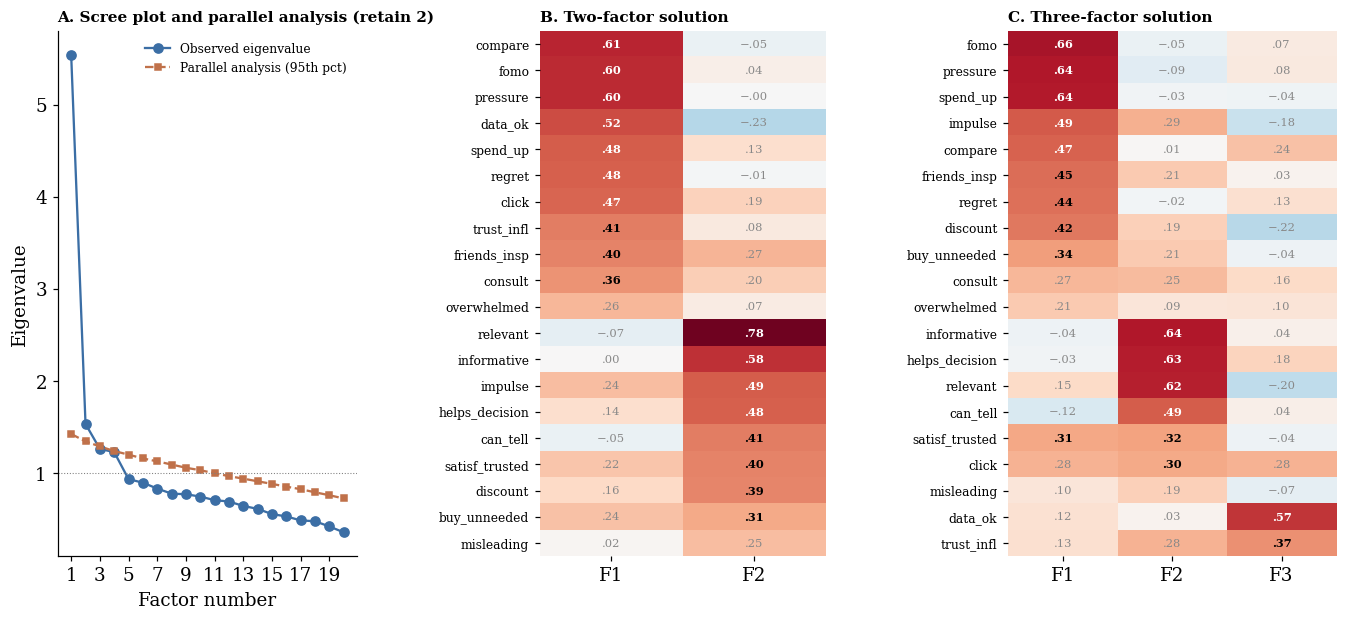


Item sets from the 2-factor solution:
  F1: ['trust_infl', 'data_ok', 'click', 'fomo', 'regret', 'compare', 'pressure', 'spend_up']
  F2: ['relevant', 'informative', 'helps_decision', 'can_tell', 'impulse']
  Not retained (weak/cross-loading): ['buy_unneeded', 'misleading', 'overwhelmed', 'friends_insp', 'discount', 'satisf_trusted', 'consult']

Table6_reliability: Internal consistency (N = 515). alpha 95% CI from 2,000 bootstrap resamples; omega from a one-factor model


,k,Mean (item),SD (scale mean),alpha,alpha 95% CI,omega,Mean inter-item r,Min item-rest r,Items that raise alpha if dropped
Scale,,,,,,,,,
"A priori: Section IV, attitudes to social-media ads (10 items)",10,3.33,0.53,0.70,0.66-0.74,0.71,0.20,0.20,-
"A priori: Section VI, consumer psychology (10 items)",10,3.25,0.64,0.81,0.78-0.84,0.81,0.30,0.39,-
"EFA F1, social-influence susceptibility (8 items)",8,3.19,0.65,0.76,0.72-0.79,0.76,0.28,0.36,-
"EFA F2, perceived ad usefulness (5 items)",5,3.31,0.69,0.71,0.66-0.75,0.73,0.33,0.26,can_tell



Scale scores added to d0 / clean / model: ['Vuln', 'SocInfl', 'AdUseful']
          mean   std  min   max
Vuln      3.25  0.64  1.0  4.60
SocInfl   3.19  0.65  1.0  4.62
AdUseful  3.31  0.69  1.0  5.00

Correlations between scale scores and Q18 trust (Spearman):
  Vuln     rho = +0.21
  SocInfl  rho = +0.16
  AdUseful rho = +0.24


In [7]:
# ============================================================
# CELL 6 — Measurement: factorability, parallel analysis, EFA (Table 5, Figure 4) and reliability (Table 6)
# Self-contained EFA (principal-axis factoring + oblimin rotation); validated against factor_analyzer (max |diff| < 1e-4).
# ============================================================
def smc(R):
    return 1 - 1/np.diag(np.linalg.inv(R))
# principal-axis factoring: iterate the communalities on the reduced correlation matrix until they stop changing; returns loadings and communalities
def paf(R, k, tol=1e-7, maxit=2000):
    h = smc(R)
    for _ in range(maxit):
        Rr = R.copy(); np.fill_diagonal(Rr, h)
        w, v = np.linalg.eigh(Rr); idx = np.argsort(w)[::-1][:k]
        L = v[:, idx] * np.sqrt(np.clip(w[idx], 1e-12, None))
        h_new = (L**2).sum(1)
        if np.max(np.abs(h_new - h)) < tol: h = h_new; break
        h = h_new
    return L, h
# oblimin rotation criterion: value and gradient for a loading matrix L
def _vgq(L, gamma=0.):
    p, k = L.shape
    X = (L**2) @ (np.ones((k, k)) - np.eye(k))
    if gamma != 0: X = (np.eye(p) - gamma/p*np.ones((p, p))) @ X
    return (L**2 * X).sum()/4, L*X
# oblique (oblimin) rotation of an unrotated loading matrix; gamma = 0 is direct quartimin
def oblimin(A, gamma=0., tol=1e-6, maxit=1000):
    p, k = A.shape
    T = np.eye(k); al = 1.
    L = A @ np.linalg.inv(T).T
    f, Gq = _vgq(L, gamma)
    G = -(L.T @ Gq @ np.linalg.inv(T)).T
    for _ in range(maxit):
        Gp = G - T @ np.diag((T*G).sum(0))
        s = np.linalg.norm(Gp)
        if s < tol: break
        al *= 2
        for _i in range(11):
            X = T - al*Gp
            Tt = X @ np.diag(1/np.sqrt((X**2).sum(0)))
            L = A @ np.linalg.inv(Tt).T
            ft, Gq = _vgq(L, gamma)
            if ft < f - .5*s**2*al: break
            al /= 2
        T, f = Tt, ft
        G = -(L.T @ Gq @ np.linalg.inv(T)).T
    Phi = T.T @ T
    return A @ np.linalg.inv(T).T, Phi
# EFA wrapper: extract k factors by principal-axis factoring, then rotate; returns pattern loadings, factor correlations and communalities
def efa(R, k, rotate=True):
    A, h = paf(R, k)
    if k == 1 or not rotate:
        L, Phi = A, np.eye(k)
    else:
        L, Phi = oblimin(A)
    # reflect so that column sums are positive; order by SS loadings
    s = np.sign(L.sum(0)); s[s == 0] = 1
    L = L * s; Phi = Phi * np.outer(s, s)
    order = np.argsort(-(L**2).sum(0))
    L = L[:, order]; Phi = Phi[np.ix_(order, order)]
    return L, Phi, h
# parallel analysis: 95th percentile of eigenvalues from correlation matrices of random normal data with the same n and number of items
def parallel(n, p, iters=1000, seed=1, q=95):
    rng = np.random.default_rng(seed); ev = np.empty((iters, p))
    for i in range(iters):
        X = rng.standard_normal((n, p)); ev[i] = np.sort(np.linalg.eigvalsh(np.corrcoef(X, rowvar=False)))[::-1]
    return np.percentile(ev, q, axis=0), ev.mean(0)
# Kaiser-Meyer-Olkin measure of sampling adequacy (overall and per item), from anti-image partial correlations
def kmo(R):
    Ri = np.linalg.inv(R); d = np.sqrt(np.outer(np.diag(Ri), np.diag(Ri)))
    P = -Ri/d; np.fill_diagonal(P, 0); Rr = R.copy(); np.fill_diagonal(Rr, 0)
    msa = (Rr**2).sum(0)/((Rr**2).sum(0)+(P**2).sum(0))
    return msa, (Rr**2).sum()/((Rr**2).sum()+(P**2).sum())
# Bartlett's test of sphericity: is the correlation matrix different from an identity matrix?
def bartlett(R, n):
    from scipy import stats
    p = R.shape[0]; chi = -(n-1-(2*p+5)/6)*np.log(np.linalg.det(R)); df = p*(p-1)/2
    return chi, df, stats.chi2.sf(chi, df)

FULL = {v: k for k, v in SHORT.items()}          # short name -> full statement

# ---------- 1. correlation matrix, factorability ----------
X20 = clean[ALL20].astype(float)
n_obs, p_items = X20.shape
R = np.corrcoef(X20.values, rowvar=False)
msa, kmo_all = kmo(R)
chi, dfb, pb = bartlett(R, n_obs)
p_txt = "< .001" if pb < .001 else "= %.3f" % pb
print(f"KMO = {kmo_all:.3f} (item MSA range {msa.min():.2f}-{msa.max():.2f}) | Bartlett chi2({int(dfb)}) = {chi:.1f}, p {p_txt}")

# ---------- 2. how many factors? eigenvalues, parallel analysis (95th pct, 1000 sims), Velicer MAP ----------
ev = np.sort(np.linalg.eigvalsh(R))[::-1]
pa95, pamean = parallel(n_obs, p_items, iters=1000, seed=2026, q=95)
w_, v_ = np.linalg.eigh(R); idx_ = np.argsort(w_)[::-1]; w_, v_ = w_[idx_], v_[:, idx_]
map_vals = []
for m in range(0, p_items - 1):
    A_ = v_[:, :m] * np.sqrt(w_[:m]) if m > 0 else np.zeros((p_items, 0))
    C_ = R - A_ @ A_.T; d_ = np.sqrt(np.diag(C_)); P_ = C_ / np.outer(d_, d_)
    map_vals.append((np.sum(P_**2) - p_items) / (p_items * (p_items - 1)))
n_pa = int(np.sum(ev > pa95)); n_map = int(np.argmin(map_vals))
eig_tab = pd.DataFrame({"Eigenvalue": ev[:8], "Parallel 95th pct": pa95[:8], "% variance": ev[:8]/p_items*100,
                        "Velicer MAP": np.array(map_vals[1:9])}, index=range(1, 9))
eig_tab.index.name = "Factor"
save_table(eig_tab.round(3), "Table5a_factor_retention",
           f"Factor-retention diagnostics for the 20 Likert items (N = {n_obs}). Parallel analysis retains {n_pa} factors; Velicer MAP retains {n_map}")

# ---------- 3. EFA solutions ----------
def loadings_table(k):
    L, Phi, h = efa(R, k)
    cols = [f"F{i+1}" for i in range(k)]
    T = pd.DataFrame(L, index=ALL20, columns=cols)
    T["h2"] = h
    absL = np.abs(L); prim = absL.argmax(1)
    T["Primary"] = [cols[i] for i in prim]
    srt = np.sort(absL, axis=1)
    T["Gap (1st-2nd)"] = srt[:, -1] - (srt[:, -2] if k > 1 else 0)
    ss = (L**2).sum(0)
    return T, Phi, ss, L
T3, Phi3, ss3, L3 = loadings_table(3)
T2, Phi2, ss2, L2 = loadings_table(2)
order3 = T3.assign(_p=T3.Primary, _l=T3[["F1","F2","F3"]].abs().max(axis=1)).sort_values(["_p", "_l"], ascending=[True, False]).index
order2 = T2.assign(_p=T2.Primary, _l=T2[["F1","F2"]].abs().max(axis=1)).sort_values(["_p", "_l"], ascending=[True, False]).index
for lab, T, Phi, ss, order, k in [("5b_efa_3factor", T3, Phi3, ss3, order3, 3), ("5c_efa_2factor", T2, Phi2, ss2, order2, 2)]:
    out = T.loc[order].copy()
    out.insert(0, "Item", [FULL[i][:70] for i in out.index])
    out = out.round(2)
    save_table(out, f"Table{lab}", f"Oblimin-rotated pattern matrix, {k}-factor principal-axis EFA (N = {n_obs}). h2 = communality")
    print(f"  SS loadings: {np.round(ss,2)} | % variance: {np.round(ss/p_items*100,1)}")
    print("  Factor correlations:\n", pd.DataFrame(Phi, index=[f'F{i+1}' for i in range(k)], columns=[f'F{i+1}' for i in range(k)]).round(2))

# ---------- 4. Figure 4: scree + parallel analysis, loading heatmaps ----------
fig = plt.figure(figsize=(15, 6.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1.05, 1, 1.15], wspace=0.6)
ax = fig.add_subplot(gs[0])
xs = np.arange(1, p_items + 1)
ax.plot(xs, ev, "o-", color="#3b6ea5", label="Observed eigenvalue")
ax.plot(xs, pa95, "s--", color="#c0714a", ms=4, label="Parallel analysis (95th pct)")
ax.axhline(1, color="grey", lw=.7, ls=":")
ax.set_xlabel("Factor number"); ax.set_ylabel("Eigenvalue"); ax.set_xticks(range(1, 21, 2))
ax.set_title(f"A. Scree plot and parallel analysis (retain {n_pa})", loc="left", fontsize=10); ax.legend(fontsize=8)
def heat(ax, T, order, cols, title):
    M = T.loc[order, cols].values
    im = ax.imshow(M, cmap="RdBu_r", vmin=-.8, vmax=.8, aspect="auto")
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(list(order), fontsize=8)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i,j]:.2f}".replace("0.", ".").replace("-.", "−."), ha="center", va="center", fontsize=7.5,
                    color="white" if abs(M[i, j]) > .45 else ("black" if abs(M[i, j]) >= .30 else "#888888"),
                    fontweight="bold" if abs(M[i, j]) >= .30 else "normal")
    ax.set_title(title, loc="left", fontsize=10)
    for s_ in ax.spines.values(): s_.set_visible(False)
heat(fig.add_subplot(gs[1]), T2, order2, ["F1", "F2"], "B. Two-factor solution")
heat(fig.add_subplot(gs[2]), T3, order3, ["F1", "F2", "F3"], "C. Three-factor solution")
CAPTION = (f"Figure 4. Exploratory factor analysis of the 20 Likert items (N = {n_obs}; loadings ≥ .30 in bold)")
save_fig(fig, "Fig4_efa_scree_loadings", CAPTION); plt.show()

# ---------- 5. reliability ----------
def cronbach(Xdf):
    X = Xdf.values; k = X.shape[1]
    return k / (k - 1) * (1 - X.var(axis=0, ddof=1).sum() / X.sum(1).var(ddof=1))
# McDonald's omega from a one-factor principal-axis solution
def omega_from_loadings(Xdf):
    Rk = np.corrcoef(Xdf.values, rowvar=False)
    if Rk.shape[0] < 3: return np.nan
    A, h = paf(Rk, 1); l = np.abs(A[:, 0])
    return l.sum()**2 / (l.sum()**2 + (1 - l**2).sum())
# percentile bootstrap confidence interval for Cronbach's alpha
def alpha_ci(Xdf, B=2000, seed=11):
    rng = np.random.default_rng(seed); n = len(Xdf); a = np.empty(B)
    for b in range(B): a[b] = cronbach(Xdf.iloc[rng.integers(0, n, n)])
    return np.percentile(a, [2.5, 97.5])
# one row of the reliability table: items, mean inter-item correlation, alpha with CI, omega
def rel_row(name, items):
    Xs = clean[items].astype(float); k = len(items)
    Rk = np.corrcoef(Xs.values, rowvar=False); mir = (Rk.sum() - k) / (k * (k - 1))
    a = cronbach(Xs); lo, hi = alpha_ci(Xs)
    rest = [Xs.drop(columns=c).sum(1).corr(Xs[c]) for c in items]
    drop = [cronbach(Xs.drop(columns=c)) if k > 2 else np.nan for c in items]
    return {"Scale": name, "k": k, "Mean (item)": Xs.mean().mean(), "SD (scale mean)": Xs.mean(1).std(),
            "alpha": a, "alpha 95% CI": f"{lo:.2f}-{hi:.2f}", "omega": omega_from_loadings(Xs),
            "Mean inter-item r": mir, "Min item-rest r": min(rest),
            "Items that raise alpha if dropped": ", ".join([c for c, d in zip(items, drop) if (d == d) and d > a + .005]) or "-"}

# data-driven scales from the RETAINED two-factor solution (parallel analysis):
# primary loading >= .40 and gap to the other factor >= .20
sal = T2[(T2[["F1","F2"]].abs().max(axis=1) >= .40) & (T2["Gap (1st-2nd)"] >= .20)]
S_ITEMS = {f: list(sal.index[sal.Primary == f]) for f in ["F1", "F2"]}
dropped = [i for i in ALL20 if i not in sal.index]
print("\nItem sets from the 2-factor solution:")
for f, its in S_ITEMS.items(): print(f"  {f}: {its}")
print("  Not retained (weak/cross-loading):", dropped)

rel_rows = [rel_row("A priori: Section IV, attitudes to social-media ads (10 items)", ATT),
            rel_row("A priori: Section VI, consumer psychology (10 items)", PSY)]
NAMES = {"F1": "EFA F1, social-influence susceptibility", "F2": "EFA F2, perceived ad usefulness"}
for f, its in S_ITEMS.items():
    if len(its) >= 2: rel_rows.append(rel_row(f"{NAMES[f]} ({len(its)} items)", its))
T6 = pd.DataFrame(rel_rows).set_index("Scale")
T6[["Mean (item)", "SD (scale mean)", "alpha", "omega", "Mean inter-item r", "Min item-rest r"]] = \
    T6[["Mean (item)", "SD (scale mean)", "alpha", "omega", "Mean inter-item r", "Min item-rest r"]].astype(float).round(2)
save_table(T6, "Table6_reliability", f"Internal consistency (N = {n_obs}). alpha 95% CI from 2,000 bootstrap resamples; omega from a one-factor model")

# ---------- 6. scale scores for later cells ----------
SC = {"Vuln": PSY}                                           # a priori Section VI mean = 'impulsive / psychological vulnerability'
for f, its in S_ITEMS.items():
    if len(its) >= 2: SC[{"F1": "SocInfl", "F2": "AdUseful"}[f]] = its
for df_ in (d0, clean, model):
    for nm, its in SC.items(): df_[nm] = df_[its].mean(axis=1)
print("\nScale scores added to d0 / clean / model:", list(SC))
print(clean[list(SC)].describe().round(2).T[["mean", "std", "min", "max"]])
print("\nCorrelations between scale scores and Q18 trust (Spearman):")
from scipy import stats as _st
for nm in SC: print(f"  {nm:8s} rho = {_st.spearmanr(clean[nm], clean['Q18_n'])[0]:+.2f}")

## Cell 7 — Confirmatory factor analysis and validity
CFA with `semopy` (installed automatically if missing): one-factor model for Section VI, the EFA-derived two-factor model tested in a hold-out half, convergent and discriminant validity (CR, AVE, HTMT) and a Harman single-factor check.
**Outputs:** Tables 7 and 8a–8b; Figure 5.

Item skewness range -0.57 to 0.17; excess kurtosis range -0.91 to 0.14  (|skew|<1, |kurt|<2 => ML acceptable)

Split-sample: EFA on random half A (n = 257) -> CFA on half B (n = 258)
  SocInfl_h: ['data_ok', 'click', 'fomo', 'regret', 'compare', 'pressure', 'spend_up']
  AdUseful_h: ['relevant', 'informative', 'helps_decision']

Table7_cfa_fit: CFA fit indices (ML). Conventional targets: CFI/TLI >= .90 (.95 good), RMSEA <= .08 (.06 good), SRMR <= .08


,items,chi2,df,p,chi2/df,CFI,TLI,RMSEA,SRMR,AIC,BIC
Model,,,,,,,,,,,
"M1. Section VI, one factor (10 items)",10,113.4,35,<.001,3.24,0.928,0.907,0.066,0.043,39.6,124.4
"M2. Section VI, two factors: social influence vs impulsive spending",10,112.5,34,<.001,3.31,0.928,0.904,0.067,0.043,41.6,130.7
"M3. All 20 items, one general factor",20,610.8,170,<.001,3.59,0.808,0.785,0.071,0.060,77.6,247.4
"M4. All 20 items, a priori two factors (Section IV vs VI)",20,564.1,169,<.001,3.34,0.828,0.806,0.067,0.059,79.8,253.8
"M5. EFA-derived 2 factors, fitted in hold-out half B (n = 258; 10 items)",10,92.6,34,<.001,2.72,0.888,0.851,0.082,0.064,41.3,115.9
"M5b. Same items, one factor (half B)",10,133.3,35,<.001,3.81,0.811,0.757,0.105,0.073,39.0,110.0



M1 (one factor) vs M2 (two factors), Section VI: delta chi2(1) = 1.0, p = 0.321; delta CFI = -0.000
M3 (one factor) vs M4 (two factors), all 20 items: delta chi2(1) = 46.6, p = 8.49e-12; delta CFI = 0.020

Table8a_cfa_loadings: Standardised CFA loadings


Statement  std_loading
Model factor      item                                                                                             
M1    Vuln        impulse                   I often impulse buy after seeing products on social media.         0.63
                  friends_insp               Friends' purchases on social media inspire me to buy too.         0.60
                  fomo             Fear of Missing Out (FOMO) drives me to purchase trending products.         0.62
                  discount                    Discounts and flash sales on social media urge me to buy         0.48
                  regret                          I've regretted purchases influenced by social media.         0.44
                  compare                       Social media makes me compare lifestyles and buy more.         0.52
                  satisf_trusted     I'm more satisfied buying products trusted influencers recommend.         0.52
                  consult                    I consult friends on social media before major purchases.         0.47
                  pressure                    I feel pressured to follow trends I see on social media.         0.59
                  spend_up                              Social media has increased my overall spending         0.61
M2    Social      friends_insp               Friends' purchases on social media inspire me to buy too.         0.60
                  fomo             Fear of Missing Out (FOMO) drives me to purchase trending products.         0.62
                  pressure                    I feel pressured to follow trends I see on social media.         0.60
                  compare                       Social media makes me compare lifestyles and buy more.         0.52
                  consult                    I consult friends on social media before major purchases.         0.47
                  satisf_trusted     I'm more satisfied buying products trusted influencers recommend.         0.52
      Impulsive   impulse                   I often impulse buy after seeing products on social media.         0.64
                  discount                    Discounts and flash sales on social media urge me to buy         0.49
                  regret                          I've regretted purchases influenced by social media.         0.44
                  spend_up                              Social media has increased my overall spending         0.62
M4    AdAttitudes relevant                    Social media ads are relevant to my interests and needs.         0.63
                  informative               I find social media advertisements informative and useful.         0.57
                  helps_decision          Social media advertising helps in better purchase decisions.         0.59
                  trust_infl      I trust the product recommendations of the social media influencers.         0.45
                  data_ok                          I'm okay with sharing my data for personalized ads.         0.27
                  buy_unneeded               Social media ads make me want to buy things I don't need.         0.48
                  misleading                       Social media sponsored content is often misleading.         0.22
                  can_tell                  I can tell the difference between ads and authentic posts.         0.34
                  click                         I often click on social media ads to explore products.         0.59
                  overwhelmed                    I'm overwhelmed by the number of ads on social media.         0.29
      Psychology  impulse                   I often impulse buy after seeing products on social media.         0.66
                  friends_insp               Friends' purchases on social media inspire me to buy too.         0.61
                  fomo             Fear of Missing Out (FOMO) drives me to purchase trending products.         0.60
                  discount       


Table8b_validity: Convergent validity (CR >= .70, AVE >= .50 desirable) and discriminant validity (factor r, HTMT < .85-.90, sqrt(AVE) > factor r)


k    CR   AVE  sqrt(AVE)  min loading  Factor r  HTMT
Model Factor                                                             
M1    Vuln         10  0.81  0.30       0.55         0.44       NaN   NaN
M2    Social        6  0.73  0.31       0.56         0.47      0.97  0.96
      Impulsive     4  0.63  0.31       0.55         0.44      0.97  0.96
M4    AdAttitudes  10  0.71  0.22       0.47         0.22      0.85  0.87
      Psychology   10  0.81  0.30       0.55         0.43      0.85  0.87
M5    SocInfl_h     7  0.74  0.31       0.55         0.32      0.62  0.68
      AdUseful_h    3  0.66  0.40       0.63         0.51      0.62  0.68


Harman single-factor check: first unrotated component explains 27.7% of variance (<50% => CMV not dominant)
saved figure: Fig5_cfa_loadings
  suggested caption: Figure 5. Confirmatory factor analysis (standardised loadings; panel A N = 515, panel B hold-out half n = 258)


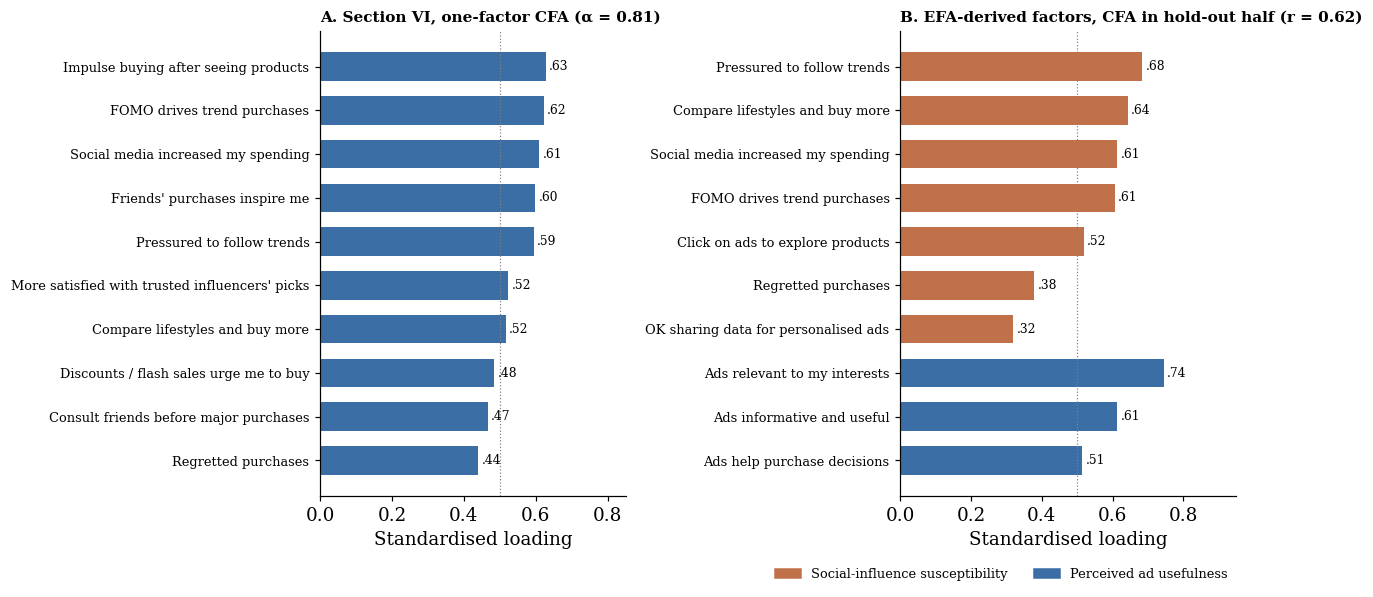

In [8]:
# ============================================================
# CELL 7 — Confirmatory factor analysis and validity checks (Tables 7-8, Figure 5)
# ============================================================
import sys, subprocess
try:
    import semopy
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "semopy"], check=True)
    import semopy
from scipy import stats as _st

N_ = len(clean)
dat = clean[ALL20].astype(float)

# ---------- 0. distributional check (justifies ML estimation with 5-point items) ----------
sk = dat.skew(); ku = dat.kurt()
print(f"Item skewness range {sk.min():.2f} to {sk.max():.2f}; excess kurtosis range {ku.min():.2f} to {ku.max():.2f}  (|skew|<1, |kurt|<2 => ML acceptable)")

# ---------- helpers ----------
def spec(factors):
    return "\n".join(f"{f} =~ " + " + ".join(items) for f, items in factors.items())

# fits one CFA (maximum likelihood, Wishart objective) and returns the estimates plus fit indices
def fit_cfa(factors, data, name):
    m = semopy.Model(spec(factors))
    m.fit(data[sum(factors.values(), [])], obj="MLW")
    st = semopy.calc_stats(m).iloc[0]
    obs = m.vars["observed"]
    S = data[obs].cov().values
    Sig = m.calc_sigma()[0]
    sd = np.sqrt(np.diag(S)); res = (S - Sig) / np.outer(sd, sd)
    srmr = np.sqrt((res[np.tril_indices_from(res)] ** 2).mean())
    ins = m.inspect(std_est=True)
    fit = {"Model": name, "items": len(obs), "chi2": st["chi2"], "df": int(st["DoF"]), "p": st["chi2 p-value"],
           "chi2/df": st["chi2"] / st["DoF"], "CFI": st["CFI"], "TLI": st["TLI"], "RMSEA": st["RMSEA"],
           "SRMR": srmr, "AIC": st["AIC"], "BIC": st["BIC"]}
    return fit, ins, m

# standardised factor loadings from a fitted semopy model
def std_loadings(ins, factors):
    L = ins[(ins.op == "~") & (ins.rval.isin(factors.keys()))].copy()
    L = L.rename(columns={"lval": "item", "rval": "factor", "Est. Std": "std_loading"})
    L["std_loading"] = L["std_loading"].astype(float)
    return L[["factor", "item", "std_loading"]]

# standardised correlation between two latent factors
def factor_corr(ins, f1, f2):
    r = ins[(ins.op == "~~") & (((ins.lval == f1) & (ins.rval == f2)) | ((ins.lval == f2) & (ins.rval == f1)))]
    return float(r["Est. Std"].iloc[0])

# composite reliability (CR) and average variance extracted (AVE) per factor from standardised loadings
def cr_ave(load):
    out = []
    for f, g in load.groupby("factor", sort=False):
        l = g.std_loading.values
        cr = l.sum() ** 2 / (l.sum() ** 2 + (1 - l ** 2).sum())
        out.append({"factor": f, "k": len(l), "CR": cr, "AVE": (l ** 2).mean(), "min loading": l.min()})
    return pd.DataFrame(out).set_index("factor")

# heterotrait-monotrait ratio of correlations (discriminant validity; < .85-.90 desirable)
def htmt(data, items1, items2):
    C = data[items1 + items2].corr().abs().values; k1 = len(items1)
    hetero = C[:k1, k1:].mean()
    m1 = C[:k1, :k1][np.triu_indices(k1, 1)].mean(); m2 = C[k1:, k1:][np.triu_indices(len(items2), 1)].mean()
    return hetero / np.sqrt(m1 * m2)

# ---------- 1. a priori models ----------
SOC6 = ["friends_insp", "fomo", "pressure", "compare", "consult", "satisf_trusted"]   # social influence
IMP4 = ["impulse", "discount", "regret", "spend_up"]                                    # impulsive / spending
F_M1 = {"Vuln": PSY}
F_M2 = {"Social": SOC6, "Impulsive": IMP4}
F_M3 = {"General": ALL20}
F_M4 = {"AdAttitudes": ATT, "Psychology": PSY}

fits, inss, models = [], {}, {}
for key, fac, nm in [("M1", F_M1, "M1. Section VI, one factor (10 items)"),
                     ("M2", F_M2, "M2. Section VI, two factors: social influence vs impulsive spending"),
                     ("M3", F_M3, "M3. All 20 items, one general factor"),
                     ("M4", F_M4, "M4. All 20 items, a priori two factors (Section IV vs VI)")]:
    f, ins, m = fit_cfa(fac, dat, nm); fits.append(f); inss[key] = (ins, fac); models[key] = m

# ---------- 2. split-sample EFA -> CFA for the empirically derived structure ----------
rng = np.random.default_rng(2026)
perm = rng.permutation(N_); idxA, idxB = perm[: N_ // 2], perm[N_ // 2:]
A, B = dat.iloc[idxA], dat.iloc[idxB]
RA = np.corrcoef(A.values, rowvar=False)
LA, PhiA, hA = efa(RA, 2)
TA = pd.DataFrame(np.abs(LA), index=ALL20, columns=["F1", "F2"])
prim = TA.values.argmax(1); srt = np.sort(TA.values, axis=1)
keep = (srt[:, -1] >= .40) & ((srt[:, -1] - srt[:, -2]) >= .20)
SF = {"SocInfl_h": [i for i, p_, k_ in zip(ALL20, prim, keep) if k_ and p_ == 0],
      "AdUseful_h": [i for i, p_, k_ in zip(ALL20, prim, keep) if k_ and p_ == 1]}
print(f"\nSplit-sample: EFA on random half A (n = {len(A)}) -> CFA on half B (n = {len(B)})")
for f, its in SF.items(): print(f"  {f}: {its}")
if min(len(v) for v in SF.values()) >= 3:
    f5, ins5, m5 = fit_cfa(SF, B, f"M5. EFA-derived 2 factors, fitted in hold-out half B (n = {len(B)}; {sum(len(v) for v in SF.values())} items)")
    fits.append(f5); inss["M5"] = (ins5, SF); models["M5"] = m5
    f5b, _, _ = fit_cfa({"General": sum(SF.values(), [])}, B, "M5b. Same items, one factor (half B)")
    fits.append(f5b)
else:
    print("  (a factor has <3 items in this split; M5 skipped)")

T7 = pd.DataFrame(fits).set_index("Model")
T7["p"] = T7["p"].map(lambda v: "<.001" if v < .001 else f"{v:.3f}")
T7 = T7.round({"chi2": 1, "chi2/df": 2, "CFI": 3, "TLI": 3, "RMSEA": 3, "SRMR": 3, "AIC": 1, "BIC": 1})
save_table(T7, "Table7_cfa_fit",
           "CFA fit indices (ML). Conventional targets: CFI/TLI >= .90 (.95 good), RMSEA <= .08 (.06 good), SRMR <= .08")

# nested comparisons (factor correlation fixed to 1 vs freely estimated)
def chi_diff(a, b, label):
    fa = [f for f in fits if f["Model"].startswith(a)][0]; fb = [f for f in fits if f["Model"].startswith(b)][0]
    d = fa["chi2"] - fb["chi2"]; dd = fa["df"] - fb["df"]
    print(f"{label}: delta chi2({dd}) = {d:.1f}, p = {_st.chi2.sf(d, dd):.3g}; delta CFI = {fb['CFI'] - fa['CFI']:.3f}")
print()
chi_diff("M1", "M2", "M1 (one factor) vs M2 (two factors), Section VI")
chi_diff("M3", "M4", "M3 (one factor) vs M4 (two factors), all 20 items")

# ---------- 3. loadings, convergent and discriminant validity ----------
rows_l, rows_v = [], []
for key in [k for k in ["M1", "M2", "M4", "M5"] if k in inss]:
    ins, fac = inss[key]
    L = std_loadings(ins, fac); L.insert(0, "Model", key); rows_l.append(L)
    cv = cr_ave(L[["factor", "item", "std_loading"]])
    facs = list(fac.keys())
    for f in facs:
        rows_v.append({"Model": key, "Factor": f, "k": int(cv.loc[f, "k"]), "CR": cv.loc[f, "CR"], "AVE": cv.loc[f, "AVE"],
                       "sqrt(AVE)": np.sqrt(cv.loc[f, "AVE"]), "min loading": cv.loc[f, "min loading"],
                       "Factor r": np.nan, "HTMT": np.nan})
    if len(facs) == 2:
        r_ = factor_corr(ins, facs[0], facs[1]); ht = htmt(dat if key != "M5" else B, fac[facs[0]], fac[facs[1]])
        for rr in rows_v[-2:]: rr["Factor r"] = r_; rr["HTMT"] = ht
T8l = pd.concat(rows_l, ignore_index=True)
T8l["std_loading"] = T8l["std_loading"].round(2)
T8l["Statement"] = T8l["item"].map(lambda i: FULL[i][:70])
save_table(T8l.set_index(["Model", "factor", "item"])[["Statement", "std_loading"]], "Table8a_cfa_loadings",
           "Standardised CFA loadings")
T8v = pd.DataFrame(rows_v).set_index(["Model", "Factor"]).round(2)
save_table(T8v, "Table8b_validity",
           "Convergent validity (CR >= .70, AVE >= .50 desirable) and discriminant validity (factor r, HTMT < .85-.90, sqrt(AVE) > factor r)")

# ---------- 4. common-method check ----------
ev_ = np.sort(np.linalg.eigvalsh(np.corrcoef(dat.values, rowvar=False)))[::-1]
print(f"\nHarman single-factor check: first unrotated component explains {ev_[0]/20*100:.1f}% of variance (<50% => CMV not dominant)")

# ---------- 5. Figure 5: standardised loadings ----------
LAB = {"impulse": "Impulse buying after seeing products", "friends_insp": "Friends' purchases inspire me",
       "fomo": "FOMO drives trend purchases", "discount": "Discounts / flash sales urge me to buy",
       "regret": "Regretted purchases", "compare": "Compare lifestyles and buy more",
       "satisf_trusted": "More satisfied with trusted influencers' picks", "consult": "Consult friends before major purchases",
       "pressure": "Pressured to follow trends", "spend_up": "Social media increased my spending",
       "relevant": "Ads relevant to my interests", "informative": "Ads informative and useful",
       "helps_decision": "Ads help purchase decisions", "data_ok": "OK sharing data for personalised ads",
       "click": "Click on ads to explore products"}
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.6), gridspec_kw={"width_ratios": [1, 1.1]})
ins1, fac1 = inss["M1"]; L1 = std_loadings(ins1, fac1).sort_values("std_loading")
ax = axes[0]
ax.barh([LAB[i] for i in L1.item], L1.std_loading, color="#3b6ea5", height=.65)
for i, v in enumerate(L1.std_loading): ax.text(v + .01, i, f"{v:.2f}".lstrip("0"), va="center", fontsize=8)
ax.axvline(.5, color="grey", ls=":", lw=.8); ax.set_xlim(0, .85); ax.tick_params(axis="y", labelsize=8.5)
ax.set_title(f"A. Section VI, one-factor CFA (α = {T6.loc[[i for i in T6.index if 'Section VI' in i][0], 'alpha']:.2f})", loc="left", fontsize=10)
ax.set_xlabel("Standardised loading")
if "M5" in inss:
    ins5, fac5 = inss["M5"]; L5 = std_loadings(ins5, fac5)
    L5 = L5.assign(_o=L5.factor.map({k: i for i, k in enumerate(fac5)})).sort_values(["_o", "std_loading"], ascending=[False, True])
    ax = axes[1]
    cols_ = {list(fac5)[0]: "#c0714a", list(fac5)[1]: "#3b6ea5"}
    ax.barh([LAB[i] for i in L5.item], L5.std_loading, color=[cols_[f] for f in L5.factor], height=.65)
    for i, v in enumerate(L5.std_loading): ax.text(v + .01, i, f"{v:.2f}".lstrip("0"), va="center", fontsize=8)
    ax.axvline(.5, color="grey", ls=":", lw=.8); ax.set_xlim(0, .95); ax.tick_params(axis="y", labelsize=8.5)
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=cols_[k], label=lab) for k, lab in zip(fac5, ["Social-influence susceptibility", "Perceived ad usefulness"])],
              fontsize=8.5, loc="upper center", bbox_to_anchor=(0.3, -0.13), ncol=2)
    ax.set_title(f"B. EFA-derived factors, CFA in hold-out half (r = {factor_corr(ins5, *fac5.keys()):.2f})", loc="left", fontsize=10)
    ax.set_xlabel("Standardised loading")
CAPTION = (f"Figure 5. Confirmatory factor analysis (standardised loadings; panel A N = {N_}, panel B hold-out half n = {len(B)})")
fig.tight_layout(); save_fig(fig, "Fig5_cfa_loadings", CAPTION); plt.show()

## Cell 8 — The trust gradient
Builds the analysis variables used by all later models (trust, spending, purchase frequency, containment behaviours, vulnerability) and shows how participation, spending and risk containment change across the five trust levels.
**Outputs:** Tables 9a–9b; Figure 6.


Table9_trust_gradient: Percentage of respondents by level of trust in influencers (Q18); unadjusted logistic trend per one-level increase (N = 515)


,1 Not at all,2 Slightly,3 Moderately,4 Quite a lot,5 Completely,All,OR per level [95% CI],p,q (FDR)
Outcome,,,,,,,,,
n,121,137,169,71,17,515,,,
Ever bought via social media (Q13 >= 2),87.6,90.5,95.9,93.0,76.5,91.5,"1.15 [0.86, 1.54]",0.342,0.342
Any monthly social-media-influenced spend (Q15 >= 2),63.6,82.5,93.5,97.2,100.0,84.3,"2.83 [2.11, 3.80]",<.001,<.001
Spends >= BDT 500 a month,44.6,51.8,71.6,81.7,82.4,61.7,"1.77 [1.47, 2.12]",<.001,<.001
"Spends > BDT 2,000 a month",19.8,21.2,28.4,59.2,35.3,28.9,"1.58 [1.31, 1.89]",<.001,<.001
Buys frequently (Q13 = 'frequently'),24.8,16.1,14.8,53.5,17.6,22.9,"1.26 [1.04, 1.52]",0.018,0.025
Usually pays cash on delivery,61.2,58.4,53.3,40.8,29.4,54.0,"0.76 [0.65, 0.90]",<.001,0.002
Price/discount is main purchase driver,30.6,21.9,20.7,12.7,11.8,21.9,"0.74 [0.60, 0.90]",0.003,0.006
Usually/always researches before buying,63.6,53.3,62.7,73.2,52.9,61.6,"1.08 [0.92, 1.28]",0.334,0.342



Table9b_trust_groups: Same outcomes by three trust groups (%)


Trust18,Low (1-2),Moderate (3),High (4-5)
Ever bought via social media (Q13 >= 2),89.1,95.9,89.8
Any monthly social-media-influenced spend (Q15 >= 2),73.6,93.5,97.7
Spends >= BDT 500 a month,48.4,71.6,81.8
"Spends > BDT 2,000 a month",20.5,28.4,54.5
Buys frequently (Q13 = 'frequently'),20.2,14.8,46.6
Usually pays cash on delivery,59.7,53.3,38.6
Price/discount is main purchase driver,26.0,20.7,12.5
Usually/always researches before buying,58.1,62.7,69.3
Satisfied with purchases (Q27 >= 4),50.4,65.1,68.2
Influencer is main purchase driver,5.8,7.7,13.6


saved figure: Fig6_trust_gradient
  suggested caption: Figure 6. Trust in influencers, purchasing, spending and risk containment (N = 515; points = %, bars = 95% Wilson CI; OR = unadjusted logit per trust level)


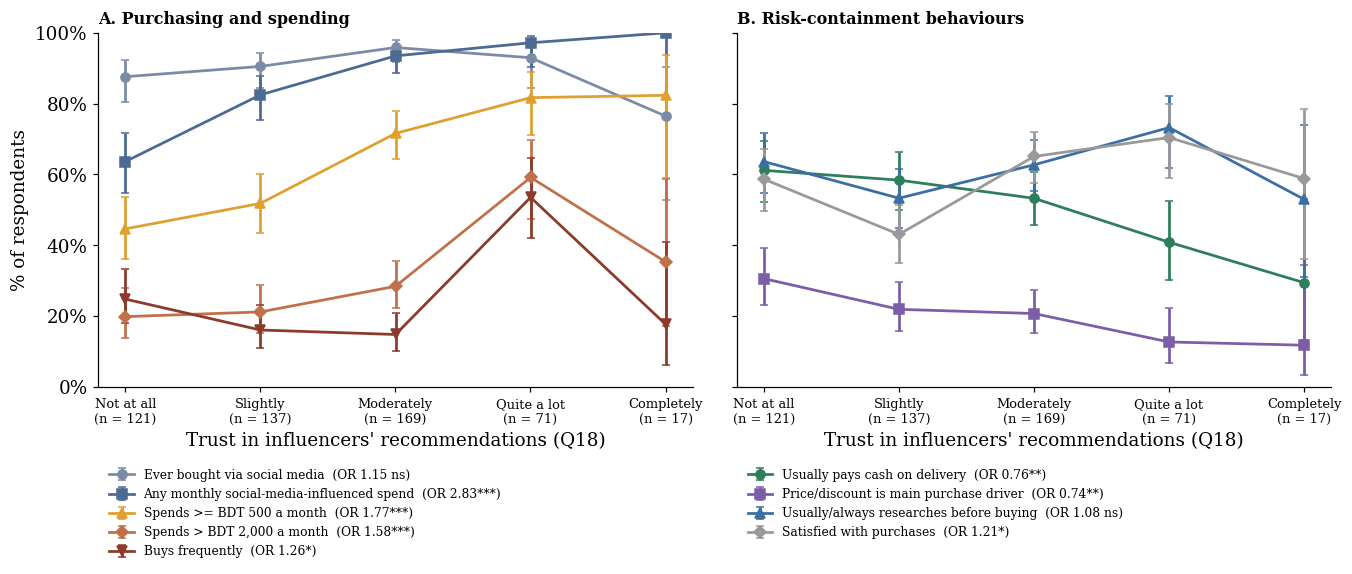


--- Key facts for the Results text ---
Low trust (1-2), n = 258: ever bought 89.1% | any spend 73.6% | >= BDT 500 48.4% | > BDT 2,000 20.5% | COD 59.7%
High trust (4-5), n = 88: ever bought 89.8% | any spend 97.7% | >= BDT 500 81.8% | > BDT 2,000 54.5% | COD 38.6%
Spearman rho (trust, spend category) = 0.34 (p = 1.5e-15); (trust, purchase frequency) = 0.17
Participation OR per level:                                              Outcome  OR per trust level     p
             Ever bought via social media (Q13 >= 2)                1.15 0.342
Any monthly social-media-influenced spend (Q15 >= 2)                2.83 0.000


In [9]:
# ============================================================
# CELL 8 — The trust gradient: participation vs intensity vs containment (Table 9, Figure 6)
# Also builds the analysis variables used by all later models.
# ============================================================
import statsmodels.api as sm
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
from scipy import stats as _st

# ---------- 1. analysis variables (added to d0, clean and model) ----------
def has_opt(s, opt): return int(opt in [x.strip() for x in str(s).split(";")])
UGC_TXT = "User-generated content (reviews, photos, videos by regular users)"
# derives every analysis variable (outcomes, binary cut-offs, containment behaviours, vulnerability) from the coded survey data
def add_vars(df):
    df["Trust18"] = df["Q18_n"]; df["Buy"] = df["Q13_n"]; df["Spend"] = df["Q15_n"]; df["Satisf"] = df["Q27_n"]
    df["Research"] = df["Q17_n"]; df["Income"] = df["Q5_n"]; df["Edu"] = df["Q3_n"]; df["Age"] = df["Q1_n"]
    df["NFollow"] = df["Q11_n"]; df["SMhrs"] = df["Q7_n"]
    df["Female"] = (df["Q2"].fillna("") == "Female").astype(int)
    df["Urban"] = (df["Q6"].fillna("") == "Urban (city)").astype(int); df["Rural"] = (df["Q6"].fillna("") == "Rural").astype(int)
    df["COD"] = df["Q26"].fillna("").str.startswith("Cash").astype(int)
    df["P_buy"] = (df["Buy"] >= 2).astype(int)           # ever bought because of social media
    df["P_spend"] = (df["Spend"] >= 2).astype(int)       # any monthly social-media-influenced spend
    df["Spend500"] = (df["Spend"] >= 3).astype(int)      # >= BDT 500
    df["Spend2000"] = (df["Spend"] >= 4).astype(int)     # > BDT 2,000
    df["FreqBuy"] = (df["Buy"] == 4).astype(int)
    df["ResH"] = (df["Research"] >= 4).astype(int)       # usually / always researches first
    df["Satisfied"] = (df["Satisf"] >= 4).astype(int)
    df["UGC"] = df["Q14"].apply(lambda s: has_opt(s, UGC_TXT))
    df["CMP"] = df["Q14"].apply(lambda s: has_opt(s, "Comparison videos or reviews"))
    for k, v in {"rev": "High number of positive reviews", "sell": "Trusted brand or seller", "ret": "Return/refund policy",
                 "price": "Competitive price / discount", "infl": "Influencer recommendation",
                 "cod": "Easy payment / cash on delivery option"}.items():
        df["Q25_" + k] = (df["Q25"].fillna("") == v).astype(int)
    # safeguard index (0-4): COD, research-first, uses UGC/comparison content, reviews/seller/returns as main driver
    df["SG"] = df["COD"] + df["ResH"] + ((df["UGC"] + df["CMP"]) > 0).astype(int) + ((df["Q25_rev"] + df["Q25_sell"] + df["Q25_ret"]) > 0).astype(int)
    return df
for _df in (d0, clean, model): add_vars(_df)

# ---------- 2. outcomes ----------
OUT_PART = [("Ever bought via social media (Q13 >= 2)", "P_buy"),
            ("Any monthly social-media-influenced spend (Q15 >= 2)", "P_spend")]
OUT_INT  = [("Spends >= BDT 500 a month", "Spend500"),
            ("Spends > BDT 2,000 a month", "Spend2000"),
            ("Buys frequently (Q13 = 'frequently')", "FreqBuy")]
OUT_CONT = [("Usually pays cash on delivery", "COD"),
            ("Price/discount is main purchase driver", "Q25_price"),
            ("Usually/always researches before buying", "ResH"),
            ("Satisfied with purchases (Q27 >= 4)", "Satisfied"),
            ("Influencer is main purchase driver", "Q25_infl")]
ALLOUT = OUT_PART + OUT_INT + OUT_CONT
N_ = len(clean)

# ---------- 3. trend tests (unadjusted logit: OR per one-level increase in trust) ----------
tr = []
for lab, v in ALLOUT:
    m = sm.Logit(clean[v], sm.add_constant(clean[["Trust18"]].astype(float))).fit(disp=0)
    ci = np.exp(m.conf_int().loc["Trust18"])
    tr.append({"Outcome": lab, "var": v, "OR per trust level": np.exp(m.params["Trust18"]), "CI low": ci[0], "CI high": ci[1], "p": m.pvalues["Trust18"]})
TR = pd.DataFrame(tr)
TR["q (FDR)"] = multipletests(TR["p"], method="fdr_bh")[1]
TR["stars"] = np.where(TR["q (FDR)"] < .001, "***", np.where(TR["q (FDR)"] < .01, "**", np.where(TR["q (FDR)"] < .05, "*", "")))

# ---------- 4. Table 9: % by trust level ----------
lv = [1, 2, 3, 4, 5]; LV_LAB = {1: "1 Not at all", 2: "2 Slightly", 3: "3 Moderately", 4: "4 Quite a lot", 5: "5 Completely"}
rows = []
for lab, v in ALLOUT:
    r = {"Outcome": lab}
    for l in lv: r[LV_LAB[l]] = clean.loc[clean.Trust18 == l, v].mean() * 100
    r["All"] = clean[v].mean() * 100
    t = TR[TR["var"] == v].iloc[0]
    r["OR per level [95% CI]"] = f"{t['OR per trust level']:.2f} [{t['CI low']:.2f}, {t['CI high']:.2f}]"
    r["p"] = "<.001" if t["p"] < .001 else f"{t['p']:.3f}"
    r["q (FDR)"] = "<.001" if t["q (FDR)"] < .001 else f"{t['q (FDR)']:.3f}"
    rows.append(r)
nrow = {"Outcome": "n"}; nrow.update({LV_LAB[l]: int((clean.Trust18 == l).sum()) for l in lv}); nrow["All"] = N_
T9 = pd.concat([pd.DataFrame([nrow]), pd.DataFrame(rows)], ignore_index=True).set_index("Outcome")
for c in [LV_LAB[l] for l in lv] + ["All"]:
    T9[c] = [f"{x:.0f}" if i == 0 else f"{x:.1f}" for i, x in enumerate(T9[c])]
T9 = T9.fillna("")
save_table(T9, "Table9_trust_gradient",
           f"Percentage of respondents by level of trust in influencers (Q18); unadjusted logistic trend per one-level increase (N = {N_})")

# 3-group summary
grp = pd.cut(clean.Trust18, [0, 2, 3, 5], labels=["Low (1-2)", "Moderate (3)", "High (4-5)"])
G = clean.groupby(grp, observed=True)[[v for _, v in ALLOUT]].mean().T * 100
G.index = [l for l, _ in ALLOUT]; G.loc["n"] = clean.groupby(grp, observed=True).size().values
G = G.round(1)
save_table(G, "Table9b_trust_groups", "Same outcomes by three trust groups (%)")

# ---------- 5. Figure 6 ----------
def wil(v):
    out = []
    for l in lv:
        s = clean.loc[clean.Trust18 == l, v]; k, n = int(s.sum()), len(s)
        lo, hi = proportion_confint(k, n, method="wilson"); out.append((k / n * 100, lo * 100, hi * 100))
    return np.array(out)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.6), sharey=True)
# one panel of Figure 6: outcomes by trust level with Wilson CIs; the legend carries the unadjusted odds ratio per trust level
def panel(ax, items, title, cols, markers):
    for (lab, v), c, mk in zip(items, cols, markers):
        a = wil(v); t = TR[TR["var"] == v].iloc[0]
        short = lab.split(" (")[0]
        ax.errorbar(np.array(lv) + (np.random.default_rng(1).uniform(-.04, .04)), a[:, 0], yerr=[a[:, 0] - a[:, 1], a[:, 2] - a[:, 0]],
                    marker=mk, ms=6, lw=1.8, capsize=2.5, color=c,
                    label=f"{short}  (OR {t['OR per trust level']:.2f}{t['stars'] or ' ns'})")
    ax.set_xticks(lv); ax.set_xticklabels([f"{LV_LAB[l].split(' ', 1)[1]}\n(n = {int((clean.Trust18 == l).sum())})" for l in lv], fontsize=8.5)
    ax.set_xlabel("Trust in influencers' recommendations (Q18)"); ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(decimals=0)); ax.set_title(title, loc="left", fontsize=10.5)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.2), ncol=1)
panel(axes[0], OUT_PART + OUT_INT, "A. Purchasing and spending",
      ["#7a8ca5", "#4c6a92", "#e0a030", "#c0714a", "#8b3a2b"], ["o", "s", "^", "D", "v"])
panel(axes[1], [x for x in OUT_CONT if x[1] != "Q25_infl"], "B. Risk-containment behaviours",
      ["#2e7d5b", "#7b5ea7", "#3b6ea5", "#999999"], ["o", "s", "^", "D"])
axes[0].set_ylabel("% of respondents")
CAPTION = (f"Figure 6. Trust in influencers, purchasing, spending and risk containment (N = {N_}; points = %, bars = 95% Wilson CI; OR = unadjusted logit per trust level)")
fig.tight_layout(); save_fig(fig, "Fig6_trust_gradient", CAPTION); plt.show()

# ---------- 6. key facts for the text ----------
lo_, hi_ = clean[clean.Trust18 <= 2], clean[clean.Trust18 >= 4]
print("\n--- Key facts for the Results text ---")
print(f"Low trust (1-2), n = {len(lo_)}: ever bought {lo_.P_buy.mean()*100:.1f}% | any spend {lo_.P_spend.mean()*100:.1f}% | >= BDT 500 {lo_.Spend500.mean()*100:.1f}% | > BDT 2,000 {lo_.Spend2000.mean()*100:.1f}% | COD {lo_.COD.mean()*100:.1f}%")
print(f"High trust (4-5), n = {len(hi_)}: ever bought {hi_.P_buy.mean()*100:.1f}% | any spend {hi_.P_spend.mean()*100:.1f}% | >= BDT 500 {hi_.Spend500.mean()*100:.1f}% | > BDT 2,000 {hi_.Spend2000.mean()*100:.1f}% | COD {hi_.COD.mean()*100:.1f}%")
print(f"Spearman rho (trust, spend category) = {_st.spearmanr(clean.Trust18, clean.Spend)[0]:.2f} (p = {_st.spearmanr(clean.Trust18, clean.Spend)[1]:.3g}); (trust, purchase frequency) = {_st.spearmanr(clean.Trust18, clean.Buy)[0]:.2f}")
print("Participation OR per level:", TR[TR['var'].isin(['P_buy','P_spend'])][['Outcome','OR per trust level','p']].round(3).to_string(index=False))

## Cell 9 — Group differences with multiplicity control
Kruskal–Wallis tests of 8 groupings × 7 outcomes with effect sizes (ε²) and FDR correction over all tests, then group means for the pairs that survive.
**Outputs:** Tables 10 and 11; Figure 7.


Table10_group_differences: Kruskal-Wallis tests of 56 grouping x outcome pairs (cleaned sample); epsilon^2 = effect size; Benjamini-Hochberg FDR over all tests


k    n       H      p  epsilon2  Spearman rho (ordered groups) q (FDR, all tests)  sig
Grouping                Outcome                                                                                                                              
Gender                  Trust in influencers (Q18)                     2  515   1.198  0.274     0.000                            NaN              0.375     
                        Monthly spend (Q15)                            2  515   0.007  0.935     0.000                            NaN              0.935     
                        Purchase frequency (Q13)                       2  515   4.976  0.026     0.008                            NaN              0.048    *
                        Psychological vulnerability (Section VI mean)  2  515   4.190  0.041     0.006                            NaN              0.073     
                        Pays cash on delivery                          2  515   3.102  0.078     0.004                            NaN              0.122     
                        Satisfaction (Q27)                             2  515   0.069  0.793     0.000                            NaN              0.822     
                        Researches before buying (Q17)                 2  515   0.073  0.787     0.000                            NaN              0.822     
Age group               Trust in influencers (Q18)                     5  515   0.920  0.922     0.000                          0.020              0.935     
                        Monthly spend (Q15)                            5  515  21.589  <.001     0.034                          0.178              0.001   **
                        Purchase frequency (Q13)                       5  515   9.367  0.053     0.011                         -0.082              0.092     
                        Psychological vulnerability (Section VI mean)  5  515   3.140  0.535     0.000                         -0.008              0.611     
                        Pays cash on delivery                          5  515   5.627  0.229     0.003                         -0.085              0.328     
                        Satisfaction (Q27)                             5  515   3.707  0.447     0.000                          0.056              0.536     
                        Researches before buying (Q17)                 5  515   5.129  0.274     0.002                         -0.043              0.375     
Education               Trust in influencers (Q18)                     3  515  14.309  <.001     0.024                          0.101              0.003   **
                        Monthly spend (Q15)                            3  515  35.285  <.001     0.065                          0.262              <.001  ***
                        Purchase frequency (Q13)                       3  515  10.401  0.006     0.016                         -0.089              0.014    *
                        Psychological vulnerability (Section VI mean)  3  515   5.563  0.062     0.007                         -0.075              0.102     
                        Pays cash on delivery                          3  515  19.021  <.001     0.033                         -0.182              <.001  ***
                        Satisfaction (Q27)                             3  515  10.469  0.005     0.017                         -0.117              0.014    *
                        Researches before buying (Q17)                 3  515   1.587  0.452     0.000                          0.055              0.536     
Occupation              Trust in influencers (Q18)                     4  515   2.037  0.565     0.000                            NaN              0.620     
                        Monthly spend (Q15)                            4  515  38.739  <.001     0.070                            NaN              <.001  ***
                        Purchase frequency (Q13)                       4  515  11.327  0.010     0.016                   

saved figure: Fig7_group_difference_heatmap
  suggested caption: Figure 7. Effect sizes of group differences (bold with stars = FDR q < .05 *, < .01 **, < .001 ***)


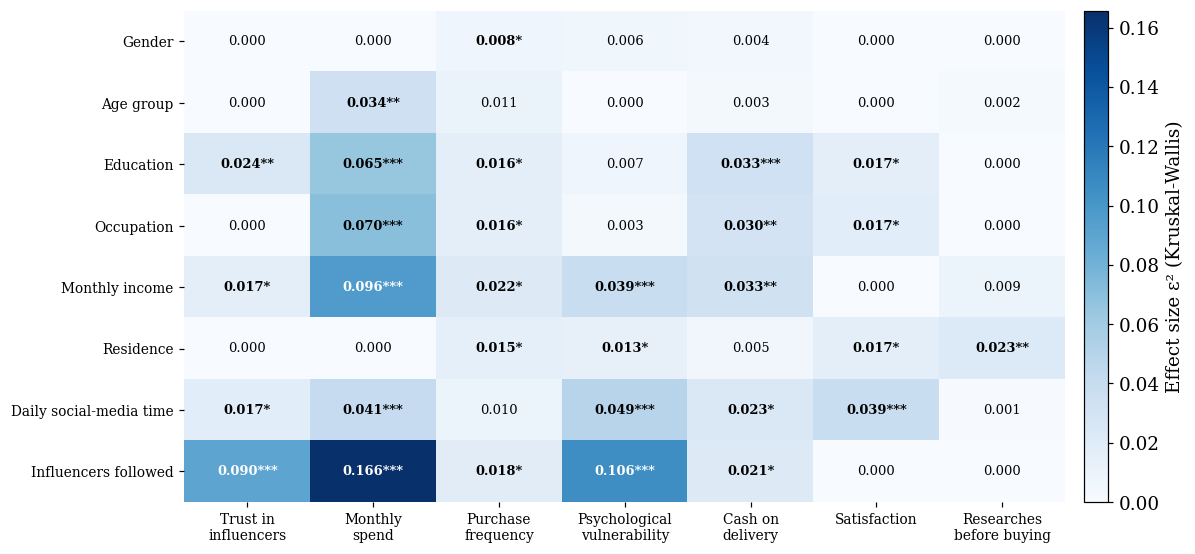


Table11_significant_group_means: Group means for the pairs that survive FDR correction (ordinal outcomes are on their 1-5/1-6 coding)


n  Mean (or % for COD)    SD
Grouping             Outcome                                       Group                                            
Influencers followed Monthly spend (Q15)                           None                52                 1.88  1.15
                                                                   1–5                143                 2.45  0.98
                                                                   6–15               162                 2.96  1.15
                                                                   16–30               90                 3.40  1.13
                                                                   More than 30        68                 3.57  1.29
...                                                                                   ...                  ...   ...
Residence            Psychological vulnerability (Section VI mean) Urban (city)       300                 3.31  0.65
                                                                   Semi-urban (town)  133                 3.20  0.65
                                                                   Rural               79                 3.13  0.55
Gender               Purchase frequency (Q13)                      Male               323                 2.69  0.92
                                                                   Female             192                 2.88  0.87

[125 rows x 3 columns]


--- Key facts ---
30 of 56 tests survive FDR < .05; largest effect sizes:
               Grouping                                       Outcome  epsilon2  q (FDR, all tests)
   Influencers followed                           Monthly spend (Q15)     0.166                 0.0
   Influencers followed Psychological vulnerability (Section VI mean)     0.106                 0.0
         Monthly income                           Monthly spend (Q15)     0.096                 0.0
   Influencers followed                    Trust in influencers (Q18)     0.090                 0.0
             Occupation                           Monthly spend (Q15)     0.070                 0.0
              Education                           Monthly spend (Q15)     0.065                 0.0
Daily social-media time Psychological vulnerability (Section VI mean)     0.049                 0.0
Daily social-media time                           Monthly spend (Q15)     0.041                 0.0
Median epsilon2 across al

In [10]:
# ============================================================
# CELL 9 — Group differences with multiplicity control (Table 10, Figure 7, Table 11)
# ============================================================
# ---------- 1. groupings and outcomes ----------
from scipy import stats as _st
from statsmodels.stats.multitest import multipletests

def collapse_edu(x):  return "Up to HSC" if x <= 3 else ("Bachelor's" if x == 4 else "Master's / PhD")
def collapse_occ(s):
    s = str(s)
    if "student" in s: return "Student"
    if s.startswith("Employed"): return "Employed"
    if s.startswith("Self"): return "Self-employed / freelancer"
    return "Unemployed / other"
clean["Edu3"] = clean["Edu"].map(collapse_edu); clean["Occ4"] = clean["Q4"].map(collapse_occ)
GROUPS = [  # label, column, ordered categories (None = alphabetical), is_ordered
 ("Gender", "Q2", ["Male", "Female"], False),
 ("Age group", "Q1", ORD["Q1"], True),
 ("Education", "Edu3", ["Up to HSC", "Bachelor's", "Master's / PhD"], True),
 ("Occupation", "Occ4", ["Student", "Employed", "Self-employed / freelancer", "Unemployed / other"], False),
 ("Monthly income", "Q5", ORD["Q5"], True),
 ("Residence", "Q6", ["Urban (city)", "Semi-urban (town)", "Rural"], False),
 ("Daily social-media time", "Q7", ORD["Q7"], True),
 ("Influencers followed", "Q11", ORD["Q11"], True),
]
OUTC = [("Trust in influencers (Q18)", "Trust18"), ("Monthly spend (Q15)", "Spend"), ("Purchase frequency (Q13)", "Buy"),
        ("Psychological vulnerability (Section VI mean)", "Vuln"), ("Pays cash on delivery", "COD"),
        ("Satisfaction (Q27)", "Satisf"), ("Researches before buying (Q17)", "Research")]

# ---------- 2. Kruskal-Wallis for every grouping x outcome; effect size epsilon^2 = (H - k + 1) / (n - k) ----------
rows = []
for gl, gc, cats, ordered in GROUPS:
    sub = clean[clean[gc].isin(cats)]
    for ol, oc in OUTC:
        samples = [sub.loc[sub[gc] == c, oc].values for c in cats]
        H, p = _st.kruskal(*samples); k = len(cats); n = len(sub)
        eps2 = max((H - k + 1) / (n - k), 0)
        rho = _st.spearmanr(sub[gc].map({c: i for i, c in enumerate(cats)}), sub[oc])[0] if ordered else np.nan
        rows.append({"Grouping": gl, "Outcome": ol, "oc": oc, "k": k, "n": n, "H": H, "p": p, "epsilon2": eps2, "Spearman rho (ordered groups)": rho})
T10 = pd.DataFrame(rows)
T10["q (FDR, all tests)"] = multipletests(T10["p"], method="fdr_bh")[1]
T10["sig"] = np.where(T10["q (FDR, all tests)"] < .001, "***", np.where(T10["q (FDR, all tests)"] < .01, "**", np.where(T10["q (FDR, all tests)"] < .05, "*", "")))
show = T10.drop(columns=["oc"]).copy()
for c in ["H", "epsilon2", "Spearman rho (ordered groups)"]: show[c] = show[c].round(3)
show["p"] = show["p"].map(lambda v: "<.001" if v < .001 else f"{v:.3f}")
show["q (FDR, all tests)"] = show["q (FDR, all tests)"].map(lambda v: "<.001" if v < .001 else f"{v:.3f}")
save_table(show.set_index(["Grouping", "Outcome"]), "Table10_group_differences",
           f"Kruskal-Wallis tests of {len(T10)} grouping x outcome pairs (cleaned sample); epsilon^2 = effect size; Benjamini-Hochberg FDR over all tests")

# ---------- 3. Figure 7: heatmap of effect sizes ----------
M = T10.pivot(index="Grouping", columns="Outcome", values="epsilon2").loc[[g[0] for g in GROUPS], [o[0] for o in OUTC]]
S = T10.pivot(index="Grouping", columns="Outcome", values="sig").loc[M.index, M.columns]
fig, ax = plt.subplots(figsize=(11, 5.2))
im = ax.imshow(M.values, cmap="Blues", vmin=0, vmax=max(.12, M.values.max()), aspect="auto")
XL = {"Trust in influencers (Q18)": "Trust in\ninfluencers", "Monthly spend (Q15)": "Monthly\nspend", "Purchase frequency (Q13)": "Purchase\nfrequency",
      "Psychological vulnerability (Section VI mean)": "Psychological\nvulnerability", "Pays cash on delivery": "Cash on\ndelivery",
      "Satisfaction (Q27)": "Satisfaction", "Researches before buying (Q17)": "Researches\nbefore buying"}
ax.set_xticks(range(M.shape[1])); ax.set_xticklabels([XL[c] for c in M.columns], fontsize=9)
ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=9)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.values[i, j]
        ax.text(j, i, f"{v:.3f}{S.values[i, j]}", ha="center", va="center", fontsize=8.5,
                color="white" if v > .07 else "black", fontweight="bold" if S.values[i, j] else "normal")
cb = fig.colorbar(im, ax=ax, fraction=.03, pad=.02); cb.set_label("Effect size ε² (Kruskal-Wallis)")
CAPTION = ("Figure 7. Effect sizes of group differences\n(bold with stars = FDR q < .05 *, < .01 **, < .001 ***)")
for s_ in ax.spines.values(): s_.set_visible(False)
fig.tight_layout(); save_fig(fig, "Fig7_group_difference_heatmap", CAPTION); plt.show()

# ---------- 4. Table 11: group means for the significant pairs ----------
sig_pairs = T10[T10["q (FDR, all tests)"] < .05].sort_values("epsilon2", ascending=False)
rows = []
for _, r in sig_pairs.iterrows():
    gl, gc, cats, _o = [g for g in GROUPS if g[0] == r.Grouping][0]
    for c in cats:
        s = clean.loc[clean[gc] == c, r.oc]
        rows.append({"Grouping": gl, "Outcome": r.Outcome, "Group": c, "n": len(s),
                     "Mean (or % for COD)": (s.mean() * 100 if r.oc == "COD" else s.mean()), "SD": (np.nan if r.oc == "COD" else s.std())})
T11 = pd.DataFrame(rows).round(2).set_index(["Grouping", "Outcome", "Group"])
save_table(T11, "Table11_significant_group_means", "Group means for the pairs that survive FDR correction (ordinal outcomes are on their 1-5/1-6 coding)")

print("\n--- Key facts ---")
print(f"{len(sig_pairs)} of {len(T10)} tests survive FDR < .05; largest effect sizes:")
print(sig_pairs[["Grouping", "Outcome", "epsilon2", "q (FDR, all tests)"]].head(8).round(3).to_string(index=False))
print(f"Median epsilon2 across all tests: {T10.epsilon2.median():.3f}  (0.01 small, 0.06 medium, 0.14 large)")

## Cell 10 — Correlations and collinearity
All pairwise Spearman correlations with FDR correction (pairs that overlap by construction are marked), a clustered heatmap, and variance inflation factors for the regressions that follow.
**Outputs:** Tables 12a–12c; Figure 8.

Cleaned sample n = 515; missing values per variable: 0 in total
136 unique pairs; 63 significant at FDR < .05; 51 at q < .001

Table12_spearman_matrix: Spearman correlations (lower triangle); stars = Benjamini-Hochberg FDR over 136 pairs: * q<.05, ** q<.01, *** q<.001; dagger = overlap by construction (shared survey items)


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
1. Age,1,,,,,,,,,,,,,,,,
2. Female,-.08,1,,,,,,,,,,,,,,,
3. Education,.39***,-.01,1,,,,,,,,,,,,,,
4. Income,.59***,-.16***,.45***,1,,,,,,,,,,,,,
5. Daily SM hours,-.14**,.09,.00,-.10,1,,,,,,,,,,,,
6. Influencers followed,-.08,.09,.02,.03,.38***,1,,,,,,,,,,,
7. Trust (Q18),.02,.05,.10,.01,.15**,.29***,1,,,,,,,,,,
8. Likert trust item,.06,-.03,-.01,.12*,.10,.18***,.18***,1,,,,,,,,,
9. Vulnerability,-.01,.09,-.07,-.09,.21***,.32***,.21***,.35***,1,,,,,,,,
10. Social influence,.03,.05,-.07,.03,.20***,.32***,.16***,.54***†,.84***†,1,,,,,,,



Table12b_all_pairs_ranked: All 136 Spearman correlations, ranked by absolute size


,Variable 1,Variable 2,n,rho,p,q (FDR),Overlap by construction
0,Vulnerability,Social influence,515,0.844,<.001,<.001,yes
1,Vulnerability,Ad usefulness,515,0.607,<.001,<.001,yes
2,Age,Income,515,0.592,<.001,<.001,
3,Likert trust item,Social influence,515,0.544,<.001,<.001,yes
4,Researches,Safeguard index,515,0.473,<.001,<.001,yes
...,...,...,...,...,...,...,...
131,Trust (Q18),Researches,515,0.008,0.863,0.889,
132,Social influence,Researches,515,-0.007,0.883,0.903,
133,Income,Trust (Q18),515,0.005,0.909,0.923,
134,Female,Monthly spend,515,-0.004,0.935,0.942,


saved figure: Fig8_correlation_heatmap
  suggested caption: Figure 8. Spearman correlations among the study variables (n = 515) Variables ordered by hierarchical clustering; bold = FDR q < .05, grey = not significant; † = overlap by construction (shared items)


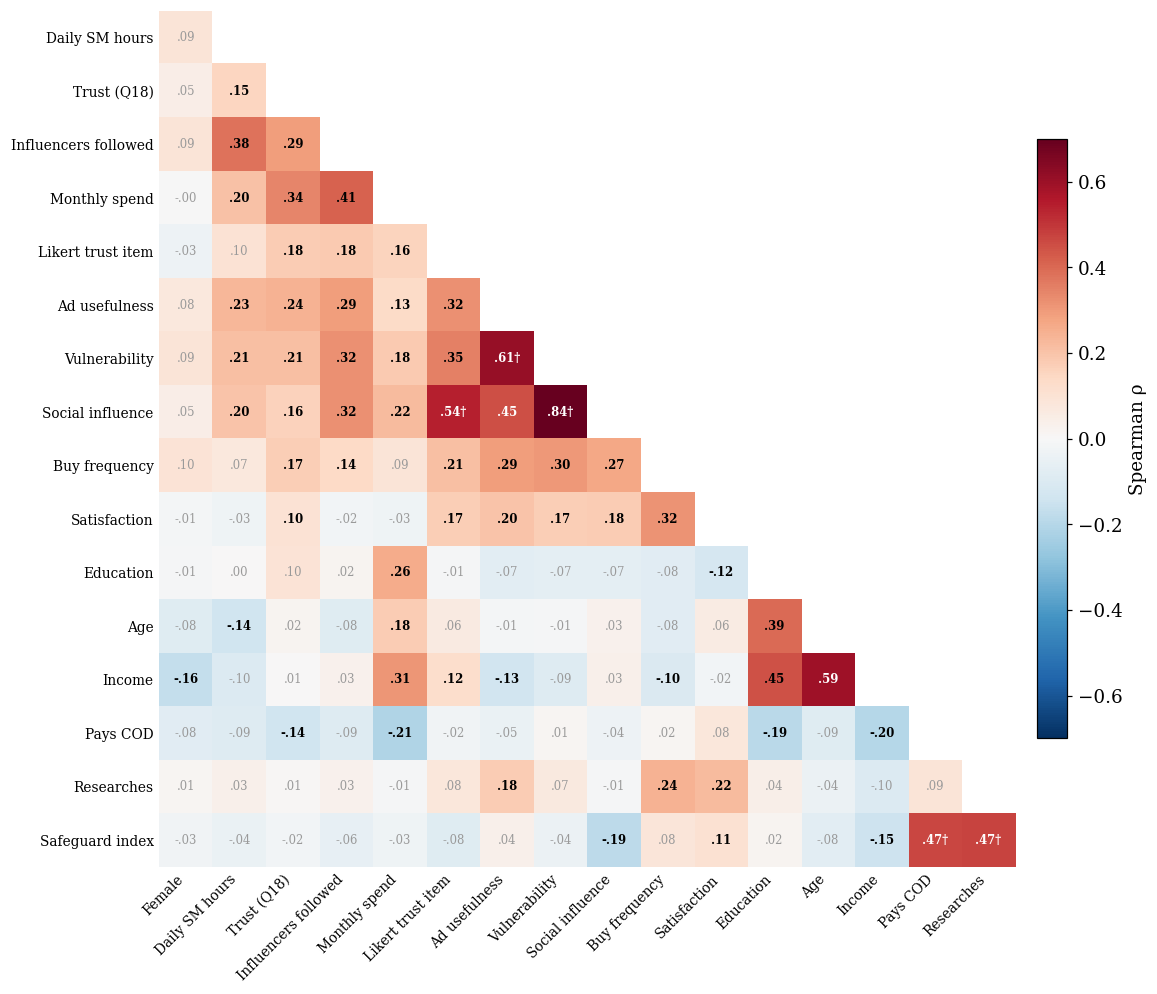


Table12c_VIF: Variance inflation factors for the planned regression predictors (model sample, n = 512); all well below 5


,VIF
Predictor,
z_Trust,1.14
z_Vuln,1.23
z_SG,1.07
z_Income,1.68
z_Edu,1.22
z_Age,1.51
z_NFollow,1.39
z_SMhrs,1.24
Female,1.05



--- Key facts ---
Ten strongest correlations (marked where they overlap by construction):
          Variable 1       Variable 2   rho q (FDR) Overlap by construction
       Vulnerability Social influence 0.844   <.001                     yes
       Vulnerability    Ad usefulness 0.607   <.001                     yes
                 Age           Income 0.592   <.001                        
   Likert trust item Social influence 0.544   <.001                     yes
          Researches  Safeguard index 0.473   <.001                     yes
            Pays COD  Safeguard index 0.466   <.001                     yes
    Social influence    Ad usefulness 0.451   <.001                        
           Education           Income 0.447   <.001                        
Influencers followed    Monthly spend 0.411   <.001                        
                 Age        Education 0.394   <.001                        

Strongest substantive (non-overlapping) correlations:
          Variable

In [11]:
# ============================================================
# CELL 10 — Correlation matrix (Table 12, Figure 8) + collinearity check before the regressions
# ============================================================
from scipy import stats as _st
from statsmodels.stats.multitest import multipletests
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# ---------- 1. variables (label, column, block) ----------
CV = [("Age", "Age", "Respondent"), ("Female", "Female", "Respondent"), ("Education", "Edu", "Respondent"),
      ("Income", "Income", "Respondent"), ("Daily SM hours", "SMhrs", "Exposure"), ("Influencers followed", "NFollow", "Exposure"),
      ("Trust (Q18)", "Trust18", "Trust and attitudes"), ("Likert trust item", "trust_infl", "Trust and attitudes"),
      ("Vulnerability", "Vuln", "Trust and attitudes"), ("Social influence", "SocInfl", "Trust and attitudes"),
      ("Ad usefulness", "AdUseful", "Trust and attitudes"),
      ("Buy frequency", "Buy", "Behaviour"), ("Monthly spend", "Spend", "Behaviour"), ("Researches", "Research", "Behaviour"),
      ("Pays COD", "COD", "Behaviour"), ("Safeguard index", "SG", "Behaviour"), ("Satisfaction", "Satisf", "Behaviour")]
LAB = [c[0] for c in CV]; COL = [c[1] for c in CV]
D = clean[COL].astype(float).copy(); D.columns = LAB
# pairs that overlap BY CONSTRUCTION (shared survey items or a component of an index) - their correlation is partly mechanical
ITEMS = {"Vulnerability": set(SC["Vuln"]), "Social influence": set(SC["SocInfl"]), "Ad usefulness": set(SC["AdUseful"]), "Likert trust item": {"trust_infl"}}
MECH = {frozenset(("Safeguard index", "Pays COD")), frozenset(("Safeguard index", "Researches"))}
# True when two variables share items or are linked by construction (their correlation is not interpreted)
def overlaps(a, b):
    return (a in ITEMS and b in ITEMS and bool(ITEMS[a] & ITEMS[b])) or frozenset((a, b)) in MECH
print(f"Cleaned sample n = {len(D)}; missing values per variable: {int(D.isna().sum().sum())} in total")

# ---------- 2. Spearman matrix with pairwise p-values and FDR over the unique pairs ----------
k = len(LAB); R = np.eye(k); P = np.zeros((k, k)); NN = np.zeros((k, k), int); pairs = []
for i in range(k):
    for j in range(i + 1, k):
        ok = D.iloc[:, [i, j]].dropna()
        r, p = _st.spearmanr(ok.iloc[:, 0], ok.iloc[:, 1])
        R[i, j] = R[j, i] = r; P[i, j] = P[j, i] = p; NN[i, j] = NN[j, i] = len(ok)
        pairs.append((i, j, r, p, len(ok)))
qv = multipletests([x[3] for x in pairs], method="fdr_bh")[1]
Q = np.zeros((k, k))
for (i, j, *_), q in zip(pairs, qv): Q[i, j] = Q[j, i] = q
print(f"{len(pairs)} unique pairs; {int((qv < .05).sum())} significant at FDR < .05; {int((qv < .001).sum())} at q < .001")

def stars(q): return "***" if q < .001 else ("**" if q < .01 else ("*" if q < .05 else ""))
M12 = pd.DataFrame("", index=LAB, columns=LAB)
for i in range(k):
    for j in range(k):
        if i == j: M12.iloc[i, j] = "1"
        elif i > j: M12.iloc[i, j] = (f"{R[i, j]:.2f}{stars(Q[i, j])}" + ("†" if overlaps(LAB[i], LAB[j]) else "")).replace("0.", ".")
M12.index = [f"{n+1}. {l}" for n, l in enumerate(LAB)]; M12.columns = [str(n + 1) for n in range(k)]
save_table(M12, "Table12_spearman_matrix", "Spearman correlations (lower triangle); stars = Benjamini-Hochberg FDR over 136 pairs: * q<.05, ** q<.01, *** q<.001; dagger = overlap by construction (shared survey items)")

L12 = pd.DataFrame([{"Variable 1": LAB[i], "Variable 2": LAB[j], "n": n, "rho": r, "p": p, "q (FDR)": Q[i, j]} for i, j, r, p, n in pairs])
L12["Overlap by construction"] = [("yes" if overlaps(a, b) else "") for a, b in zip(L12["Variable 1"], L12["Variable 2"])]
L12["|rho|"] = L12["rho"].abs(); L12 = L12.sort_values("|rho|", ascending=False).drop(columns="|rho|").reset_index(drop=True)
Lshow = L12.copy(); Lshow["rho"] = Lshow["rho"].round(3)
Lshow["p"] = Lshow["p"].map(lambda v: "<.001" if v < .001 else f"{v:.3f}"); Lshow["q (FDR)"] = Lshow["q (FDR)"].map(lambda v: "<.001" if v < .001 else f"{v:.3f}")
save_table(Lshow, "Table12b_all_pairs_ranked", "All 136 Spearman correlations, ranked by absolute size")

# ---------- 3. Figure 8: clustered heatmap (lower triangle) ----------
dist = squareform(1 - np.abs(R), checks=False); order = leaves_list(linkage(dist, method="average"))
Ro = R[np.ix_(order, order)]; Qo = Q[np.ix_(order, order)]; Lo = [LAB[i] for i in order]
mask = np.triu(np.ones_like(Ro, bool), k=0)
fig, ax = plt.subplots(figsize=(11.2, 9.2))
Z = np.ma.array(Ro, mask=mask)
im = ax.imshow(Z, cmap="RdBu_r", vmin=-.7, vmax=.7)
for i in range(k):
    for j in range(i):
        sig = Qo[i, j] < .05
        ax.text(j, i, f"{Ro[i, j]:.2f}".replace("0.", ".").replace("-.", "-.") + ("†" if overlaps(Lo[i], Lo[j]) else ""), ha="center", va="center", fontsize=7.6,
                fontweight="bold" if sig else "normal", color=("white" if abs(Ro[i, j]) > .45 else ("black" if sig else "#9a9a9a")))
ax.set_xticks(range(k)); ax.set_xticklabels(Lo, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(k)); ax.set_yticklabels(Lo, fontsize=9)
ax.set_xlim(-.5, k - 1.5); ax.set_ylim(k - .5, .5)
for s_ in ax.spines.values(): s_.set_visible(False)
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=.032, pad=.02, shrink=.7); cb.set_label("Spearman ρ")
CAPTION = (f"Figure 8. Spearman correlations among the study variables (n = {len(D)})\n"
             "Variables ordered by hierarchical clustering; bold = FDR q < .05, grey = not significant; † = overlap by construction (shared items)")
fig.tight_layout(); save_fig(fig, "Fig8_correlation_heatmap", CAPTION); plt.show()

# ---------- 4. collinearity check for the regressions that follow (model sample) ----------
for dfx in (model,):
    for v, c in [("z_Trust", "Trust18"), ("z_Vuln", "Vuln"), ("z_SG", "SG"), ("z_Income", "Income"), ("z_Edu", "Edu"), ("z_Age", "Age"),
                 ("z_NFollow", "NFollow"), ("z_SMhrs", "SMhrs")]:
        dfx[v] = (dfx[c] - dfx[c].mean()) / dfx[c].std()
X = model[["z_Trust", "z_Vuln", "z_SG", "z_Income", "z_Edu", "z_Age", "z_NFollow", "z_SMhrs", "Female", "Urban", "Rural"]].astype(float).dropna()
Xc = sm.add_constant(X)
VIF = pd.DataFrame({"Predictor": X.columns, "VIF": [variance_inflation_factor(Xc.values, i + 1) for i in range(X.shape[1])]}).round(2).set_index("Predictor")
save_table(VIF, "Table12c_VIF", f"Variance inflation factors for the planned regression predictors (model sample, n = {len(X)}); all well below 5")

# ---------- 5. key facts ----------
def rr(a, b):
    i, j = LAB.index(a), LAB.index(b); return f"rho = {R[i, j]:+.2f}, q = {Q[i, j]:.3f}" if Q[i, j] >= .001 else f"rho = {R[i, j]:+.2f}, q < .001"
print("\n--- Key facts ---")
print("Ten strongest correlations (marked where they overlap by construction):")
print(Lshow.head(10)[["Variable 1", "Variable 2", "rho", "q (FDR)", "Overlap by construction"]].to_string(index=False))
nm = Lshow[Lshow["Overlap by construction"] == ""]
print("\nStrongest substantive (non-overlapping) correlations:")
print(nm.head(8)[["Variable 1", "Variable 2", "rho", "q (FDR)"]].to_string(index=False))
print(f"\nPairs that overlap by construction: {int((Lshow['Overlap by construction'] == 'yes').sum())}; excluded from interpretation")
print("\nTrust (Q18) with:")
for b in ["Monthly spend", "Buy frequency", "Pays COD", "Researches", "Safeguard index", "Satisfaction", "Vulnerability", "Influencers followed", "Income", "Likert trust item"]:
    print(f"  {b:<22s} {rr('Trust (Q18)', b)}")
print(f"\nMax VIF = {VIF.VIF.max():.2f}  (predictors: {', '.join(VIF.index[VIF.VIF > 2.5]) or 'none above 2.5'})")

## Cell 11 — Core models: does trust gate participation or throttle intensity?
Logit and ordered-logit models of six binary and two ordinal outcomes across M0–M3, OLS checks, tests for non-linearity, forest plot and model-predicted probabilities by trust level (g-computation).
**Outputs:** Tables 13a–13d; Figures 9 and 10.

Model sample n = 512; trust mean = 2.46, SD = 1.09  (every OR below is per +1 SD of trust)

Table13a_trust_core_models: Odds ratio for +1 SD of trust (Q18), model sample n = 512; robust (HC1) SEs for logit; stars = BH-FDR q over the 8 outcomes within each specification: * <.05, ** <.01, *** <.001


Spec,Model,M0 unadjusted,M1 + demographics,M2 + exposure (main),M3 + vulnerability
Outcome,,,,,
Ever bought via social media,Logit,"1.20 [0.82, 1.77] ns","1.18 [0.81, 1.73] ns","1.16 [0.77, 1.76] ns","1.11 [0.72, 1.70] ns"
Any monthly spend,Logit,"3.09 [2.25, 4.25]***","3.10 [2.25, 4.27]***","2.59 [1.84, 3.66]***","2.55 [1.80, 3.62]***"
Spends ≥ BDT 500,Logit,"1.89 [1.55, 2.31]***","1.95 [1.58, 2.40]***","1.68 [1.34, 2.11]***","1.66 [1.32, 2.08]***"
"Spends > BDT 2,000",Logit,"1.67 [1.35, 2.06]***","1.95 [1.53, 2.48]***","1.64 [1.28, 2.09]***","1.59 [1.24, 2.05]***"
"Spends > BDT 5,000",Logit,"1.85 [1.35, 2.54]***","1.94 [1.41, 2.66]***","1.64 [1.18, 2.27]**","1.57 [1.13, 2.18]**"
Buys frequently,Logit,"1.30 [1.04, 1.63]*","1.37 [1.09, 1.73]**","1.32 [1.06, 1.65]*","1.23 [0.99, 1.54] ns"
"Spend level (ordered, 6 levels)",Ordered logit,"1.96 [1.66, 2.32]***","1.99 [1.68, 2.36]***","1.68 [1.41, 2.00]***","1.64 [1.38, 1.95]***"
"Purchase frequency (ordered, 4 levels)",Ordered logit,"1.40 [1.18, 1.66]***","1.42 [1.20, 1.69]***","1.36 [1.14, 1.62]**","1.29 [1.07, 1.54]**"



Table13a_trust_core_models_numeric: Same models, numeric (OR, 95% CI, raw p, FDR q)


oc         Family  Effect      lo      hi       p    n  events               Model  q (FDR over outcomes)
Outcome                                Spec                                                                                                                                  
Ever bought via social media           M0 unadjusted             P_buy  Participation  1.2033  0.8183  1.7694  0.3469  512   469.0          Logit (OR)                 0.3469
                                       M1 + demographics         P_buy  Participation  1.1847  0.8099  1.7330  0.3825  512   469.0          Logit (OR)                 0.3825
                                       M2 + exposure (main)      P_buy  Participation  1.1639  0.7681  1.7636  0.4741  512   469.0          Logit (OR)                 0.4741
                                       M3 + vulnerability        P_buy  Participation  1.1094  0.7248  1.6981  0.6327  512   469.0          Logit (OR)                 0.6327
Any monthly spend                      M0 unadjusted           P_spend  Participation  3.0897  2.2461  4.2501  0.0000  512   431.0          Logit (OR)                 0.0000
                                       M1 + demographics       P_spend  Participation  3.1014  2.2537  4.2678  0.0000  512   431.0          Logit (OR)                 0.0000
                                       M2 + exposure (main)    P_spend  Participation  2.5922  1.8364  3.6590  0.0000  512   431.0          Logit (OR)                 0.0000
                                       M3 + vulnerability      P_spend  Participation  2.5548  1.8022  3.6218  0.0000  512   431.0          Logit (OR)                 0.0000
Spends ≥ BDT 500                       M0 unadjusted          Spend500      Intensity  1.8898  1.5472  2.3082  0.0000  512   316.0          Logit (OR)                 0.0000
                                       M1 + demographics      Spend500      Intensity  1.9478  1.5831  2.3966  0.0000  512   316.0          Logit (OR)                 0.0000
                                       M2 + exposure (main)   Spend500      Intensity  1.6828  1.3435  2.1079  0.0000  512   316.0          Logit (OR)                 0.0000
                                       M3 + vulnerability     Spend500      Intensity  1.6609  1.3249  2.0820  0.0000  512   316.0          Logit (OR)                 0.0000
Spends > BDT 2,000                     M0 unadjusted         Spend2000      Intensity  1.6666  1.3508  2.0562  0.0000  512   148.0          Logit (OR)                 0.0000
                                       M1 + demographics     Spend2000      Intensity  1.9495  1.5322  2.4805  0.0000  512   148.0          Logit (OR)                 0.0000
                                       M2 + exposure (main)  Spend2000      Intensity  1.6351  1.2771  2.0936  0.0001  512   148.0          Logit (OR)                 0.0002
                                       M3 + vulnerability    Spend2000      Intensity  1.5942  1.2411  2.0478  0.0003  512   148.0          Logit (OR)                 0.0005
Spends > BDT 5,000                     M0 unadjusted         Spend5000      Intensity  1.8497  1.3486  2.5371  0.0001  512    53.0          Logit (OR)                 0.0002
                                       M1 + demographics     Spend5000      Intensity  1.9390  1.4111  2.6644  0.0000  512    53.0          Logit (OR)                 0.0001
                                       M2 + exposure (main)  Spend5000      Intensity  1.6363  1.1788  2.2712  0.0032  512    53.0          Logit (OR)                 0.0043
                                       M3 + vulnerability    Spend5000      Intensity  1.5729  1.1328  2.1839  0.0068  512    53.0          Logit (OR)                 0.0091
Buys frequently                        M0 unadjusted           FreqBuy      Intensity  1.2980  1.0351  1.6276  0.0239  512   118.0          Logit (OR)                 0.0273
                                       M1 + demographics       Fre


Table13b_ols_robustness: OLS with HC3 robust SEs on the numeric 1-6 / 1-4 codings (robustness check of the ordered-logit results)


b per +1 SD trust        95% CI  std. beta      p     R2
Outcome            Spec                                                                          
Spend level        M0 unadjusted                     0.427  [0.32, 0.53]      0.348  <.001  0.121
                   M1 + demographics                 0.423  [0.32, 0.52]      0.344  <.001  0.226
                   M2 + exposure (main)              0.293  [0.20, 0.39]      0.239  <.001  0.328
                   M3 + vulnerability                0.280  [0.18, 0.38]      0.228  <.001  0.334
Purchase frequency M0 unadjusted                     0.142  [0.05, 0.23]      0.158  0.002  0.025
                   M1 + demographics                 0.151  [0.06, 0.24]      0.167  <.001  0.071
                   M2 + exposure (main)              0.130  [0.04, 0.22]      0.144  0.005  0.076
                   M3 + vulnerability                0.098  [0.01, 0.19]      0.109  0.029  0.137


Table13c_nonlinearity: Quadratic trust term added to the main logit models (M2): tests whether the trust-outcome curve bends


,linear term OR,quadratic term b,p (quadratic),shape
Outcome,,,,
Ever bought via social media,1.277,-0.336,0.009,concave (flattens or turns down at high trust)
Any monthly spend,2.567,-0.017,0.923,no clear curvature
Spends ≥ BDT 500,1.682,0.027,0.793,no clear curvature
"Spends > BDT 2,000",1.599,0.051,0.649,no clear curvature
"Spends > BDT 5,000",1.548,0.079,0.570,no clear curvature
Buys frequently,1.162,0.339,<.001,convex (accelerates at high trust)


saved figure: Fig9_trust_forest
  suggested caption: Figure 9. Trust and purchasing: participation versus intensity (n = 512) Odds ratios per +1 SD of trust (Q18); robust 95% CIs


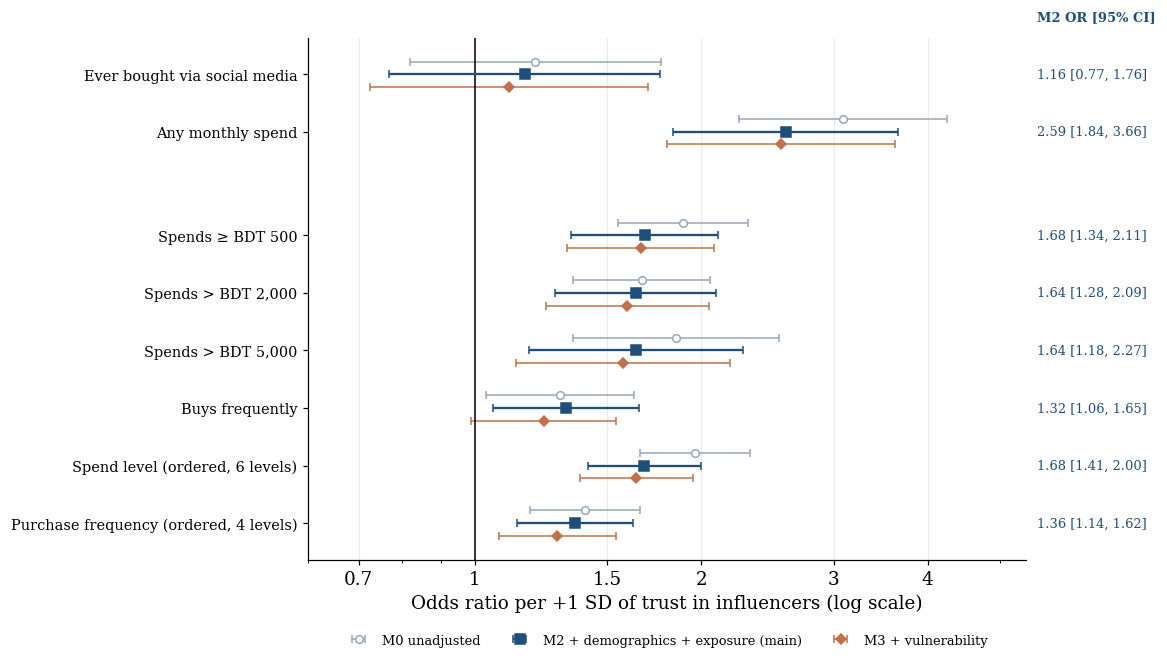

saved figure: Fig10_predicted_probabilities
  suggested caption: Figure 10. Predicted probabilities by trust level (M2: adjusted for demographics and exposure; n = 512) Average marginal predictions; bands = 95% simulation intervals


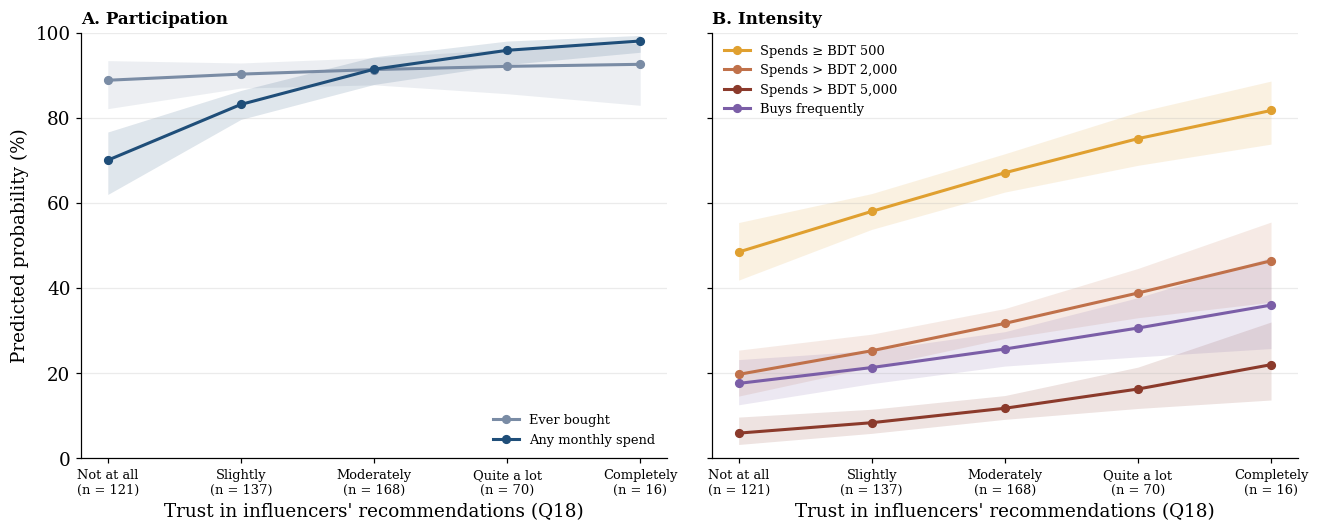


Table13d_predicted_probabilities: Model-predicted % [95% interval] by trust level (M2), averaged over the sample's covariates


,Ever bought,Any monthly spend,Spends ≥ BDT 500,"Spends > BDT 2,000","Spends > BDT 5,000",Buys frequently
Trust level 1,"88.8 [82.2, 93.5]","70.0 [62.0, 76.7]","48.5 [41.9, 55.4]","19.7 [14.6, 25.4]","5.9 [3.2, 9.7]","17.6 [12.6, 23.2]"
Trust level 2,"90.3 [87.0, 92.9]","83.2 [79.6, 86.4]","58.0 [53.8, 62.2]","25.3 [21.4, 29.2]","8.3 [5.8, 11.5]","21.3 [17.5, 25.3]"
Trust level 3,"91.3 [87.8, 94.2]","91.4 [87.9, 94.3]","67.1 [62.6, 71.6]","31.7 [28.1, 35.2]","11.7 [9.1, 14.7]","25.7 [21.7, 29.7]"
Trust level 4,"92.1 [85.7, 96.1]","95.9 [92.5, 98.0]","75.1 [68.8, 81.4]","38.8 [33.0, 44.6]","16.3 [11.7, 21.4]","30.6 [23.8, 37.7]"
Trust level 5,"92.6 [82.9, 97.6]","98.1 [95.4, 99.4]","81.7 [73.8, 88.6]","46.4 [36.7, 55.5]","22.0 [13.7, 32.0]","36.0 [25.8, 47.2]"



--- Key facts (OR per +1 SD of trust) ---
Ever bought via social media             M0: OR 1.20 [0.82, 1.77]   | M2: OR 1.16 [0.77, 1.76], p = 0.474, q = 0.474
Any monthly spend                        M0: OR 3.09 [2.25, 4.25]   | M2: OR 2.59 [1.84, 3.66], p = 6.08e-08, q = 2.43e-07
Spends ≥ BDT 500                         M0: OR 1.89 [1.55, 2.31]   | M2: OR 1.68 [1.34, 2.11], p = 5.91e-06, q = 1.58e-05
Spends > BDT 2,000                       M0: OR 1.67 [1.35, 2.06]   | M2: OR 1.64 [1.28, 2.09], p = 9.65e-05, q = 0.000193
Spends > BDT 5,000                       M0: OR 1.85 [1.35, 2.54]   | M2: OR 1.64 [1.18, 2.27], p = 0.00325, q = 0.00433
Buys frequently                          M0: OR 1.30 [1.04, 1.63]   | M2: OR 1.32 [1.06, 1.65], p = 0.0151, q = 0.0172
Spend level (ordered, 6 levels)          M0: OR 1.96 [1.66, 2.32]   | M2: OR 1.68 [1.41, 2.00], p = 3.61e-09, q = 2.89e-08
Purchase frequency (ordered, 4 levels)   M0: OR 1.40 [1.18, 1.66]   | M2: OR 1.36 [1.14, 1.62], p = 0.000783

In [12]:
# ============================================================
# CELL 11 — Core models: does trust gate participation, or throttle intensity?  (Tables 13a-c, Figures 9-10)
# ============================================================
import statsmodels.formula.api as smf
from statsmodels.miscmodels.ordinal_model import OrderedModel
from scipy.special import expit
from scipy import stats as _st
from statsmodels.stats.multitest import multipletests

# ---------- 0. z-scores (re-created here so the cell is self-contained) and extra outcomes ----------
for v, c in [("z_Trust", "Trust18"), ("z_Vuln", "Vuln"), ("z_SG", "SG"), ("z_Income", "Income"), ("z_Edu", "Edu"),
             ("z_Age", "Age"), ("z_NFollow", "NFollow"), ("z_SMhrs", "SMhrs")]:
    model[v] = (model[c] - model[c].mean()) / model[c].std()
model["Spend5000"] = (model["Spend"] >= 5).astype(int)           # more than BDT 5,000 a month
N_M = len(model); SD_T = model["Trust18"].std(); MU_T = model["Trust18"].mean()
print(f"Model sample n = {N_M}; trust mean = {MU_T:.2f}, SD = {SD_T:.2f}  (every OR below is per +1 SD of trust)")

DEM = "Female + Urban + Rural + z_Income + z_Edu + z_Age"
SPECS = {"M0 unadjusted": "z_Trust",
         "M1 + demographics": f"z_Trust + {DEM}",
         "M2 + exposure (main)": f"z_Trust + {DEM} + z_NFollow + z_SMhrs",
         "M3 + vulnerability": f"z_Trust + {DEM} + z_NFollow + z_SMhrs + z_Vuln"}
MAIN = "M2 + exposure (main)"
BIN = [("Ever bought via social media", "P_buy", "Participation"), ("Any monthly spend", "P_spend", "Participation"),
       ("Spends ≥ BDT 500", "Spend500", "Intensity"), ("Spends > BDT 2,000", "Spend2000", "Intensity"),
       ("Spends > BDT 5,000", "Spend5000", "Intensity"), ("Buys frequently", "FreqBuy", "Intensity")]
ORDV = [("Spend level (ordered, 6 levels)", "Spend", "Intensity"), ("Purchase frequency (ordered, 4 levels)", "Buy", "Intensity")]

# ---------- 1. fit everything ----------
rows, FITS = [], {}
# appends one model result (effect, 95% CI, p, n) to the results list
def add_row(lab, oc, fam, spec, eff, lo, hi, p, n, ev, kind):
    rows.append({"Outcome": lab, "oc": oc, "Family": fam, "Spec": spec, "Effect": eff, "lo": lo, "hi": hi, "p": p, "n": n, "events": ev, "Model": kind})

for lab, oc, fam in BIN:
    for sp, rhs in SPECS.items():
        m = smf.logit(f"{oc} ~ {rhs}", data=model).fit(disp=0, cov_type="HC1"); FITS[(oc, sp)] = m
        ci = m.conf_int().loc["z_Trust"]
        add_row(lab, oc, fam, sp, np.exp(m.params["z_Trust"]), np.exp(ci[0]), np.exp(ci[1]), m.pvalues["z_Trust"], int(m.nobs), int(model[oc].sum()), "Logit (OR)")
for lab, oc, fam in ORDV:
    for sp, rhs in SPECS.items():
        m = OrderedModel.from_formula(f"{oc} ~ 0 + {rhs}", data=model, distr="logit").fit(method="bfgs", disp=0, maxiter=1000); FITS[(oc, sp)] = m
        ci = m.conf_int().loc["z_Trust"]
        add_row(lab, oc, fam, sp, np.exp(m.params["z_Trust"]), np.exp(ci[0]), np.exp(ci[1]), m.pvalues["z_Trust"], int(m.nobs), np.nan, "Ordered logit (OR)")
R13 = pd.DataFrame(rows)

# FDR across the 8 outcomes, separately for each specification
R13["q (FDR over outcomes)"] = np.nan
for sp in SPECS:
    idx = R13.index[R13.Spec == sp]; R13.loc[idx, "q (FDR over outcomes)"] = multipletests(R13.loc[idx, "p"], method="fdr_bh")[1]

# formats an odds ratio with its 95% CI and FDR stars
def fmt(r):
    s = "***" if r["q (FDR over outcomes)"] < .001 else "**" if r["q (FDR over outcomes)"] < .01 else "*" if r["q (FDR over outcomes)"] < .05 else " ns"
    return f"{r.Effect:.2f} [{r.lo:.2f}, {r.hi:.2f}]{s}"
R13["cell"] = R13.apply(fmt, axis=1)
T13 = R13.pivot(index="Outcome", columns="Spec", values="cell").loc[[b[0] for b in BIN] + [o[0] for o in ORDV], list(SPECS)]
T13.insert(0, "Model", ["Logit"] * len(BIN) + ["Ordered logit"] * len(ORDV))
save_table(T13, "Table13a_trust_core_models",
           f"Odds ratio for +1 SD of trust (Q18), model sample n = {N_M}; robust (HC1) SEs for logit; stars = BH-FDR q over the 8 outcomes within each specification: * <.05, ** <.01, *** <.001")
raw13 = R13.drop(columns=["cell"]).round(4)
save_table(raw13.set_index(["Outcome", "Spec"]), "Table13a_trust_core_models_numeric", "Same models, numeric (OR, 95% CI, raw p, FDR q)")

# ---------- 2. OLS (HC3) on the numeric outcomes as a robustness check ----------
rows = []
for lab, oc in [("Spend level", "Spend"), ("Purchase frequency", "Buy")]:
    for sp, rhs in SPECS.items():
        m = smf.ols(f"{oc} ~ {rhs}", data=model).fit(cov_type="HC3"); ci = m.conf_int().loc["z_Trust"]; sdy = model[oc].std()
        rows.append({"Outcome": lab, "Spec": sp, "b per +1 SD trust": m.params["z_Trust"], "95% CI": f"[{ci[0]:.2f}, {ci[1]:.2f}]",
                     "std. beta": m.params["z_Trust"] / sdy, "p": m.pvalues["z_Trust"], "R2": m.rsquared})
T13b = pd.DataFrame(rows); T13b["p"] = T13b["p"].map(lambda v: "<.001" if v < .001 else f"{v:.3f}")
save_table(T13b.round(3).set_index(["Outcome", "Spec"]), "Table13b_ols_robustness", "OLS with HC3 robust SEs on the numeric 1-6 / 1-4 codings (robustness check of the ordered-logit results)")

# ---------- 3. non-linearity: is trust's relation to spending steeper at the low end? ----------
rows = []
for lab, oc, fam in BIN:
    m2 = smf.logit(f"{oc} ~ {SPECS[MAIN]} + I(z_Trust**2)", data=model).fit(disp=0, cov_type="HC1")
    b2 = m2.params["I(z_Trust ** 2)"]; p2 = m2.pvalues["I(z_Trust ** 2)"]
    rows.append({"Outcome": lab, "linear term OR": np.exp(m2.params["z_Trust"]), "quadratic term b": b2, "p (quadratic)": p2,
                 "shape": ("concave (flattens or turns down at high trust)" if b2 < 0 else "convex (accelerates at high trust)") if p2 < .05 else "no clear curvature"})
T13c = pd.DataFrame(rows); T13c["p (quadratic)"] = T13c["p (quadratic)"].map(lambda v: "<.001" if v < .001 else f"{v:.3f}")
save_table(T13c.round(3).set_index("Outcome"), "Table13c_nonlinearity", "Quadratic trust term added to the main logit models (M2): tests whether the trust-outcome curve bends")

# ---------- 4. Figure 9: forest plot ----------
labels = [b[0] for b in BIN] + [o[0] for o in ORDV]; fams = [b[2] for b in BIN] + [o[2] for o in ORDV]
ypos = {}; y = 0; prev = None
for l, f in zip(labels, fams):
    if prev is not None and f != prev: y += .8
    ypos[l] = y; y += 1; prev = f
fig, ax = plt.subplots(figsize=(10.8, 6.2))
STYLE = {"M0 unadjusted": ("#9aa7b8", "o", -.22, "M0 unadjusted"), MAIN: ("#1f4e79", "s", 0, "M2 + demographics + exposure (main)"),
         "M3 + vulnerability": ("#c0714a", "D", .22, "M3 + vulnerability")}
for sp, (col, mk, off, lg) in STYLE.items():
    d = R13[R13.Spec == sp].set_index("Outcome").loc[labels]
    yy = np.array([ypos[l] for l in labels]) + off
    ax.errorbar(d.Effect, yy, xerr=[d.Effect - d.lo, d.hi - d.Effect], fmt=mk, color=col, ms=6.5 if sp == MAIN else 5, mfc=("white" if sp == "M0 unadjusted" else col),
                capsize=2.5, lw=1.5 if sp == MAIN else 1, label=lg, zorder=3 if sp == MAIN else 2)
dm = R13[R13.Spec == MAIN].set_index("Outcome").loc[labels]
for l in labels:
    ax.text(5.6, ypos[l], f"{dm.loc[l, 'Effect']:.2f} [{dm.loc[l, 'lo']:.2f}, {dm.loc[l, 'hi']:.2f}]", va="center", fontsize=8.5, color="#1f4e79")
ax.text(5.6, -1.0, "M2 OR [95% CI]", fontsize=8.5, color="#1f4e79", fontweight="bold", va="center")
ax.axvline(1, color="black", lw=1); ax.set_xscale("log"); ax.set_xlim(.6, 5.4)
ax.set_xticks([.7, 1, 1.5, 2, 3, 4]); ax.set_xticklabels(["0.7", "1", "1.5", "2", "3", "4"])
ax.set_yticks([ypos[l] for l in labels]); ax.set_yticklabels(labels, fontsize=9.5); ax.invert_yaxis()
ax.set_xlabel("Odds ratio per +1 SD of trust in influencers (log scale)")
ax.grid(axis="x", alpha=.25)
from matplotlib.ticker import NullFormatter
ax.xaxis.set_minor_formatter(NullFormatter())
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=8.5, frameon=False)
CAPTION = (f"Figure 9. Trust and purchasing: participation versus intensity (n = {N_M})\nOdds ratios per +1 SD of trust (Q18); robust 95% CIs")
fig.tight_layout(); save_fig(fig, "Fig9_trust_forest", CAPTION); plt.show()

# ---------- 5. Figure 10: model-predicted probabilities by trust level (g-computation from M2, parametric simulation CIs) ----------
rng = np.random.default_rng(2026)
def predicted(oc, nsim=2000):
    m = FITS[(oc, MAIN)]; beta = rng.multivariate_normal(m.params.values, m.cov_params().values, size=nsim)
    out = []
    for lvl in [1, 2, 3, 4, 5]:
        X = m.model.exog.copy(); zi = list(m.model.exog_names).index("z_Trust"); X[:, zi] = (lvl - MU_T) / SD_T
        pr = expit(X @ beta.T).mean(axis=0); out.append((pr.mean(), *np.percentile(pr, [2.5, 97.5])))
    return np.array(out) * 100
PRED = {oc: predicted(oc) for _, oc, _ in BIN}
PL = {"P_buy": "Ever bought", "P_spend": "Any monthly spend", "Spend500": "Spends ≥ BDT 500", "Spend2000": "Spends > BDT 2,000", "Spend5000": "Spends > BDT 5,000", "FreqBuy": "Buys frequently"}
nlev = model["Trust18"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(12.2, 5.0), sharey=True)
for ax, ocs, cols, ttl in [(axes[0], ["P_buy", "P_spend"], ["#7a8ca5", "#1f4e79"], "A. Participation"),
                            (axes[1], ["Spend500", "Spend2000", "Spend5000", "FreqBuy"], ["#e0a030", "#c0714a", "#8b3a2b", "#7b5ea7"], "B. Intensity")]:
    for oc, col in zip(ocs, cols):
        p_ = PRED[oc]; ax.plot(range(1, 6), p_[:, 0], "-o", color=col, lw=2, ms=5, label=PL[oc]); ax.fill_between(range(1, 6), p_[:, 1], p_[:, 2], color=col, alpha=.14, lw=0)
    ax.set_title(ttl, loc="left", fontsize=11, fontweight="bold"); ax.set_ylim(0, 100)
    ax.set_xticks(range(1, 6)); ax.set_xticklabels([f"{['Not at all','Slightly','Moderately','Quite a lot','Completely'][i]}\n(n = {int(nlev.get(i + 1, 0))})" for i in range(5)], fontsize=8.5)
    ax.set_xlabel("Trust in influencers' recommendations (Q18)"); ax.legend(loc="lower right" if ttl.startswith("A") else "upper left", fontsize=8.5, frameon=False); ax.grid(axis="y", alpha=.25)
axes[0].set_ylabel("Predicted probability (%)")
CAPTION = (f"Figure 10. Predicted probabilities by trust level (M2: adjusted for demographics and exposure; n = {N_M})\nAverage marginal predictions; bands = 95% simulation intervals")
fig.tight_layout(); save_fig(fig, "Fig10_predicted_probabilities", CAPTION); plt.show()
save_table(pd.DataFrame({PL[oc]: [f"{v[0]:.1f} [{v[1]:.1f}, {v[2]:.1f}]" for v in PRED[oc]] for oc in PRED}, index=[f"Trust level {i}" for i in range(1, 6)]),
           "Table13d_predicted_probabilities", "Model-predicted % [95% interval] by trust level (M2), averaged over the sample's covariates")

# ---------- 6. key facts ----------
def g(oc, sp=MAIN): r = R13[(R13.oc == oc) & (R13.Spec == sp)].iloc[0]; return f"OR {r.Effect:.2f} [{r.lo:.2f}, {r.hi:.2f}], p = {r.p:.3g}, q = {r['q (FDR over outcomes)']:.3g}"
print("\n--- Key facts (OR per +1 SD of trust) ---")
for lab, oc, fam in BIN + ORDV:
    print(f"{lab:<40s} M0: {g(oc, 'M0 unadjusted')[:20]:<22s} | M2: {g(oc)}")
print("\nHow much of the demographics-adjusted association is carried by exposure (influencers followed, hours online)?")
for lab, oc in [("Any monthly spend", "P_spend"), ("Spend level (ordered)", "Spend"), ("Buys frequently", "FreqBuy")]:
    b1 = np.log(R13[(R13.oc == oc) & (R13.Spec == 'M1 + demographics')].Effect.iloc[0]); b2 = np.log(R13[(R13.oc == oc) & (R13.Spec == MAIN)].Effect.iloc[0])
    print(f"  {lab:<24s} log-OR {b1:.3f} -> {b2:.3f}  ({(1 - b2 / b1) * 100:.0f}% smaller after adding exposure)")
nl = T13c.set_index("Outcome")
print("\nCurvature:", "; ".join(f"{i}: {r['shape']} (p {r['p (quadratic)']})" for i, r in nl.iterrows()))
print("\nOLS check (M2) std. beta:", "; ".join(f"{r.Outcome} {r['std. beta']:.2f}" for _, r in T13b[T13b.Spec == MAIN].iterrows()))
print("\nPredicted % any monthly spend by trust level 1->5:", " -> ".join(f"{v[0]:.0f}" for v in PRED["P_spend"]), "| ever bought:", " -> ".join(f"{v[0]:.0f}" for v in PRED["P_buy"]))

## Cell 12 — Is "ever bought" really unrelated to trust?
Equivalence tests (TOST) on average marginal effects, Bayes factors under three priors, Firth penalised logit, bootstrap contrasts of the trust slopes and trust-group odds ratios.
**Outputs:** Tables 14a–14e; Figure 11. (Uses 1,500 bootstrap resamples.)

Never bought via social media: 43 of 512 (8.4%). With only 43 'non-events', precision on this outcome is limited - the tests below quantify exactly how limited.
Firth check (any spend): Firth b = 0.919 vs ML b = 0.953  (should be close)

Table14a_equivalence_OR: Ever bought via social media: TOST equivalence tests on the odds ratio per +1 SD of trust (equivalent = 90% CI inside [1/margin, margin]); Firth rows use model-based (not robust) SEs, so their intervals are narrower


,OR per +1 SD,95% CI,90% CI,"TOST p, margin OR 1.25","TOST p, margin OR 1.5","TOST p, margin OR 1.75","TOST p, margin OR 2.0",Smallest margin that establishes equivalence
Model,,,,,,,,
"M0 unadjusted - ML, robust SE",1.20,"[0.82, 1.77]","[0.87, 1.66]",0.423,0.131,0.028 (equivalent),0.005 (equivalent),1.66
"M1 + demographics - ML, robust SE",1.18,"[0.81, 1.73]","[0.86, 1.63]",0.391,0.112,0.022 (equivalent),0.003 (equivalent),1.63
"M2 + exposure (main) - ML, robust SE",1.16,"[0.77, 1.76]","[0.82, 1.65]",0.368,0.116,0.027 (equivalent),0.005 (equivalent),1.65
"M3 + vulnerability - ML, robust SE",1.11,"[0.72, 1.70]","[0.78, 1.59]",0.291,0.082,0.018 (equivalent),0.003 (equivalent),1.59
M1 + demographics - Firth,1.18,"[0.86, 1.61]","[0.91, 1.53]",0.355,0.064,0.006 (equivalent),<.001 (equivalent),1.53
M2 + exposure (main) - Firth,1.16,"[0.84, 1.60]","[0.88, 1.52]",0.317,0.057,0.006 (equivalent),<.001 (equivalent),1.52
M3 + vulnerability - Firth,1.10,"[0.79, 1.54]","[0.84, 1.46]",0.231,0.035 (equivalent),0.003 (equivalent),<.001 (equivalent),1.46



Table14b_AME_percentage_points: Average marginal effect of +1 SD trust on each outcome (percentage points, M2) and equivalence within ±3 / ±5 / ±10 pp (90% simulation interval inside the bounds)


,Observed %,AME (pp per +1 SD),95% interval,Equivalent within ±3 pp?,Equivalent within ±5 pp?,Equivalent within ±10 pp?
Outcome,,,,,,
Ever bought via social media,91.6,1.0,"[-2.3, 3.8]",no,yes,yes
Any monthly spend,84.2,7.8,"[5.5, 10.2]",no,no,yes
Spends ≥ BDT 500,61.7,8.9,"[5.3, 12.2]",no,no,no
"Spends > BDT 2,000",28.9,7.3,"[3.6, 10.8]",no,no,no
"Spends > BDT 5,000",10.4,4.5,"[1.5, 8.0]",no,no,yes
Buys frequently,23.0,5.0,"[0.9, 9.2]",no,no,yes



Table14c_Bayes_factors: Bayes factors for trust (M2). BF01 = evidence for no effect, BF10 = evidence for an effect (blank where not applicable); 3-10 moderate, >10 strong. Normal approximation, three prior widths


,log-OR,SE,BF01 (skeptical (SD 0.25)),BF10 (skeptical (SD 0.25)),BF01 (default (SD 0.5)),BF10 (default (SD 0.5)),"P(OR within 1/1.5-1.5 | data), default prior",BF01 (wide (SD 1.0)),BF10 (wide (SD 1.0))
Outcome,,,,,,,,,
Ever bought via social media,0.152,0.212,1.33,,2.06,,0.919,3.77,
Any monthly spend,0.953,0.176,,1.1e+04,,1.5e+05,0.004,,2.6e+05
Spends ≥ BDT 500,0.520,0.115,,2.0e+03,,3.8e+03,0.214,,2.9e+03
"Spends > BDT 2,000",0.492,0.126,,193,,311,0.321,,222
"Spends > BDT 5,000",0.492,0.167,,11.1,,15.6,0.407,,11.2
Buys frequently,0.278,0.114,,4.78,,3.69,0.897,,2.1
"Spend level (ordered, 6 levels)",0.519,0.088,,1.8e+06,,3.7e+06,0.129,,2.8e+06
"Purchase frequency (ordered, 4 levels)",0.305,0.091,,49.8,,42.1,0.891,,24.3



Table14d_bootstrap_contrasts: Bootstrap (1500 valid resamples) contrasts of trust slopes (M2, log-odds scale): how much flatter is lifetime participation than the other outcomes?


,Difference,95% bootstrap CI,Share of resamples where participation slope is smaller,OR ratio
Contrast (log-OR difference vs 'ever bought'),,,,
Any monthly spend minus Ever bought,0.811,"[0.25, 1.37]",0.996,2.250
Spends >= BDT 500 minus Ever bought,0.351,"[-0.14, 0.83]",0.914,1.421
"Spends > BDT 2,000 minus Ever bought",0.328,"[-0.15, 0.78]",0.903,1.388



Table14e_trust_groups: Odds ratios for moderate and high trust versus low trust (M2 covariates)


n  % outcome in group  OR (M2)         95% CI      p
Outcome           Trust group (ref = Low)                                                        
Ever bought       Moderate (3)             168               95.83     2.51   [1.04, 6.04]  0.040
                  High (4-5)                86               90.70     1.12   [0.44, 2.86]  0.813
Any monthly spend Moderate (3)             168               93.45     3.76   [1.88, 7.50]  <.001
                  High (4-5)                86               97.67     8.36  [1.98, 35.20]  0.004
Spends >= BDT 500 Moderate (3)             168               71.43     2.32   [1.45, 3.71]  <.001
                  High (4-5)                86               82.56     3.32   [1.71, 6.46]  <.001

saved figure: Fig11_equivalence_and_posterior
  suggested caption: Figure 11. Is lifetime participation really unrelated to trust? (n = 512; 43 never-buyers)


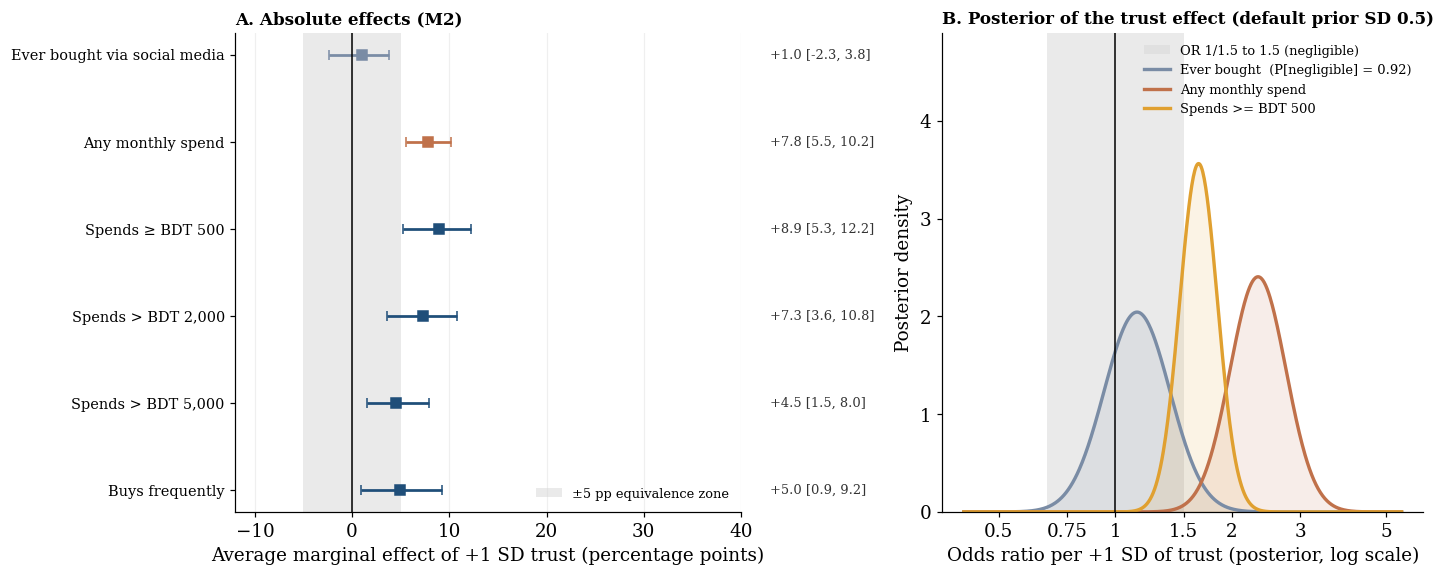


--- Key facts ---
Ever bought, M2: OR 1.16 [0.77, 1.76]; Firth OR 1.16 [0.84, 1.60]
Equivalence established only for margins wider than OR = 1.65 (ML) / 1.52 (Firth)
Ever bought via social media   AME +1.0 pp [-2.3, 3.8]  within ±5pp: yes
Any monthly spend              AME +7.8 pp [5.5, 10.2]  within ±5pp: no
Bayes, ever bought: BF01 = 1.33 / 2.06 / 3.77 (skeptical / default / wide prior); P(negligible) = 0.92
Bootstrap contrasts:
                                               Difference 95% bootstrap CI  Share of resamples where participation slope is smaller
Contrast (log-OR difference vs 'ever bought')                                                                                      
Any monthly spend minus Ever bought                 0.811     [0.25, 1.37]                                                    0.996
Spends >= BDT 500 minus Ever bought                 0.351    [-0.14, 0.83]                                                    0.914
Spends > BDT 2,000 minus Ever bought

In [13]:
# ============================================================
# CELL 12 — Is "ever bought" really flat?  Equivalence (TOST), Bayes factors, Firth, bootstrap contrasts  (Tables 14a-e, Figure 11)
# (run after Cell 11)
# ============================================================
import statsmodels.api as sm, warnings
warnings.filterwarnings("ignore")
from scipy.stats import norm
from scipy.special import expit

NON_BUYERS = int((model["P_buy"] == 0).sum())
print(f"Never bought via social media: {NON_BUYERS} of {len(model)} ({NON_BUYERS / len(model) * 100:.1f}%). "
      f"With only {NON_BUYERS} 'non-events', precision on this outcome is limited - the tests below quantify exactly how limited.")

# ---------- 1. Firth (Jeffreys-prior) penalised logit: guards against bias with few non-events and 10+ covariates ----------
def firth_logit(X, y, maxit=200, tol=1e-9):
    X = np.asarray(X, float); y = np.asarray(y, float); b = np.zeros(X.shape[1])
    for _ in range(maxit):
        p = expit(X @ b); W = p * (1 - p); XtWX = X.T @ (X * W[:, None]); inv = np.linalg.inv(XtWX)
        h = W * np.einsum("ij,jk,ik->i", X, inv, X)
        step = inv @ (X.T @ (y - p + h * (.5 - p)))
        if np.max(np.abs(step)) > 5: step *= 5 / np.max(np.abs(step))
        b = b + step
        if np.max(np.abs(step)) < tol: break
    p = expit(X @ b); W = p * (1 - p); cov = np.linalg.inv(X.T @ (X * W[:, None]))
    return b, cov
# sanity check against ordinary logit on a well-behaved outcome
_m = FITS[("P_spend", MAIN)]; _b, _c = firth_logit(_m.model.exog, _m.model.endog); _zi = list(_m.model.exog_names).index("z_Trust")
print(f"Firth check (any spend): Firth b = {_b[_zi]:.3f} vs ML b = {_m.params['z_Trust']:.3f}  (should be close)")

# ---------- 2. effect estimates for ever-bought: ML (robust), Firth ----------
EST = []   # (label, log-OR, se)
for sp in SPECS:
    r = R13[(R13.oc == "P_buy") & (R13.Spec == sp)].iloc[0]; EST.append((f"{sp} - ML, robust SE", np.log(r.Effect), (np.log(r.hi) - np.log(r.lo)) / 3.92))
for sp in ["M1 + demographics", MAIN, "M3 + vulnerability"]:
    m = FITS[("P_buy", sp)]; b, cov = firth_logit(m.model.exog, m.model.endog); zi = list(m.model.exog_names).index("z_Trust")
    EST.append((f"{sp} - Firth", b[zi], float(np.sqrt(cov[zi, zi]))))

# ---------- 3. TOST on the odds-ratio scale, for several equivalence margins ----------
def tost(b, se, margin):
    lo_b = -np.log(margin); hi_b = np.log(margin)
    p1 = 1 - norm.cdf((b - lo_b) / se); p2 = norm.cdf((b - hi_b) / se); return max(p1, p2)
rows = []
for lab, b, se in EST:
    ci90 = (np.exp(b - 1.645 * se), np.exp(b + 1.645 * se)); m_star = np.exp(max(abs(np.log(ci90[0])), abs(np.log(ci90[1]))))
    row = {"Model": lab, "OR per +1 SD": np.exp(b), "95% CI": f"[{np.exp(b - 1.96 * se):.2f}, {np.exp(b + 1.96 * se):.2f}]", "90% CI": f"[{ci90[0]:.2f}, {ci90[1]:.2f}]"}
    for mg in [1.25, 1.5, 1.75, 2.0]:
        pt = tost(b, se, mg); row[f"TOST p, margin OR {mg}"] = ("<.001" if pt < .001 else f"{pt:.3f}") + (" (equivalent)" if pt < .05 else "")
    row["Smallest margin that establishes equivalence"] = m_star; rows.append(row)
T14a = pd.DataFrame(rows).set_index("Model").round(2)
save_table(T14a, "Table14a_equivalence_OR", "Ever bought via social media: TOST equivalence tests on the odds ratio per +1 SD of trust (equivalent = 90% CI inside [1/margin, margin]); Firth rows use model-based (not robust) SEs, so their intervals are narrower")

# ---------- 4. Absolute scale: average marginal effect (percentage points per +1 SD) and TOST in percentage points ----------
rng = np.random.default_rng(12)
# simulation draws of the average marginal effect (percentage points) of +1 SD trust from the fitted M2 model
def ame_draws(oc, nsim=4000):
    m = FITS[(oc, MAIN)]; X = m.model.exog.copy(); zi = list(m.model.exog_names).index("z_Trust"); X1 = X.copy(); X1[:, zi] += 1
    beta = rng.multivariate_normal(m.params.values, m.cov_params().values, size=nsim)
    return (expit(X1 @ beta.T) - expit(X @ beta.T)).mean(axis=0) * 100
AME = {oc: ame_draws(oc) for _, oc, _ in BIN}
rows = []
for lab, oc, fam in BIN:
    d = AME[oc]; rows.append({"Outcome": lab, "Observed %": model[oc].mean() * 100, "AME (pp per +1 SD)": d.mean(), "95% interval": f"[{np.percentile(d, 2.5):.1f}, {np.percentile(d, 97.5):.1f}]",
                              "90% lower": np.percentile(d, 5), "90% upper": np.percentile(d, 95)})
T14b = pd.DataFrame(rows)
for mg in [3, 5, 10]:
    T14b[f"Equivalent within ±{mg} pp?"] = np.where((T14b["90% lower"] > -mg) & (T14b["90% upper"] < mg), "yes", "no")
T14b = T14b.drop(columns=["90% lower", "90% upper"]).round(1).set_index("Outcome")
save_table(T14b, "Table14b_AME_percentage_points", "Average marginal effect of +1 SD trust on each outcome (percentage points, M2) and equivalence within ±3 / ±5 / ±10 pp (90% simulation interval inside the bounds)")

# ---------- 5. Bayesian evidence for 'no effect' versus 'an effect' (normal approximation to the likelihood; prior N(0, tau^2) on the log-OR) ----------
def bayes(b, se, tau):
    v0 = se ** 2; v1 = se ** 2 + tau ** 2
    bf10 = np.sqrt(v0 / v1) * np.exp(-.5 * b ** 2 * (1 / v1 - 1 / v0))
    pm = b * tau ** 2 / (tau ** 2 + se ** 2); ps = np.sqrt(se ** 2 * tau ** 2 / (tau ** 2 + se ** 2))
    rope = norm.cdf(np.log(1.5), pm, ps) - norm.cdf(-np.log(1.5), pm, ps)
    return bf10, pm, ps, rope
PRIORS = {"skeptical (SD 0.25)": .25, "default (SD 0.5)": .5, "wide (SD 1.0)": 1.0}
rows = []
for lab, oc, fam in BIN + ORDV:
    r = R13[(R13.oc == oc) & (R13.Spec == MAIN)].iloc[0]; b = np.log(r.Effect); se = (np.log(r.hi) - np.log(r.lo)) / 3.92
    row = {"Outcome": lab, "log-OR": b, "SE": se}
    for pl, tau in PRIORS.items():
        bf10, pm, ps, rope = bayes(b, se, tau); row[f"BF01 ({pl})"] = 1 / bf10 if bf10 < 1 else np.nan; row[f"BF10 ({pl})"] = bf10 if bf10 >= 1 else np.nan
        if tau == .5: row["P(OR within 1/1.5-1.5 | data), default prior"] = rope
    rows.append(row)
T14c = pd.DataFrame(rows).set_index("Outcome")
def fmt_bf(x): return "" if pd.isna(x) else (f"{x:.3g}" if x < 1000 else f"{x:.1e}")
T14c_show = T14c.copy()
for c in [c for c in T14c.columns if c.startswith("BF")]: T14c_show[c] = T14c[c].map(fmt_bf)
T14c_show = T14c_show.round(3)
save_table(T14c_show, "Table14c_Bayes_factors", "Bayes factors for trust (M2). BF01 = evidence for no effect, BF10 = evidence for an effect (blank where not applicable); 3-10 moderate, >10 strong. Normal approximation, three prior widths")

# ---------- 6. Bootstrap: is the participation slope smaller than the other slopes?  (difference in log-ORs, M2) ----------
FORM = SPECS[MAIN]
import patsy
Xfull = np.asarray(patsy.dmatrix(FORM, model, return_type="dataframe")); cols = list(patsy.dmatrix(FORM, model, return_type="dataframe").columns); zi = cols.index("z_Trust")
Y = {oc: model[oc].values.astype(float) for oc in ["P_buy", "P_spend", "Spend500", "Spend2000"]}
# trust coefficient of one bootstrap-resample logit fit (NaN if it fails to converge)
def fit_b(X, y):
    try: return sm.Logit(y, X).fit(disp=0, maxiter=100).params[zi]
    except Exception: return np.nan
B = 1500; boot = np.full((B, 4), np.nan); n = len(model); brng = np.random.default_rng(1212)
for i in range(B):
    idx = brng.integers(0, n, n); Xb = Xfull[idx]
    for j, oc in enumerate(Y): boot[i, j] = fit_b(Xb, Y[oc][idx])
bo = pd.DataFrame(boot, columns=list(Y)).dropna(); bo = bo[(bo.abs() < 6).all(axis=1)]   # drop resamples that failed to converge
rows = []
for oc, lab in [("P_spend", "Any monthly spend"), ("Spend500", "Spends >= BDT 500"), ("Spend2000", "Spends > BDT 2,000")]:
    d = bo[oc] - bo["P_buy"]; rows.append({"Contrast (log-OR difference vs 'ever bought')": lab + " minus Ever bought", "Difference": d.mean(), "95% bootstrap CI": f"[{d.quantile(.025):.2f}, {d.quantile(.975):.2f}]",
                                         "Share of resamples where participation slope is smaller": (d > 0).mean(), "OR ratio": np.exp(d.mean())})
T14d = pd.DataFrame(rows).round(3).set_index("Contrast (log-OR difference vs 'ever bought')")
save_table(T14d, "Table14d_bootstrap_contrasts", f"Bootstrap ({len(bo)} valid resamples) contrasts of trust slopes (M2, log-odds scale): how much flatter is lifetime participation than the other outcomes?")

# ---------- 7. Trust groups instead of a linear slope (guards against the sparse top category) ----------
model["TrustG"] = pd.cut(model["Trust18"], [0, 2, 3, 5], labels=["Low (1-2)", "Moderate (3)", "High (4-5)"])
rows = []
for lab, oc in [("Ever bought", "P_buy"), ("Any monthly spend", "P_spend"), ("Spends >= BDT 500", "Spend500")]:
    m = smf.logit(f"{oc} ~ C(TrustG) + {DEM} + z_NFollow + z_SMhrs", data=model).fit(disp=0, cov_type="HC1"); ci = m.conf_int()
    for lv in ["Moderate (3)", "High (4-5)"]:
        k = f"C(TrustG)[T.{lv}]"; rows.append({"Outcome": lab, "Trust group (ref = Low)": lv, "n": int((model.TrustG == lv).sum()), "% outcome in group": model.loc[model.TrustG == lv, oc].mean() * 100,
                                               "OR (M2)": np.exp(m.params[k]), "95% CI": f"[{np.exp(ci.loc[k, 0]):.2f}, {np.exp(ci.loc[k, 1]):.2f}]", "p": m.pvalues[k]})
T14e = pd.DataFrame(rows); T14e["p"] = T14e["p"].map(lambda v: "<.001" if v < .001 else f"{v:.3f}")
save_table(T14e.round(2).set_index(["Outcome", "Trust group (ref = Low)"]), "Table14e_trust_groups", "Odds ratios for moderate and high trust versus low trust (M2 covariates)")

# ---------- 8. Figure 11 ----------
fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.4), gridspec_kw={"width_ratios": [1.05, 1]})
ax = axes[0]; labs = [b[0] for b in BIN]; yy = np.arange(len(labs))
ax.axvspan(-5, 5, color="#d9d9d9", alpha=.55, lw=0, label="±5 pp equivalence zone")
for i, (lab, oc, fam) in enumerate(BIN):
    d = AME[oc]; m_, lo_, hi_ = d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5); col = "#7a8ca5" if fam == "Participation" else "#1f4e79"
    if oc == "P_spend": col = "#c0714a"
    ax.errorbar(m_, i, xerr=[[m_ - lo_], [hi_ - m_]], fmt="s", color=col, ms=7, capsize=3, lw=1.8)
    ax.text(43, i, f"{m_:+.1f} [{lo_:.1f}, {hi_:.1f}]", va="center", fontsize=8.5, color="#333")
ax.axvline(0, color="black", lw=1); ax.set_yticks(yy); ax.set_yticklabels(labs, fontsize=9.5); ax.invert_yaxis(); ax.set_xlim(-12, 40)
ax.set_xlabel("Average marginal effect of +1 SD trust (percentage points)"); ax.legend(loc="lower right", fontsize=8.5, frameon=False); ax.grid(axis="x", alpha=.2)
ax.set_title("A. Absolute effects (M2)", loc="left", fontsize=11, fontweight="bold")
ax = axes[1]; xs = np.linspace(-.9, 1.7, 600)
ax.axvspan(-np.log(1.5), np.log(1.5), color="#d9d9d9", alpha=.55, lw=0, label="OR 1/1.5 to 1.5 (negligible)")
for lab, oc, col in [("Ever bought", "P_buy", "#7a8ca5"), ("Any monthly spend", "P_spend", "#c0714a"), ("Spends >= BDT 500", "Spend500", "#e0a030")]:
    r = R13[(R13.oc == oc) & (R13.Spec == MAIN)].iloc[0]; b = np.log(r.Effect); se = (np.log(r.hi) - np.log(r.lo)) / 3.92; _, pm, ps, rope = bayes(b, se, .5)
    ax.plot(xs, norm.pdf(xs, pm, ps), color=col, lw=2.2, label=f"{lab}" + (f"  (P[negligible] = {rope:.2f})" if oc == "P_buy" else "")); ax.fill_between(xs, norm.pdf(xs, pm, ps), color=col, alpha=.12)
ax.axvline(0, color="black", lw=1); ax.set_xticks(np.log([.5, .75, 1, 1.5, 2, 3, 5])); ax.set_xticklabels(["0.5", "0.75", "1", "1.5", "2", "3", "5"])
ax.set_xlabel("Odds ratio per +1 SD of trust (posterior, log scale)"); ax.set_ylabel("Posterior density"); ax.set_ylim(0, 4.9); ax.legend(loc="upper right", fontsize=8.5, frameon=False)
ax.set_title("B. Posterior of the trust effect (default prior SD 0.5)", loc="left", fontsize=11, fontweight="bold")
CAPTION = (f"Figure 11. Is lifetime participation really unrelated to trust? (n = {len(model)}; {NON_BUYERS} never-buyers)")
fig.tight_layout(); save_fig(fig, "Fig11_equivalence_and_posterior", CAPTION); plt.show()

# ---------- 9. key facts ----------
print("\n--- Key facts ---")
e = T14a.loc[f"{MAIN} - ML, robust SE"]; f_ = T14a.loc[f"{MAIN} - Firth"]
print(f"Ever bought, M2: OR {e['OR per +1 SD']:.2f} {e['95% CI']}; Firth OR {f_['OR per +1 SD']:.2f} {f_['95% CI']}")
print(f"Equivalence established only for margins wider than OR = {e['Smallest margin that establishes equivalence']:.2f} (ML) / {f_['Smallest margin that establishes equivalence']:.2f} (Firth)")
for lab, oc, fam in BIN[:2]:
    print(f"{lab:<30s} AME {T14b.loc[lab, 'AME (pp per +1 SD)']:+.1f} pp {T14b.loc[lab, '95% interval']}  within ±5pp: {T14b.loc[lab, 'Equivalent within ±5 pp?']}")
r = T14c.loc["Ever bought via social media"]; print(f"Bayes, ever bought: BF01 = {fmt_bf(r['BF01 (skeptical (SD 0.25))'])} / {fmt_bf(r['BF01 (default (SD 0.5))'])} / {fmt_bf(r['BF01 (wide (SD 1.0))'])} (skeptical / default / wide prior); P(negligible) = {r['P(OR within 1/1.5-1.5 | data), default prior']:.2f}")
print("Bootstrap contrasts:"); print(T14d[["Difference", "95% bootstrap CI", "Share of resamples where participation slope is smaller"]].to_string())
mdo = np.exp(2.8 * (np.log(e["OR per +1 SD"]) * 0 + (np.log(float(e["95% CI"].split(",")[1].strip(" ]"))) - np.log(float(e["95% CI"].split(",")[0].strip("[ ")))) / 3.92))
print(f"Minimum detectable OR with 80% power for ever bought (approx.): {mdo:.2f}")

## Cell 13 — Risk-containment safeguards and cash on delivery (H3)
Which safeguards go with trust, what drives COD use (joint model with likelihood-ratio contributions), the trust–COD gradient within income strata, and whether safeguards go with lower spending or higher satisfaction.
**Outputs:** Tables 15a–15d; Figures 12 and 13.

Trust groups (model sample): Low (1-2) n = 258, Moderate (3) n = 168, High (4-5) n = 86

Table15a_safeguards_by_trust: Percentage of each trust group (low / moderate / high) showing each behaviour, and the adjusted odds ratio per +1 SD of trust (M2, n = 512); FDR over 13 tests


,Family,Overall %,Low (1-2),Moderate (3),High (4-5),OR per +1 SD [95% CI] (M2),p,q (FDR)
Behaviour,,,,,,,,
Usually pays cash on delivery,Risk containment,54.1,59.7,53.6,38.4,"0.77 [0.63, 0.93]",0.007,0.065
Usually / always researches first,Risk containment,61.5,58.1,62.5,69.8,"1.07 [0.88, 1.30]",0.499,0.783
Relies on user-generated content,Risk containment,47.1,42.6,55.4,44.2,"1.24 [1.03, 1.50]",0.024,0.083
Relies on comparison content,Risk containment,21.1,20.9,24.4,15.1,"1.07 [0.87, 1.31]",0.542,0.783
Driver: many positive reviews,Main purchase driver,19.3,17.4,22.6,18.6,"1.10 [0.89, 1.36]",0.396,0.766
Driver: trusted brand / seller,Main purchase driver,21.3,24.4,19.0,16.3,"0.91 [0.72, 1.15]",0.413,0.766
Driver: return / refund policy,Main purchase driver,5.5,5.8,6.0,3.5,"0.93 [0.63, 1.37]",0.714,0.844
Driver: price / discount,Main purchase driver,21.9,26.0,20.2,12.8,"0.77 [0.61, 0.97]",0.026,0.083
Driver: influencer recommendation,Main purchase driver,7.8,5.8,7.7,14.0,"1.37 [0.95, 2.00]",0.094,0.245


saved figure: Fig12_safeguards_by_trust
  suggested caption: Figure 12. Risk-containment behaviours and trust in influencers (n = 512)


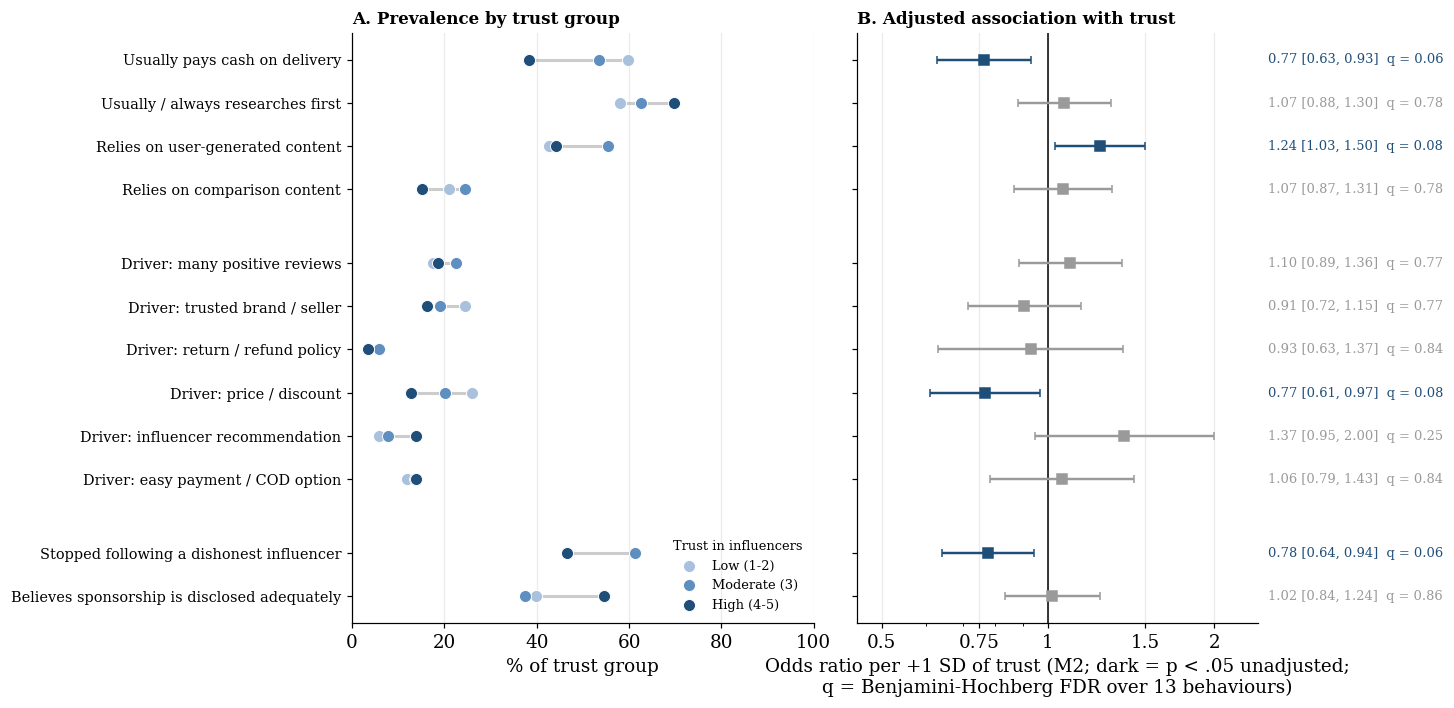


Table15b_COD_joint_model: Joint logit model of paying cash on delivery (n = 512); LR chi-square shows each predictor's unique contribution


,OR,95% CI,p,LR chi2 (1 df)
Predictor of paying cash on delivery,,,,
Trust in influencers (+1 SD),0.76,"[0.62, 0.93]",0.007,7.36
Income (+1 SD),0.64,"[0.51, 0.81]",<.001,14.20
Education (+1 SD),0.79,"[0.64, 0.96]",0.018,5.34
Age (+1 SD),1.12,"[0.89, 1.39]",0.331,0.89
Influencers followed (+1 SD),0.97,"[0.79, 1.20]",0.782,0.07
Daily social-media hours (+1 SD),0.83,"[0.69, 1.01]",0.069,3.04
Psychological vulnerability (+1 SD),1.04,"[0.85, 1.28]",0.698,0.15
Female (vs male),0.68,"[0.46, 1.01]",0.054,3.75
Urban (vs semi-urban),1.54,"[0.99, 2.39]",0.057,3.75


saved figure: Fig13_COD_trust_income
  suggested caption: Figure 13. Cash on delivery by trust and income (n = 512) Bars = 95% Wilson CI; trust x income interaction p = 0.22


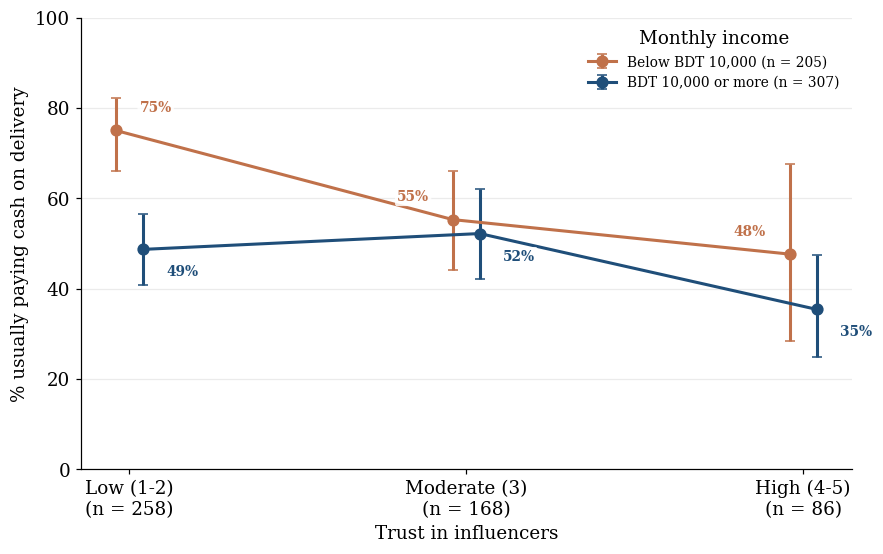


Table15c_COD_by_trust_income: Percentage paying cash on delivery by trust group within income strata


n  % pays COD
Income             Trust group                  
Below BDT 10,000   Low (1-2)     108        75.0
                   Moderate (3)   76        55.3
                   High (4-5)     21        47.6
BDT 10,000 or more Low (1-2)     150        48.7
                   Moderate (3)   92        52.2
                   High (4-5)     65        35.4


Table15d_safeguards_and_outcomes: Do safeguards go with lower spending or higher satisfaction? Joint models containing trust and all four safeguards plus M2 covariates


OR        95% CI      p q (FDR)
Outcome                       Predictor                                                            
Monthly spend level (ordered) Trust (+1 SD)                       1.63  [1.37, 1.94]  <.001   <.001
                              Pays cash on delivery               0.67  [0.48, 0.94]  0.020   0.057
                              Researches first                    1.13  [0.81, 1.59]  0.465   0.664
                              Uses UGC / comparison content       1.81  [1.29, 2.54]  <.001   0.003
                              Driver: reviews / seller / returns  0.91  [0.65, 1.27]  0.569   0.759
Spends > BDT 2,000            Trust (+1 SD)                       1.59  [1.23, 2.04]  <.001   0.002
                              Pays cash on delivery               0.68  [0.43, 1.08]  0.105   0.191
                              Researches first                    1.08  [0.66, 1.77]  0.756   0.890
                              Uses UGC / comparison content       1.57  [0.94, 2.63]  0.085   0.171
                              Driver: reviews / seller / returns  1.00  [0.62, 1.61]  0.996   0.996
Buys frequently               Trust (+1 SD)                       1.38  [1.09, 1.76]  0.008   0.028
                              Pays cash on delivery               1.31  [0.82, 2.08]  0.255   0.425
                              Researches first                    3.70  [2.11, 6.48]  <.001   <.001
                              Uses UGC / comparison content       0.66  [0.41, 1.05]  0.078   0.171
                              Driver: reviews / seller / returns  0.92  [0.58, 1.47]  0.739   0.890
Satisfied with purchases      Trust (+1 SD)                       1.26  [1.03, 1.55]  0.027   0.068
                              Pays cash on delivery               1.01  [0.68, 1.50]  0.951   0.996
                              Researches first                    1.91  [1.29, 2.81]  0.001   0.005
                              Uses UGC / comparison content       1.00  [0.68, 1.48]  0.982   0.996
                              Driver: reviews / seller / returns  1.17  [0.80, 1.71]  0.413   0.635


--- Key facts ---
Behaviours with a nominal p < .05 for trust (M2; FDR q over 13 tests shown - none may survive, so treat all but the focal COD test as exploratory):
  Usually pays cash on delivery                    OR 0.77 [0.63, 0.93]  p = 0.007, q = 0.065
  Relies on user-generated content                 OR 1.24 [1.03, 1.50]  p = 0.024, q = 0.083
  Driver: price / discount                         OR 0.77 [0.61, 0.97]  p = 0.026, q = 0.083
  Stopped following a dishonest influencer         OR 0.78 [0.64, 0.94]  p = 0.010, q = 0.065
No association with trust: Usually / always researches first; Relies on comparison content; Driver: many positive reviews; Driver: trusted brand / seller; Driver: return / refund policy; Driver: influencer recommendation; Driver: easy payment / COD option; Believes sponsorship is disclosed adequately; Safeguard index 0-4 (ordered logit)

COD joint model: trust OR 0.76, income OR 0.64, education OR 0.79
Trust x income interaction on COD: p = 0.22
COD % b

In [14]:
# ============================================================
# CELL 13 — Risk-containment safeguards and cash on delivery (Tables 15a-c, Figures 12-13)
# (run after Cell 11 - it re-uses SPECS, MAIN, DEM, smf and the z-scores)
# ============================================================
import warnings; warnings.filterwarnings("ignore")
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
from scipy import stats as _st

# ---------- 0. extra variables ----------
model["StopFollow"] = (model["Q21"].fillna("") == "Yes").astype(int)                                  # stopped following a dishonest influencer
model["DiscAdeq"] = model["Q22"].fillna("").isin(["Most of the time", "Yes, always"]).astype(int)    # believes sponsorship is disclosed adequately
model["TrustG"] = pd.cut(model["Trust18"], [0, 2, 3, 5], labels=["Low (1-2)", "Moderate (3)", "High (4-5)"])
model["IncG"] = np.where(model["Income"] <= 1, "Below BDT 10,000", "BDT 10,000 or more")
GR = ["Low (1-2)", "Moderate (3)", "High (4-5)"]; NG = model["TrustG"].value_counts().reindex(GR)
print("Trust groups (model sample):", ", ".join(f"{g_} n = {NG[g_]}" for g_ in GR))

SAFE = [("Usually pays cash on delivery", "COD", "Risk containment"), ("Usually / always researches first", "ResH", "Risk containment"),
        ("Relies on user-generated content", "UGC", "Risk containment"), ("Relies on comparison content", "CMP", "Risk containment"),
        ("Driver: many positive reviews", "Q25_rev", "Main purchase driver"), ("Driver: trusted brand / seller", "Q25_sell", "Main purchase driver"),
        ("Driver: return / refund policy", "Q25_ret", "Main purchase driver"), ("Driver: price / discount", "Q25_price", "Main purchase driver"),
        ("Driver: influencer recommendation", "Q25_infl", "Main purchase driver"), ("Driver: easy payment / COD option", "Q25_cod", "Main purchase driver"),
        ("Stopped following a dishonest influencer", "StopFollow", "Vigilance"), ("Believes sponsorship is disclosed adequately", "DiscAdeq", "Vigilance")]

# ---------- 1. prevalence by trust group + adjusted trust slope (M2) for every safeguard ----------
rows = []
for lab, v, fam in SAFE:
    row = {"Behaviour": lab, "var": v, "Family": fam, "Overall %": model[v].mean() * 100}
    for g_ in GR:
        s = model.loc[model.TrustG == g_, v]; lo, hi = proportion_confint(s.sum(), len(s), method="wilson"); row[g_] = s.mean() * 100; row[g_ + " lo"] = lo * 100; row[g_ + " hi"] = hi * 100
    m = smf.logit(f"{v} ~ {SPECS[MAIN]}", data=model).fit(disp=0, cov_type="HC1"); ci = m.conf_int().loc["z_Trust"]
    row.update({"OR per +1 SD": np.exp(m.params["z_Trust"]), "OR lo": np.exp(ci[0]), "OR hi": np.exp(ci[1]), "p": m.pvalues["z_Trust"]}); rows.append(row)
# safeguard index (0-4) as an ordered outcome
sgm = OrderedModel.from_formula(f"SG ~ 0 + {SPECS[MAIN]}", data=model, distr="logit").fit(method="bfgs", disp=0, maxiter=1000); ci = sgm.conf_int().loc["z_Trust"]
rows.append({"Behaviour": "Safeguard index 0-4 (ordered logit)", "var": "SG", "Family": "Index", "Overall %": np.nan, **{g_: np.nan for g_ in GR}, "OR per +1 SD": np.exp(sgm.params["z_Trust"]),
             "OR lo": np.exp(ci[0]), "OR hi": np.exp(ci[1]), "p": sgm.pvalues["z_Trust"]})
T15 = pd.DataFrame(rows); T15["q (FDR)"] = multipletests(T15["p"], method="fdr_bh")[1]
T15["sig"] = np.where(T15["q (FDR)"] < .001, "***", np.where(T15["q (FDR)"] < .01, "**", np.where(T15["q (FDR)"] < .05, "*", "")))
show = T15[["Behaviour", "Family", "Overall %"] + GR].copy(); show["OR per +1 SD [95% CI] (M2)"] = T15.apply(lambda r: f"{r['OR per +1 SD']:.2f} [{r['OR lo']:.2f}, {r['OR hi']:.2f}]{r['sig']}", axis=1)
show["p"] = T15["p"].map(lambda v: "<.001" if v < .001 else f"{v:.3f}"); show["q (FDR)"] = T15["q (FDR)"].map(lambda v: "<.001" if v < .001 else f"{v:.3f}")
save_table(show.round(1).set_index("Behaviour"), "Table15a_safeguards_by_trust", f"Percentage of each trust group (low / moderate / high) showing each behaviour, and the adjusted odds ratio per +1 SD of trust (M2, n = {len(model)}); FDR over {len(T15)} tests")

# ---------- 2. Figure 12: prevalence by trust group (A) and adjusted slope (B) ----------
D12 = T15[T15["var"] != "SG"].reset_index(drop=True); order = []
for fam in ["Risk containment", "Main purchase driver", "Vigilance"]: order += list(D12.index[D12.Family == fam])
ypos = {}; y = 0; prev = None
for i in order:
    if prev is not None and D12.Family[i] != prev: y += .7
    ypos[i] = y; y += 1; prev = D12.Family[i]
fig, axes = plt.subplots(1, 2, figsize=(13.4, 6.6), sharey=True, gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]; GC = ["#a9c1dd", "#5f8fc0", "#1f4e79"]
for i in order:
    r = D12.loc[i]; ax.hlines(ypos[i], min(r[g_] for g_ in GR), max(r[g_] for g_ in GR), color="#cccccc", lw=2, zorder=1)
    for g_, c_ in zip(GR, GC): ax.scatter(r[g_], ypos[i], s=62, color=c_, zorder=3, edgecolor="white", lw=.6, label=g_ if i == order[0] else None)
ax.set_yticks([ypos[i] for i in order]); ax.set_yticklabels([D12.Behaviour[i] for i in order], fontsize=9.5); ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("% of trust group"); ax.grid(axis="x", alpha=.25); ax.legend(title="Trust in influencers", loc="lower right", fontsize=8.5, title_fontsize=8.5, frameon=False)
ax.set_title("A. Prevalence by trust group", loc="left", fontsize=11, fontweight="bold")
ax = axes[1]; ax.axvline(1, color="black", lw=1)
for i in order:
    r = D12.loc[i]; col = "#1f4e79" if r["p"] < .05 else "#9a9a9a"
    ax.errorbar(r["OR per +1 SD"], ypos[i], xerr=[[r["OR per +1 SD"] - r["OR lo"]], [r["OR hi"] - r["OR per +1 SD"]]], fmt="s", color=col, ms=6.5, capsize=2.5, lw=1.6)
    ax.text(2.5, ypos[i], f"{r['OR per +1 SD']:.2f} [{r['OR lo']:.2f}, {r['OR hi']:.2f}]  q = {r['q (FDR)']:.2f}", va="center", fontsize=8.5, color=col)
ax.set_xscale("log"); ax.set_xlim(.45, 2.4); ax.set_xticks([.5, .75, 1, 1.5, 2]); ax.set_xticklabels(["0.5", "0.75", "1", "1.5", "2"])
from matplotlib.ticker import NullFormatter; ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("Odds ratio per +1 SD of trust (M2; dark = p < .05 unadjusted;\nq = Benjamini-Hochberg FDR over 13 behaviours)"); ax.grid(axis="x", alpha=.25)
ax.set_title("B. Adjusted association with trust", loc="left", fontsize=11, fontweight="bold")
CAPTION = (f"Figure 12. Risk-containment behaviours and trust in influencers (n = {len(model)})")
fig.tight_layout(); save_fig(fig, "Fig12_safeguards_by_trust", CAPTION); plt.show()

# ---------- 3. COD: which factor drives it?  joint model + likelihood-ratio contribution of each block ----------
FULL_RHS = "z_Trust + Female + Urban + Rural + z_Income + z_Edu + z_Age + z_NFollow + z_SMhrs + z_Vuln"
mc = smf.logit(f"COD ~ {FULL_RHS}", data=model).fit(disp=0, cov_type="HC1"); ci = mc.conf_int()
rows = []
for k_, lab in [("z_Trust", "Trust in influencers (+1 SD)"), ("z_Income", "Income (+1 SD)"), ("z_Edu", "Education (+1 SD)"), ("z_Age", "Age (+1 SD)"), ("z_NFollow", "Influencers followed (+1 SD)"),
                ("z_SMhrs", "Daily social-media hours (+1 SD)"), ("z_Vuln", "Psychological vulnerability (+1 SD)"), ("Female", "Female (vs male)"), ("Urban", "Urban (vs semi-urban)"), ("Rural", "Rural (vs semi-urban)")]:
    rows.append({"Predictor of paying cash on delivery": lab, "OR": np.exp(mc.params[k_]), "95% CI": f"[{np.exp(ci.loc[k_, 0]):.2f}, {np.exp(ci.loc[k_, 1]):.2f}]", "p": mc.pvalues[k_]})
# likelihood-ratio chi-square for dropping each predictor from the (non-robust) joint model
mlr = smf.logit(f"COD ~ {FULL_RHS}", data=model).fit(disp=0)
for r_ in rows:
    k_ = [k for k, l in [("z_Trust", "Trust"), ("z_Income", "Income"), ("z_Edu", "Education"), ("z_Age", "Age"), ("z_NFollow", "Influencers"), ("z_SMhrs", "Daily"), ("z_Vuln", "Psychological"), ("Female", "Female"), ("Urban", "Urban"), ("Rural", "Rural")] if r_["Predictor of paying cash on delivery"].startswith(l)][0]
    red = smf.logit("COD ~ " + " + ".join(t.strip() for t in FULL_RHS.split("+") if t.strip() != k_), data=model).fit(disp=0); r_["LR chi2 (1 df)"] = 2 * (mlr.llf - red.llf)
T15b = pd.DataFrame(rows); T15b["p"] = T15b["p"].map(lambda v: "<.001" if v < .001 else f"{v:.3f}")
save_table(T15b.round(2).set_index("Predictor of paying cash on delivery"), "Table15b_COD_joint_model", f"Joint logit model of paying cash on delivery (n = {len(model)}); LR chi-square shows each predictor's unique contribution")

# ---------- 4. Figure 13: the trust-COD gradient inside income strata + interaction test ----------
fig, ax = plt.subplots(figsize=(8.2, 5.2)); pal = {"Below BDT 10,000": "#c0714a", "BDT 10,000 or more": "#1f4e79"}; off = {"Below BDT 10,000": -.04, "BDT 10,000 or more": .04}
cod_rows = []
for ig, col in pal.items():
    xs_, ys_, lo_, hi_ = [], [], [], []
    for j, g_ in enumerate(GR):
        s = model.loc[(model.IncG == ig) & (model.TrustG == g_), "COD"]; l_, h_ = proportion_confint(s.sum(), len(s), method="wilson"); xs_.append(j + off[ig]); ys_.append(s.mean() * 100); lo_.append(l_ * 100); hi_.append(h_ * 100)
        cod_rows.append({"Income": ig, "Trust group": g_, "n": len(s), "% pays COD": s.mean() * 100})
    ax.errorbar(xs_, ys_, yerr=[np.array(ys_) - lo_, np.array(hi_) - ys_], fmt="-o", color=col, lw=2, ms=7, capsize=3, label=f"{ig} (n = {int((model.IncG == ig).sum())})")
    for k_, (x_, y_) in enumerate(zip(xs_, ys_)): ax.text(x_ + (.07 if (not ig.startswith("Below") or k_ == 0) else -.07), y_ + (5 if ig.startswith("Below") else -5), f"{y_:.0f}%", ha=("left" if (not ig.startswith("Below") or k_ == 0) else "right"), va="center", fontsize=9, color=col, fontweight="bold", bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=.85))
ax.set_xticks(range(3)); ax.set_xticklabels([f"{g_}\n(n = {NG[g_]})" for g_ in GR]); ax.set_ylim(0, 100); ax.set_ylabel("% usually paying cash on delivery"); ax.set_xlabel("Trust in influencers"); ax.grid(axis="y", alpha=.25)
ax.legend(title="Monthly income", loc="upper right", frameon=False, fontsize=9)
m_i = smf.logit("COD ~ z_Trust * C(IncG) + Female + Urban + Rural + z_Edu + z_Age + z_NFollow + z_SMhrs", data=model).fit(disp=0)
m_0 = smf.logit("COD ~ z_Trust + C(IncG) + Female + Urban + Rural + z_Edu + z_Age + z_NFollow + z_SMhrs", data=model).fit(disp=0)
lr_p = _st.chi2.sf(2 * (m_i.llf - m_0.llf), 1)
CAPTION = (f"Figure 13. Cash on delivery by trust and income (n = {len(model)})\nBars = 95% Wilson CI; trust x income interaction p = {lr_p:.2f}")
fig.tight_layout(); save_fig(fig, "Fig13_COD_trust_income", CAPTION); plt.show()
save_table(pd.DataFrame(cod_rows).round(1).set_index(["Income", "Trust group"]), "Table15c_COD_by_trust_income", "Percentage paying cash on delivery by trust group within income strata")

# ---------- 5. do safeguards go with lower spending or higher satisfaction?  (adjusted, trust held constant) ----------
model["Pillar_UGC_CMP"] = ((model["UGC"] + model["CMP"]) > 0).astype(int); model["Pillar_rev_sell_ret"] = ((model["Q25_rev"] + model["Q25_sell"] + model["Q25_ret"]) > 0).astype(int)
SGV = [("Pays cash on delivery", "COD"), ("Researches first", "ResH"), ("Uses UGC / comparison content", "Pillar_UGC_CMP"), ("Driver: reviews / seller / returns", "Pillar_rev_sell_ret")]
rhs = "z_Trust + " + " + ".join(v for _, v in SGV) + f" + {DEM} + z_NFollow + z_SMhrs"
rows = []
for lab_o, oc, kind in [("Monthly spend level (ordered)", "Spend", "ord"), ("Spends > BDT 2,000", "Spend2000", "bin"), ("Buys frequently", "FreqBuy", "bin"), ("Satisfied with purchases", "Satisfied", "bin")]:
    m = (OrderedModel.from_formula(f"{oc} ~ 0 + {rhs}", data=model, distr="logit").fit(method="bfgs", disp=0, maxiter=1000) if kind == "ord" else smf.logit(f"{oc} ~ {rhs}", data=model).fit(disp=0, cov_type="HC1")); ci = m.conf_int()
    for lab_s, v in [("Trust (+1 SD)", "z_Trust")] + SGV:
        rows.append({"Outcome": lab_o, "Predictor": lab_s, "OR": np.exp(m.params[v]), "95% CI": f"[{np.exp(ci.loc[v, 0]):.2f}, {np.exp(ci.loc[v, 1]):.2f}]", "p": m.pvalues[v]})
T15d = pd.DataFrame(rows); T15d["q (FDR)"] = multipletests(T15d["p"], method="fdr_bh")[1]
T15d["p"] = T15d["p"].map(lambda v: "<.001" if v < .001 else f"{v:.3f}"); T15d["q (FDR)"] = T15d["q (FDR)"].map(lambda v: "<.001" if v < .001 else f"{v:.3f}")
save_table(T15d.round(2).set_index(["Outcome", "Predictor"]), "Table15d_safeguards_and_outcomes", "Do safeguards go with lower spending or higher satisfaction? Joint models containing trust and all four safeguards plus M2 covariates")

# ---------- 6. key facts ----------
print("\n--- Key facts ---")
print(f"Behaviours with a nominal p < .05 for trust (M2; FDR q over {len(T15)} tests shown - none may survive, so treat all but the focal COD test as exploratory):")
for _, r in T15[T15["p"] < .05].iterrows(): print(f"  {r.Behaviour:<48s} OR {r['OR per +1 SD']:.2f} [{r['OR lo']:.2f}, {r['OR hi']:.2f}]  p = {r['p']:.3f}, q = {r['q (FDR)']:.3f}")
print("No association with trust:", "; ".join(T15[T15["p"] >= .05].Behaviour))
print(f"\nCOD joint model: trust OR {np.exp(mc.params['z_Trust']):.2f}, income OR {np.exp(mc.params['z_Income']):.2f}, education OR {np.exp(mc.params['z_Edu']):.2f}")
print(f"Trust x income interaction on COD: p = {lr_p:.2f}")
print("COD % by trust group (all income):", " | ".join(f"{g_} {model.loc[model.TrustG == g_, 'COD'].mean() * 100:.0f}%" for g_ in GR))
print("\nCOD joint model (unique contribution = LR chi-square, 1 df):")
print(T15b.set_index("Predictor of paying cash on delivery")[["OR", "95% CI", "p", "LR chi2 (1 df)"]].to_string())
print("\nSafeguard effects on outcomes (OR):"); print(T15d.set_index(["Outcome", "Predictor"])[["OR", "95% CI", "p", "q (FDR)"]].to_string())

## Cell 14 — Mediation (H4) and moderation (H5)
Product-of-coefficients mediation of the trust–spending link through COD and the other safeguards (bootstrap CIs, sensitivity to residual correlation), and a screen of 12 moderators with likelihood-ratio tests.
**Outputs:** Tables 16a–16c and 17a–17b; Figures 14 and 15.

Mediation: linear product-of-coefficients models, 5,000 bootstrap resamples, trust scaled +1 SD, n = 512
  Spend = 1-6 ordinal level treated as numeric (OLS); Spend2000 = linear-probability model (units = percentage points)


Table16a_mediation_COD: H4: does cash on delivery carry part of the trust-spending association? Effects per +1 SD of trust (n = 512); percentile 95% CI from 5,000 bootstrap resamples. a is in probability units; rho = unmeasured mediator-outcome error correlation that would reduce the indirect effect to zero


a: trust -> COD b: COD -> outcome (levels / pp) Indirect via COD (a x b)   % of total                Direct (c')  \
Outcome                   Model                                                                                                                                                           
Monthly spend level (1-6) M1 demographics                      -0.067 [-0.109, -0.025]            -0.22 [-0.42, -0.03]  +0.015 [+0.001, +0.035]    4% [0, 8]    +0.408 [+0.310, +0.508]   
                          M2 + exposure (main)                 -0.060 [-0.101, -0.015]            -0.19 [-0.36, -0.01]  +0.011 [+0.000, +0.027]   4% [0, 10]    +0.282 [+0.188, +0.379]   
                          M3 + vulnerability                   -0.061 [-0.103, -0.018]            -0.19 [-0.37, -0.00]  +0.012 [-0.000, +0.029]  4% [-0, 11]    +0.269 [+0.172, +0.363]   
Spends > BDT 2,000 (pp)   M1 demographics                      -0.067 [-0.108, -0.027]           -6.63 [-14.08, +0.68]  +0.443 [-0.047, +1.153]  4% [-0, 12]  +10.314 [+6.706, +14.174]   
                          M2 + exposure (main)                 -0.060 [-0.103, -0.018]           -5.35 [-12.78, +1.45]  +0.321 [-0.075, +0.947]  5% [-1, 17]    +6.343 [+2.725, +9.872]   
                          M3 + vulnerability                   -0.061 [-0.105, -0.017]           -5.46 [-12.78, +1.26]  +0.334 [-0.081, +0.989]  5% [-1, 20]    +5.893 [+2.123, +9.596]   
Monthly spend level (1-6) M2, logistic a-path (g-computation)  -0.060 [-0.105, -0.015]                           -0.19  +0.011 [-0.000, +0.028]           4%                              

                                                                               Total (c) rho at which indirect = 0  
Outcome                   Model                                                                                     
Monthly spend level (1-6) M1 demographics                        +0.423 [+0.325, +0.522]                     -0.10  
                          M2 + exposure (main)                   +0.293 [+0.200, +0.390]                     -0.09  
                          M3 + vulnerability                     +0.280 [+0.181, +0.374]                     -0.09  
Spends > BDT 2,000 (pp)   M1 demographics                      +10.756 [+7.167, +14.603]                     -0.08  
                          M2 + exposure (main)                  +6.664 [+2.989, +10.245]                     -0.07  
                          M3 + vulnerability                     +6.227 [+2.458, +9.920]                     -0.07  
Monthly spend level (1-6) M2, logistic a-path (g-computation)


Table16b_parallel_safeguards: Parallel mediation: four risk-containment safeguards entered together (M2 covariates incl. exposure), per +1 SD of trust; percentile 95% CI from bootstrap


a (trust -> mediator) b (mediator -> outcome, levels)  Indirect a x b (levels) % of total effect  \
Outcome                   Model               Mediator                                                                                                                                 
Monthly spend level (1-6) M2: four safeguards Pays cash on delivery               -0.060 [-0.102, -0.016]            -0.20 [-0.38, -0.01]  +0.012 [+0.000, +0.030]        4% [0, 11]   
                                              Researches first                    +0.015 [-0.029, +0.060]            +0.07 [-0.12, +0.26]  +0.001 [-0.004, +0.009]        0% [-2, 3]   
                                              Uses UGC / comparison content       +0.038 [-0.007, +0.084]            +0.28 [+0.09, +0.46]  +0.011 [-0.002, +0.029]       4% [-1, 10]   
                                              Driver: reviews / seller / returns  -0.006 [-0.051, +0.040]            -0.06 [-0.24, +0.12]  +0.000 [-0.005, +0.007]        0% [-2, 2]   
                                              All mediators combined                                                                       +0.024 [+0.005, +0.048]        8% [2, 17]   
                                              Direct effect of trust (c')                                                                  +0.270 [+0.175, +0.365]                     
                                              Total effect of trust (c)                                                                    +0.293 [+0.202, +0.390]                     
Spends > BDT 2,000 (pp)   M2: four safeguards Pays cash on delivery               -0.060 [-0.102, -0.016]                             NaN                      NaN       5% [-1, 18]   
                                              Researches first                    +0.015 [-0.029, +0.061]                             NaN                      NaN        1% [-3, 7]   
                                              Uses UGC / comparison content       +0.038 [-0.007, +0.084]                             NaN                      NaN       4% [-1, 14]   
                                              Driver: reviews / seller / returns  -0.006 [-0.052, +0.040]                             NaN                      NaN        0% [-3, 4]   
                                              All mediators combined                                                                  NaN                      NaN      10% [-0, 28]   
                                              Direct effect of trust (c')                                                             NaN                      NaN                     
                                              Total effect of trust (c)                                                               NaN                      NaN                     

                                                                                 rho at which indirect = 0 b (mediator -> outcome, pp)       Indirect a x b (pp)  
Outcome                   Model               Mediator                                                                                                            
Monthly spend level (1-6) M2: four safeguards Pays cash on delivery                                  -0.09                         NaN                       NaN  
                                              Researches first                                       +0.04                         NaN                       NaN  
                                              Uses UGC / comparison content                          +0.13                         NaN                       NaN  
                                              Driver: reviews / seller / returns                     -0.00                         NaN                       NaN  
                                              All mediators combined                                                               NaN                       NaN 


Table16c_safeguards_vs_exposure: Competing paths: safeguards AND exposure (influencers followed, daily hours) treated as parallel mediators (M1 covariates). The direction of the trust-exposure link is not identified, so read the exposure rows as exploratory


a (trust -> mediator) b (mediator -> outcome, levels)  Indirect a x b (levels) % of total effect  \
Outcome                   Model                     Mediator                                                                                                                                 
Monthly spend level (1-6) M1: safeguards + exposure Pays cash on delivery               -0.067 [-0.108, -0.025]            -0.20 [-0.38, -0.01]  +0.013 [+0.001, +0.032]         3% [0, 8]   
                                                    Researches first                    +0.019 [-0.023, +0.060]            +0.07 [-0.12, +0.26]  +0.001 [-0.004, +0.009]        0% [-1, 2]   
                                                    Uses UGC / comparison content       +0.027 [-0.016, +0.071]            +0.28 [+0.09, +0.46]  +0.007 [-0.004, +0.024]        2% [-1, 6]   
                                                    Driver: reviews / seller / returns  -0.017 [-0.060, +0.026]            -0.06 [-0.25, +0.12]  +0.001 [-0.004, +0.009]        0% [-1, 2]   
                                                    Influencers followed (+1 SD)        +0.306 [+0.222, +0.394]            +0.40 [+0.29, +0.51]  +0.121 [+0.078, +0.173]      29% [19, 42]   
                                                    Daily social-media hours (+1 SD)    +0.145 [+0.058, +0.236]            +0.06 [-0.05, +0.17]  +0.009 [-0.007, +0.030]        2% [-2, 7]   
                                                    All mediators combined                                                                       +0.153 [+0.105, +0.209]      36% [25, 51]   
                                                    Direct effect of trust (c')                                                                  +0.270 [+0.175, +0.363]                     
                                                    Total effect of trust (c)                                                                    +0.423 [+0.328, +0.521]                     
Spends > BDT 2,000 (pp)   M1: safeguards + exposure Pays cash on delivery               -0.067 [-0.110, -0.025]                             NaN                      NaN       3% [-1, 10]   
                                                    Researches first                    +0.019 [-0.021, +0.060]                             NaN                      NaN        1% [-1, 4]   
                                                    Uses UGC / comparison content       +0.027 [-0.018, +0.071]                             NaN                      NaN        2% [-1, 6]   
                                                    Driver: reviews / seller / returns  -0.017 [-0.059, +0.027]                             NaN                      NaN        0% [-2, 3]   
                                                    Influencers followed (+1 SD)        +0.306 [+0.221, +0.394]                             NaN                      NaN      34% [21, 57]   
                                                    Daily social-media hours (+1 SD)    +0.145 [+0.058, +0.235]                             NaN                      NaN       4% [-1, 11]   
                                                    All mediators combined                                                                  NaN                      NaN      44% [28, 70]   
                                                    Direct effect of trust (c')                                                             NaN                      NaN                     
                                                    Total effect of trust (c)                                                               NaN                      NaN                     

                                                                                       rho at which indirect = 0 b (mediator -> outcome, pp)        Indirect a x b (pp)  
Outcome                   Model                     Mediator                                                           

saved figure: Fig14_mediation
  suggested caption: Figure 14. Mediation of the trust-spending association (n = 512; 5,000 bootstrap resamples)


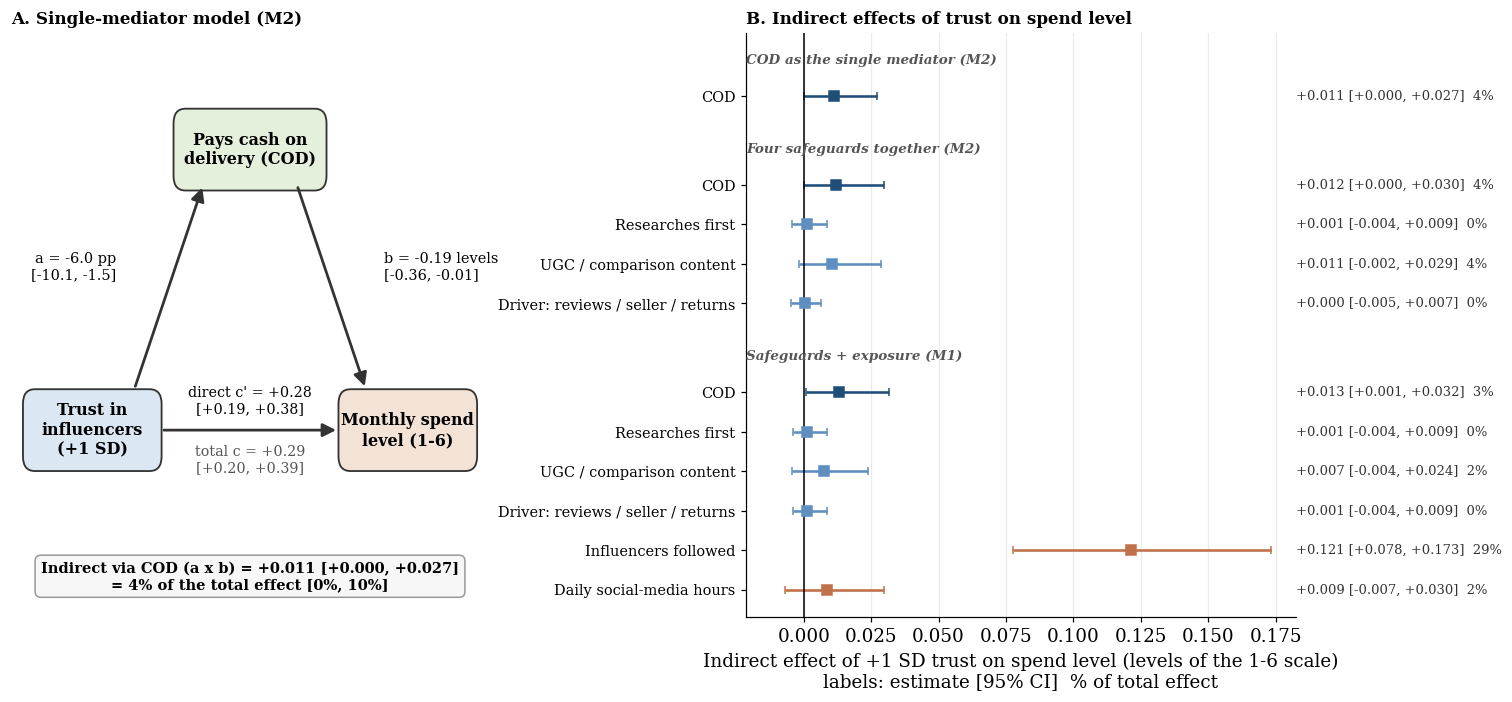


Table17a_moderation: H5: trust x moderator interactions on three outcomes (M2 + moderator, n = 512). OR = ratio of the trust odds ratio per +1 SD of trust for a +1 unit (SD or yes-vs-no) change in the moderator; p from likelihood-ratio tests with a quadratic trust term in both models (so curvature is not mistaken for moderation; the linear-only p is shown for comparison); BH-FDR over 12 moderators within outcome and over all 36 tests


Trust x moderator OR [95% CI] LR chi2 (df)      p p (linear trust only) q (12 tests) q (all 36)
Outcome                       Moderator                                                                                                                          
Monthly spend level (ordered) Female (vs male)                                1.38 [0.98, 1.95]     3.47 (1)  0.062                 0.060        0.307      0.182
                              Urban (vs semi-urban)                           0.93 [0.63, 1.38]     1.21 (2)  0.545                 0.526        0.654      0.676
                              Rural (vs semi-urban)                           0.77 [0.47, 1.24]     1.21 (2)  0.545                 0.526        0.654      0.676
                              Income (+1 SD)                                  1.09 [0.92, 1.29]     1.04 (1)  0.307                 0.305        0.527      0.481
                              Education (+1 SD)                               0.96 [0.82, 1.11]     0.37 (1)  0.541                 0.538        0.654      0.676
                              Age (+1 SD)                                     0.99 [0.84, 1.17]     0.01 (1)  0.927                 0.909        0.927      0.927
                              Influencers followed (+1 SD)                    0.96 [0.80, 1.14]     0.25 (1)  0.620                 0.588        0.677      0.720
                              Daily social-media hours (+1 SD)                0.91 [0.77, 1.07]     1.41 (1)  0.235                 0.222        0.470      0.394
                              Psychological vulnerability (+1 SD)             0.87 [0.74, 1.02]     3.13 (1)  0.077                 0.069        0.307      0.188
                              Pays cash on delivery                           1.33 [0.94, 1.86]     2.65 (1)  0.104                 0.094        0.312      0.220
                              Researches first                                1.30 [0.92, 1.83]     2.23 (1)  0.135                 0.133        0.325      0.254
                              Uses UGC / comparison content                   0.64 [0.46, 0.89]     7.04 (1)  0.008                 0.008        0.096      0.048
                              Driver: reviews / seller / returns              1.16 [0.83, 1.63]     0.75 (1)  0.385                 0.369        0.578      0.555
Spends > BDT 2,000            Female (vs male)                                1.80 [1.08, 3.01]     5.19 (1)  0.023                 0.029        0.212      0.107
                              Urban (vs semi-urban)                           0.75 [0.43, 1.31]     1.06 (2)  0.590                 0.589        0.707      0.707
                              Rural (vs semi-urban)                           0.79 [0.37, 1.66]     1.06 (2)  0.590                 0.589        0.707      0.707
                              Income (+1 SD)                                  1.01 [0.79, 1.29]     0.01 (1)  0.927                 0.986        0.927      0.927
                              Education (+1 SD)                               0.85 [0.69, 1.05]     2.28 (1)  0.131                 0.126        0.262      0.254
                              Age (+1 SD)                                     0.79 [0.62, 1.01]     3.60 (1)  0.058                 0.058        0.212      0.182
                              Influencers followed (+1 SD)                    1.26 [0.98, 1.63]     3.38 (1)  0.066                 0.061        0.212      0.182
                              Daily social-media hours (+1 SD)                0.90 [0.70, 1.16]     0.63 (1)  0.428                 0.458        0.642      0.592
                              Psychological vulnerability (+1 SD)             1.23 [0.97, 1.56]     2.91 (1)  0.088                 0.083        0.212      0.198
                              Pays cash on delivery                           1.57 [0.95, 2.58]     3.10 (1)  0.078                 0.097        0.212      0.188
                


Table17b_simple_slopes_spend: Trust-spend odds ratio (per +1 SD of trust at the mean of trust; ordered logit, M2 + trust squared) at levels of the six moderators with the smallest interaction p; Wald 95% CI


Trust OR per +1 SD    lo    hi
Moderator                           Level                                 
Uses UGC / comparison content       No                    2.06  1.61  2.62
                                    Yes                   1.32  1.04  1.68
Female (vs male)                    Male                  1.50  1.21  1.86
                                    Female                2.08  1.57  2.75
Psychological vulnerability (+1 SD) -1 SD                 1.94  1.51  2.48
                                    +1 SD                 1.45  1.15  1.83
Pays cash on delivery               No                    1.45  1.14  1.85
                                    Yes                   1.93  1.50  2.48
Researches first                    No                    1.44  1.09  1.89
                                    Yes                   1.86  1.49  2.33
Daily social-media hours (+1 SD)    -1 SD                 1.87  1.47  2.38
                                    +1 SD                 1.53  1.21  1.95


Table17c_simple_slopes_frequent_buying: Trust-frequent buying odds ratio (per +1 SD of trust at the mean of trust; logit, M2 + trust squared) at levels of the six moderators with the smallest interaction p; Wald 95% CI


Trust OR per +1 SD    lo    hi
Moderator                           Level                                 
Influencers followed (+1 SD)        -1 SD                 0.61  0.44  0.87
                                    +1 SD                 2.46  1.67  3.62
Psychological vulnerability (+1 SD) -1 SD                 0.58  0.39  0.86
                                    +1 SD                 1.65  1.21  2.24
Daily social-media hours (+1 SD)    -1 SD                 0.80  0.58  1.09
                                    +1 SD                 1.82  1.29  2.57
Uses UGC / comparison content       No                    0.91  0.68  1.22
                                    Yes                   1.74  1.21  2.50
Income (+1 SD)                      -1 SD                 0.87  0.64  1.19
                                    +1 SD                 1.58  1.13  2.22
Female (vs male)                    Male                  0.96  0.73  1.27
                                    Female                1.58  1.10  2.26

saved figure: Fig15_moderation
  suggested caption: Figure 15. Moderation of the trust-spending association (ordered logit, M2, n = 512)


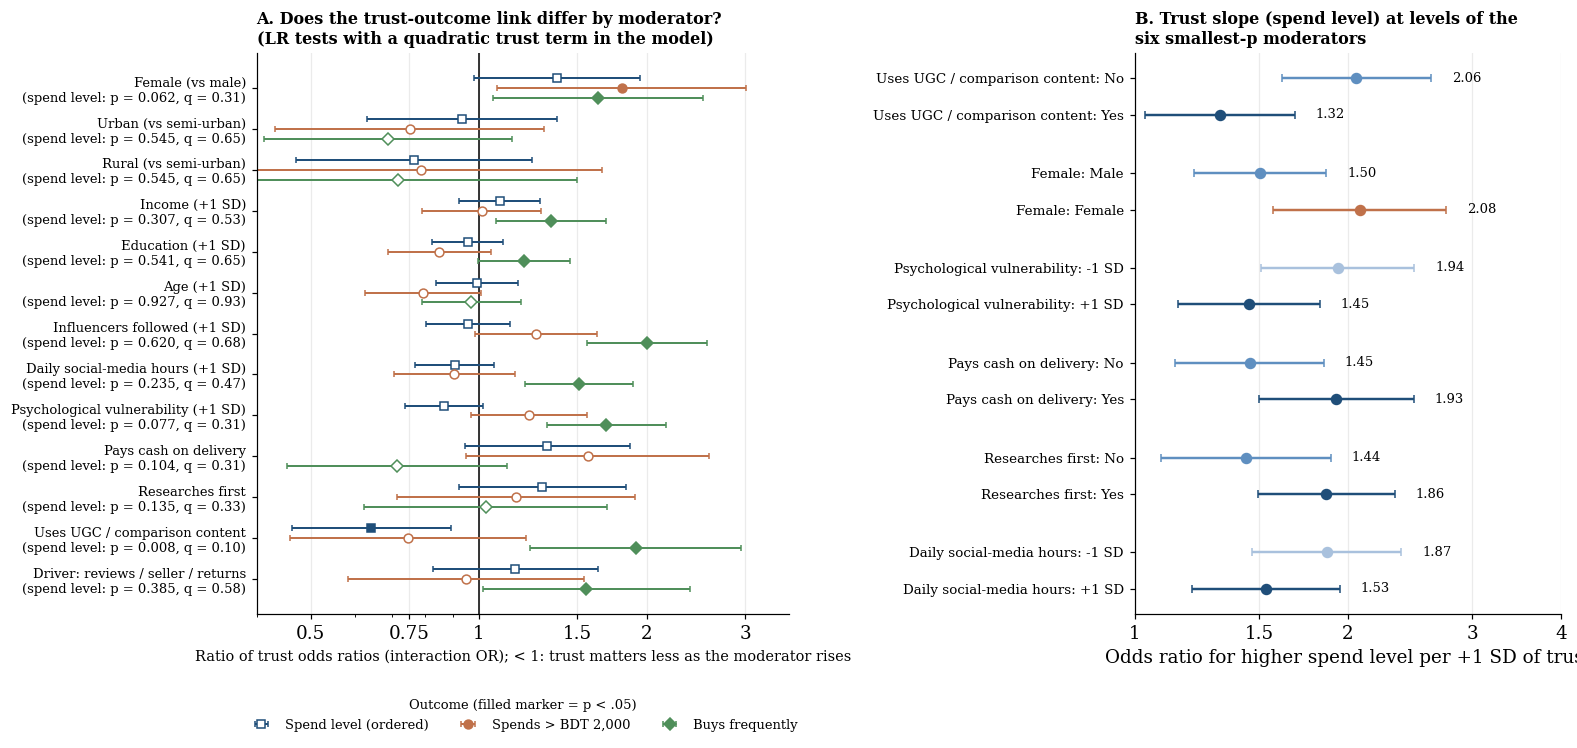


--- Key facts ---
Total effect of +1 SD trust on spend level (M2): +0.293 [+0.200, +0.390]  (0.24 SD of spend)
COD mediation (M2): a = -6.0 pp [-10.1, -1.5]; b = -0.19 [-0.36, -0.01]
  indirect = +0.011 [+0.000, +0.027] = 4% of total [0%, 10%]; direct = +0.282; rho* = -0.09
  M1: indirect +0.015 [+0.001, +0.035] = 4%
  M3: indirect +0.012 [-0.000, +0.029] = 4%
  logistic a-path (g-computation): indirect +0.011 [-0.000, +0.028]
Spends > BDT 2,000 (pp): total +6.7; indirect via COD +0.32 [-0.07, +0.95] = 5%
Parallel (four safeguards, M2): Pays cash on delivery +0.012 [+0.000, +0.030]; Researches first +0.001 [-0.004, +0.009]; Uses UGC / comparison content +0.011 [-0.002, +0.029]; Driver: reviews / seller / returns +0.000 [-0.005, +0.007]; all +0.024 = 8% of total
Parallel (safeguards + exposure, M1): Pays cash on delivery +0.013 [+0.001, +0.032]; Researches first +0.001 [-0.004, +0.009]; Uses UGC / comparison content +0.007 [-0.004, +0.024]; Driver: reviews / seller / returns +0.001 [-0

In [15]:
# ============================================================
# CELL 14 — Mediation (H4) and moderation (H5)   (Tables 16a-c, 17a-b; Figures 14-15)
# (run after Cells 6, 8, 11 and 13: re-uses model, SPECS, MAIN, smf, OrderedModel, the z-scores and the safeguard variables)
# ============================================================
import warnings; warnings.filterwarnings("ignore")
import statsmodels.api as sm
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.ticker import NullFormatter
from scipy import stats as _st
from statsmodels.stats.multitest import multipletests

B_BOOT = 5000                                   # bootstrap resamples for the linear mediation models
COV_M1 = ["Female", "Urban", "Rural", "z_Income", "z_Edu", "z_Age"]
COV_M2 = COV_M1 + ["z_NFollow", "z_SMhrs"]      # main specification (same as Cell 11)
COV_M3 = COV_M2 + ["z_Vuln"]
NEED = ["z_Trust", "Spend", "Spend2000", "FreqBuy", "COD", "ResH", "Pillar_UGC_CMP", "Pillar_rev_sell_ret"] + COV_M3
assert model[NEED].notna().all().all(), "missing values in the model sample"
SD_SPEND = model["Spend"].std()
fmt_p = lambda v: "<.001" if v < .001 else f"{v:.3f}"
MLAB = {"COD": "Pays cash on delivery", "ResH": "Researches first", "Pillar_UGC_CMP": "Uses UGC / comparison content", "Pillar_rev_sell_ret": "Driver: reviews / seller / returns",
        "z_NFollow": "Influencers followed (+1 SD)", "z_SMhrs": "Daily social-media hours (+1 SD)"}

# ---------- 1. mediation machinery (product of coefficients, non-parametric bootstrap) ----------
def _est(T, C, M, y):
    XA = np.column_stack([T, C]); coefM = np.linalg.lstsq(XA, M, rcond=None)[0]; coefY = np.linalg.lstsq(XA, y, rcond=None)[0]
    bt = np.linalg.lstsq(np.column_stack([T, M, C]), y, rcond=None)[0]; k = M.shape[1]
    return coefM[0], bt[1:1 + k], bt[0], coefY[0]                      # a (k), b (k), direct c', total c

def _rho(T, C, M, y):                                                   # residual correlation of mediator and outcome after trust + covariates
    XA = np.column_stack([T, C]); eM = M - XA @ np.linalg.lstsq(XA, M, rcond=None)[0]; eY = y - XA @ np.linalg.lstsq(XA, y, rcond=None)[0]
    return np.array([np.corrcoef(eM[:, j], eY)[0, 1] for j in range(M.shape[1])])

# product-of-coefficients mediation with a case-resampling bootstrap (percentile 95% CIs); also returns the % of the total effect mediated
def run_med(covs, meds, oc, yscale=1.0, B=B_BOOT, seed=14):
    T = model["z_Trust"].values; C = np.column_stack([np.ones(len(model))] + [model[c].values for c in covs]); M = model[meds].values.astype(float); y = model[oc].values.astype(float) * yscale
    a, b, cp, tot = _est(T, C, M, y); rho = _rho(T, C, M, y); rng = np.random.default_rng(seed); n = len(y); k = len(meds); draws = np.empty((B, 2 * k + 2))
    for r in range(B):
        i = rng.integers(0, n, n); A_, b_, cp_, tot_ = _est(T[i], C[i], M[i], y[i]); draws[r] = np.concatenate([A_, b_, [cp_, tot_]])
    A_d, b_d, cp_d, tot_d = draws[:, :k], draws[:, k:2 * k], draws[:, 2 * k], draws[:, 2 * k + 1]; ind_d = A_d * b_d; ind = a * b
    ci = lambda v: np.percentile(v, [2.5, 97.5])
    out = {"meds": meds, "a": a, "b": b, "ind": ind, "direct": cp, "total": tot, "rho": rho, "n_boot": B,
           "a_ci": [ci(A_d[:, j]) for j in range(k)], "b_ci": [ci(b_d[:, j]) for j in range(k)], "ind_ci": [ci(ind_d[:, j]) for j in range(k)],
           "pm": ind / tot, "pm_ci": [ci(ind_d[:, j] / tot_d) for j in range(k)], "direct_ci": ci(cp_d), "total_ci": ci(tot_d),
           "ind_sum": ind.sum(), "ind_sum_ci": ci(ind_d.sum(1)), "pm_sum": ind.sum() / tot, "pm_sum_ci": ci(ind_d.sum(1) / tot_d)}
    return out

# turns a mediation result into table rows (a, b, indirect effect, % of total, rho at which the indirect effect would be zero)
def med_rows(res, oc_lab, spec_lab, unit):
    rows = []
    for j, m in enumerate(res["meds"]):
        rows.append({"Outcome": oc_lab, "Model": spec_lab, "Mediator": MLAB[m], "a (trust -> mediator)": f"{res['a'][j]:+.3f} [{res['a_ci'][j][0]:+.3f}, {res['a_ci'][j][1]:+.3f}]",
                     f"b (mediator -> outcome, {unit})": f"{res['b'][j]:+.2f} [{res['b_ci'][j][0]:+.2f}, {res['b_ci'][j][1]:+.2f}]",
                     f"Indirect a x b ({unit})": f"{res['ind'][j]:+.3f} [{res['ind_ci'][j][0]:+.3f}, {res['ind_ci'][j][1]:+.3f}]",
                     "% of total effect": f"{res['pm'][j] * 100:.0f}% [{res['pm_ci'][j][0] * 100:.0f}, {res['pm_ci'][j][1] * 100:.0f}]", "rho at which indirect = 0": f"{res['rho'][j]:+.2f}"})
    if len(res["meds"]) > 1:
        rows.append({"Outcome": oc_lab, "Model": spec_lab, "Mediator": "All mediators combined", "a (trust -> mediator)": "", f"b (mediator -> outcome, {unit})": "",
                     f"Indirect a x b ({unit})": f"{res['ind_sum']:+.3f} [{res['ind_sum_ci'][0]:+.3f}, {res['ind_sum_ci'][1]:+.3f}]",
                     "% of total effect": f"{res['pm_sum'] * 100:.0f}% [{res['pm_sum_ci'][0] * 100:.0f}, {res['pm_sum_ci'][1] * 100:.0f}]", "rho at which indirect = 0": ""})
    rows.append({"Outcome": oc_lab, "Model": spec_lab, "Mediator": "Direct effect of trust (c')", "a (trust -> mediator)": "", f"b (mediator -> outcome, {unit})": "",
                 f"Indirect a x b ({unit})": f"{res['direct']:+.3f} [{res['direct_ci'][0]:+.3f}, {res['direct_ci'][1]:+.3f}]", "% of total effect": "", "rho at which indirect = 0": ""})
    rows.append({"Outcome": oc_lab, "Model": spec_lab, "Mediator": "Total effect of trust (c)", "a (trust -> mediator)": "", f"b (mediator -> outcome, {unit})": "",
                 f"Indirect a x b ({unit})": f"{res['total']:+.3f} [{res['total_ci'][0]:+.3f}, {res['total_ci'][1]:+.3f}]", "% of total effect": "", "rho at which indirect = 0": ""})
    return rows

print(f"Mediation: linear product-of-coefficients models, {B_BOOT:,} bootstrap resamples, trust scaled +1 SD, n = {len(model)}")
print("  Spend = 1-6 ordinal level treated as numeric (OLS); Spend2000 = linear-probability model (units = percentage points)\n")

# ---------- 2. H4 focal test: COD as the single mediator, three covariate sets ----------
R = {}
R["Spend", "M1"] = run_med(COV_M1, ["COD"], "Spend", seed=1); R["Spend", "M2"] = run_med(COV_M2, ["COD"], "Spend", seed=2); R["Spend", "M3"] = run_med(COV_M3, ["COD"], "Spend", seed=3)
R["Spend2000", "M1"] = run_med(COV_M1, ["COD"], "Spend2000", 100, seed=4); R["Spend2000", "M2"] = run_med(COV_M2, ["COD"], "Spend2000", 100, seed=5); R["Spend2000", "M3"] = run_med(COV_M3, ["COD"], "Spend2000", 100, seed=6)

# sensitivity: logistic a-path (g-computation: average change in P(COD) for +1 SD trust, times the OLS b-path), M2, 1,500 resamples
def gcomp_cod(df):
    X = sm.add_constant(df[["z_Trust"] + COV_M2]); lg = sm.Logit(df["COD"], X).fit(disp=0); X1 = X.copy(); X1["z_Trust"] += 1
    da = (lg.predict(X1) - lg.predict(X)).mean(); ols = sm.OLS(df["Spend"], sm.add_constant(df[["z_Trust", "COD"] + COV_M2])).fit()
    return da, ols.params["COD"], da * ols.params["COD"]
gp = gcomp_cod(model); rng = np.random.default_rng(77); gb = np.array([gcomp_cod(model.iloc[rng.integers(0, len(model), len(model))]) for _ in range(1500)])
g_ind_ci = np.percentile(gb[:, 2], [2.5, 97.5]); g_a_ci = np.percentile(gb[:, 0], [2.5, 97.5])

rows = []
for oc, lab, unit in [("Spend", "Monthly spend level (1-6)", "levels"), ("Spend2000", "Spends > BDT 2,000 (pp)", "pp")]:
    for sp, sl in [("M1", "M1 demographics"), ("M2", "M2 + exposure (main)"), ("M3", "M3 + vulnerability")]:
        r = R[oc, sp]; tot = f"{r['total']:+.3f} [{r['total_ci'][0]:+.3f}, {r['total_ci'][1]:+.3f}]"; di = f"{r['direct']:+.3f} [{r['direct_ci'][0]:+.3f}, {r['direct_ci'][1]:+.3f}]"
        rows.append({"Outcome": lab, "Model": sl, "a: trust -> COD": f"{r['a'][0]:+.3f} [{r['a_ci'][0][0]:+.3f}, {r['a_ci'][0][1]:+.3f}]", "b: COD -> outcome (levels / pp)": f"{r['b'][0]:+.2f} [{r['b_ci'][0][0]:+.2f}, {r['b_ci'][0][1]:+.2f}]",
                     "Indirect via COD (a x b)": f"{r['ind'][0]:+.3f} [{r['ind_ci'][0][0]:+.3f}, {r['ind_ci'][0][1]:+.3f}]", "% of total": f"{r['pm'][0] * 100:.0f}% [{r['pm_ci'][0][0] * 100:.0f}, {r['pm_ci'][0][1] * 100:.0f}]",
                     "Direct (c')": di, "Total (c)": tot, "rho at which indirect = 0": f"{r['rho'][0]:+.2f}"})
rows.append({"Outcome": "Monthly spend level (1-6)", "Model": "M2, logistic a-path (g-computation)", "a: trust -> COD": f"{gp[0]:+.3f} [{g_a_ci[0]:+.3f}, {g_a_ci[1]:+.3f}]", "b: COD -> outcome (levels / pp)": f"{gp[1]:+.2f}",
             "Indirect via COD (a x b)": f"{gp[2]:+.3f} [{g_ind_ci[0]:+.3f}, {g_ind_ci[1]:+.3f}]", "% of total": f"{gp[2] / R['Spend', 'M2']['total'] * 100:.0f}%", "Direct (c')": "", "Total (c)": "", "rho at which indirect = 0": ""})
T16a = pd.DataFrame(rows); save_table(T16a.set_index(["Outcome", "Model"]), "Table16a_mediation_COD",
        f"H4: does cash on delivery carry part of the trust-spending association? Effects per +1 SD of trust (n = {len(model)}); percentile 95% CI from {B_BOOT:,} bootstrap resamples. a is in probability units; rho = unmeasured mediator-outcome error correlation that would reduce the indirect effect to zero")

# ---------- 3. parallel mediators: the four safeguards (M2), and safeguards + exposure (M1) ----------
SAFE4 = ["COD", "ResH", "Pillar_UGC_CMP", "Pillar_rev_sell_ret"]; EXPO = ["z_NFollow", "z_SMhrs"]
R["Spend", "par4"] = run_med(COV_M2, SAFE4, "Spend", seed=11); R["Spend2000", "par4"] = run_med(COV_M2, SAFE4, "Spend2000", 100, seed=12)
R["Spend", "par6"] = run_med(COV_M1, SAFE4 + EXPO, "Spend", seed=13); R["Spend2000", "par6"] = run_med(COV_M1, SAFE4 + EXPO, "Spend2000", 100, seed=14)
rows = med_rows(R["Spend", "par4"], "Monthly spend level (1-6)", "M2: four safeguards", "levels") + med_rows(R["Spend2000", "par4"], "Spends > BDT 2,000 (pp)", "M2: four safeguards", "pp")
T16b = pd.DataFrame(rows); save_table(T16b.set_index(["Outcome", "Model", "Mediator"]), "Table16b_parallel_safeguards", "Parallel mediation: four risk-containment safeguards entered together (M2 covariates incl. exposure), per +1 SD of trust; percentile 95% CI from bootstrap")
rows = med_rows(R["Spend", "par6"], "Monthly spend level (1-6)", "M1: safeguards + exposure", "levels") + med_rows(R["Spend2000", "par6"], "Spends > BDT 2,000 (pp)", "M1: safeguards + exposure", "pp")
T16c = pd.DataFrame(rows); save_table(T16c.set_index(["Outcome", "Model", "Mediator"]), "Table16c_safeguards_vs_exposure", "Competing paths: safeguards AND exposure (influencers followed, daily hours) treated as parallel mediators (M1 covariates). The direction of the trust-exposure link is not identified, so read the exposure rows as exploratory")

# ---------- 4. Figure 14: path diagram (A) and indirect effects (B) ----------
r = R["Spend", "M2"]; fig = plt.figure(figsize=(14.6, 6.9)); gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.15], wspace=.50)
ax = fig.add_subplot(gs[0]); ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off")
def box(x, y, w, h, txt, fc):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.05,rounding_size=0.25", fc=fc, ec="#333333", lw=1.2)); ax.text(x, y, txt, ha="center", va="center", fontsize=10.5, fontweight="bold")
box(1.7, 3.2, 2.8, 1.3, "Trust in\ninfluencers\n(+1 SD)", "#dbe7f3"); box(8.3, 3.2, 2.8, 1.3, "Monthly spend\nlevel (1-6)", "#f3e3d6"); box(5.0, 8.0, 3.1, 1.3, "Pays cash on\ndelivery (COD)", "#e4efdc")
def arrow(p, q, rad=0):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=18, lw=1.8, color="#333333", connectionstyle=f"arc3,rad={rad}", shrinkA=0, shrinkB=0))
arrow((2.6, 3.95), (4.0, 7.35)); arrow((6.0, 7.35), (7.4, 3.95)); arrow((3.2, 3.2), (6.8, 3.2))
ax.text(2.2, 6.0, f"a = {r['a'][0] * 100:+.1f} pp\n[{r['a_ci'][0][0] * 100:+.1f}, {r['a_ci'][0][1] * 100:+.1f}]", ha="right", va="center", fontsize=9.5)
ax.text(7.8, 6.0, f"b = {r['b'][0]:+.2f} levels\n[{r['b_ci'][0][0]:+.2f}, {r['b_ci'][0][1]:+.2f}]", ha="left", va="center", fontsize=9.5)
ax.text(5.0, 3.45, f"direct c' = {r['direct']:+.2f}\n[{r['direct_ci'][0]:+.2f}, {r['direct_ci'][1]:+.2f}]", ha="center", va="bottom", fontsize=9.3)
ax.text(5.0, 2.95, f"total c = {r['total']:+.2f}\n[{r['total_ci'][0]:+.2f}, {r['total_ci'][1]:+.2f}]", ha="center", va="top", fontsize=9.3, color="#555555")
ax.text(5.0, 0.7, f"Indirect via COD (a x b) = {r['ind'][0]:+.3f} [{r['ind_ci'][0][0]:+.3f}, {r['ind_ci'][0][1]:+.3f}]\n= {r['pm'][0] * 100:.0f}% of the total effect [{r['pm_ci'][0][0] * 100:.0f}%, {r['pm_ci'][0][1] * 100:.0f}%]",
        ha="center", va="center", fontsize=9.6, fontweight="bold", bbox=dict(boxstyle="round,pad=0.4", fc="#f7f7f7", ec="#999999"))
ax.set_title("A. Single-mediator model (M2)", loc="left", fontsize=11, fontweight="bold")
ax = fig.add_subplot(gs[1])
# rows of panel B: (label, mediation result, mediator index, colour); 'hdr' rows are group headings
rowsB = [("hdr", "COD as the single mediator (M2)"), ("COD", R["Spend", "M2"], 0, "#1f4e79"),
         ("hdr", "Four safeguards together (M2)"), ("COD", R["Spend", "par4"], 0, "#1f4e79"), ("Researches first", R["Spend", "par4"], 1, "#5f8fc0"), ("UGC / comparison content", R["Spend", "par4"], 2, "#5f8fc0"), ("Driver: reviews / seller / returns", R["Spend", "par4"], 3, "#5f8fc0"),
         ("hdr", "Safeguards + exposure (M1)"), ("COD", R["Spend", "par6"], 0, "#1f4e79"), ("Researches first", R["Spend", "par6"], 1, "#5f8fc0"), ("UGC / comparison content", R["Spend", "par6"], 2, "#5f8fc0"), ("Driver: reviews / seller / returns", R["Spend", "par6"], 3, "#5f8fc0"),
         ("Influencers followed", R["Spend", "par6"], 4, "#c0714a"), ("Daily social-media hours", R["Spend", "par6"], 5, "#c0714a")]
y = 0; yt = []; yl = []; hdrs = []; real = [v for v in rowsB if v[0] != "hdr"]; xmin = min(v[1]["ind_ci"][v[2]][0] for v in real); xmax = max(v[1]["ind_ci"][v[2]][1] for v in real); span = xmax - xmin
for it in rowsB:
    if it[0] == "hdr": y += .35; hdrs.append((y, it[1])); y += .9; continue
    lab, rr, j, col = it; est_, lo, hi = rr["ind"][j], *rr["ind_ci"][j]
    ax.errorbar(est_, y, xerr=[[est_ - lo], [hi - est_]], fmt="s", color=col, ms=6.5, capsize=2.5, lw=1.7); ax.text(xmax + .05 * span, y, f"{est_:+.3f} [{lo:+.3f}, {hi:+.3f}]  {rr['pm'][j] * 100:.0f}%", va="center", fontsize=8.6, color="#333333")
    yt.append(y); yl.append(lab); y += 1
for yh, th in hdrs: ax.text(xmin - .08 * span, yh, th, fontsize=8.8, fontstyle="italic", fontweight="bold", color="#555555", va="center")
ax.axvline(0, color="black", lw=1); ax.set_yticks(yt); ax.set_yticklabels(yl, fontsize=9.5); ax.set_ylim(y - .3, -.35); ax.set_xlim(xmin - .08 * span, xmax + .05 * span); ax.grid(axis="x", alpha=.25)
ax.set_xlabel("Indirect effect of +1 SD trust on spend level (levels of the 1-6 scale)\nlabels: estimate [95% CI]  % of total effect")
ax.set_title("B. Indirect effects of trust on spend level", loc="left", fontsize=11, fontweight="bold")
CAPTION = (f"Figure 14. Mediation of the trust-spending association (n = {len(model)}; {B_BOOT:,} bootstrap resamples)")
fig.subplots_adjust(left=.02, right=.82, top=.9, bottom=.13); save_fig(fig, "Fig14_mediation", CAPTION); plt.show()

# ---------- 5. H5 moderation: does the trust-spending link differ by who the consumer is or how they protect themselves? ----------
M2_TERMS = SPECS[MAIN].split(" + ")
MODS = [("Female (vs male)", ["Female"], "bin"), ("Residence (urban / rural vs semi-urban)", ["Urban", "Rural"], "cat"), ("Income (+1 SD)", ["z_Income"], "cont"), ("Education (+1 SD)", ["z_Edu"], "cont"), ("Age (+1 SD)", ["z_Age"], "cont"),
        ("Influencers followed (+1 SD)", ["z_NFollow"], "cont"), ("Daily social-media hours (+1 SD)", ["z_SMhrs"], "cont"), ("Psychological vulnerability (+1 SD)", ["z_Vuln"], "cont"),
        ("Pays cash on delivery", ["COD"], "bin"), ("Researches first", ["ResH"], "bin"), ("Uses UGC / comparison content", ["Pillar_UGC_CMP"], "bin"), ("Driver: reviews / seller / returns", ["Pillar_rev_sell_ret"], "bin")]
OUTS = [("Monthly spend level (ordered)", "Spend", "ord"), ("Spends > BDT 2,000", "Spend2000", "bin"), ("Buys frequently", "FreqBuy", "bin")]
# fits an outcome model: ordered logit or logit with the given terms
def fit_out(oc, kind, terms):
    rhs = " + ".join(terms)
    return (OrderedModel.from_formula(f"{oc} ~ 0 + {rhs}", data=model, distr="logit").fit(method="bfgs", disp=0, maxiter=2000) if kind == "ord" else smf.logit(f"{oc} ~ {rhs}", data=model).fit(disp=0))
model["zT2"] = model["z_Trust"] ** 2          # trust is centred, so the linear trust term is the slope at mean trust
rows = []; FITI = {}
for lab_o, oc, kind in OUTS:
    for lab_m, vs, typ in MODS:
        extra = [v for v in vs if v not in M2_TERMS]; icols = []
        for v in vs: model[f"zT_x_{v}"] = model["z_Trust"] * model[v]; icols.append(f"zT_x_{v}")
        # primary: interaction tested with a quadratic trust term in BOTH models, so that curvature is not mistaken for moderation
        f0 = fit_out(oc, kind, M2_TERMS + ["zT2"] + extra); f1 = fit_out(oc, kind, M2_TERMS + ["zT2"] + extra + icols); lr = 2 * (f1.llf - f0.llf); dfree = len(icols); p = _st.chi2.sf(lr, dfree); ci = f1.conf_int()
        # sensitivity: purely linear trust term
        g0 = fit_out(oc, kind, M2_TERMS + extra); g1 = fit_out(oc, kind, M2_TERMS + extra + icols); p_lin = _st.chi2.sf(2 * (g1.llf - g0.llf), dfree)
        FITI[oc, lab_m] = (f1, vs, icols, typ)
        for v, ic in zip(vs, icols):
            nm = lab_m if len(vs) == 1 else ("Urban (vs semi-urban)" if v == "Urban" else "Rural (vs semi-urban)")
            rows.append({"Outcome": lab_o, "oc": oc, "Moderator": nm, "mod_group": lab_m, "Trust x moderator OR": np.exp(f1.params[ic]), "lo": np.exp(ci.loc[ic, 0]), "hi": np.exp(ci.loc[ic, 1]), "LR chi2": lr, "df": dfree, "p": p, "p_lin": p_lin})
T17 = pd.DataFrame(rows)
# FDR over the 12 moderator tests within each outcome, and over all 36 tests
first = T17.drop_duplicates(["oc", "mod_group"]).copy(); first["q (FDR, 12 tests)"] = first.groupby("oc")["p"].transform(lambda s: pd.Series(multipletests(s, method="fdr_bh")[1], index=s.index))
first["q (FDR, all 36)"] = multipletests(first["p"], method="fdr_bh")[1]
T17 = T17.merge(first[["oc", "mod_group", "q (FDR, 12 tests)", "q (FDR, all 36)"]], on=["oc", "mod_group"])
show = pd.DataFrame({"Outcome": T17["Outcome"], "Moderator": T17["Moderator"], "Trust x moderator OR [95% CI]": T17.apply(lambda r_: f"{r_['Trust x moderator OR']:.2f} [{r_['lo']:.2f}, {r_['hi']:.2f}]", axis=1),
                     "LR chi2 (df)": T17.apply(lambda r_: f"{r_['LR chi2']:.2f} ({r_['df']})", axis=1), "p": T17["p"].map(fmt_p), "p (linear trust only)": T17["p_lin"].map(fmt_p), "q (12 tests)": T17["q (FDR, 12 tests)"].map(fmt_p), "q (all 36)": T17["q (FDR, all 36)"].map(fmt_p)})
save_table(show.set_index(["Outcome", "Moderator"]), "Table17a_moderation", f"H5: trust x moderator interactions on three outcomes (M2 + moderator, n = {len(model)}). OR = ratio of the trust odds ratio per +1 SD of trust for a +1 unit (SD or yes-vs-no) change in the moderator; p from likelihood-ratio tests with a quadratic trust term in both models (so curvature is not mistaken for moderation; the linear-only p is shown for comparison); BH-FDR over 12 moderators within outcome and over all 36 tests")

# ---------- 6. simple slopes of trust (at the mean of trust) for the moderators with the smallest p ----------
def simple_slopes(oc, k=6):
    prim = T17[T17.oc == oc].drop_duplicates("mod_group").sort_values("p"); top = list(prim.mod_group[:k]); out = []
    for lab_m in top:
        f1, vs, icols, typ = FITI[oc, lab_m]; cov = f1.cov_params(); b = f1.params
        if typ == "cat": levels = [("Semi-urban", {}), ("Urban", {"zT_x_Urban": 1}), ("Rural", {"zT_x_Rural": 1})]
        elif vs[0] == "Female": levels = [("Male", {}), ("Female", {icols[0]: 1})]
        elif typ == "bin": levels = [("No", {}), ("Yes", {icols[0]: 1})]
        else: levels = [("-1 SD", {icols[0]: -1}), ("+1 SD", {icols[0]: 1})]
        for lv, w in levels:
            names = ["z_Trust"] + list(w.keys()); wt = np.array([1.0] + list(w.values())); est_ = wt @ b[names].values; se_ = np.sqrt(wt @ cov.loc[names, names].values @ wt)
            out.append({"Moderator": lab_m, "Level": lv, "Trust OR per +1 SD": np.exp(est_), "lo": np.exp(est_ - 1.96 * se_), "hi": np.exp(est_ + 1.96 * se_)})
    return top, pd.DataFrame(out)
TOP, T17b = simple_slopes("Spend"); TOP_F, T17c = simple_slopes("FreqBuy")
save_table(T17b.round(2).set_index(["Moderator", "Level"]), "Table17b_simple_slopes_spend", "Trust-spend odds ratio (per +1 SD of trust at the mean of trust; ordered logit, M2 + trust squared) at levels of the six moderators with the smallest interaction p; Wald 95% CI")
save_table(T17c.round(2).set_index(["Moderator", "Level"]), "Table17c_simple_slopes_frequent_buying", "Trust-frequent buying odds ratio (per +1 SD of trust at the mean of trust; logit, M2 + trust squared) at levels of the six moderators with the smallest interaction p; Wald 95% CI")

# ---------- 7. Figure 15 ----------
P = T17[T17.oc == "Spend"].reset_index(drop=True); ORDER_ROWS = list(P["Moderator"])
fig, axes = plt.subplots(1, 2, figsize=(15.4, 7.4), gridspec_kw={"width_ratios": [1.25, 1], "wspace": .72})
ax = axes[0]; ax.axvline(1, color="black", lw=1); OC_STYLE = {"Spend": ("Spend level (ordered)", "#1f4e79", "s", -.24), "Spend2000": ("Spends > BDT 2,000", "#c0714a", "o", 0), "FreqBuy": ("Buys frequently", "#4f8f5a", "D", .24)}
for oc, (lab_o, col, mk, dy) in OC_STYLE.items():
    sub = T17[T17.oc == oc].set_index("Moderator").loc[ORDER_ROWS].reset_index()
    for i, r_ in sub.iterrows():
        filled = r_["p"] < .05
        ax.errorbar(r_["Trust x moderator OR"], i + dy, xerr=[[r_["Trust x moderator OR"] - r_["lo"]], [r_["hi"] - r_["Trust x moderator OR"]]], fmt=mk, color=col, mfc=(col if filled else "white"), ms=5.8, capsize=2, lw=1.3, label=lab_o if i == 0 else None)
ax.set_yticks(range(len(P))); ax.set_yticklabels([f"{r_['Moderator']}\n(spend level: p = {r_['p']:.3f}, q = {r_['q (FDR, 12 tests)']:.2f})" for _, r_ in P.iterrows()], fontsize=8.6); ax.invert_yaxis()
ax.set_xscale("log"); ax.set_xlim(.4, 3.6); ax.set_xticks([.5, .75, 1, 1.5, 2, 3]); ax.set_xticklabels(["0.5", "0.75", "1", "1.5", "2", "3"]); ax.xaxis.set_minor_formatter(NullFormatter())
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.13), ncol=3, fontsize=8.6, frameon=False, title="Outcome (filled marker = p < .05)", title_fontsize=8.6)
ax.set_xlabel("Ratio of trust odds ratios (interaction OR); < 1: trust matters less as the moderator rises", fontsize=9.5); ax.grid(axis="x", alpha=.25)
ax.set_title("A. Does the trust-outcome link differ by moderator?\n(LR tests with a quadratic trust term in the model)", loc="left", fontsize=10.5, fontweight="bold")
# panel B: trust slope (spend level) at each level of the six moderators with the smallest p-values
ax = axes[1]; ax.axvline(1, color="black", lw=1); y = 0; yt = []; yl = []; cols = {"No": "#5f8fc0", "Male": "#5f8fc0", "Semi-urban": "#5f8fc0", "-1 SD": "#a9c1dd", "Yes": "#1f4e79", "Female": "#c0714a", "Urban": "#1f4e79", "Rural": "#c0714a", "+1 SD": "#1f4e79"}
for k_, lab_m in enumerate(TOP):
    sub = T17b[T17b.Moderator == lab_m]
    for _, r_ in sub.iterrows():
        ax.errorbar(r_["Trust OR per +1 SD"], y, xerr=[[r_["Trust OR per +1 SD"] - r_["lo"]], [r_["hi"] - r_["Trust OR per +1 SD"]]], fmt="o", color=cols.get(r_["Level"], "#333333"), ms=6.5, capsize=2.5, lw=1.6)
        ax.text(r_["hi"] * 1.07, y, f"{r_['Trust OR per +1 SD']:.2f}", va="center", fontsize=8.6); yt.append(y); yl.append(f"{lab_m.replace(' (+1 SD)', '').replace(' (vs male)', '')}: {r_['Level']}"); y += 1
    y += .6
ax.set_yticks(yt); ax.set_yticklabels(yl, fontsize=8.8); ax.invert_yaxis(); ax.set_xscale("log"); ax.set_xlim(1, 4); ax.set_xticks([1, 1.5, 2, 3, 4]); ax.set_xticklabels(["1", "1.5", "2", "3", "4"]); ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("Odds ratio for higher spend level per +1 SD of trust"); ax.grid(axis="x", alpha=.25); ax.set_title("B. Trust slope (spend level) at levels of the\nsix smallest-p moderators", loc="left", fontsize=10.5, fontweight="bold")
CAPTION = (f"Figure 15. Moderation of the trust-spending association (ordered logit, M2, n = {len(model)})")
fig.subplots_adjust(left=.20, right=.97, top=.86, bottom=.17); save_fig(fig, "Fig15_moderation", CAPTION); plt.show()

# ---------- 8. key facts ----------
print("\n--- Key facts ---")
r = R["Spend", "M2"]
print(f"Total effect of +1 SD trust on spend level (M2): {r['total']:+.3f} [{r['total_ci'][0]:+.3f}, {r['total_ci'][1]:+.3f}]  ({r['total'] / SD_SPEND:.2f} SD of spend)")
print(f"COD mediation (M2): a = {r['a'][0] * 100:+.1f} pp [{r['a_ci'][0][0] * 100:+.1f}, {r['a_ci'][0][1] * 100:+.1f}]; b = {r['b'][0]:+.2f} [{r['b_ci'][0][0]:+.2f}, {r['b_ci'][0][1]:+.2f}]")
print(f"  indirect = {r['ind'][0]:+.3f} [{r['ind_ci'][0][0]:+.3f}, {r['ind_ci'][0][1]:+.3f}] = {r['pm'][0] * 100:.0f}% of total [{r['pm_ci'][0][0] * 100:.0f}%, {r['pm_ci'][0][1] * 100:.0f}%]; direct = {r['direct']:+.3f}; rho* = {r['rho'][0]:+.2f}")
for sp in ["M1", "M3"]: q = R["Spend", sp]; print(f"  {sp}: indirect {q['ind'][0]:+.3f} [{q['ind_ci'][0][0]:+.3f}, {q['ind_ci'][0][1]:+.3f}] = {q['pm'][0] * 100:.0f}%")
print(f"  logistic a-path (g-computation): indirect {gp[2]:+.3f} [{g_ind_ci[0]:+.3f}, {g_ind_ci[1]:+.3f}]")
q = R["Spend2000", "M2"]; print(f"Spends > BDT 2,000 (pp): total {q['total']:+.1f}; indirect via COD {q['ind'][0]:+.2f} [{q['ind_ci'][0][0]:+.2f}, {q['ind_ci'][0][1]:+.2f}] = {q['pm'][0] * 100:.0f}%")
for key, lab in [("par4", "four safeguards, M2"), ("par6", "safeguards + exposure, M1")]:
    q = R["Spend", key]; print(f"Parallel ({lab}): " + "; ".join(f"{MLAB[m]} {q['ind'][j]:+.3f} [{q['ind_ci'][j][0]:+.3f}, {q['ind_ci'][j][1]:+.3f}]" for j, m in enumerate(q['meds'])) + f"; all {q['ind_sum']:+.3f} = {q['pm_sum'] * 100:.0f}% of total")
print("\nModeration of the trust-spend link (primary outcome, ordered logit, quadratic trust term in model):")
for _, r_ in P.iterrows(): print(f"  {r_['Moderator']:<42s} int. OR {r_['Trust x moderator OR']:.2f} [{r_['lo']:.2f}, {r_['hi']:.2f}]  LR p = {r_['p']:.3f} (linear-only {r_['p_lin']:.3f}), q(12) = {r_['q (FDR, 12 tests)']:.3f}")
for lab_o, oc, _ in OUTS[1:]:
    s_ = T17[T17.oc == oc].drop_duplicates("mod_group").sort_values("p"); sig = s_[s_.p < .05]
    print(f"{lab_o}: {len(sig)} of {len(s_)} interactions with p < .05 (FDR q < .05: {int((s_['q (FDR, 12 tests)'] < .05).sum())}); " + "; ".join(f"{r_.Moderator} OR {r_['Trust x moderator OR']:.2f} (p = {r_.p:.3f})" for _, r_ in sig.iterrows()))
print("Frequent buying - trust OR per +1 SD at levels of the strongest moderators:"); print(T17c.round(2).to_string(index=False))
print(f"Across all 36 tests: {int((first.p < .05).sum())} with p < .05 (about {0.05 * len(first):.1f} expected by chance); {int((first['q (FDR, all 36)'] < .05).sum())} with FDR q < .05")
print("\nTable 16a:"); print(T16a.set_index(["Outcome", "Model"]).to_string())

## Cell 15 — Satisfaction (H6) and low-trust spenders (H7)
H6: does COD protect satisfaction when trust is low (interaction models, simple effects, mediation)? H7: among low-trust consumers, is spending better explained by exposure and engagement than by income (Firth models, block likelihood-ratio tests, bootstrap contrasts)?
**Outputs:** Tables 18a–18b and 19a–19c; Figures 16 and 17.

Tables 16b and 16c re-saved with merged unit columns (levels = 1-6 spend scale; pp = percentage points)


Table19a_satisfaction_by_trust_COD: Satisfaction (Q27, 1-5), % satisfied (4-5) and regret (Likert 1-5) by trust group and usual use of cash on delivery (n = 512)


n Satisfaction mean [95% CI] % satisfied [95% CI]  Regret mean
Trust group  Payment                                                                      
Low (1-2)    No COD       104          3.29 [3.12, 3.45]         41% [32, 51]         3.31
             Usually COD  154          3.71 [3.57, 3.84]         56% [49, 64]         3.23
Moderate (3) No COD        78          3.62 [3.45, 3.78]         69% [58, 78]         3.35
             Usually COD   90          3.70 [3.55, 3.85]         61% [51, 71]         3.52
High (4-5)   No COD        53          3.81 [3.45, 4.17]         70% [56, 80]         3.25
             Usually COD   33          3.88 [3.48, 4.27]         67% [50, 80]         3.27


Table19b_COD_effect_by_trust: H6: adjusted odds ratio for usual COD use (M2 covariates + trust + trust squared + trust x COD; n = 512) at three trust levels, and within the low-trust group; interaction tested by likelihood ratio, Holm over the 3 outcomes


OR [95% CI] for higher satisfaction / regret with COD Trust x COD interaction OR [95% CI] interaction p (Holm)
Outcome                     COD effect at                                                                                                                                
Satisfaction (1-5, ordered) Trust -1 SD                                                        1.98 [1.20, 3.26]                   0.68 [0.47, 0.99]        0.042 (0.083)
                            Mean trust                                                         1.35 [0.96, 1.90]                   0.68 [0.47, 0.99]        0.042 (0.083)
                            Trust +1 SD                                                        0.92 [0.56, 1.52]                   0.68 [0.47, 0.99]        0.042 (0.083)
                            Low-trust group only (n = 258)                                     1.60 [0.96, 2.66]                   0.68 [0.47, 0.99]        0.042 (0.083)
Satisfied (4-5)             Trust -1 SD                                                        1.43 [0.83, 2.47]                   0.72 [0.48, 1.06]        0.094 (0.094)
                            Mean trust                                                         1.02 [0.70, 1.50]                   0.72 [0.48, 1.06]        0.094 (0.094)
                            Trust +1 SD                                                        0.73 [0.43, 1.26]                   0.72 [0.48, 1.06]        0.094 (0.094)
                            Low-trust group only (n = 258)                                     1.34 [0.76, 2.38]                   0.72 [0.48, 1.06]        0.094 (0.094)
Regret (1-5, ordered)       Trust -1 SD                                                        0.66 [0.40, 1.07]                   1.53 [1.09, 2.15]        0.014 (0.043)
                            Mean trust                                                         1.00 [0.72, 1.40]                   1.53 [1.09, 2.15]        0.014 (0.043)
                            Trust +1 SD                                                        1.53 [0.96, 2.43]                   1.53 [1.09, 2.15]        0.014 (0.043)
                            Low-trust group only (n = 258)                                     0.74 [0.45, 1.21]                   1.53 [1.09, 2.15]        0.014 (0.043)


Table19c_mediation_satisfaction: Indirect effects of +1 SD of trust on satisfaction and regret through COD and the other safeguards (M2 covariates; 5,000 bootstrap resamples). A negative indirect effect with a positive total effect means the path offsets part of the gain


a (trust -> mediator) b (mediator -> outcome)  \
Outcome                       Model                    Mediator                                                                              
Satisfaction (1-5 points)     COD alone                Pays cash on delivery               -0.060 [-0.103, -0.015]    +0.16 [+0.00, +0.32]   
                                                       Direct / total effect of trust                                                        
Satisfied (percentage points) COD alone                Pays cash on delivery               -0.060 [-0.102, -0.015]    +0.40 [-8.81, +9.29]   
                                                       Direct / total effect of trust                                                        
Regret (1-5 points)           COD alone                Pays cash on delivery               -0.060 [-0.102, -0.016]    -0.00 [-0.18, +0.18]   
                                                       Direct / total effect of trust                                                        
Satisfaction (1-5 points)     Four safeguards together Pays cash on delivery               -0.060 [-0.103, -0.016]    +0.16 [+0.00, +0.31]   
                                                       Researches first                    +0.015 [-0.029, +0.058]    +0.32 [+0.17, +0.48]   
                                                       Uses UGC / comparison content       +0.038 [-0.007, +0.084]    +0.06 [-0.11, +0.23]   
                                                       Driver: reviews / seller / returns  -0.006 [-0.052, +0.040]    -0.03 [-0.19, +0.12]   
                                                       Direct / total effect of trust                                                        
Satisfied (percentage points) Four safeguards together Pays cash on delivery               -0.060 [-0.104, -0.017]    +0.39 [-8.50, +9.26]   
                                                       Researches first                    +0.015 [-0.028, +0.058]  +14.95 [+5.87, +23.84]   
                                                       Uses UGC / comparison content       +0.038 [-0.007, +0.084]    -0.03 [-9.10, +8.40]   
                                                       Driver: reviews / seller / returns  -0.006 [-0.051, +0.039]   +3.71 [-4.81, +12.26]   
                                                       Direct / total effect of trust                                                        

                                                                                                                                          Indirect a x b % of total effect rho at which indirect = 0  
Outcome                       Model                    Mediator                                                                                                                                       
Satisfaction (1-5 points)     COD alone                Pays cash on delivery                                                     -0.010 [-0.024, +0.000]      -9% [-58, 1]                     +0.09  
                                                       Direct / total effect of trust      direct +0.117 [+0.023, +0.207]; total +0.107 [+0.013, +0.198]                                              
Satisfied (percentage points) COD alone                Pays cash on delivery                                                     -0.024 [-0.645, +0.591]     -0% [-18, 17]                     +0.00  
                                                       Direct / total effect of trust      direct +5.479 [+0.893, +9.821]; total +5.456 [+0.856, +9.745]                                              
Regret (1-5 points)           COD alone                Pays cash on delivery                                                     +0.000 [-0.012, +0.012]    1% [-147, 128]                     -0.00  
                                                       Direct / total effect of trust      direct +0.006 [-0.089, +0.104]; total +0.006 [-0.088

saved figure: Fig16_satisfaction_COD
  suggested caption: Figure 16. Cash on delivery and satisfaction (n = 512); indirect effect of trust on satisfaction via COD = -0.010 [-0.024, +0.000] points


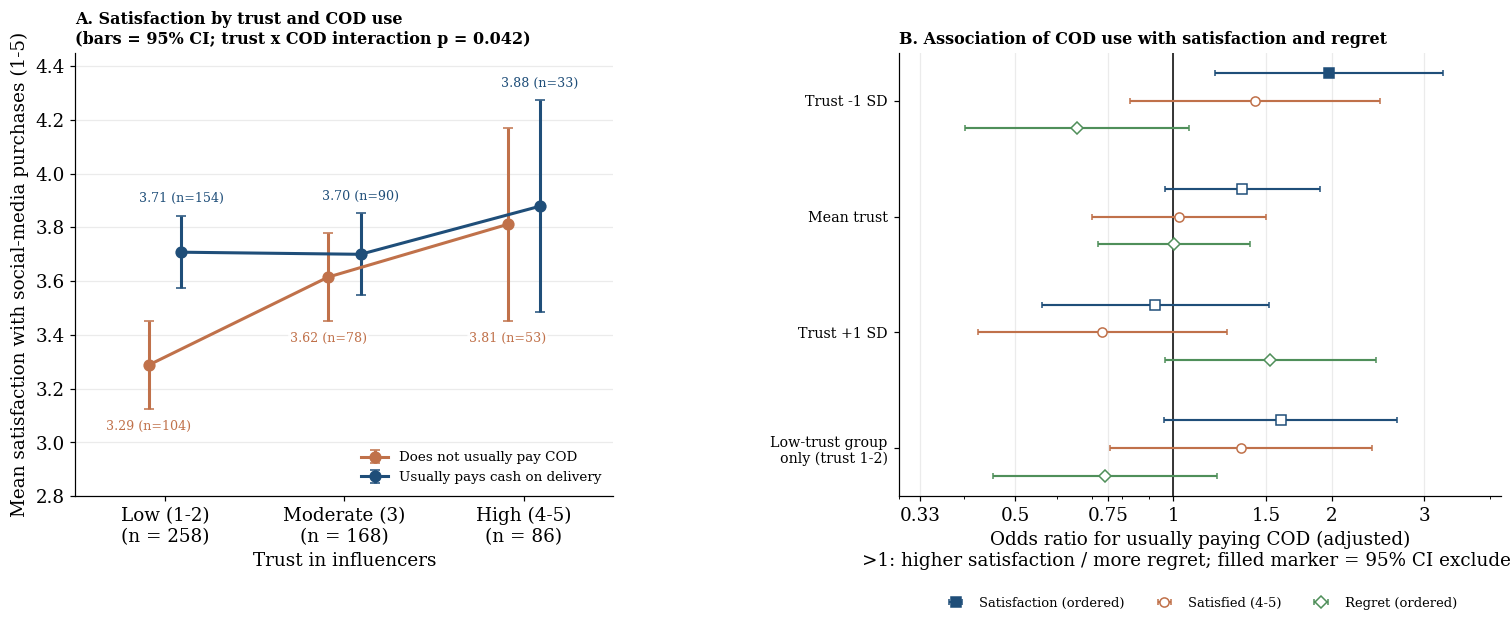

Low-trust group: n = 258; non-spenders = 68, spend >= BDT 500 = 125, spend > BDT 2,000 = 53; 11 predictors -> events per variable: spend >= BDT 500 = 11.4, any spend = 6.2, spend > BDT 2,000 = 4.8 -> Firth penalised logit used for all three

Table18b_low_trust_models: H7: adjusted odds ratios among low-trust respondents (trust 1-2, n = 258). Firth penalised logit (Wald CI from model-based SE) for the binary outcomes, ML ordered logit for spend level; all predictors entered together; continuous predictors standardised within the low-trust group


,Block,Spends >= BDT 500 (Firth) OR [95% CI],p Spend500,Any monthly spend (Firth) OR [95% CI],p P_spend,"Spends > BDT 2,000 (Firth) OR [95% CI]",p Spend2000,Spend level (ordered logit) OR [95% CI],p ordered,"Any spend, ML robust OR (pilot check)"
Predictor,,,,,,,,,,
Influencers followed (+1 SD),Exposure,"1.60 [1.18, 2.17]",0.002,"2.38 [1.61, 3.52]",<.001,"1.74 [1.16, 2.60]",0.007,"2.02 [1.53, 2.65]",<.001,"2.54 [1.54, 4.17]"
Daily social-media hours (+1 SD),Exposure,"1.59 [1.15, 2.19]",0.005,"1.03 [0.73, 1.44]",0.883,"1.45 [0.93, 2.24]",0.097,"1.24 [0.96, 1.60]",0.102,"1.02 [0.72, 1.46]"
Pays cash on delivery,Engagement & safeguards,"0.44 [0.24, 0.80]",0.007,"0.91 [0.45, 1.83]",0.785,"0.30 [0.14, 0.64]",0.002,"0.49 [0.30, 0.80]",0.005,"0.90 [0.44, 1.86]"
Researches first,Engagement & safeguards,"0.79 [0.44, 1.44]",0.443,"0.82 [0.41, 1.67]",0.589,"0.69 [0.32, 1.45]",0.324,"0.82 [0.51, 1.33]",0.431,"0.81 [0.40, 1.68]"
Uses UGC / comparison content,Engagement & safeguards,"1.86 [1.04, 3.33]",0.036,"4.64 [2.32, 9.27]",<.001,"1.88 [0.87, 4.06]",0.107,"2.53 [1.56, 4.09]",<.001,"5.11 [2.47, 10.58]"
Income (+1 SD),Socio-economic,"1.17 [0.83, 1.67]",0.374,"0.90 [0.60, 1.36]",0.619,"2.32 [1.51, 3.55]",<.001,"1.42 [1.05, 1.92]",0.021,"0.89 [0.60, 1.32]"
Education (+1 SD),Socio-economic,"1.11 [0.80, 1.55]",0.542,"1.27 [0.89, 1.83]",0.191,"1.18 [0.77, 1.80]",0.455,"1.19 [0.91, 1.57]",0.207,"1.29 [0.90, 1.86]"
Age (+1 SD),Demographics,"1.68 [1.17, 2.40]",0.005,"1.22 [0.82, 1.83]",0.320,"1.07 [0.69, 1.66]",0.768,"1.21 [0.92, 1.59]",0.171,"1.25 [0.86, 1.80]"
Female (vs male),Demographics,"0.72 [0.40, 1.31]",0.282,"0.53 [0.27, 1.04]",0.063,"0.73 [0.32, 1.63]",0.440,"0.70 [0.43, 1.14]",0.157,"0.51 [0.25, 1.05]"



Table18c_block_contributions: Unique contribution of each predictor block to spending among low-trust respondents (likelihood-ratio chi-square for dropping the block)


chi2 (df)      p
Block                   Outcome                                
Exposure                Spends >= BDT 500      33.56 (2)  <.001
                        Any monthly spend      32.95 (2)  <.001
                        Spend level (ordered)  40.34 (2)  <.001
Engagement & safeguards Spends >= BDT 500      20.96 (3)  <.001
                        Any monthly spend      30.29 (3)  <.001
                        Spend level (ordered)  24.18 (3)  <.001
Socio-economic          Spends >= BDT 500       8.75 (2)  0.013
                        Any monthly spend       8.37 (2)  0.015
                        Spend level (ordered)   9.59 (2)  0.008
Demographics            Spends >= BDT 500      22.49 (4)  <.001
                        Any monthly spend      14.94 (4)  0.005
                        Spend level (ordered)   5.34 (4)  0.254


Table18d_exposure_vs_income: H7 direct comparison: are the exposure coefficients larger than the income coefficient? Firth log-odds differences, 2,000 bootstrap resamples within the low-trust group


Difference [95% bootstrap CI] Ratio of odds ratios
Outcome           Contrast (difference in log-odds per within-group SD)                                                   
Spends >= BDT 500 Influencers followed minus income                              +0.31 [-0.14, +0.81]    1.37 [0.87, 2.25]
                  Daily hours minus income                                       +0.30 [-0.13, +0.79]    1.35 [0.87, 2.19]
                  Mean of the two exposure measures minus income                 +0.31 [-0.07, +0.72]    1.36 [0.93, 2.05]
Any monthly spend Influencers followed minus income                              +0.97 [+0.34, +1.83]    2.64 [1.40, 6.26]
                  Daily hours minus income                                       +0.13 [-0.38, +0.71]    1.14 [0.68, 2.03]
                  Mean of the two exposure measures minus income                 +0.55 [+0.07, +1.15]    1.73 [1.07, 3.15]


Table18a_distrusting_spenders_profile: Profile of low-trust respondents (n = 258) who do and do not spend monthly through social media (Mann-Whitney / Fisher exact tests; FDR over 12 comparisons)


,Spenders (n = 190),Non-spenders (n = 68),Difference (d for scales; proportion difference for yes/no),p,q (FDR)
Characteristic,,,,,
Influencers followed (1-5 code),2.84 (1.00),2.01 (1.13),0.78,<.001,<.001
Daily social-media hours (1-5 code),2.98 (0.95),2.62 (1.29),0.32,0.009,0.021
Income (1-5 code),2.21 (1.22),2.06 (1.23),0.12,0.357,0.402
Education (1-6 code),3.86 (1.08),3.43 (1.15),0.39,0.009,0.021
Age (1-5 code),2.53 (1.17),2.46 (1.15),0.06,0.704,0.704
Female,32%,38%,-0.07,0.369,0.402
Urban,56%,71%,-0.14,0.044,0.088
Rural,16%,10%,0.06,0.318,0.402
Usually pays COD,57%,68%,-0.11,0.150,0.224


saved figure: Fig17_low_trust_spending
  suggested caption: Figure 17. Spending among low-trust consumers Exposure minus income (log-odds, mean of the two measures): spend >= BDT 500 +0.31 [-0.07, +0.72]; any spend +0.55 [+0.07, +1.15]


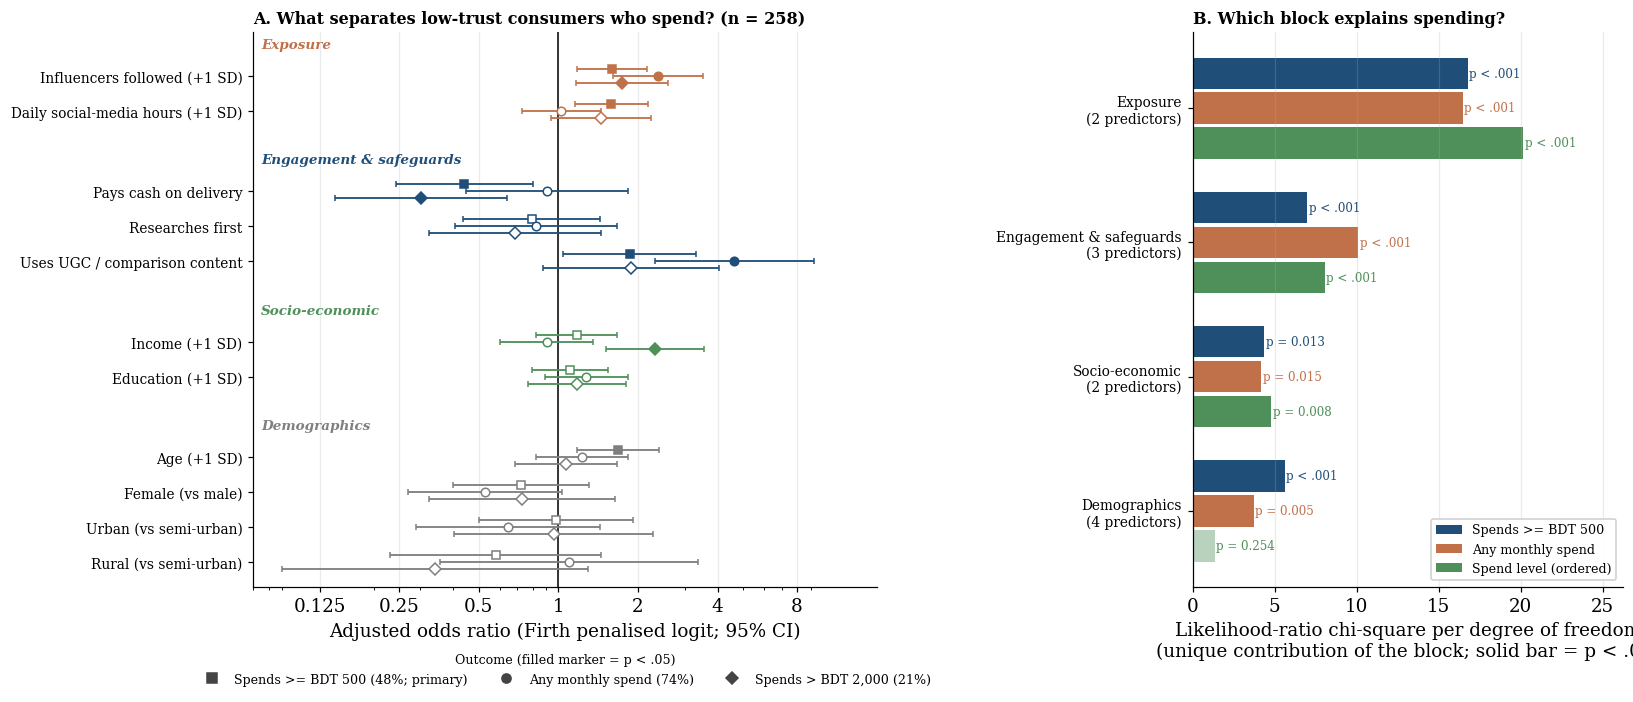


--- Key facts: H6 (satisfaction) ---
  Low (1-2)     satisfaction: no COD 3.29 (41% satisfied) vs COD 3.71 (56% satisfied)
  Moderate (3)  satisfaction: no COD 3.62 (69% satisfied) vs COD 3.70 (61% satisfied)
  High (4-5)    satisfaction: no COD 3.81 (70% satisfied) vs COD 3.88 (67% satisfied)
  Trust x COD on Satisfaction (1-5, ordered): OR 0.68 [0.47, 0.99], LR p = 0.042 (Holm 0.083)
  Trust x COD on Satisfied (4-5): OR 0.72 [0.48, 1.06], LR p = 0.094 (Holm 0.094)
  Trust x COD on Regret (1-5, ordered): OR 1.53 [1.09, 2.15], LR p = 0.014 (Holm 0.043)
  COD effect on Satisfaction (1-5, ordered)  at Trust -1 SD                       : OR 1.98 [1.20, 3.26]
  COD effect on Satisfaction (1-5, ordered)  at Mean trust                        : OR 1.35 [0.96, 1.90]
  COD effect on Satisfaction (1-5, ordered)  at Trust +1 SD                       : OR 0.92 [0.56, 1.52]
  COD effect on Satisfaction (1-5, ordered)  at Low-trust group only (n = 258)    : OR 1.60 [0.96, 2.66]
  COD effect on Sati

In [16]:
# ============================================================
# CELL 15 — Satisfaction (H6) and distrusting spenders (H7)   (Tables 18a-b, 19a-c; Figures 16-17)
# (run after Cells 6, 8, 11, 13 and 14: re-uses model, SPECS, MAIN, smf, OrderedModel, run_med, fit_out, COV_M2, M2_TERMS, T16b, T16c)
# ============================================================
import warnings; warnings.filterwarnings("ignore")
from scipy.special import expit
from scipy import stats as _st
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
from matplotlib.ticker import NullFormatter

GRS = ["Low (1-2)", "Moderate (3)", "High (4-5)"]
fmt_p = lambda v: "<.001" if v < .001 else f"{v:.3f}"
model["zT2"] = model["z_Trust"] ** 2; model["zT_x_COD"] = model["z_Trust"] * model["COD"]

# ---------- 0. tidy Tables 16b / 16c: the unit-specific column names left blank 'levels' and 'pp' twin columns ----------
def _merge_units(T):
    T = T.copy()
    for stem, new in [("b (mediator -> outcome", "b (mediator -> outcome; levels or pp)"), ("Indirect a x b", "Indirect a x b (levels or pp)")]:
        cols = [c for c in T.columns if c.startswith(stem)]; merged = T[cols].replace("", np.nan).bfill(axis=1).iloc[:, 0].fillna("")
        T = T.drop(columns=cols); T[new] = merged
    return T[["Outcome", "Model", "Mediator", "a (trust -> mediator)", "b (mediator -> outcome; levels or pp)", "Indirect a x b (levels or pp)", "% of total effect", "rho at which indirect = 0"]].set_index(["Outcome", "Model", "Mediator"])
for T_, nm in [(T16b, "Table16b_parallel_safeguards"), (T16c, "Table16c_safeguards_vs_exposure")]:
    M_ = _merge_units(T_); M_.to_csv(f"{OUT}/tables/{nm}.csv"); TABLES[nm] = (TABLES[nm][0], M_)
print("Tables 16b and 16c re-saved with merged unit columns (levels = 1-6 spend scale; pp = percentage points)\n")

# ============================================================
# PART A — H6: does cash on delivery protect satisfaction when trust is low?
# ============================================================
OUT6 = [("Satisfaction (1-5, ordered)", "Satisf", "ord"), ("Satisfied (4-5)", "Satisfied", "bin"), ("Regret (1-5, ordered)", "regret", "ord")]
# ---- A1. descriptives: satisfaction and regret by trust group x COD ----
rows = []
for g_ in GRS:
    for c_, cl in [(0, "No COD"), (1, "Usually COD")]:
        s = model[(model.TrustG == g_) & (model.COD == c_)]; n = len(s); t_ = _st.t.ppf(.975, n - 1); lo, hi = proportion_confint(s.Satisfied.sum(), n, method="wilson")
        rows.append({"Trust group": g_, "Payment": cl, "n": n, "Satisfaction mean": s.Satisf.mean(), "lo": s.Satisf.mean() - t_ * s.Satisf.std() / np.sqrt(n), "hi": s.Satisf.mean() + t_ * s.Satisf.std() / np.sqrt(n),
                     "% satisfied": s.Satisfied.mean() * 100, "% lo": lo * 100, "% hi": hi * 100, "Regret mean": s.regret.mean()})
T19a = pd.DataFrame(rows)
save_table(T19a.assign(**{"Satisfaction mean [95% CI]": T19a.apply(lambda r: f"{r['Satisfaction mean']:.2f} [{r['lo']:.2f}, {r['hi']:.2f}]", axis=1), "% satisfied [95% CI]": T19a.apply(lambda r: f"{r['% satisfied']:.0f}% [{r['% lo']:.0f}, {r['% hi']:.0f}]", axis=1)})
           [["Trust group", "Payment", "n", "Satisfaction mean [95% CI]", "% satisfied [95% CI]", "Regret mean"]].round(2).set_index(["Trust group", "Payment"]), "Table19a_satisfaction_by_trust_COD",
           f"Satisfaction (Q27, 1-5), % satisfied (4-5) and regret (Likert 1-5) by trust group and usual use of cash on delivery (n = {len(model)})")

# ---- A2. trust x COD interaction (quadratic trust term in both models) and COD effect at three trust levels + within the low-trust group ----
SIMPLE = []; INT = []
for lab_o, oc, kind in OUT6:
    base = M2_TERMS + ["zT2", "COD"]; f0 = fit_out(oc, kind, base); f1 = fit_out(oc, kind, base + ["zT_x_COD"]); lr = 2 * (f1.llf - f0.llf); p = _st.chi2.sf(lr, 1); ci_i = f1.conf_int().loc["zT_x_COD"]
    INT.append({"Outcome": lab_o, "oc": oc, "Trust x COD OR": np.exp(f1.params["zT_x_COD"]), "lo": np.exp(ci_i[0]), "hi": np.exp(ci_i[1]), "LR chi2 (1 df)": lr, "p": p})
    cov = f1.cov_params(); b = f1.params
    for lab_t, tv in [("Trust -1 SD", -1), ("Mean trust", 0), ("Trust +1 SD", 1)]:
        w = np.array([1.0, tv]); est_ = w @ b[["COD", "zT_x_COD"]].values; se_ = np.sqrt(w @ cov.loc[["COD", "zT_x_COD"], ["COD", "zT_x_COD"]].values @ w)
        SIMPLE.append({"Outcome": lab_o, "oc": oc, "Level": lab_t, "COD OR": np.exp(est_), "lo": np.exp(est_ - 1.96 * se_), "hi": np.exp(est_ + 1.96 * se_)})
    LT_ = model[model.TrustG == "Low (1-2)"]; rhs = "z_Trust + COD + Female + Urban + Rural + z_Income + z_Edu + z_Age + z_NFollow + z_SMhrs"
    fs = (OrderedModel.from_formula(f"{oc} ~ 0 + {rhs}", data=LT_, distr="logit").fit(method="bfgs", disp=0, maxiter=2000) if kind == "ord" else smf.logit(f"{oc} ~ {rhs}", data=LT_).fit(disp=0, cov_type="HC1")); ci_s = fs.conf_int().loc["COD"]
    SIMPLE.append({"Outcome": lab_o, "oc": oc, "Level": f"Low-trust group only (n = {len(LT_)})", "COD OR": np.exp(fs.params["COD"]), "lo": np.exp(ci_s[0]), "hi": np.exp(ci_s[1]), "p_sub": fs.pvalues["COD"]})
T19b_int = pd.DataFrame(INT); T19b_int["p (Holm, 3 outcomes)"] = multipletests(T19b_int["p"], method="holm")[1]; T19b_s = pd.DataFrame(SIMPLE)
tab = []
for _, r_ in T19b_s.iterrows():
    ii = T19b_int[T19b_int.oc == r_.oc].iloc[0]
    tab.append({"Outcome": r_.Outcome, "COD effect at": r_.Level, "OR [95% CI] for higher satisfaction / regret with COD": f"{r_['COD OR']:.2f} [{r_['lo']:.2f}, {r_['hi']:.2f}]",
                "Trust x COD interaction OR [95% CI]": f"{ii['Trust x COD OR']:.2f} [{ii['lo']:.2f}, {ii['hi']:.2f}]", "interaction p (Holm)": f"{fmt_p(ii['p'])} ({fmt_p(ii['p (Holm, 3 outcomes)'])})"})
save_table(pd.DataFrame(tab).set_index(["Outcome", "COD effect at"]), "Table19b_COD_effect_by_trust",
           f"H6: adjusted odds ratio for usual COD use (M2 covariates + trust + trust squared + trust x COD; n = {len(model)}) at three trust levels, and within the low-trust group; interaction tested by likelihood ratio, Holm over the 3 outcomes")

# ---- A3. mediation through COD (and the four safeguards) for satisfaction and regret (bootstrap, as in Cell 14) ----
SAFE4 = ["COD", "ResH", "Pillar_UGC_CMP", "Pillar_rev_sell_ret"]
RM = {("Satisf", "COD"): run_med(COV_M2, ["COD"], "Satisf", seed=21), ("Satisfied", "COD"): run_med(COV_M2, ["COD"], "Satisfied", 100, seed=22), ("regret", "COD"): run_med(COV_M2, ["COD"], "regret", seed=23),
      ("Satisf", "par4"): run_med(COV_M2, SAFE4, "Satisf", seed=24), ("Satisfied", "par4"): run_med(COV_M2, SAFE4, "Satisfied", 100, seed=25)}
ML = {"COD": "Pays cash on delivery", "ResH": "Researches first", "Pillar_UGC_CMP": "Uses UGC / comparison content", "Pillar_rev_sell_ret": "Driver: reviews / seller / returns"}
OLAB = {"Satisf": "Satisfaction (1-5 points)", "Satisfied": "Satisfied (percentage points)", "regret": "Regret (1-5 points)"}
rows = []
for (oc, key), r_ in RM.items():
    for j, m in enumerate(r_["meds"]):
        rows.append({"Outcome": OLAB[oc], "Model": "COD alone" if key == "COD" else "Four safeguards together", "Mediator": ML[m], "a (trust -> mediator)": f"{r_['a'][j]:+.3f} [{r_['a_ci'][j][0]:+.3f}, {r_['a_ci'][j][1]:+.3f}]",
                     "b (mediator -> outcome)": f"{r_['b'][j]:+.2f} [{r_['b_ci'][j][0]:+.2f}, {r_['b_ci'][j][1]:+.2f}]", "Indirect a x b": f"{r_['ind'][j]:+.3f} [{r_['ind_ci'][j][0]:+.3f}, {r_['ind_ci'][j][1]:+.3f}]",
                     "% of total effect": f"{r_['pm'][j] * 100:.0f}% [{r_['pm_ci'][j][0] * 100:.0f}, {r_['pm_ci'][j][1] * 100:.0f}]", "rho at which indirect = 0": f"{r_['rho'][j]:+.2f}"})
    rows.append({"Outcome": OLAB[oc], "Model": "COD alone" if key == "COD" else "Four safeguards together", "Mediator": "Direct / total effect of trust", "a (trust -> mediator)": "", "b (mediator -> outcome)": "",
                 "Indirect a x b": f"direct {r_['direct']:+.3f} [{r_['direct_ci'][0]:+.3f}, {r_['direct_ci'][1]:+.3f}]; total {r_['total']:+.3f} [{r_['total_ci'][0]:+.3f}, {r_['total_ci'][1]:+.3f}]", "% of total effect": "", "rho at which indirect = 0": ""})
T19c = pd.DataFrame(rows); save_table(T19c.set_index(["Outcome", "Model", "Mediator"]), "Table19c_mediation_satisfaction",
           f"Indirect effects of +1 SD of trust on satisfaction and regret through COD and the other safeguards (M2 covariates; {B_BOOT:,} bootstrap resamples). A negative indirect effect with a positive total effect means the path offsets part of the gain")

# ---- A4. Figure 16 ----
fig, axes = plt.subplots(1, 2, figsize=(14.4, 6.3), gridspec_kw={"width_ratios": [1, 1.12], "wspace": .5}); ax = axes[0]
CCOL = {"No COD": "#c0714a", "Usually COD": "#1f4e79"}; offs = {"No COD": -.09, "Usually COD": .09}
for cl in ["No COD", "Usually COD"]:
    s = T19a[T19a.Payment == cl].reset_index(drop=True); xs = np.arange(3) + offs[cl]
    ax.errorbar(xs, s["Satisfaction mean"], yerr=[s["Satisfaction mean"] - s.lo, s.hi - s["Satisfaction mean"]], fmt="-o", color=CCOL[cl], lw=2, ms=7, capsize=3, label=cl.replace("Usually COD", "Usually pays cash on delivery").replace("No COD", "Does not usually pay COD"))
    for x_, m_, n_, h_, l_ in zip(xs, s["Satisfaction mean"], s.n, s.hi, s.lo):
        if cl == "Usually COD": ax.text(x_, h_ + .04, f"{m_:.2f} (n={n_})", ha="center", va="bottom", fontsize=8.3, color=CCOL[cl], bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=.85))
        else: ax.text(x_, l_ - .04, f"{m_:.2f} (n={n_})", ha="center", va="top", fontsize=8.3, color=CCOL[cl], bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=.85))
ax.set_xticks(range(3)); ax.set_xticklabels([f"{g_}\n(n = {int((model.TrustG == g_).sum())})" for g_ in GRS]); ax.set_xlim(-.5, 2.5); ax.set_ylim(2.8, 4.45); ax.set_ylabel("Mean satisfaction with social-media purchases (1-5)"); ax.set_xlabel("Trust in influencers")
ax.legend(loc="lower right", fontsize=8.8); ax.grid(axis="y", alpha=.25)
ii = T19b_int[T19b_int.oc == "Satisf"].iloc[0]; ax.set_title(f"A. Satisfaction by trust and COD use\n(bars = 95% CI; trust x COD interaction p = {ii['p']:.3f})", loc="left", fontsize=10.5, fontweight="bold")
# panel B: odds ratio of usually paying COD (satisfaction, satisfied, regret) at different trust levels
ax = axes[1]; ax.axvline(1, color="black", lw=1); LV = ["Trust -1 SD", "Mean trust", "Trust +1 SD", [l for l in T19b_s.Level.unique() if l.startswith("Low-trust")][0]]
OSTY = {"Satisf": ("Satisfaction (ordered)", "#1f4e79", "s", -.24), "Satisfied": ("Satisfied (4-5)", "#c0714a", "o", 0), "regret": ("Regret (ordered)", "#4f8f5a", "D", .24)}
for oc, (lab_o, col, mk, dy) in OSTY.items():
    for i, lv in enumerate(LV):
        r_ = T19b_s[(T19b_s.oc == oc) & (T19b_s.Level == lv)].iloc[0]
        ax.errorbar(r_["COD OR"], i + dy, xerr=[[r_["COD OR"] - r_.lo], [r_.hi - r_["COD OR"]]], fmt=mk, color=col, mfc=("white" if not (r_.lo > 1 or r_.hi < 1) else col), ms=6, capsize=2.2, lw=1.4, label=lab_o if i == 0 else None)
ax.set_yticks(range(4)); ax.set_yticklabels(["Trust -1 SD", "Mean trust", "Trust +1 SD", "Low-trust group\nonly (trust 1-2)"], fontsize=9.3); ax.invert_yaxis(); ax.set_xscale("log"); ax.set_xlim(.3, 4.2); ax.set_xticks([.33, .5, .75, 1, 1.5, 2, 3]); ax.set_xticklabels(["0.33", "0.5", "0.75", "1", "1.5", "2", "3"]); ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("Odds ratio for usually paying COD (adjusted)\n>1: higher satisfaction / more regret; filled marker = 95% CI excludes 1"); ax.grid(axis="x", alpha=.25)
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.2), ncol=3, fontsize=8.6, frameon=False); ax.set_title("B. Association of COD use with satisfaction and regret", loc="left", fontsize=10.5, fontweight="bold")
rr = RM["Satisf", "COD"]; CAPTION = (f"Figure 16. Cash on delivery and satisfaction (n = {len(model)}); indirect effect of trust on satisfaction via COD = {rr['ind'][0]:+.3f} [{rr['ind_ci'][0][0]:+.3f}, {rr['ind_ci'][0][1]:+.3f}] points")
fig.subplots_adjust(left=.07, right=.97, top=.84, bottom=.2); save_fig(fig, "Fig16_satisfaction_COD", CAPTION); plt.show()

# ============================================================
# PART B — H7: among low-trust consumers, is spending driven more by exposure and engagement than by income?
# ============================================================
LT = model[model.TrustG == "Low (1-2)"].copy(); nLT = len(LT)
for v in ["NFollow", "SMhrs", "Income", "Edu", "Age"]: LT["l_" + v] = (LT[v] - LT[v].mean()) / LT[v].std()
PRED = [("Influencers followed (+1 SD)", "l_NFollow", "Exposure"), ("Daily social-media hours (+1 SD)", "l_SMhrs", "Exposure"),
        ("Pays cash on delivery", "COD", "Engagement & safeguards"), ("Researches first", "ResH", "Engagement & safeguards"), ("Uses UGC / comparison content", "Pillar_UGC_CMP", "Engagement & safeguards"),
        ("Income (+1 SD)", "l_Income", "Socio-economic"), ("Education (+1 SD)", "l_Edu", "Socio-economic"),
        ("Age (+1 SD)", "l_Age", "Demographics"), ("Female (vs male)", "Female", "Demographics"), ("Urban (vs semi-urban)", "Urban", "Demographics"), ("Rural (vs semi-urban)", "Rural", "Demographics")]
PV = [p[1] for p in PRED]; BLOCKS = {}
for lab, v, bl in PRED: BLOCKS.setdefault(bl, []).append(v)
print(f"Low-trust group: n = {nLT}; non-spenders = {int((1 - LT.P_spend).sum())}, spend >= BDT 500 = {int(LT.Spend500.sum())}, spend > BDT 2,000 = {int(LT.Spend2000.sum())}; {len(PV)} predictors -> events per variable: spend >= BDT 500 = {min(LT.Spend500.sum(), (1 - LT.Spend500).sum()) / len(PV):.1f}, any spend = {min(LT.P_spend.sum(), (1 - LT.P_spend).sum()) / len(PV):.1f}, spend > BDT 2,000 = {min(LT.Spend2000.sum(), (1 - LT.Spend2000).sum()) / len(PV):.1f} -> Firth penalised logit used for all three")

# Firth penalised logit returning coefficients, covariance matrix and penalised log-likelihood (used for the small low-trust sample)
def firth_fit(X, y, maxit=200, tol=1e-9):
    X = np.asarray(X, float); y = np.asarray(y, float); b = np.zeros(X.shape[1])
    for _ in range(maxit):
        p = expit(X @ b); W = p * (1 - p); inv = np.linalg.inv(X.T @ (X * W[:, None])); h = W * np.einsum("ij,jk,ik->i", X, inv, X)
        step = inv @ (X.T @ (y - p + h * (.5 - p)))
        if np.max(np.abs(step)) > 5: step *= 5 / np.max(np.abs(step))
        b = b + step
        if np.max(np.abs(step)) < tol: break
    p = expit(X @ b); W = p * (1 - p); info = X.T @ (X * W[:, None]); cov = np.linalg.inv(info)
    return b, cov, float(np.sum(y * np.log(p) + (1 - y) * np.log(1 - p)) + .5 * np.linalg.slogdet(info)[1])      # penalised log-likelihood
XL = np.column_stack([np.ones(nLT)] + [LT[v].values for v in PV]).astype(float)

# ---- B1. estimates: Firth for the three binary spend outcomes; ML ordered logit for the spend level; robust ML for 'any spend' (pilot cross-check) ----
HOUT = [("Spends >= BDT 500", "Spend500"), ("Any monthly spend", "P_spend"), ("Spends > BDT 2,000", "Spend2000")]       # first = primary outcome (matches the pilot)
EST = {}
for lab_o, oc in HOUT:
    b, cov, pll = firth_fit(XL, LT[oc].values); se = np.sqrt(np.diag(cov)); EST[oc] = {"b": b, "se": se, "pll": pll, "p": 2 * _st.norm.sf(np.abs(b / se))}
mo = OrderedModel.from_formula("Spend ~ 0 + " + " + ".join(PV), data=LT, distr="logit").fit(method="bfgs", disp=0, maxiter=2000); co = mo.conf_int()
mr = smf.logit("P_spend ~ " + " + ".join(PV), data=LT).fit(disp=0, cov_type="HC1"); cr = mr.conf_int()
rows = []
for k_, (lab, v, bl) in enumerate(PRED):
    row = {"Predictor": lab, "Block": bl}
    for lab_o, oc in HOUT:
        e = EST[oc]; row[f"{lab_o} (Firth) OR [95% CI]"] = f"{np.exp(e['b'][k_ + 1]):.2f} [{np.exp(e['b'][k_ + 1] - 1.96 * e['se'][k_ + 1]):.2f}, {np.exp(e['b'][k_ + 1] + 1.96 * e['se'][k_ + 1]):.2f}]"; row[f"p {oc}"] = fmt_p(e["p"][k_ + 1])
    row["Spend level (ordered logit) OR [95% CI]"] = f"{np.exp(mo.params[v]):.2f} [{np.exp(co.loc[v, 0]):.2f}, {np.exp(co.loc[v, 1]):.2f}]"; row["p ordered"] = fmt_p(mo.pvalues[v])
    row["Any spend, ML robust OR (pilot check)"] = f"{np.exp(mr.params[v]):.2f} [{np.exp(cr.loc[v, 0]):.2f}, {np.exp(cr.loc[v, 1]):.2f}]"; rows.append(row)
T18b = pd.DataFrame(rows)
save_table(T18b.set_index("Predictor"), "Table18b_low_trust_models", f"H7: adjusted odds ratios among low-trust respondents (trust 1-2, n = {nLT}). Firth penalised logit (Wald CI from model-based SE) for the binary outcomes, ML ordered logit for spend level; all predictors entered together; continuous predictors standardised within the low-trust group")

# ---- B2. block contributions (penalised LR for Firth, ordinary LR for the ordered model) and bootstrap contrasts of exposure vs income ----
BL = []
for bl, vs in BLOCKS.items():
    keep = [i + 1 for i, v in enumerate(PV) if v not in vs]; Xr = XL[:, [0] + keep]; df_ = len(vs)
    for lab_o, oc in HOUT[:2]:
        _, _, pr = firth_fit(Xr, LT[oc].values); lr = 2 * (EST[oc]["pll"] - pr); BL.append({"Block": bl, "Outcome": lab_o, "chi2": lr, "df": df_, "p": _st.chi2.sf(lr, df_)})
    red = OrderedModel.from_formula("Spend ~ 0 + " + " + ".join(v for v in PV if v not in vs), data=LT, distr="logit").fit(method="bfgs", disp=0, maxiter=2000); lr = 2 * (mo.llf - red.llf)
    BL.append({"Block": bl, "Outcome": "Spend level (ordered)", "chi2": lr, "df": df_, "p": _st.chi2.sf(lr, df_)})
TB = pd.DataFrame(BL)
save_table(TB.assign(**{"chi2 (df)": TB.apply(lambda r: f"{r.chi2:.2f} ({r.df})", axis=1), "p": TB.p.map(fmt_p)})[["Block", "Outcome", "chi2 (df)", "p"]].set_index(["Block", "Outcome"]), "Table18c_block_contributions", "Unique contribution of each predictor block to spending among low-trust respondents (likelihood-ratio chi-square for dropping the block)")

rng = np.random.default_rng(15); B7 = 2000; idx_nf = PV.index("l_NFollow") + 1; idx_sm = PV.index("l_SMhrs") + 1; idx_in = PV.index("l_Income") + 1; BC = {}
for lab_o, oc in HOUT[:2]:
    y_ = LT[oc].values; d = []
    for _ in range(B7):
        i = rng.integers(0, nLT, nLT); b_ = firth_fit(XL[i], y_[i])[0]; d.append([b_[idx_nf] - b_[idx_in], b_[idx_sm] - b_[idx_in], (b_[idx_nf] + b_[idx_sm]) / 2 - b_[idx_in]])
    d = np.array(d); b0 = EST[oc]["b"]; pt = [b0[idx_nf] - b0[idx_in], b0[idx_sm] - b0[idx_in], (b0[idx_nf] + b0[idx_sm]) / 2 - b0[idx_in]]
    BC[oc] = [(pt[j], *np.percentile(d[:, j], [2.5, 97.5])) for j in range(3)]
rows = []
for lab_o, oc in HOUT[:2]:
    for j, nm in enumerate(["Influencers followed minus income", "Daily hours minus income", "Mean of the two exposure measures minus income"]):
        pt, lo, hi = BC[oc][j]; rows.append({"Outcome": lab_o, "Contrast (difference in log-odds per within-group SD)": nm, "Difference [95% bootstrap CI]": f"{pt:+.2f} [{lo:+.2f}, {hi:+.2f}]", "Ratio of odds ratios": f"{np.exp(pt):.2f} [{np.exp(lo):.2f}, {np.exp(hi):.2f}]"})
T18d = pd.DataFrame(rows); save_table(T18d.set_index(["Outcome", "Contrast (difference in log-odds per within-group SD)"]), "Table18d_exposure_vs_income", f"H7 direct comparison: are the exposure coefficients larger than the income coefficient? Firth log-odds differences, {B7:,} bootstrap resamples within the low-trust group")

# ---- B3. who are the distrusting spenders?  (descriptive profile, low-trust group) ----
sp = LT[LT.P_spend == 1]; ns = LT[LT.P_spend == 0]; rows = []
for lab, v, kind in [("Influencers followed (1-5 code)", "NFollow", "num"), ("Daily social-media hours (1-5 code)", "SMhrs", "num"), ("Income (1-5 code)", "Income", "num"), ("Education (1-6 code)", "Edu", "num"), ("Age (1-5 code)", "Age", "num"),
                     ("Female", "Female", "bin"), ("Urban", "Urban", "bin"), ("Rural", "Rural", "bin"), ("Usually pays COD", "COD", "bin"), ("Researches first", "ResH", "bin"), ("Uses UGC / comparison content", "Pillar_UGC_CMP", "bin"), ("Bought via social media (ever)", "P_buy", "bin")]:
    if kind == "num": p = _st.mannwhitneyu(sp[v], ns[v]).pvalue; a_, b_ = f"{sp[v].mean():.2f} ({sp[v].std():.2f})", f"{ns[v].mean():.2f} ({ns[v].std():.2f})"; eff = (sp[v].mean() - ns[v].mean()) / np.sqrt((sp[v].var() + ns[v].var()) / 2)
    else: p = _st.fisher_exact([[sp[v].sum(), len(sp) - sp[v].sum()], [ns[v].sum(), len(ns) - ns[v].sum()]])[1]; a_, b_ = f"{sp[v].mean() * 100:.0f}%", f"{ns[v].mean() * 100:.0f}%"; eff = sp[v].mean() - ns[v].mean()
    rows.append({"Characteristic": lab, f"Spenders (n = {len(sp)})": a_, f"Non-spenders (n = {len(ns)})": b_, "Difference (d for scales; proportion difference for yes/no)": eff, "p": p})
T18a = pd.DataFrame(rows); T18a["q (FDR)"] = multipletests(T18a["p"], method="fdr_bh")[1]; T18a["Difference (d for scales; proportion difference for yes/no)"] = T18a["Difference (d for scales; proportion difference for yes/no)"].round(2)
T18a["p"] = T18a["p"].map(fmt_p); T18a["q (FDR)"] = T18a["q (FDR)"].map(fmt_p)
save_table(T18a.set_index("Characteristic"), "Table18a_distrusting_spenders_profile", f"Profile of low-trust respondents (n = {nLT}) who do and do not spend monthly through social media (Mann-Whitney / Fisher exact tests; FDR over {len(T18a)} comparisons)")

# ---- B4. Figure 17 ----
fig, axes = plt.subplots(1, 2, figsize=(15.0, 7.2), gridspec_kw={"width_ratios": [1.45, 1], "wspace": .6}); ax = axes[0]; ax.axvline(1, color="black", lw=1)
BCOL = {"Exposure": "#c0714a", "Engagement & safeguards": "#1f4e79", "Socio-economic": "#4f8f5a", "Demographics": "#7f7f7f"}; y = 0; ypos = []; ylab = []; prev = None; hdr = []
for k_, (lab, v, bl) in enumerate(PRED):
    if bl != prev: y += .55 if prev is not None else 0; hdr.append((y - .15, bl)); y += .75; prev = bl
    for oc, (mk, dy, filled) in {"Spend500": ("s", -.2, True), "P_spend": ("o", 0, True), "Spend2000": ("D", .2, True)}.items():
        e = EST[oc]; b_ = e["b"][k_ + 1]; s_ = e["se"][k_ + 1]; sig = e["p"][k_ + 1] < .05
        ax.errorbar(np.exp(b_), y + dy, xerr=[[np.exp(b_) - np.exp(b_ - 1.96 * s_)], [np.exp(b_ + 1.96 * s_) - np.exp(b_)]], fmt=mk, color=BCOL[bl], mfc=(BCOL[bl] if sig else "white"), ms=5.6, capsize=2, lw=1.2)
    ypos.append(y); ylab.append(lab); y += 1
for yh, th in hdr: ax.text(.075, yh, th, fontsize=8.8, fontweight="bold", fontstyle="italic", color=BCOL[th], va="center")
ax.set_yticks(ypos); ax.set_yticklabels(ylab, fontsize=9); ax.set_ylim(y - .3, -.5); ax.set_xscale("log"); ax.set_xlim(.07, 16); ax.set_xticks([.125, .25, .5, 1, 2, 4, 8]); ax.set_xticklabels(["0.125", "0.25", "0.5", "1", "2", "4", "8"]); ax.xaxis.set_minor_formatter(NullFormatter()); ax.grid(axis="x", alpha=.25)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="s", color="#444", ls="", mfc="#444", label="Spends >= BDT 500 (48%; primary)"), Line2D([], [], marker="o", color="#444", ls="", mfc="#444", label="Any monthly spend (74%)"), Line2D([], [], marker="D", color="#444", ls="", mfc="#444", label="Spends > BDT 2,000 (21%)")], loc="upper center", bbox_to_anchor=(.5, -.1), ncol=3, fontsize=8.3, frameon=False, title="Outcome (filled marker = p < .05)", title_fontsize=8.3)
ax.set_xlabel("Adjusted odds ratio (Firth penalised logit; 95% CI)", labelpad=4); ax.set_title(f"A. What separates low-trust consumers who spend? (n = {nLT})", loc="left", fontsize=10.5, fontweight="bold")
# panel B: unique contribution of each predictor block (likelihood-ratio chi-square per degree of freedom)
ax = axes[1]; OCOL = {"Spends >= BDT 500": "#1f4e79", "Any monthly spend": "#c0714a", "Spend level (ordered)": "#4f8f5a"}; order = list(BLOCKS.keys()); h = .26
for j, (oc_lab, col) in enumerate(OCOL.items()):
    for i, bl in enumerate(order):
        r_ = TB[(TB.Block == bl) & (TB.Outcome == oc_lab)].iloc[0]; yy = i + (j - 1) * h
        ax.barh(yy, r_.chi2 / r_.df, height=h * .9, color=col, alpha=(1 if r_.p < .05 else .4), label=oc_lab if i == 0 else None); ax.text(r_.chi2 / r_.df + .08, yy, f"p = {r_.p:.3f}" if r_.p >= .001 else "p < .001", va="center", fontsize=7.8, color=col)
ax.set_yticks(range(len(order))); ax.set_yticklabels([f"{bl}\n({len(BLOCKS[bl])} predictors)" for bl in order], fontsize=9); ax.invert_yaxis(); ax.set_xlabel("Likelihood-ratio chi-square per degree of freedom\n(unique contribution of the block; solid bar = p < .05)"); ax.grid(axis="x", alpha=.25)
ax.legend(loc="lower right", fontsize=8.3, frameon=True, framealpha=.95); ax.set_xlim(0, max(TB.chi2 / TB.df) * 1.3); ax.set_title("B. Which block explains spending?", loc="left", fontsize=10.5, fontweight="bold")
c1 = BC["Spend500"][2]; c2 = BC["P_spend"][2]
CAPTION = (f"Figure 17. Spending among low-trust consumers\nExposure minus income (log-odds, mean of the two measures): spend >= BDT 500 {c1[0]:+.2f} [{c1[1]:+.2f}, {c1[2]:+.2f}]; any spend {c2[0]:+.2f} [{c2[1]:+.2f}, {c2[2]:+.2f}]")
fig.subplots_adjust(left=.14, right=.97, top=.86, bottom=.16); save_fig(fig, "Fig17_low_trust_spending", CAPTION); plt.show()

# ---------- key facts ----------
print("\n--- Key facts: H6 (satisfaction) ---")
for g_ in GRS:
    a_ = T19a[(T19a["Trust group"] == g_) & (T19a.Payment == "No COD")].iloc[0]; b_ = T19a[(T19a["Trust group"] == g_) & (T19a.Payment == "Usually COD")].iloc[0]
    print(f"  {g_:<13s} satisfaction: no COD {a_['Satisfaction mean']:.2f} ({a_['% satisfied']:.0f}% satisfied) vs COD {b_['Satisfaction mean']:.2f} ({b_['% satisfied']:.0f}% satisfied)")
for _, r_ in T19b_int.iterrows(): print(f"  Trust x COD on {r_.Outcome}: OR {r_['Trust x COD OR']:.2f} [{r_.lo:.2f}, {r_.hi:.2f}], LR p = {r_.p:.3f} (Holm {r_['p (Holm, 3 outcomes)']:.3f})")
for _, r_ in T19b_s.iterrows(): print(f"  COD effect on {r_.Outcome:<28s} at {r_.Level:<34s}: OR {r_['COD OR']:.2f} [{r_.lo:.2f}, {r_.hi:.2f}]")
for (oc, key), r_ in RM.items():
    print(f"  Mediation {OLAB[oc]} ({key}): " + "; ".join(f"{ML[m]} {r_['ind'][j]:+.3f} [{r_['ind_ci'][j][0]:+.3f}, {r_['ind_ci'][j][1]:+.3f}] ({r_['pm'][j] * 100:.0f}% of total)" for j, m in enumerate(r_["meds"])) + f"; total {r_['total']:+.3f}")
print("\n--- Key facts: H7 (low-trust spenders) ---")
for lab, v, bl in PRED:
    k_ = PV.index(v) + 1; e = EST["P_spend"]; print(f"  {lab:<36s} >=500 OR {np.exp(EST['Spend500']['b'][k_]):.2f} (p = {EST['Spend500']['p'][k_]:.3f}) | any spend OR {np.exp(e['b'][k_]):.2f} (p = {e['p'][k_]:.3f}) | ordered spend OR {np.exp(mo.params[v]):.2f} (p = {mo.pvalues[v]:.3f}) | robust ML any-spend OR {np.exp(mr.params[v]):.2f} (p = {mr.pvalues[v]:.3f})")
print("  Block LR chi2 (df), p:"); print(TB.round(3).to_string(index=False))
print("  Exposure vs income contrasts:"); print(T18d.to_string(index=False))

## Cell 16 — Robustness checks
(a) 128 models for the trust–spending link: 4 samples × 4 covariate sets × 8 outcomes; cut-point heterogeneity. (b) H7 under three definitions of low trust. (c) H6 under 10 alternative specifications. (d) Multiple imputation of the three missing residence answers. (e) E-values for unmeasured confounding.
**Outputs:** Tables 20a–20e; Figures 18 and 19. *Takes about 4–5 minutes in Colab.*

Sample variants: S1: Analytic sample (n = 512); S2: + straight-liners and duplicates (n = 521); S3: Excl. outcome-inconsistent answers (n = 454); S4: Excl. all flagged answers (n = 403)

Table20a_trust_specification_curve: Odds ratio for +1 SD of trust across 16 specifications per outcome: 4 samples (analytic; + straight-liners and duplicates; excluding outcome-inconsistent answers; excluding all flagged answers) x 4 covariate sets (M0-M3). Logit with HC1 SEs; ordered logit for the two ordered outcomes


,Family,"Main model OR [95% CI] (M2, analytic sample)",Range of OR across the 16 specifications,Specifications with p < .05,Specifications with OR > 1,Largest p
Outcome,,,,,,
Ever bought via social media,Participation,"1.16 [0.77, 1.76]",1.11 to 3.73,8 / 16,16 / 16,0.633
Any monthly spend,Participation,"2.59 [1.84, 3.66]",2.30 to 3.10,16 / 16,16 / 16,<.001
Spends >= BDT 500,Intensity,"1.68 [1.34, 2.11]",1.57 to 1.95,16 / 16,16 / 16,<.001
"Spends > BDT 2,000",Intensity,"1.64 [1.28, 2.09]",1.58 to 2.06,16 / 16,16 / 16,0.002
"Spends > BDT 5,000",Intensity,"1.64 [1.18, 2.27]",1.44 to 1.94,16 / 16,16 / 16,0.046
Buys frequently,Intensity,"1.32 [1.06, 1.65]",1.22 to 2.24,14 / 16,16 / 16,0.074
"Spend level (ordered, 6 levels)",Intensity,"1.68 [1.41, 2.00]",1.58 to 1.99,16 / 16,16 / 16,<.001
"Purchase frequency (ordered, 4 levels)",Intensity,"1.36 [1.14, 1.62]",1.28 to 2.02,16 / 16,16 / 16,0.006



Table20a_numeric: All 128 models behind Table 20a (numeric)


oc         Family      OR      lo      hi       p    n
Outcome                                Sample Covariates                                                           
Ever bought via social media           S1     M0          P_buy  Participation  1.2033  0.8183  1.7694  0.3469  512
                                              M1          P_buy  Participation  1.1847  0.8099  1.7330  0.3825  512
                                              M2          P_buy  Participation  1.1639  0.7681  1.7636  0.4741  512
                                              M3          P_buy  Participation  1.1094  0.7248  1.6981  0.6327  512
                                       S2     M0          P_buy  Participation  1.2193  0.8286  1.7942  0.3144  521
...                                                         ...            ...     ...     ...     ...     ...  ...
Purchase frequency (ordered, 4 levels) S3     M3            Buy      Intensity  1.7338  1.4194  2.1178  0.0000  454
                                       S4     M0            Buy      Intensity  1.9465  1.5914  2.3807  0.0000  403
                                              M1            Buy      Intensity  1.9669  1.6026  2.4140  0.0000  403
                                              M2            Buy      Intensity  1.7360  1.4067  2.1423  0.0000  403
                                              M3            Buy      Intensity  1.6313  1.3176  2.0197  0.0000  403

[128 rows x 7 columns]


Table20a_thresholds: Trust odds ratio (+1 SD, M2, analytic sample) at each cumulative cut-point of the two ordered outcomes. Equality of the four spend slopes: Wald chi2(3) = 6.6, p = 0.086 (500 bootstrap resamples); equality of the three upper cut-points (>= BDT 500, > 2,000, > 5,000): chi2(2) = 0.0, p = 0.980


events        OR [95% CI]      p
Group              Cut-point                                                     
Monthly spend      Spend >= 2 (any spend)           431  2.59 [1.84, 3.66]  <.001
                   Spend >= 3 (>= BDT 500)          316  1.68 [1.34, 2.11]  <.001
                   Spend >= 4 (> BDT 2,000)         148  1.64 [1.28, 2.09]  <.001
                   Spend >= 5 (> BDT 5,000)          53  1.64 [1.18, 2.27]  0.003
Purchase frequency Frequency >= 2 (ever bought)     469  1.16 [0.77, 1.76]  0.474
                   Frequency >= 3                   315  1.39 [1.12, 1.71]  0.002
                   Frequency = 4 (frequently)       118  1.32 [1.06, 1.65]  0.015

saved figure: Fig18_robustness_trust
  suggested caption: Figure 18. Robustness of the trust-spending association


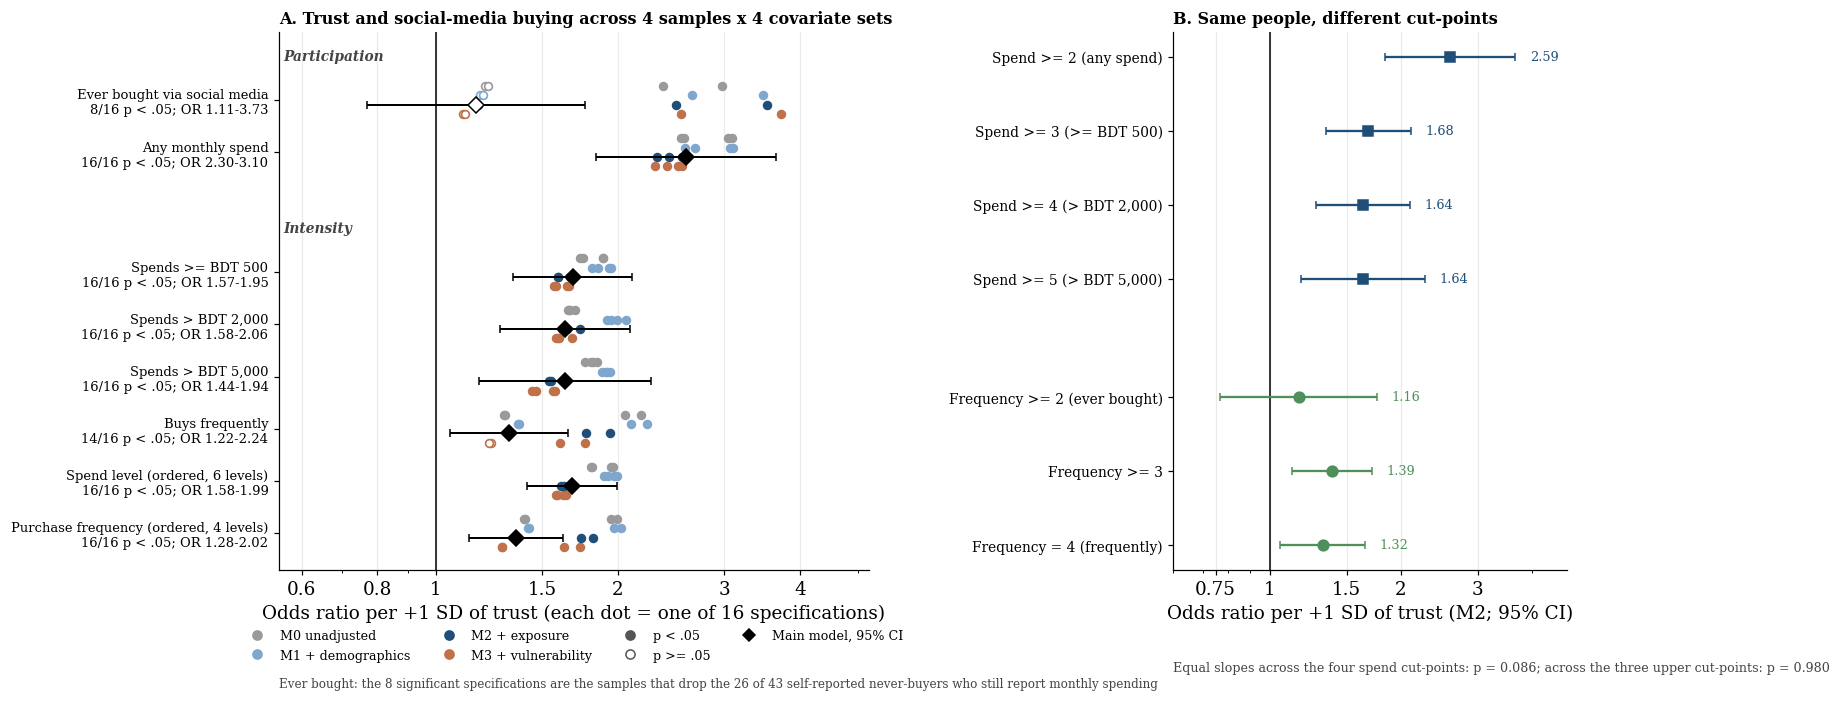


Table20b_H7_trust_cutpoints: H7 under three definitions of 'low trust': Firth models with the same 11 predictors, block likelihood-ratio tests and the exposure-minus-income contrast (500 bootstrap resamples)


OR: influencers followed / daily hours / income Exposure block chi2 (2 df) [p] Socio-economic block chi2 (2 df) [p]  \
Definition of low trust                             Outcome                                                                                                                                 
Trust 1-2 (main; half the sample) (n = 258)         Spends >= BDT 500                              1.60 / 1.59 / 1.17                   33.6 [<.001]                          8.8 [0.013]   
                                                    Any monthly spend                              2.38 / 1.03 / 0.90                   32.9 [<.001]                          8.4 [0.015]   
Trust = 1 only (strictest) (n = 121)                Spends >= BDT 500                              2.24 / 2.02 / 1.34                   27.1 [<.001]                          6.3 [0.043]   
                                                    Any monthly spend                              2.10 / 1.05 / 1.07                   16.2 [<.001]                          5.5 [0.065]   
Trust 1-3 (everyone but the 'high' group) (n = 426) Spends >= BDT 500                              1.93 / 1.36 / 1.15                   59.4 [<.001]                         13.4 [0.001]   
                                                    Any monthly spend                              2.60 / 0.89 / 0.92                   49.7 [<.001]                         11.1 [0.004]   

                                                                      Exposure minus income, log-odds [95% bootstrap CI]  
Definition of low trust                             Outcome                                                               
Trust 1-2 (main; half the sample) (n = 258)         Spends >= BDT 500                               +0.31 [-0.09, +0.73]  
                                                    Any monthly spend                               +0.55 [+0.09, +1.18]  
Trust = 1 only (strictest) (n = 121)                Spends >= BDT 500                               +0.46 [-0.06, +1.33]  
                                                    Any monthly spend                               +0.33 [-0.39, +1.11]  
Trust 1-3 (everyone but the 'high' group) (n = 426) Spends >= BDT 500                               +0.35 [+0.03, +0.68]  
                                                    Any monthly spend                               +0.51 [+0.01, +0.98]


Table20c_H6_alternative_specifications: H6 under alternative trust codings, link functions and samples: the trust x cash-on-delivery interaction coefficient (log-odds; OLS b in the OLS row) (M2 covariates; for the continuous codings the coefficient is per +1 SD of trust, for the binary codings it is the higher-trust group vs the lower-trust group; the three-group row shows the high-vs-low coefficient and a 2-df test). Predicted sign: negative for satisfaction (COD helps less as trust rises), positive for regret


,n,Satisfaction (1-5): interaction coefficient [95% CI],p (satisfaction),Direction (satisfaction),Regret (1-5): interaction coefficient [95% CI],p (regret),Direction (regret)
Specification,,,,,,,
"Main: quadratic trust, ordered logit, analytic sample",512,"-0.38 [-0.75, -0.01]",0.042,as predicted,"+0.42 [+0.08, +0.76]",0.014,as predicted
Linear trust only,512,"-0.48 [-0.84, -0.12]",0.009,as predicted,"+0.42 [+0.08, +0.75]",0.014,as predicted
Ordered probit instead of logit,512,"-0.19 [-0.38, +0.01]",0.067,as predicted,"+0.19 [-0.00, +0.38]",0.055,as predicted
"OLS on the 1-5 score (HC3), linear trust",512,"-0.17 [-0.36, +0.03]",0.090,as predicted,"+0.18 [-0.01, +0.37]",0.060,as predicted
Trust coded >= 3 vs <= 2,512,"-0.69 [-1.36, -0.02]",0.043,as predicted,"+0.73 [+0.08, +1.39]",0.027,as predicted
Trust coded >= 4 vs <= 3,512,"-0.35 [-1.31, +0.62]",0.483,as predicted,"+0.33 [-0.54, +1.21]",0.459,as predicted
Three trust groups (low / moderate / high; 2 df),512,"-0.62 [-1.64, +0.40]",0.234,as predicted,"+0.62 [-0.31, +1.55]",0.134,as predicted
Main model + straight-liners and duplicates,521,"-0.36 [-0.72, +0.00]",0.051,as predicted,"+0.43 [+0.09, +0.77]",0.012,as predicted
Main model excl. outcome-inconsistent answers,454,"-0.11 [-0.50, +0.28]",0.574,as predicted,"+0.41 [+0.04, +0.77]",0.029,as predicted


saved figure: Fig19_robustness_H6_H7
  suggested caption: Figure 19. Robustness of the moderation (H6) and low-trust spending (H7) results


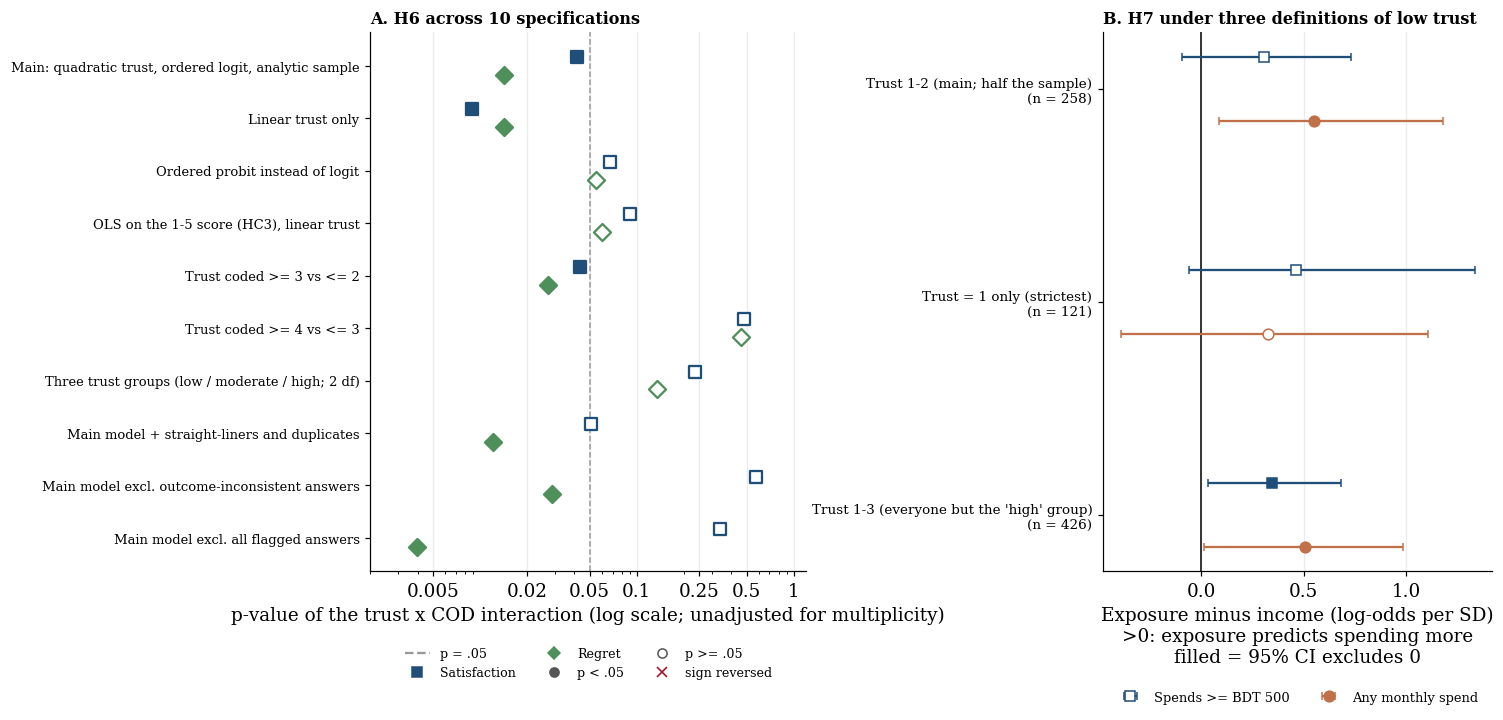


Table20d_multiple_imputation: Multiple imputation of the 3 missing residence answers (the only variable with missing values; bootstrap multinomial-logit imputation on 10 covariates and outcomes, m = 50, Rubin's rules) against complete cases. Trust odds ratios are per +1 SD (M2)


,Complete cases (n = 512): OR [95% CI],"Multiply imputed (n = 515, m = 50): OR [95% CI]",Change in log-odds,Fraction of missing information,p (MI)
Estimate,,,,,
Spend level (ordered),"1.680 [1.414, 1.996]","1.675 [1.413, 1.986]",-0.0029,0.000,<.001
Spends >= BDT 500,"1.683 [1.343, 2.108]","1.665 [1.331, 2.083]",-0.0105,0.000,<.001
"Spends > BDT 2,000","1.635 [1.277, 2.094]","1.635 [1.278, 2.090]",-0.0003,0.000,<.001
Any monthly spend,"2.592 [1.836, 3.659]","2.620 [1.862, 3.685]",+0.0105,0.000,<.001
Trust x COD on satisfaction (ordered logit),"0.684 [0.474, 0.986]","0.656 [0.456, 0.946]",-0.0407,0.001,0.024
Trust x COD on regret (ordered logit),"1.528 [1.088, 2.145]","1.549 [1.105, 2.171]",+0.0137,0.000,0.011



Table20e_E_values: E-values for the trust association (M2, analytic sample). An unmeasured confounder would need a risk-ratio association of at least the E-value with both trust and the outcome, beyond the measured covariates, to explain the estimate away (point estimate) or to move the confidence limit to 1. The strongest measured covariate is shown for scale. Odds ratios converted with RR ~ sqrt(OR); the spend-level row is approximate


,Trust OR (M2) [95% CI],Approx. risk ratio,E-value (point estimate),E-value (CI limit nearest 1),Strongest measured covariate (risk-ratio scale)
Outcome,,,,,
Any monthly spend,"2.59 [1.84, 3.66]",1.61,2.60,2.05,1.53 (influencers followed)
Spends >= BDT 500,"1.68 [1.34, 2.11]",1.30,1.92,1.59,1.33 (influencers followed)
"Spends > BDT 2,000","1.64 [1.28, 2.09]",1.28,1.88,1.51,1.85 (income)
"Spends > BDT 5,000","1.64 [1.18, 2.27]",1.28,1.88,1.39,1.49 (influencers followed)
Buys frequently,"1.32 [1.06, 1.65]",1.15,1.56,1.19,1.08 (education)
"Spend level (ordered, 6 levels)","1.68 [1.41, 2.00]",1.30,1.92,1.66,1.44 (influencers followed)
"Purchase frequency (ordered, 4 levels)","1.36 [1.14, 1.62]",1.16,1.60,1.33,1.09 (influencers followed)



Cell 16 ran in 215 s

--- Key facts: specification curve (trust OR per +1 SD; 16 specifications each) ---
  Ever bought via social media             main 1.16 [0.77, 1.76]    range 1.11 to 3.73   p<.05 in 8 / 16; OR>1 in 16 / 16
  Any monthly spend                        main 2.59 [1.84, 3.66]    range 2.30 to 3.10   p<.05 in 16 / 16; OR>1 in 16 / 16
  Spends >= BDT 500                        main 1.68 [1.34, 2.11]    range 1.57 to 1.95   p<.05 in 16 / 16; OR>1 in 16 / 16
  Spends > BDT 2,000                       main 1.64 [1.28, 2.09]    range 1.58 to 2.06   p<.05 in 16 / 16; OR>1 in 16 / 16
  Spends > BDT 5,000                       main 1.64 [1.18, 2.27]    range 1.44 to 1.94   p<.05 in 16 / 16; OR>1 in 16 / 16
  Buys frequently                          main 1.32 [1.06, 1.65]    range 1.22 to 2.24   p<.05 in 14 / 16; OR>1 in 16 / 16
  Spend level (ordered, 6 levels)          main 1.68 [1.41, 2.00]    range 1.58 to 1.99   p<.05 in 16 / 16; OR>1 in 16 / 16
  Purchase frequency (orde

In [17]:
# ============================================================
# CELL 16 — Robustness: samples, specifications, trust cut-points, missing data, unmeasured confounding   (Tables 20a-e; Figures 18-19)
# (run after Cells 6, 8, 11, 13, 14 and 15: re-uses model, d0, clean, smf, OrderedModel, M2_TERMS, PRED, PV, BLOCKS, HOUT, firth_fit, GRS, fmt_p, save_table, save_fig)
# ============================================================
import warnings; warnings.filterwarnings("ignore")
import time as _time
from scipy import stats as _st
from matplotlib.ticker import NullFormatter
from matplotlib.lines import Line2D
import statsmodels.api as sm
_t0 = _time.time()

# ---------- 0. analytic-sample variants and a helper that rebuilds every derived variable ----------
def prep(df, ref=None):
    d = df.copy(); ref = d if ref is None else ref
    for v, c in [("z_Trust", "Trust18"), ("z_Vuln", "Vuln"), ("z_Income", "Income"), ("z_Edu", "Edu"), ("z_Age", "Age"), ("z_NFollow", "NFollow"), ("z_SMhrs", "SMhrs")]:
        d[v] = (d[c] - ref[c].mean()) / ref[c].std()
    d["zT2"] = d["z_Trust"] ** 2; d["zT_x_COD"] = d["z_Trust"] * d["COD"]; d["Spend5000"] = (d["Spend"] >= 5).astype(int)
    d["Hi3"] = (d["Trust18"] >= 3).astype(int); d["Hi4"] = (d["Trust18"] >= 4).astype(int); d["Hi3_x_COD"] = d["Hi3"] * d["COD"]; d["Hi4_x_COD"] = d["Hi4"] * d["COD"]
    d["TG_mid"] = (d["Trust18"] == 3).astype(int); d["TG_hi"] = (d["Trust18"] >= 4).astype(int); d["TGm_x_COD"] = d["TG_mid"] * d["COD"]; d["TGh_x_COD"] = d["TG_hi"] * d["COD"]
    return d
INCONS = ["flag_never_buy_but_spend", "flag_nospend_but_freq_buy"]; ALLFLAG = ["flag_top3_Q9", "flag_top3_Q20", "flag_never_buy_but_spend", "flag_nospend_but_freq_buy", "flag_never_shop_online"]
S_RAW = d0[d0["Q6"].notna()]; S_INC = model[~model[INCONS].any(axis=1)]; S_STR = model[~model[ALLFLAG].any(axis=1)]
SAMP = {"S1": ("Analytic sample", prep(model)), "S2": ("+ straight-liners and duplicates", prep(S_RAW)), "S3": ("Excl. outcome-inconsistent answers", prep(S_INC)), "S4": ("Excl. all flagged answers", prep(S_STR))}
SAMP = {k: (f"{lab} (n = {len(d)})", d) for k, (lab, d) in SAMP.items()}
print("Sample variants:", "; ".join(f"{k}: {lab}" for k, (lab, d) in SAMP.items()))
M0, M1, M2, M3 = list(SPECS.values()); SPK = {"M0": SPECS["M0 unadjusted"], "M1": SPECS["M1 + demographics"], "M2": SPECS[MAIN], "M3": SPECS["M3 + vulnerability"]}

# fits the trust model (ordered logit or logit) and returns OR, 95% CI and p for +1 SD of trust
def fit_trust(d, oc, rhs, kind):
    m = (OrderedModel.from_formula(f"{oc} ~ 0 + {rhs}", data=d, distr="logit").fit(method="bfgs", disp=0, maxiter=2000) if kind == "ord" else smf.logit(f"{oc} ~ {rhs}", data=d).fit(disp=0, cov_type="HC1"))
    ci = m.conf_int().loc["z_Trust"]; return m, np.exp(m.params["z_Trust"]), np.exp(ci[0]), np.exp(ci[1]), m.pvalues["z_Trust"]

# ============================================================
# PART A — does the trust association survive every reasonable specification?  (4 samples x 4 covariate sets x 8 outcomes = 128 models)
# ============================================================
OUTC = [("Ever bought via social media", "P_buy", "bin", "Participation"), ("Any monthly spend", "P_spend", "bin", "Participation"), ("Spends >= BDT 500", "Spend500", "bin", "Intensity"),
        ("Spends > BDT 2,000", "Spend2000", "bin", "Intensity"), ("Spends > BDT 5,000", "Spend5000", "bin", "Intensity"), ("Buys frequently", "FreqBuy", "bin", "Intensity"),
        ("Spend level (ordered, 6 levels)", "Spend", "ord", "Intensity"), ("Purchase frequency (ordered, 4 levels)", "Buy", "ord", "Intensity")]
rows = []
for lab, oc, kind, fam in OUTC:
    for sk, (slab, d) in SAMP.items():
        for mk, rhs in SPK.items():
            m, o, lo, hi, p = fit_trust(d, oc, rhs, kind); rows.append({"Outcome": lab, "oc": oc, "Family": fam, "Sample": sk, "Covariates": mk, "OR": o, "lo": lo, "hi": hi, "p": p, "n": int(m.nobs)})
SC = pd.DataFrame(rows)
summ = []
for lab, oc, kind, fam in OUTC:
    s = SC[SC.oc == oc]; mn = s[(s.Sample == "S1") & (s.Covariates == "M2")].iloc[0]
    summ.append({"Outcome": lab, "Family": fam, "Main model OR [95% CI] (M2, analytic sample)": f"{mn.OR:.2f} [{mn.lo:.2f}, {mn.hi:.2f}]", "Range of OR across the 16 specifications": f"{s.OR.min():.2f} to {s.OR.max():.2f}",
                 "Specifications with p < .05": f"{int((s.p < .05).sum())} / {len(s)}", "Specifications with OR > 1": f"{int((s.OR > 1).sum())} / {len(s)}", "Largest p": fmt_p(s.p.max())})
T20a = pd.DataFrame(summ)
save_table(T20a.set_index("Outcome"), "Table20a_trust_specification_curve", f"Odds ratio for +1 SD of trust across 16 specifications per outcome: 4 samples (analytic; + straight-liners and duplicates; excluding outcome-inconsistent answers; excluding all flagged answers) x 4 covariate sets (M0-M3). Logit with HC1 SEs; ordered logit for the two ordered outcomes")
save_table(SC.round(4).set_index(["Outcome", "Sample", "Covariates"]), "Table20a_numeric", "All 128 models behind Table 20a (numeric)")

# thresholds of the ordered outcomes (do the odds ratios differ between cut-points, i.e. is proportional odds reasonable?)
d1 = SAMP["S1"][1]; TH = []
for lab, oc, thr, grp in [("Spend >= 2 (any spend)", "Spend", 2, "Monthly spend"), ("Spend >= 3 (>= BDT 500)", "Spend", 3, "Monthly spend"), ("Spend >= 4 (> BDT 2,000)", "Spend", 4, "Monthly spend"), ("Spend >= 5 (> BDT 5,000)", "Spend", 5, "Monthly spend"),
                          ("Frequency >= 2 (ever bought)", "Buy", 2, "Purchase frequency"), ("Frequency >= 3", "Buy", 3, "Purchase frequency"), ("Frequency = 4 (frequently)", "Buy", 4, "Purchase frequency")]:
    d1["_y"] = (d1[oc] >= thr).astype(int); m = smf.logit(f"_y ~ {SPK['M2']}", data=d1).fit(disp=0, cov_type="HC1"); ci = m.conf_int().loc["z_Trust"]
    TH.append({"Cut-point": lab, "Group": grp, "events": int(d1["_y"].sum()), "OR": np.exp(m.params["z_Trust"]), "lo": np.exp(ci[0]), "hi": np.exp(ci[1]), "p": m.pvalues["z_Trust"], "b": m.params["z_Trust"], "se": m.bse["z_Trust"]})
TH = pd.DataFrame(TH)
# heterogeneity of the trust slope across the four spend cut-points (cumulative logits fitted on the same people, so use a simple Wald contrast with a bootstrap)
rng = np.random.default_rng(16); bs = []
for _ in range(500):
    i = rng.integers(0, len(d1), len(d1)); db = d1.iloc[i]; bb = []
    for thr in (2, 3, 4, 5):
        db = db.assign(_y=(db["Spend"] >= thr).astype(int)); bb.append(smf.logit(f"_y ~ {SPK['M2']}", data=db).fit(disp=0).params["z_Trust"])
    bs.append(bb)
bs = np.array(bs); b0 = TH.loc[TH.Group == "Monthly spend", "b"].values; Vb = np.cov(bs.T); Cm = np.array([[1, -1, 0, 0], [0, 1, -1, 0], [0, 0, 1, -1]]); wald = float((Cm @ b0) @ np.linalg.pinv(Cm @ Vb @ Cm.T) @ (Cm @ b0)); p_het = _st.chi2.sf(wald, 3)
Cm2 = np.array([[0, 1, -1, 0], [0, 0, 1, -1]]); wald2 = float((Cm2 @ b0) @ np.linalg.pinv(Cm2 @ Vb @ Cm2.T) @ (Cm2 @ b0)); p_het2 = _st.chi2.sf(wald2, 2)
save_table(TH.assign(**{"OR [95% CI]": TH.apply(lambda r: f"{r.OR:.2f} [{r.lo:.2f}, {r.hi:.2f}]", axis=1), "p": TH.p.map(fmt_p)})[["Group", "Cut-point", "events", "OR [95% CI]", "p"]].set_index(["Group", "Cut-point"]),
           "Table20a_thresholds", f"Trust odds ratio (+1 SD, M2, analytic sample) at each cumulative cut-point of the two ordered outcomes. Equality of the four spend slopes: Wald chi2(3) = {wald:.1f}, p = {fmt_p(p_het)} (500 bootstrap resamples); equality of the three upper cut-points (>= BDT 500, > 2,000, > 5,000): chi2(2) = {wald2:.1f}, p = {fmt_p(p_het2)}")

# ---- Figure 18 ----
fig, axes = plt.subplots(1, 2, figsize=(15.2, 7.4), gridspec_kw={"width_ratios": [1.5, 1], "wspace": .62}); ax = axes[0]; ax.axvline(1, color="black", lw=1)
SPC = {"M0": "#9a9a9a", "M1": "#7fa6cc", "M2": "#1f4e79", "M3": "#c0714a"}; SPO = {"M0": -.27, "M1": -.09, "M2": .09, "M3": .27}; y = 0; ypos = []; ylab = []; hdr = []; prev = None
for lab, oc, kind, fam in OUTC:
    if fam != prev: y += .55 if prev is not None else 0; hdr.append((y - .1, fam)); y += .75; prev = fam
    s = SC[SC.oc == oc]
    for _, r in s.iterrows(): ax.scatter(r.OR, y + SPO[r.Covariates], s=26, color=SPC[r.Covariates], facecolor=(SPC[r.Covariates] if r.p < .05 else "white"), lw=1.1, zorder=3)
    mn = s[(s.Sample == "S1") & (s.Covariates == "M2")].iloc[0]; ax.errorbar(mn.OR, y + SPO["M2"], xerr=[[mn.OR - mn.lo], [mn.hi - mn.OR]], fmt="D", color="black", ms=7, mfc=("black" if mn.p < .05 else "white"), capsize=2.5, lw=1.3, zorder=4)
    ypos.append(y); ylab.append(f"{lab}\n{int((s.p < .05).sum())}/16 p < .05; OR {s.OR.min():.2f}-{s.OR.max():.2f}"); y += 1
for yh, th in hdr: ax.text(.56, yh, th, fontsize=9, fontweight="bold", fontstyle="italic", color="#444", va="center")
ax.set_yticks(ypos); ax.set_yticklabels(ylab, fontsize=8.6); ax.set_ylim(y - .3, -.55); ax.set_xscale("log"); ax.set_xlim(.55, 5.2); ax.set_xticks([.6, .8, 1, 1.5, 2, 3, 4]); ax.set_xticklabels(["0.6", "0.8", "1", "1.5", "2", "3", "4"]); ax.xaxis.set_minor_formatter(NullFormatter()); ax.grid(axis="x", alpha=.25)
ax.set_xlabel("Odds ratio per +1 SD of trust (each dot = one of 16 specifications)"); NCON = int(((model.P_buy == 0) & (model.Spend > 1)).sum()); NNEV = int((model.P_buy == 0).sum())
NSIGB = int((SC[SC.oc == "P_buy"].p < .05).sum()); ax.text(0, -.2, f"Ever bought: the {NSIGB} significant specifications are the samples that drop the {NCON} of {NNEV} self-reported never-buyers who still report monthly spending", transform=ax.transAxes, fontsize=7.8, va="top", color="#444")
hs = [Line2D([], [], marker="o", ls="", color=SPC[k], label=l) for k, l in [("M0", "M0 unadjusted"), ("M1", "M1 + demographics"), ("M2", "M2 + exposure"), ("M3", "M3 + vulnerability")]] + \
     [Line2D([], [], marker="o", ls="", color="#555", mfc="#555", label="p < .05"), Line2D([], [], marker="o", ls="", color="#555", mfc="white", label="p >= .05"), Line2D([], [], marker="D", ls="", color="black", label="Main model, 95% CI")]
ax.legend(handles=hs, loc="upper center", bbox_to_anchor=(.5, -.09), ncol=4, fontsize=8.3, frameon=False); ax.set_title("A. Trust and social-media buying across 4 samples x 4 covariate sets", loc="left", fontsize=10.5, fontweight="bold")
# panel B: trust odds ratio at each cumulative cut-point (monthly spend; purchase frequency)
ax = axes[1]; ax.axvline(1, color="black", lw=1); y = 0; yp = []; yl = []
for g_, col, mk in [("Monthly spend", "#1f4e79", "s"), ("Purchase frequency", "#4f8f5a", "o")]:
    for _, r in TH[TH.Group == g_].iterrows():
        ax.errorbar(r.OR, y, xerr=[[r.OR - r.lo], [r.hi - r.OR]], fmt=mk, color=col, ms=7, capsize=2.5, lw=1.5); ax.text(r.hi * 1.08, y, f"{r.OR:.2f}", va="center", fontsize=8.4, color=col); yp.append(y); yl.append(r["Cut-point"]); y += 1
    y += .6
ax.set_yticks(yp); ax.set_yticklabels(yl, fontsize=9); ax.invert_yaxis(); ax.set_xscale("log"); ax.set_xlim(.6, 4.8); ax.set_xticks([.75, 1, 1.5, 2, 3]); ax.set_xticklabels(["0.75", "1", "1.5", "2", "3"]); ax.xaxis.set_minor_formatter(NullFormatter()); ax.grid(axis="x", alpha=.25)
ax.set_xlabel("Odds ratio per +1 SD of trust (M2; 95% CI)"); ax.set_title("B. Same people, different cut-points", loc="left", fontsize=10.5, fontweight="bold")
ax.text(.0, -.17, f"Equal slopes across the four spend cut-points: p = {fmt_p(p_het)}; across the three upper cut-points: p = {fmt_p(p_het2)}", transform=ax.transAxes, fontsize=8.3, va="top", color="#444")
CAPTION = ("Figure 18. Robustness of the trust-spending association"); fig.subplots_adjust(left=.2, right=.97, top=.9, bottom=.24); save_fig(fig, "Fig18_robustness_trust", CAPTION); plt.show()

# ============================================================
# PART B — alternative trust cut-points for H7 (low-trust spenders) and alternative codings / samples for H6 (COD x trust on satisfaction)
# ============================================================
# ---- B1. H7: redefine 'low trust' ----
LOWDEF = [("Trust 1-2 (main; half the sample)", model.Trust18 <= 2), ("Trust = 1 only (strictest)", model.Trust18 <= 1), ("Trust 1-3 (everyone but the 'high' group)", model.Trust18 <= 3)]
B7 = 500; H7R = []
for dl, mask in LOWDEF:
    L = model[mask].copy(); nL = len(L)
    for v in ["NFollow", "SMhrs", "Income", "Edu", "Age"]: L["l_" + v] = (L[v] - L[v].mean()) / L[v].std()
    XX = np.column_stack([np.ones(nL)] + [L[v].values for v in PV]).astype(float); iN, iS, iI = PV.index("l_NFollow") + 1, PV.index("l_SMhrs") + 1, PV.index("l_Income") + 1
    for lab_o, oc in HOUT[:2]:
        y_ = L[oc].values; b, cov, pll = firth_fit(XX, y_); se = np.sqrt(np.diag(cov)); rg = np.random.default_rng(160 + nL + len(H7R)); dd = []
        for _ in range(B7):
            i = rg.integers(0, nL, nL)
            try: bb = firth_fit(XX[i], y_[i])[0]; dd.append((bb[iN] + bb[iS]) / 2 - bb[iI])
            except Exception: pass
        lo, hi = np.percentile(dd, [2.5, 97.5]); pt = (b[iN] + b[iS]) / 2 - b[iI]; blk = {}
        for bl in ["Exposure", "Socio-economic"]:
            keep = [i + 1 for i, v in enumerate(PV) if v not in BLOCKS[bl]]; pr = firth_fit(XX[:, [0] + keep], y_)[2]; lr = 2 * (pll - pr); blk[bl] = (lr, _st.chi2.sf(lr, len(BLOCKS[bl])))
        H7R.append({"Definition of low trust": f"{dl} (n = {nL})", "Outcome": lab_o, "oc": oc, "n": nL, "OR influencers followed": np.exp(b[iN]), "OR daily hours": np.exp(b[iS]), "OR income": np.exp(b[iI]), "p income": 2 * _st.norm.sf(abs(b[iI] / se[iI])),
                    "chi2 exposure": blk["Exposure"][0], "p exposure": blk["Exposure"][1], "chi2 socio-econ": blk["Socio-economic"][0], "p socio-econ": blk["Socio-economic"][1], "contrast": pt, "c_lo": lo, "c_hi": hi})
H7R = pd.DataFrame(H7R)
save_table(pd.DataFrame({"Definition of low trust": H7R["Definition of low trust"], "Outcome": H7R["Outcome"],
                         "OR: influencers followed / daily hours / income": H7R.apply(lambda r: f"{r['OR influencers followed']:.2f} / {r['OR daily hours']:.2f} / {r['OR income']:.2f}", axis=1),
                         "Exposure block chi2 (2 df) [p]": H7R.apply(lambda r: f"{r['chi2 exposure']:.1f} [{fmt_p(r['p exposure'])}]", axis=1), "Socio-economic block chi2 (2 df) [p]": H7R.apply(lambda r: f"{r['chi2 socio-econ']:.1f} [{fmt_p(r['p socio-econ'])}]", axis=1),
                         "Exposure minus income, log-odds [95% bootstrap CI]": H7R.apply(lambda r: f"{r.contrast:+.2f} [{r.c_lo:+.2f}, {r.c_hi:+.2f}]", axis=1)}).set_index(["Definition of low trust", "Outcome"]),
           "Table20b_H7_trust_cutpoints", f"H7 under three definitions of 'low trust': Firth models with the same 11 predictors, block likelihood-ratio tests and the exposure-minus-income contrast ({B7} bootstrap resamples)")

# ---- B2. H6: trust x COD on satisfaction and regret under alternative codings, links and samples ----
H6O = [("Satisfaction (1-5)", "Satisf", -1), ("Regret (1-5)", "regret", +1)]          # expected sign of the interaction for 'higher trust': satisfaction negative, regret positive
COV = [t for t in M2_TERMS if t != "z_Trust"]
# one H6 model: ordered logit/probit or OLS (HC3) with the given terms
def h6_fit(d, oc, terms, link="logit", ols=False):
    rhs = " + ".join(terms)
    if ols: return smf.ols(f"{oc} ~ {rhs}", data=d).fit(cov_type="HC3")
    return OrderedModel.from_formula(f"{oc} ~ 0 + {rhs}", data=d, distr=link).fit(method="bfgs", disp=0, maxiter=2000)
# defines the terms of each H6 specification (trust coding x COD interaction) and fits it for satisfaction or regret
def h6_spec(d, oc, mode):
    link = "probit" if mode == "probit" else "logit"
    T = {"quad": (["z_Trust", "zT2", "COD"], ["zT_x_COD"]), "probit": (["z_Trust", "zT2", "COD"], ["zT_x_COD"]), "lin": (["z_Trust", "COD"], ["zT_x_COD"]), "ols": (["z_Trust", "COD"], ["zT_x_COD"]),
         "hi3": (["Hi3", "COD"], ["Hi3_x_COD"]), "hi4": (["Hi4", "COD"], ["Hi4_x_COD"]), "tri": (["TG_mid", "TG_hi", "COD"], ["TGm_x_COD", "TGh_x_COD"])}[mode]
    base, inter = T; f1 = h6_fit(d, oc, COV + base + inter, link, mode == "ols"); key = inter[-1]; b = f1.params[key]; ci = f1.conf_int().loc[key]
    if mode == "ols": p = f1.wald_test(" , ".join(f"{k} = 0" for k in inter), scalar=True).pvalue if len(inter) > 1 else f1.pvalues[key]
    else: f0 = h6_fit(d, oc, COV + base, link); lr = 2 * (f1.llf - f0.llf); p = _st.chi2.sf(lr, len(inter))
    return b, ci[0], ci[1], p
SPEC6 = [("Main: quadratic trust, ordered logit, analytic sample", "quad", "S1"), ("Linear trust only", "lin", "S1"), ("Ordered probit instead of logit", "probit", "S1"), ("OLS on the 1-5 score (HC3), linear trust", "ols", "S1"),
         ("Trust coded >= 3 vs <= 2", "hi3", "S1"), ("Trust coded >= 4 vs <= 3", "hi4", "S1"), ("Three trust groups (low / moderate / high; 2 df)", "tri", "S1"),
         ("Main model + straight-liners and duplicates", "quad", "S2"), ("Main model excl. outcome-inconsistent answers", "quad", "S3"), ("Main model excl. all flagged answers", "quad", "S4")]
rows = []
for lab_s, mode, sk in SPEC6:
    d = SAMP[sk][1]; row = {"Specification": lab_s, "n": len(d)}
    for lab_o, oc, sgn in H6O:
        b, lo, hi, p = h6_spec(d, oc, mode); row[f"{lab_o}: interaction coefficient [95% CI]"] = f"{b:+.2f} [{lo:+.2f}, {hi:+.2f}]"; row[f"p {oc}"] = p; row[f"dir {oc}"] = (np.sign(b) == sgn)
    rows.append(row)
T20c = pd.DataFrame(rows)
show = T20c.copy()
for oc in ["Satisf", "regret"]: show[f"p {oc}"] = show[f"p {oc}"].map(fmt_p); show[f"dir {oc}"] = show[f"dir {oc}"].map({True: "as predicted", False: "reversed"})
show = show.rename(columns={"p Satisf": "p (satisfaction)", "dir Satisf": "Direction (satisfaction)", "p regret": "p (regret)", "dir regret": "Direction (regret)"})
save_table(show.set_index("Specification"), "Table20c_H6_alternative_specifications", "H6 under alternative trust codings, link functions and samples: the trust x cash-on-delivery interaction coefficient (log-odds; OLS b in the OLS row) (M2 covariates; for the continuous codings the coefficient is per +1 SD of trust, for the binary codings it is the higher-trust group vs the lower-trust group; the three-group row shows the high-vs-low coefficient and a 2-df test). Predicted sign: negative for satisfaction (COD helps less as trust rises), positive for regret")

# ---- Figure 19 ----
fig, axes = plt.subplots(1, 2, figsize=(15.0, 6.9), gridspec_kw={"width_ratios": [1.12, 1], "wspace": .72}); ax = axes[0]; ax.axvline(.05, color="#999", lw=1, ls="--")
for j, (lab_o, oc, sgn) in enumerate(H6O):
    col, mk, dy = ("#1f4e79", "s", -.17) if oc == "Satisf" else ("#4f8f5a", "D", .17)
    for i, r in T20c.iterrows():
        ax.scatter(r[f"p {oc}"], i + dy, s=62, marker=mk, color=col, facecolor=(col if r[f"p {oc}"] < .05 else "white"), lw=1.5, zorder=3)
        if not r[f"dir {oc}"]: ax.scatter(r[f"p {oc}"], i + dy, s=170, marker="x", color="#b00020", zorder=4)
ax.set_yticks(range(len(T20c))); ax.set_yticklabels([f"{r.Specification}" for _, r in T20c.iterrows()], fontsize=8.6); ax.invert_yaxis(); ax.set_xscale("log"); ax.set_xlim(.002, 1.2); ax.set_xticks([.005, .02, .05, .1, .25, .5, 1]); ax.set_xticklabels(["0.005", "0.02", "0.05", "0.1", "0.25", "0.5", "1"]); ax.xaxis.set_minor_formatter(NullFormatter()); ax.grid(axis="x", alpha=.25)
ax.set_xlabel("p-value of the trust x COD interaction (log scale; unadjusted for multiplicity)")
ax.legend(handles=[Line2D([], [], ls="--", color="#999", label="p = .05"), Line2D([], [], marker="s", ls="", color="#1f4e79", label="Satisfaction"), Line2D([], [], marker="D", ls="", color="#4f8f5a", label="Regret"), Line2D([], [], marker="o", ls="", color="#555", mfc="#555", label="p < .05"), Line2D([], [], marker="o", ls="", color="#555", mfc="white", label="p >= .05"), Line2D([], [], marker="x", ls="", color="#b00020", label="sign reversed")],
          loc="upper center", bbox_to_anchor=(.5, -.12), ncol=3, fontsize=8.3, frameon=False); ax.set_title("A. H6 across 10 specifications", loc="left", fontsize=10.5, fontweight="bold")
# panel B: exposure-minus-income contrast under the three definitions of low trust
ax = axes[1]; ax.axvline(0, color="black", lw=1); y = 0; yp = []; yl = []
for dl, mask in LOWDEF:
    for lab_o, oc in HOUT[:2]:
        r = H7R[(H7R["Definition of low trust"].str.startswith(dl)) & (H7R.oc == oc)].iloc[0]; col, mk, dy = ("#1f4e79", "s", -.15) if oc == "Spend500" else ("#c0714a", "o", .15)
        ax.errorbar(r.contrast, y + dy, xerr=[[r.contrast - r.c_lo], [r.c_hi - r.contrast]], fmt=mk, color=col, ms=7, capsize=2.5, lw=1.5, mfc=(col if (r.c_lo > 0 or r.c_hi < 0) else "white"), label=("Spends >= BDT 500" if oc == "Spend500" else "Any monthly spend") if y == 0 else None)
    yp.append(y); yl.append(r["Definition of low trust"].replace(" (n =", "\n(n =")); y += 1
ax.set_yticks(yp); ax.set_yticklabels(yl, fontsize=8.8); ax.invert_yaxis(); ax.set_xlabel("Exposure minus income (log-odds per SD)\n>0: exposure predicts spending more\nfilled = 95% CI excludes 0")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.2), ncol=2, fontsize=8.5, frameon=False); ax.grid(axis="x", alpha=.25); ax.set_title("B. H7 under three definitions of low trust", loc="left", fontsize=10.5, fontweight="bold")
CAPTION = ("Figure 19. Robustness of the moderation (H6) and low-trust spending (H7) results"); fig.subplots_adjust(left=.27, right=.95, top=.93, bottom=.22); save_fig(fig, "Fig19_robustness_H6_H7", CAPTION); plt.show()

# ============================================================
# PART C — missing data (multiple imputation) and unmeasured confounding (E-values)
# ============================================================
# ---- C1. multiple imputation of the 3 missing residence answers (bootstrap-based chained imputation, m = 50) and Rubin's rules ----
cl = clean.copy(); obs = cl[cl["Q6"].notna()]; mis = cl[cl["Q6"].isna()]; CATS = ["Urban (city)", "Semi-urban (town)", "Rural"]; IMPV = ["Female", "Income", "Edu", "Age", "Trust18", "Spend", "NFollow", "SMhrs", "COD", "Satisf"]
mu_ = obs[IMPV].mean(); sd_ = obs[IMPV].std(); Xo = sm.add_constant(((obs[IMPV] - mu_) / sd_).astype(float)); Xm = sm.add_constant(((mis[IMPV] - mu_) / sd_).astype(float), has_constant="add")
yo = obs["Q6"].map({c: i for i, c in enumerate(CATS)}).values; M_IMP = 50; rg = np.random.default_rng(1616); IMPS = []
for _ in range(M_IMP):
    i = rg.integers(0, len(obs), len(obs)); mm = sm.MNLogit(yo[i], Xo.iloc[i]).fit(disp=0, maxiter=200, method="bfgs"); pr = np.asarray(mm.predict(Xm)); IMPS.append([rg.choice(3, p=p / p.sum()) for p in pr])
MI_OUT = [("Spend level (ordered)", "Spend", "ord", "z_Trust"), ("Spends >= BDT 500", "Spend500", "bin", "z_Trust"), ("Spends > BDT 2,000", "Spend2000", "bin", "z_Trust"), ("Any monthly spend", "P_spend", "bin", "z_Trust")]
# Rubin's rules: pooled estimate, pooled SE, fraction of missing information and degrees of freedom
def rubin(Q, U):
    Q = np.asarray(Q); U = np.asarray(U); m = len(Q); qb = Q.mean(); ub = U.mean(); b = Q.var(ddof=1); t = ub + (1 + 1 / m) * b; df = (m - 1) * (1 + ub / ((1 + 1 / m) * b)) ** 2 if b > 1e-14 else 1e6
    return qb, np.sqrt(t), (1 + 1 / m) * b / t, df
PO = {k: [] for k in [o[1] for o in MI_OUT] + ["Satisf_int", "regret_int"]}
for imp in IMPS:
    dm = cl.copy(); cat = np.array(CATS)[imp]; dm.loc[dm["Q6"].isna(), "Urban"] = (cat == "Urban (city)").astype(int); dm.loc[dm["Q6"].isna(), "Rural"] = (cat == "Rural").astype(int); dm = prep(dm, ref=model)
    for lab, oc, kind, v in MI_OUT:
        m, *_ = fit_trust(dm, oc, SPK["M2"], kind); PO[oc].append((m.params[v], m.bse[v]))
    for lab_o, oc, sgn in H6O:
        f1 = h6_fit(dm, oc, COV + ["z_Trust", "zT2", "COD", "zT_x_COD"]); PO[oc + "_int"].append((f1.params["zT_x_COD"], f1.bse["zT_x_COD"]))
rows = []; cc = SAMP["S1"][1]
for lab, oc, kind, v in MI_OUT + [("Trust x COD on satisfaction (ordered logit)", "Satisf_int", "int", "zT_x_COD"), ("Trust x COD on regret (ordered logit)", "regret_int", "int", "zT_x_COD")]:
    Q = [q for q, s in PO[oc]]; U = [s ** 2 for q, s in PO[oc]]; qb, se, fmi, df = rubin(Q, U); pv = 2 * _st.t.sf(abs(qb / se), df)
    if kind == "int": base = oc.replace("_int", ""); f1 = h6_fit(cc, base, COV + ["z_Trust", "zT2", "COD", "zT_x_COD"]); b0, s0 = f1.params["zT_x_COD"], f1.bse["zT_x_COD"]
    else: m, *_ = fit_trust(cc, oc, SPK["M2"], kind); b0, s0 = m.params[v], m.bse[v]
    rows.append({"Estimate": lab, "Complete cases (n = 512): OR [95% CI]": f"{np.exp(b0):.3f} [{np.exp(b0 - 1.96 * s0):.3f}, {np.exp(b0 + 1.96 * s0):.3f}]", f"Multiply imputed (n = {len(cl)}, m = {M_IMP}): OR [95% CI]": f"{np.exp(qb):.3f} [{np.exp(qb - 1.96 * se):.3f}, {np.exp(qb + 1.96 * se):.3f}]",
                 "Change in log-odds": f"{qb - b0:+.4f}", "Fraction of missing information": f"{fmi:.3f}", "p (MI)": fmt_p(pv)})
T20d = pd.DataFrame(rows)
save_table(T20d.set_index("Estimate"), "Table20d_multiple_imputation", f"Multiple imputation of the {len(mis)} missing residence answers (the only variable with missing values; bootstrap multinomial-logit imputation on 10 covariates and outcomes, m = {M_IMP}, Rubin's rules) against complete cases. Trust odds ratios are per +1 SD (M2)")

# ---- C2. E-values: how strong would an unmeasured confounder have to be? (VanderWeele-Ding; OR converted with RR ~ sqrt(OR), valid for common outcomes) ----
def eval_(rr): rr = max(rr, 1 / rr); return rr + np.sqrt(rr * (rr - 1))
rows = []
for lab, oc, kind, fam in OUTC[1:]:
    m, o, lo, hi, p = fit_trust(SAMP["S1"][1], oc, SPK["M2"], kind); rr, rrl = np.sqrt(o), np.sqrt(lo); ev, evl = eval_(rr), (eval_(rrl) if lo > 1 else 1.0)
    bench = max(np.sqrt(np.exp(abs(m.params[v]))) for v in ["z_NFollow", "z_SMhrs", "z_Income", "z_Edu", "z_Age"]); bn = max(["z_NFollow", "z_SMhrs", "z_Income", "z_Edu", "z_Age"], key=lambda v: abs(m.params[v]))
    rows.append({"Outcome": lab, "Trust OR (M2) [95% CI]": f"{o:.2f} [{lo:.2f}, {hi:.2f}]", "Approx. risk ratio": f"{rr:.2f}", "E-value (point estimate)": f"{ev:.2f}", "E-value (CI limit nearest 1)": f"{evl:.2f}",
                 "Strongest measured covariate (risk-ratio scale)": f"{bench:.2f} ({ {'z_NFollow': 'influencers followed', 'z_SMhrs': 'daily hours', 'z_Income': 'income', 'z_Edu': 'education', 'z_Age': 'age'}[bn] })", "ev": ev, "evl": evl, "bench": bench})
T20e = pd.DataFrame(rows)
save_table(T20e.drop(columns=["ev", "evl", "bench"]).set_index("Outcome"), "Table20e_E_values", "E-values for the trust association (M2, analytic sample). An unmeasured confounder would need a risk-ratio association of at least the E-value with both trust and the outcome, beyond the measured covariates, to explain the estimate away (point estimate) or to move the confidence limit to 1. The strongest measured covariate is shown for scale. Odds ratios converted with RR ~ sqrt(OR); the spend-level row is approximate")

# ---------- key facts ----------
print(f"\nCell 16 ran in {_time.time() - _t0:.0f} s")
print("\n--- Key facts: specification curve (trust OR per +1 SD; 16 specifications each) ---")
for _, r in T20a.iterrows(): print(f"  {r.Outcome:<40s} main {r['Main model OR [95% CI] (M2, analytic sample)']:<20s} range {r['Range of OR across the 16 specifications']:<14s} p<.05 in {r['Specifications with p < .05']}; OR>1 in {r['Specifications with OR > 1']}")
print("  Thresholds:", "; ".join(f"{r['Cut-point']}: {r.OR:.2f}" for _, r in TH.iterrows())); print(f"  Equal spend slopes: p = {p_het:.3f}; upper three cut-points: p = {p_het2:.3f}")
print("\n--- Key facts: H7 under alternative definitions ---"); print(H7R[["Definition of low trust", "Outcome", "OR influencers followed", "OR daily hours", "OR income", "chi2 exposure", "chi2 socio-econ", "contrast", "c_lo", "c_hi"]].round(2).to_string(index=False))
print("\n--- Key facts: H6 under alternative specifications ---"); print(T20c.drop(columns=["dir Satisf", "dir regret"]).assign(**{"p Satisf": T20c["p Satisf"].round(3), "p regret": T20c["p regret"].round(3)}).to_string(index=False))
print("  specifications in the predicted direction: satisfaction %d/%d, regret %d/%d; p < .05: satisfaction %d/%d, regret %d/%d" % (T20c["dir Satisf"].sum(), len(T20c), T20c["dir regret"].sum(), len(T20c), (T20c["p Satisf"] < .05).sum(), len(T20c), (T20c["p regret"] < .05).sum(), len(T20c)))
print("\n--- Key facts: multiple imputation ---"); print(T20d.to_string(index=False)); print("\n--- Key facts: E-values ---"); print(T20e.drop(columns=["ev", "evl", "bench"]).to_string(index=False))

## Cell 17 — Segmentation: latent class analysis of risk-containment practices
Self-implemented categorical latent class analysis (EM, 50 random starts) for 1–5 classes, parametric-bootstrap likelihood-ratio tests, split-half stability (adjusted Rand index), class profiles and class differences with pseudo-class draws and Rubin's rules.
**Outputs:** Tables 21a–21c; Figure 20. *Takes about 5 minutes in Colab.*

LCA sample n = 512; indicators: Pays cash on delivery, Researches first, Relies on user-generated content, Relies on comparison content, Stopped following a dishonest influencer, Believes sponsorship is disclosed adequately; main purchase driver (4 categories)
Mean inter-item phi among the six binary indicators = 0.042 (range -0.12 to 0.18); KR-20 = 0.22

Table21a_LCA_model_selection: Latent class models for 512 respondents on 6 binary containment indicators and the main purchase driver (4 categories). 50 random starts; BLRT = parametric bootstrap likelihood-ratio test (100 samples); split-half ARI = adjusted Rand index between solutions fitted on random halves and applied to everyone (20 splits). 'Meets criteria' = entropy >= .80, median ARI >= .60, BLRT p < .05 and smallest class >= 5%


,Log-likelihood,Parameters,BIC,aBIC,AIC,Entropy,Smallest class (%),BLRT p (vs k-1),"Split-half ARI, median [10th, 90th]",Meets criteria?
Classes,,,,,,,,,,
1,-2637.5,9,5331.2,5302.6,5293.0,NaN,100.0,,,
2,-2599.2,19,5317.0,5256.7,5236.5,0.66,20.1,0.010,"0.00 [-0.10, 0.42]",no
3,-2570.6,29,5322.1,5230.0,5199.2,0.57,11.5,0.010,"0.23 [0.04, 0.41]",no
4,-2556.7,39,5356.7,5232.9,5191.4,0.68,7.4,0.030,"0.21 [0.13, 0.29]",no
5,-2544.2,49,5394.1,5238.6,5186.4,0.65,13.7,,"0.23 [0.16, 0.30]",no



BIC selects 2 classes; aBIC selects 3 classes

Table21b_LCA_class_profiles: Item-response probabilities of each class (classes ordered by the sum of the five practice probabilities, highest first) and descriptive profiles by modal class assignment. Unequal class sizes and the low entropy mean the profiles are descriptive only


Class 1    Class 2    Class 3
Solution  Item                                                                                             
2 classes Pays cash on delivery                                                   62%        29%           
          Researches first                                                        67%        43%           
          Relies on user-generated content                                        53%        27%           
          Relies on comparison content                                            28%         0%           
          Stopped following a dishonest influencer                                61%        50%           
          Believes sponsorship is disclosed adequately                            43%        38%           
          Driver: reviews / seller / returns                                      54%        20%           
          Driver: price / discount                                                29%         0%           
          Driver: influencer                                                       0%        33%           
          Driver: other (delivery, COD option, look)                              17%        47%           
          Class size (modal assignment)                                     409 (80%)  103 (20%)           
          Trust (1-5), mean [Kruskal-Wallis p = 0.061]                           2.41       2.67           
          Influencers followed (1-5 code), mean [Kruskal-Wallis p = 0.022]       2.90       3.21           
          Daily hours (1-5 code), mean [Kruskal-Wallis p = 0.065]                2.97       3.19           
          Income (1-5 code), mean [Kruskal-Wallis p = 0.011]                     2.07       2.40           
          Spends >= BDT 500 (%) [Kruskal-Wallis p = 0.316]                        61%        66%           
          Any monthly spend (%) [Kruskal-Wallis p = 0.028]                        82%        91%           
          Satisfaction (1-5), mean [Kruskal-Wallis p = <.001]                    3.72       3.28           
          Regret (1-5), mean [Kruskal-Wallis p = 0.013]                          3.26       3.56           
3 classes Pays cash on delivery                                                   91%        57%        36%
          Researches first                                                        88%        67%        44%
          Relies on user-generated content                                        20%        65%        30%
          Relies on comparison content                                             3%        39%         0%
          Stopped following a dishonest influencer                               100%        52%        53%
          Believes sponsorship is disclosed adequately                            72%        33%        42%
          Driver: reviews / seller / returns                                      34%        61%        28%
          Driver: price / discount                                                55%        23%         8%
          Driver: influencer                                                       1%         0%        23%
          Driver: other (delivery, COD option, look)                              11%        16%        42%
          Class size (modal assignment)                                      59 (12%)  282 (55%)  171 (33%)
          Trust (1-5), mean [Kruskal-Wallis p = <.001]                           1.75       2.49       2.66
          Influencers followed (1-5 code), mean [Kruskal-Wallis p = <.001]       2.49       2.93       3.19
          Daily hours (1-5 code), mean [Kruskal-Wallis p = 0.005]                2.61       3.00       3.18
          Income (1-5 code), mean [Kruskal-Wallis p = 0.026]                     1.81       2.13       2.26
          Spends >= BDT 500 (%) [Kruskal-Wallis p = <.001]                        31%        66%        66%
          Any monthly spend (%) [Kruskal-Wallis p = <.001]                        


Table21c_LCA_class_differences: Differences between latent classes (largest class = reference) in trust, spending and satisfaction: pseudo-class draws from the posterior class probabilities (30 draws, Rubin's rules) so that classification error is carried into the intervals; adjusted for demographics (trust) and demographics + influencers followed + daily hours (spending, satisfaction)


Trust (1-5 points; OLS b) Monthly spend level (OR, ordered logit) Satisfaction (OR, ordered logit)
Solution  Contrast                                                                                                                                         
2 classes Class 2 vs Class 1 (reference; n = 409)  +0.29 [+0.00, +0.58], p = 0.048            1.06 [0.68, 1.66], p = 0.790     0.58 [0.36, 0.94], p = 0.026
3 classes Class 1 vs Class 2 (reference; n = 282)  -0.56 [-0.92, -0.20], p = 0.003            0.31 [0.16, 0.60], p = <.001     1.99 [1.05, 3.75], p = 0.035
          Class 3 vs Class 2 (reference; n = 282)  +0.19 [-0.07, +0.44], p = 0.158            0.91 [0.58, 1.42], p = 0.673     0.75 [0.46, 1.23], p = 0.261

saved figure: Fig20_LCA_containment
  suggested caption: Figure 20. Latent classes of risk-containment practices (n = 512): BIC selects 2 classes, entropy 0.66; adjusted BIC selects 3


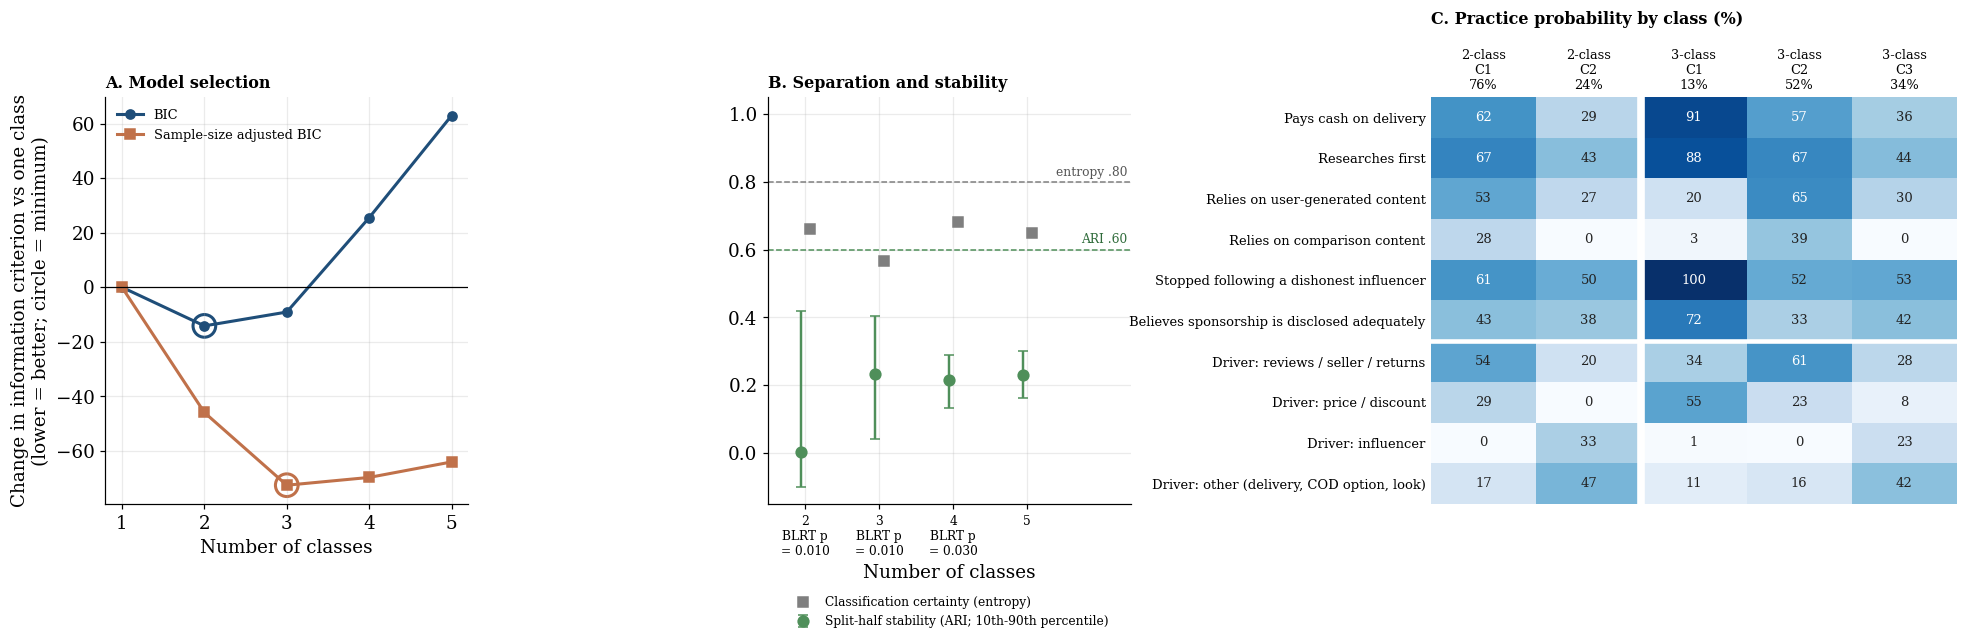


Cell 17 ran in 265 s

--- Key facts: model selection ---
 Classes  Log-likelihood  Parameters    BIC   aBIC  Entropy  Smallest class (%) BLRT p (vs k-1) Split-half ARI, median [10th, 90th] Meets criteria?
       1         -2637.5           9 5331.2 5302.6      NaN               100.0                                                                    
       2         -2599.2          19 5317.0 5256.7     0.66                20.1           0.010                  0.00 [-0.10, 0.42]              no
       3         -2570.6          29 5322.1 5230.0     0.57                11.5           0.010                   0.23 [0.04, 0.41]              no
       4         -2556.7          39 5356.7 5232.9     0.68                 7.4           0.030                   0.21 [0.13, 0.29]              no
       5         -2544.2          49 5394.1 5238.6     0.65                13.7                                   0.23 [0.16, 0.30]              no
  BIC selects 2; aBIC selects 3; solutions meeting all

In [18]:
# ============================================================
# CELL 17 — Segmentation of risk-containment practices: latent class analysis (LCA)   (Tables 21a-c; Figure 20)
# (run after Cells 6, 8, 11, 13, 14, 15 and 16: re-uses model, SPECS, smf, OrderedModel, fmt_p, save_table, save_fig)
# ============================================================
import warnings; warnings.filterwarnings("ignore")
import time as _time
from scipy import stats as _st
from sklearn.metrics import adjusted_rand_score
from matplotlib.ticker import NullFormatter
_t0 = _time.time()


# ---------- 1. latent class model for categorical items (EM with many random starts) ----------
def lca_fit(X, K, n_start=30, maxit=500, tol=1e-8, seed=0, ridge=1e-3):
    n, J = X.shape; L = [int(X[:, j].max()) + 1 for j in range(J)]; off = np.concatenate([[0], np.cumsum(L)]); rng = np.random.default_rng(seed); best = None
    OH = np.zeros((n, off[-1])); OH[np.arange(n)[:, None], X + off[:-1][None, :]] = 1; Lv = np.repeat(L, L).astype(float)           # all items stacked into one one-hot matrix
    for s in range(n_start):
        post = rng.dirichlet(np.ones(K), size=n) if K > 1 else np.ones((n, 1)); prev = -np.inf
        for it in range(maxit):
            w = post.sum(0); pi = (w + ridge) / (n + K * ridge); th = (post.T @ OH + ridge) / (w[:, None] + ridge * Lv[None, :])
            lp = np.log(pi)[None, :] + OH @ np.log(th).T; mx = lp.max(1, keepdims=True); ll = float((mx[:, 0] + np.log(np.exp(lp - mx).sum(1))).sum())
            post = np.exp(lp - mx); post /= post.sum(1, keepdims=True)
            if ll - prev < tol: break
            prev = ll
        if best is None or ll > best["loglik"]: best = {"loglik": ll, "pi": pi, "theta": [th[:, off[j]:off[j + 1]] for j in range(J)], "post": post, "L": L}
    npar = (K - 1) + K * sum(l - 1 for l in L); best["npar"] = npar; best["BIC"] = -2 * best["loglik"] + npar * np.log(n); best["AIC"] = -2 * best["loglik"] + 2 * npar; best["aBIC"] = -2 * best["loglik"] + npar * np.log((n + 2) / 24)
    p = np.clip(best["post"], 1e-12, 1); best["entropy"] = 1 - float(-(p * np.log(p)).sum() / (n * np.log(K))) if K > 1 else np.nan
    return best
# posterior class-membership probabilities of every respondent
def lca_post(fit, X):
    J = X.shape[1]; lp = np.log(fit["pi"])[None, :] + sum(np.log(fit["theta"][j])[:, X[:, j]].T for j in range(J)); m = lp.max(1, keepdims=True); p = np.exp(lp - m); return p / p.sum(1, keepdims=True)
# simulates a data set from a fitted LCA (used for the parametric-bootstrap likelihood-ratio test)
def lca_sim(fit, n, rng):
    c = rng.choice(len(fit["pi"]), size=n, p=fit["pi"]); cols = []
    for th in fit["theta"]: cum = np.cumsum(th[c], axis=1); cols.append((rng.random(n)[:, None] > cum).sum(1).clip(max=th.shape[1] - 1))
    return np.column_stack(cols)

# ---------- 2. indicators: five practices, one belief, and the main purchase driver (single choice, so recoded to 4 categories) ----------
m = model.copy(); m["Driver"] = np.select([(m.Q25_rev + m.Q25_sell + m.Q25_ret) > 0, m.Q25_price == 1, m.Q25_infl == 1], [0, 1, 2], 3)
BINI = [("Pays cash on delivery", "COD"), ("Researches first", "ResH"), ("Relies on user-generated content", "UGC"), ("Relies on comparison content", "CMP"), ("Stopped following a dishonest influencer", "StopFollow"), ("Believes sponsorship is disclosed adequately", "DiscAdeq")]
DRV = ["Driver: reviews / seller / returns", "Driver: price / discount", "Driver: influencer", "Driver: other (delivery, COD option, look)"]
XC = np.column_stack([m[v] for _, v in BINI] + [m["Driver"]]).astype(int); nC = len(XC); PRAC = [v for _, v in BINI[:5]]
print(f"LCA sample n = {nC}; indicators: {', '.join(l for l, _ in BINI)}; main purchase driver (4 categories)")
Rb = np.corrcoef(XC[:, :6].T); off = Rb[np.triu_indices(6, 1)]; pq = (XC[:, :6].mean(0) * (1 - XC[:, :6].mean(0))).sum(); kr20 = 6 / 5 * (1 - pq / XC[:, :6].sum(1).var(ddof=1))
print(f"Mean inter-item phi among the six binary indicators = {off.mean():.3f} (range {off.min():.2f} to {off.max():.2f}); KR-20 = {kr20:.2f}")

# ---------- 3. model selection: K = 1..5 (50 random starts), parametric bootstrap likelihood-ratio test, split-half stability ----------
KMAX = 5; FITS = {k: lca_fit(XC, k, n_start=50, seed=17) for k in range(1, KMAX + 1)}
B_LR = 100; BL = {}
for k in range(2, 5):
    f0, f1 = FITS[k - 1], FITS[k]; lr_obs = 2 * (f1["loglik"] - f0["loglik"]); rg = np.random.default_rng(170 + k); sims = []
    for b in range(B_LR):
        Xs = lca_sim(f0, nC, rg); a0 = lca_fit(Xs, k - 1, n_start=3, tol=1e-5, seed=b)["loglik"]; a1 = lca_fit(Xs, k, n_start=3, tol=1e-5, seed=b)["loglik"]; sims.append(max(2 * (a1 - a0), 0))
    BL[k] = (lr_obs, (1 + sum(s >= lr_obs for s in sims)) / (B_LR + 1))
ARI = {}; rg = np.random.default_rng(1717); SPL = [rg.permutation(nC) for _ in range(20)]
for k in range(2, KMAX + 1):
    a = []
    for r, idx in enumerate(SPL):
        A, Bh = idx[:nC // 2], idx[nC // 2:]; fa = lca_fit(XC[A], k, n_start=6, seed=r); fb = lca_fit(XC[Bh], k, n_start=6, seed=r + 100); a.append(adjusted_rand_score(lca_post(fa, XC).argmax(1), lca_post(fb, XC).argmax(1)))
    ARI[k] = np.array(a)
rows = []
for k in range(1, KMAX + 1):
    f = FITS[k]; cls = f["post"].argmax(1); rows.append({"Classes": k, "Log-likelihood": f["loglik"], "Parameters": f["npar"], "BIC": f["BIC"], "aBIC": f["aBIC"], "AIC": f["AIC"], "Entropy": f["entropy"], "Smallest class (%)": np.bincount(cls, minlength=k).min() / nC * 100,
                 "BLRT p (vs k-1)": BL[k][1] if k in BL else np.nan, "Split-half ARI, median [10th, 90th]": (f"{np.median(ARI[k]):.2f} [{np.percentile(ARI[k], 10):.2f}, {np.percentile(ARI[k], 90):.2f}]" if k in ARI else "")})
T21a = pd.DataFrame(rows); KB = int(T21a.loc[T21a.BIC.idxmin(), "Classes"]); KA = int(T21a.loc[T21a.aBIC.idxmin(), "Classes"])
T21a["Meets criteria?"] = ["" if k == 1 else ("yes" if (T21a.loc[k - 1, "Entropy"] >= .80 and (np.median(ARI[k]) >= .60) and (BL.get(k, (0, 1))[1] < .05) and T21a.loc[k - 1, "Smallest class (%)"] >= 5) else "no") for k in T21a.Classes]
shw = T21a.copy()
for c in ["BIC", "aBIC", "AIC", "Log-likelihood"]: shw[c] = shw[c].round(1)
shw["Entropy"] = shw["Entropy"].round(2); shw["Smallest class (%)"] = shw["Smallest class (%)"].round(1); shw["BLRT p (vs k-1)"] = shw["BLRT p (vs k-1)"].map(lambda v: "" if np.isnan(v) else fmt_p(v))
save_table(shw.set_index("Classes"), "Table21a_LCA_model_selection", f"Latent class models for {nC} respondents on 6 binary containment indicators and the main purchase driver (4 categories). 50 random starts; BLRT = parametric bootstrap likelihood-ratio test ({B_LR} samples); split-half ARI = adjusted Rand index between solutions fitted on random halves and applied to everyone (20 splits). 'Meets criteria' = entropy >= .80, median ARI >= .60, BLRT p < .05 and smallest class >= 5%")

# ---------- 4. class profiles (classes ordered by the number of practices they report, most first) ----------
def profile(k):
    f = FITS[k]; sc = np.array([sum(f["theta"][j][c][1] for j in range(5)) for c in range(k)]); order = np.argsort(-sc); post = f["post"][:, order]; cls = post.argmax(1)
    th = [f["theta"][j][order] for j in range(len(f["theta"]))]; rowsP = []
    for j, (lab, v) in enumerate(BINI): rowsP.append((lab, [th[j][c][1] for c in range(k)]))
    for j2, lab in enumerate(DRV): rowsP.append((lab, [th[6][c][j2] for c in range(k)]))
    return {"k": k, "order": order, "post": post, "cls": cls, "pi": f["pi"][order], "rows": rowsP, "n": np.bincount(cls, minlength=k)}
PROF = {KB: profile(KB)}
if KA != KB: PROF[KA] = profile(KA)
KS = sorted(PROF); print(f"\nBIC selects {KB} classes; aBIC selects {KA} classes")
rowsP = []; DESC = [("Trust (1-5), mean", "Trust18", "m"), ("Influencers followed (1-5 code), mean", "NFollow", "m"), ("Daily hours (1-5 code), mean", "SMhrs", "m"), ("Income (1-5 code), mean", "Income", "m"), ("Spends >= BDT 500 (%)", "Spend500", "p"), ("Any monthly spend (%)", "P_spend", "p"),
                                                                              ("Satisfaction (1-5), mean", "Satisf", "m"), ("Regret (1-5), mean", "regret", "m")]
for k in KS:
    P = PROF[k]
    for lab, vals in P["rows"]: rowsP.append({"Solution": f"{k} classes", "Item": lab, **{f"Class {c + 1}": f"{vals[c] * 100:.0f}%" for c in range(k)}})
    rowsP.append({"Solution": f"{k} classes", "Item": "Class size (modal assignment)", **{f"Class {c + 1}": f"{P['n'][c]} ({P['n'][c] / nC * 100:.0f}%)" for c in range(k)}})
    for lab, v, t in DESC:
        pv = _st.kruskal(*[m.loc[P["cls"] == c, v] for c in range(k)]).pvalue
        rowsP.append({"Solution": f"{k} classes", "Item": lab + f" [Kruskal-Wallis p = {fmt_p(pv)}]", **{f"Class {c + 1}": (f"{m.loc[P['cls'] == c, v].mean() * (100 if t == 'p' else 1):.{0 if t == 'p' else 2}f}{'%' if t == 'p' else ''}") for c in range(k)}})
T21b = pd.DataFrame(rowsP).fillna("")
save_table(T21b.set_index(["Solution", "Item"]), "Table21b_LCA_class_profiles", "Item-response probabilities of each class (classes ordered by the sum of the five practice probabilities, highest first) and descriptive profiles by modal class assignment. Unequal class sizes and the low entropy mean the profiles are descriptive only")

# ---------- 5. do classes differ in trust, spending and satisfaction?  pseudo-class draws (m = 30) with Rubin's rules, demographics + exposure adjusted ----------
M_DR = 30; rg = np.random.default_rng(1718); DEMX = "Female + Urban + Rural + z_Income + z_Edu + z_Age"; rows = []
# Rubin's rules for pooling the pseudo-class draws
def rubin(Q, U):
    Q = np.asarray(Q); U = np.asarray(U); mm = len(Q); qb = Q.mean(); ub = U.mean(); b = Q.var(ddof=1); t = ub + (1 + 1 / mm) * b; df = (mm - 1) * (1 + ub / ((1 + 1 / mm) * b)) ** 2 if b > 1e-14 else 1e6
    return qb, np.sqrt(t), df
for k in KS:
    P = PROF[k]; ref = int(np.argmax(P["n"])); others = [c for c in range(k) if c != ref]; cum = np.cumsum(P["post"], axis=1); res = {(o, c): [] for o in ["Trust", "Spend", "Satisf"] for c in others}
    for d in range(M_DR):
        draw = (rg.random(nC)[:, None] > cum).sum(1).clip(max=k - 1); dd = m.copy()
        for c in others: dd[f"C{c + 1}"] = (draw == c).astype(int)
        cl = " + ".join(f"C{c + 1}" for c in others)
        ft = smf.ols(f"Trust18 ~ {cl} + {DEMX}", data=dd).fit()
        fs = OrderedModel.from_formula(f"Spend ~ 0 + {cl} + {DEMX} + z_NFollow + z_SMhrs", data=dd, distr="logit").fit(method="bfgs", disp=0, maxiter=1000)
        fq = OrderedModel.from_formula(f"Satisf ~ 0 + {cl} + {DEMX} + z_NFollow + z_SMhrs", data=dd, distr="logit").fit(method="bfgs", disp=0, maxiter=1000)
        for c in others: res["Trust", c].append((ft.params[f"C{c + 1}"], ft.bse[f"C{c + 1}"] ** 2)); res["Spend", c].append((fs.params[f"C{c + 1}"], fs.bse[f"C{c + 1}"] ** 2)); res["Satisf", c].append((fq.params[f"C{c + 1}"], fq.bse[f"C{c + 1}"] ** 2))
    for c in others:
        row = {"Solution": f"{k} classes", "Contrast": f"Class {c + 1} vs Class {ref + 1} (reference; n = {P['n'][ref]})"}
        for o, lab, expo in [("Trust", "Trust (1-5 points; OLS b)", False), ("Spend", "Monthly spend level (OR, ordered logit)", True), ("Satisf", "Satisfaction (OR, ordered logit)", True)]:
            qb, se, df = rubin([q for q, u in res[o, c]], [u for q, u in res[o, c]]); pv = 2 * _st.t.sf(abs(qb / se), df)
            row[lab] = (f"{np.exp(qb):.2f} [{np.exp(qb - 1.96 * se):.2f}, {np.exp(qb + 1.96 * se):.2f}]" if expo else f"{qb:+.2f} [{qb - 1.96 * se:+.2f}, {qb + 1.96 * se:+.2f}]") + f", p = {fmt_p(pv)}"
        rows.append(row)
T21c = pd.DataFrame(rows)
save_table(T21c.set_index(["Solution", "Contrast"]), "Table21c_LCA_class_differences", f"Differences between latent classes (largest class = reference) in trust, spending and satisfaction: pseudo-class draws from the posterior class probabilities ({M_DR} draws, Rubin's rules) so that classification error is carried into the intervals; adjusted for demographics (trust) and demographics + influencers followed + daily hours (spending, satisfaction)")

# ---------- 6. Figure 20 ----------
fig, axes = plt.subplots(1, 3, figsize=(18.0, 6.6), gridspec_kw={"width_ratios": [1, 1, 1.45], "wspace": .72}); ax = axes[0]; ks = np.arange(1, KMAX + 1)
ax.plot(ks, T21a.BIC - T21a.BIC[0], "-o", color="#1f4e79", lw=2, label="BIC"); ax.plot(ks, T21a.aBIC - T21a.aBIC[0], "-s", color="#c0714a", lw=2, label="Sample-size adjusted BIC"); ax.axhline(0, color="black", lw=.8)
ax.scatter([KB], [T21a.BIC[KB - 1] - T21a.BIC[0]], s=220, facecolor="none", edgecolor="#1f4e79", lw=2); ax.scatter([KA], [T21a.aBIC[KA - 1] - T21a.aBIC[0]], s=220, facecolor="none", edgecolor="#c0714a", lw=2)
ax.set_xticks(ks); ax.set_xlabel("Number of classes"); ax.set_ylabel("Change in information criterion vs one class\n(lower = better; circle = minimum)"); ax.legend(loc="upper left", fontsize=8.5, frameon=False); ax.grid(alpha=.25); ax.set_title("A. Model selection", loc="left", fontsize=10.5, fontweight="bold")
# panel B: split-half stability (ARI) and classification certainty (entropy) by number of classes
ax = axes[1]; ks2 = np.arange(2, KMAX + 1); med = np.array([np.median(ARI[k]) for k in ks2]); lo = np.array([np.percentile(ARI[k], 10) for k in ks2]); hi = np.array([np.percentile(ARI[k], 90) for k in ks2])
ax.errorbar(ks2 - .06, med, yerr=[med - lo, hi - med], fmt="o", color="#4f8f5a", capsize=3, lw=1.6, ms=7, label="Split-half stability (ARI; 10th-90th percentile)"); ax.plot(ks2 + .06, T21a.Entropy[1:], "s", color="#7f7f7f", ms=7, label="Classification certainty (entropy)")
ax.axhline(.8, color="#7f7f7f", ls="--", lw=1); ax.text(KMAX + 1.35, .81, "entropy .80", ha="right", va="bottom", fontsize=8, color="#555"); ax.axhline(.6, color="#4f8f5a", ls="--", lw=1); ax.text(KMAX + 1.35, .61, "ARI .60", ha="right", va="bottom", fontsize=8, color="#2f6b3a")
ax.set_xticks(ks2); ax.set_xticklabels([f"{k}\nBLRT p\n= {fmt_p(BL[k][1])}" if k in BL else f"{k}" for k in ks2], fontsize=8); ax.set_ylim(-.15, 1.05); ax.set_xlim(1.5, KMAX + 1.4); ax.grid(alpha=.25); ax.legend(loc="upper center", bbox_to_anchor=(.5, -.2), fontsize=8, frameon=False)
ax.set_xlabel("Number of classes"); ax.set_title("B. Separation and stability", loc="left", fontsize=10.5, fontweight="bold")
# panel C: heatmap of the item-response probabilities of each class (2- and 3-class solutions)
ax = axes[2]; labs = [l for l, _ in PROF[KS[0]]["rows"]]; cols = []; heads = []; gaps = []
for k in KS:
    for c in range(k): cols.append([r[1][c] for r in PROF[k]["rows"]]); heads.append(f"{k}-class\nC{c + 1}\n{PROF[k]['pi'][c] * 100:.0f}%")
    gaps.append(len(cols))
Mx = np.array(cols).T; im = ax.imshow(Mx, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for i in range(Mx.shape[0]):
    for j in range(Mx.shape[1]): ax.text(j, i, f"{Mx[i, j] * 100:.0f}", ha="center", va="center", fontsize=8.6, color=("white" if Mx[i, j] > .55 else "#222"))
for g in gaps[:-1]: ax.axvline(g - .5, color="white", lw=5)
ax.axhline(5.5, color="white", lw=3); ax.set_xticks(range(Mx.shape[1])); ax.set_xticklabels(heads, fontsize=8.4); ax.set_yticks(range(len(labs))); ax.set_yticklabels(labs, fontsize=8.6); ax.xaxis.tick_top(); ax.tick_params(length=0)
for s_ in ax.spines.values(): s_.set_visible(False)
ax.set_title("C. Practice probability by class (%)", loc="left", fontsize=10.5, fontweight="bold", pad=48)
bsel = T21a.loc[T21a.Classes == KB].iloc[0]
CAPTION = (f"Figure 20. Latent classes of risk-containment practices (n = {nC}): BIC selects {KB} classes, entropy {bsel.Entropy:.2f}; adjusted BIC selects {KA}")
fig.subplots_adjust(left=.05, right=.985, top=.78, bottom=.22); save_fig(fig, "Fig20_LCA_containment", CAPTION); plt.show()

# ---------- key facts ----------
print(f"\nCell 17 ran in {_time.time() - _t0:.0f} s"); print("\n--- Key facts: model selection ---"); print(shw.drop(columns=["AIC"]).to_string(index=False))
print(f"  BIC selects {KB}; aBIC selects {KA}; solutions meeting all four criteria: {[int(k) for k, v in zip(T21a.Classes, T21a['Meets criteria?']) if v == 'yes'] or 'none'}")
for k in KS:
    print(f"\n--- {k}-class solution ---"); print(T21b[T21b.Solution == f"{k} classes"].drop(columns=["Solution"]).to_string(index=False)); print(T21c[T21c.Solution == f"{k} classes"].drop(columns=["Solution"]).to_string(index=False))

## Cell 18 — Export
Collects every table into one Excel workbook (Index sheet with links, Figures sheet with captions) and writes a ZIP containing the workbook, all table CSVs, all figures (PNG + PDF), the suggested figure captions and a README with sample sizes and software versions. Set `INCLUDE_DATA = True` only after checking that the respondent-level files are anonymous.
**Outputs:** `outputs/export/Tables_all.xlsx`, `Shopping_analysis_outputs.zip`, `Figure_captions.txt`, `README.txt`.

In [19]:
# ============================================================
# CELL 18 — Export: one Excel workbook with every table, and one ZIP with all tables, figures and a README
# (run last; it uses the TABLES dictionary filled by save_table in Cells 2-17, so do not restart the runtime before it)
# ============================================================
import os, re, sys, glob, zipfile, platform, datetime
import scipy, statsmodels, matplotlib

INCLUDE_DATA = False           # respondent-level files contain timestamps and free-text comments: set True only after checking they are anonymous
EXPORT = f"{OUT}/export"; os.makedirs(EXPORT, exist_ok=True)
TOPIC = {0: "Codebook", 1: "Sample profile", 2: "Likert items (descriptives)", 3: "Behaviour distributions", 4: "Multi-response and single-choice items", 5: "Factor retention and EFA", 6: "Reliability", 7: "CFA fit", 8: "CFA loadings and validity",
         9: "Trust gradient", 10: "Group differences", 11: "Group means", 12: "Correlations", 13: "Core trust models", 14: "Equivalence, marginal effects, Bayes factors", 15: "Safeguards and cash on delivery (H3)",
         16: "Mediation (H4)", 17: "Moderation (H5)", 18: "Distrusting spenders (H7)", 19: "Satisfaction and COD (H6)", 20: "Robustness checks", 21: "Latent classes of containment practices"}
# natural sort key for table names (Table2 < Table10)
def nat(name):
    mt = re.match(r"(?:Table|T)(\d+)([a-z]?)", name); return (int(mt.group(1)), mt.group(2), name) if mt else (999, "", name)
names = sorted(TABLES, key=nat)

# ---------- 1. Excel workbook ----------
xlsx = f"{EXPORT}/Tables_all.xlsx"; sheet_of = {}; used = set()
for nm in names:
    s = re.sub(r"[\[\]\*\?/\\:]", "", nm.replace("Table", "T", 1) if nm.startswith("Table") else nm)[:31]; base = s; i = 2
    while s.lower() in used: s = f"{base[:28]}_{i}"; i += 1
    used.add(s.lower()); sheet_of[nm] = s
try:
    W = pd.ExcelWriter(xlsx, engine="xlsxwriter", engine_kwargs={"options": {"strings_to_formulas": False, "strings_to_urls": False}}); fancy = True
except Exception:
    W = pd.ExcelWriter(xlsx, engine="openpyxl"); fancy = False
with W as writer:
    idx_rows = []
    for nm in names:
        cap, df_ = TABLES[nm]; df_ = df_.copy(); use_index = not isinstance(df_.index, pd.RangeIndex)
        df_.to_excel(writer, sheet_name=sheet_of[nm], index=use_index, na_rep="", startrow=2)
        if fancy:
            ws = writer.sheets[sheet_of[nm]]; fmt_cap = writer.book.add_format({"italic": True, "text_wrap": False, "font_color": "#444444"}); fmt_ttl = writer.book.add_format({"bold": True, "font_size": 12})
            ws.write_string(0, 0, nm, fmt_ttl); ws.write_string(1, 0, cap[:32000], fmt_cap)
            nidx = df_.index.nlevels if use_index else 0; ncol = df_.shape[1] + nidx; hdr = df_.columns.nlevels
            for j in range(ncol):
                if j < nidx: vals = [str(v) for v in (df_.index.get_level_values(j) if use_index else [])]; head = str(df_.index.names[j] or "")
                else: vals = [str(v) for v in df_.iloc[:, j - nidx].tolist()]; head = " ".join(map(str, df_.columns[j - nidx])) if hdr > 1 else str(df_.columns[j - nidx])
                ws.set_column(j, j, min(max([len(head)] + [len(v) for v in vals[:300]] + [8]) + 2, 55))
            ws.freeze_panes(2 + hdr + (1 if use_index and df_.index.nlevels > 0 and False else 0), nidx)
        mt = re.match(r"(?:Table|T)(\d+)", nm); idx_rows.append({"Sheet": sheet_of[nm], "Table": nm, "Topic": TOPIC.get(int(mt.group(1)), "") if mt else "", "Rows": df_.shape[0], "Columns": df_.shape[1], "Caption": cap})
    IDX = pd.DataFrame(idx_rows); IDX.to_excel(writer, sheet_name="Index", index=False)
    figs = sorted(glob.glob(f"{OUT}/figures/*.png"), key=lambda p: nat(os.path.basename(p)) if re.match(r"(?:Table|T)\d", os.path.basename(p)) else (int((re.match(r"Fig[S]?(\d+)", os.path.basename(p)) or re.match(r"(\d*)", "0")).group(1) or 0), os.path.basename(p), ""))
    FIGX = pd.DataFrame({"Figure": [os.path.splitext(os.path.basename(p))[0] for p in figs], "PNG (KB)": [round(os.path.getsize(p) / 1024) for p in figs], "PDF": [os.path.exists(p[:-4] + ".pdf") for p in figs],
                         "Caption": [FIGCAP.get(os.path.splitext(os.path.basename(p))[0], "").replace("\n", " ") for p in figs]}); FIGX.to_excel(writer, sheet_name="Figures", index=False)
    if fancy:
        for shn, df_ in [("Index", IDX), ("Figures", FIGX)]:
            ws = writer.sheets[shn]; hf = writer.book.add_format({"bold": True, "bg_color": "#DCE6F1", "border": 1})
            for j, c in enumerate(df_.columns): ws.write(0, j, c, hf); ws.set_column(j, j, 28 if c in ("Sheet", "Topic", "Figure") else (46 if c == "Table" else (110 if c == "Caption" else 12)))
            ws.freeze_panes(1, 0)
        ws = writer.sheets["Index"]
        for r, shn in enumerate(IDX["Sheet"], start=1): ws.write_url(r, 0, f"internal:'{shn}'!A1", string=shn)
        try:
            order = ["Index", "Figures"] + [sheet_of[n] for n in names]; writer.book.worksheets_objs.sort(key=lambda w: order.index(w.get_name())); writer.sheets["Index"].activate(); writer.sheets["Index"].set_first_sheet()
        except Exception: pass
print(f"Workbook: {xlsx}  ({len(names)} tables + Index + Figures sheets, {os.path.getsize(xlsx) / 1024:.0f} KB)")

# ---------- 2. README with the sample flow, software versions and file list ----------
sizes = f"raw responses {len(d0)}; cleaned sample (descriptives) {len(clean)}; model sample (regressions) {len(model)}"
readme = f"""Social media and young consumers' shopping behaviour in Bangladesh - analysis outputs
Created: {datetime.datetime.now().strftime('%Y-%m-%d %H:%M')}
Samples: {sizes}
Software: Python {platform.python_version()}, pandas {pd.__version__}, numpy {np.__version__}, scipy {scipy.__version__}, statsmodels {statsmodels.__version__}, matplotlib {matplotlib.__version__}

Contents
  tables/   one CSV per table ({len(names)} tables; the same tables are in Tables_all.xlsx, one sheet each, with an Index sheet), plus the unrounded '_numeric' companions of Tables 1, 3 and 4
  figures/  every figure as PNG and PDF (figures carry no title; the suggested captions are in Figure_captions.txt and on the Figures sheet)
  data/     respondent-level files (cleaned data; present only if INCLUDE_DATA = True)
  Tables_all.xlsx

Conventions
  Odds ratios are per +1 SD of the predictor unless stated; M2 is the main covariate set (demographics + influencers followed + daily hours).
  Table 'numeric' companions hold the unrounded values behind formatted tables.
  Cross-sectional data: all associations are descriptive, not causal.
"""
rd = f"{EXPORT}/README.txt"; open(rd, "w").write(readme)
capf = f"{EXPORT}/Figure_captions.txt"
with open(capf, "w", encoding="utf-8") as fh:
    for _, r_ in FIGX.iterrows(): fh.write(f"{r_['Figure']}\n  {r_['Caption']}\n\n")

# ---------- 3. ZIP ----------
zp = f"{EXPORT}/Shopping_analysis_outputs.zip"; n_csv = 0; missing = []
stale = sorted(set(os.path.basename(p)[:-4] for p in glob.glob(f"{OUT}/tables/*.csv")) - set(names))
numeric_extra = [n for n in stale if n.endswith("_numeric")]; stale = [n for n in stale if n not in numeric_extra]   # unrounded companions of Tables 1, 3, 4 are packed too
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(rd, "README.txt"); z.write(xlsx, "Tables_all.xlsx"); z.write(capf, "Figure_captions.txt")
    for nm in names:
        p = f"{OUT}/tables/{nm}.csv"
        if os.path.exists(p): z.write(p, f"tables/{nm}.csv"); n_csv += 1
        else: missing.append(nm)
    for nm in numeric_extra: z.write(f"{OUT}/tables/{nm}.csv", f"tables/{nm}.csv"); n_csv += 1
    for p in sorted(glob.glob(f"{OUT}/figures/*")): z.write(p, f"figures/{os.path.basename(p)}")
    if INCLUDE_DATA:
        for p in glob.glob(f"{OUT}/data_*.csv"): z.write(p, f"data/{os.path.basename(p)}")
with zipfile.ZipFile(zp) as z: nfile = len(z.namelist())
print(f"ZIP: {zp}  ({nfile} files, {os.path.getsize(zp) / 1e6:.1f} MB): {n_csv} table CSVs, {len(glob.glob(f'{OUT}/figures/*'))} figure files" + (", respondent-level data included" if INCLUDE_DATA else ""))
if missing: print("Tables in memory without a CSV:", missing)
if stale: print("CSV files in the tables folder that are not in this session's tables (older runs; NOT included in the ZIP):", stale)
print("\nFigures included:", ", ".join(FIGX["Figure"]))
try:
    from google.colab import files
    files.download(xlsx); files.download(zp)
except Exception: print("(Download prompt skipped; the files are in", EXPORT, ")")

Workbook: /content/drive/MyDrive/Shopping/outputs/export/Tables_all.xlsx  (60 tables + Index + Figures sheets, 111 KB)
ZIP: /content/drive/MyDrive/Shopping/outputs/export/Shopping_analysis_outputs.zip  (111 files, 8.4 MB): 64 table CSVs, 44 figure files

Figures included: Fig1_sample_profile, FigS1_data_quality_flags, Fig2_likert_diverging, FigS2_behaviour_distributions, Fig3_multiresponse_items, Fig4_efa_scree_loadings, Fig5_cfa_loadings, Fig6_trust_gradient, Fig7_group_difference_heatmap, Fig8_correlation_heatmap, Fig9_trust_forest, Fig10_predicted_probabilities, Fig11_equivalence_and_posterior, Fig12_safeguards_by_trust, Fig13_COD_trust_income, Fig14_mediation, Fig15_moderation, Fig16_satisfaction_COD, Fig17_low_trust_spending, Fig18_robustness_trust, Fig19_robustness_H6_H7, Fig20_LCA_containment


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>